In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import mlflow
import mlflow.sklearn

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_predict
from sklearn.compose import make_column_transformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report,
    precision_recall_curve
)

In [9]:
df = pd.read_csv("../task3/feature_eng_df.csv")

# Exp 1 - Baseline model | Random Forest

Total missing values: 33864

Target distribution:
churn
0    13187
1     1419
Name: count, dtype: int64

Target percentage:
churn
0    90.28
1     9.72
Name: proportion, dtype: float64

X_train: (11684, 104)
X_test: (2922, 104)

Categorical columns: ['channel_sales', 'has_gas', 'origin_up']
Numerical columns: 101


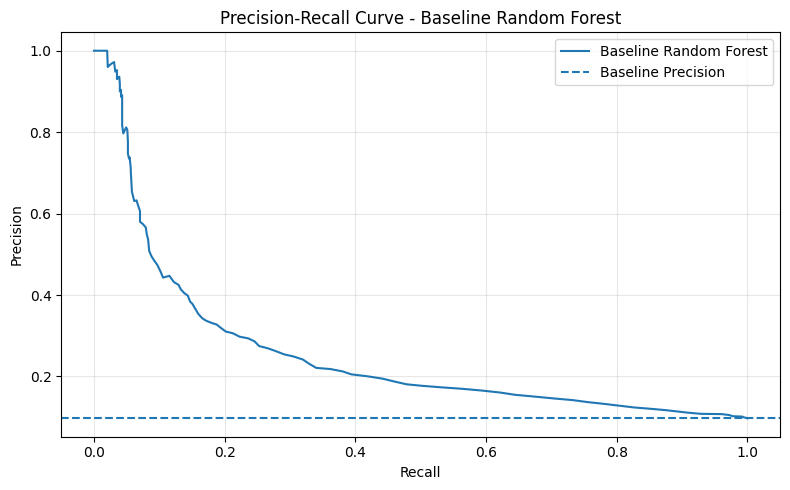


==== FINE-GRAINED THRESHOLD ANALYSIS ====
 Threshold  Precision  Recall  F1 Score
      0.10     0.1604  0.6220    0.2551
      0.11     0.1698  0.5630    0.2609
      0.12     0.1770  0.5022    0.2618
      0.13     0.1878  0.4590    0.2666
      0.14     0.2004  0.4185    0.2710
      0.15     0.2124  0.3806    0.2726
      0.16     0.2211  0.3401    0.2680
      0.17     0.2415  0.3198    0.2752
      0.18     0.2544  0.2907    0.2714
      0.19     0.2692  0.2661    0.2676
      0.20     0.2862  0.2458    0.2645
      0.21     0.2976  0.2229    0.2549
      0.22     0.3103  0.2018    0.2445
      0.23     0.3277  0.1877    0.2387
      0.24     0.3368  0.1718    0.2275
      0.25     0.3542  0.1595    0.2199


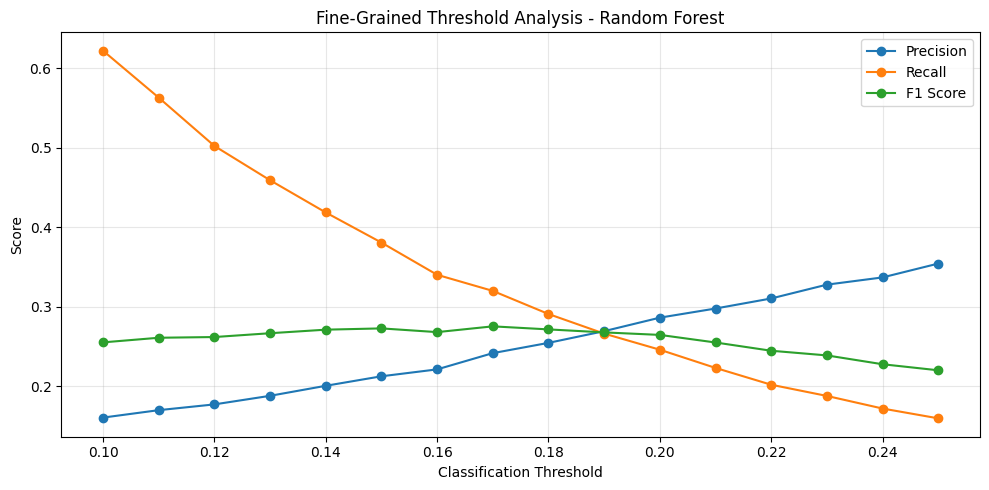


==== BEST THRESHOLD ====
Best Threshold: 0.16999999999999998
Threshold    0.170000
Precision    0.241517
Recall       0.319824
F1 Score     0.275208
Name: 7, dtype: float64

==== TRAIN METRICS ====
Accuracy    : 0.9987
Precision   : 0.9870
Recall      : 1.0000
F1 Score    : 0.9934
ROC-AUC     : 1.0000
PR-AUC      : 1.0000

==== TEST METRICS ====
Accuracy    : 0.8402
Precision   : 0.2672
Recall      : 0.3697
F1 Score    : 0.3102
ROC-AUC     : 0.7076
PR-AUC      : 0.3277


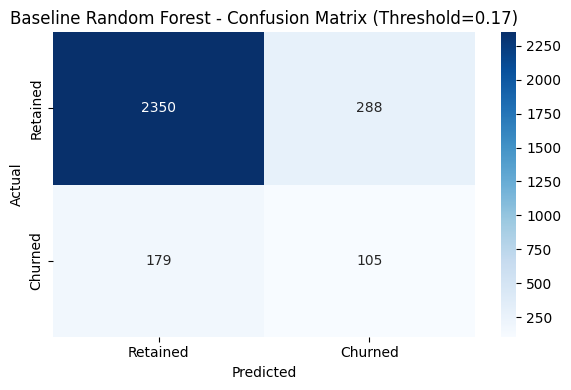


==== CLASSIFICATION REPORT ====
              precision    recall  f1-score   support

    Retained       0.93      0.89      0.91      2638
     Churned       0.27      0.37      0.31       284

    accuracy                           0.84      2922
   macro avg       0.60      0.63      0.61      2922
weighted avg       0.86      0.84      0.85      2922


==== CROSS VALIDATION TRAIN SCORES ====
train_Accuracy - Mean: 1.0000, Std: 0.0000
train_Precision - Mean: 1.0000, Std: 0.0000
train_Recall - Mean: 1.0000, Std: 0.0000
train_F1 - Mean: 1.0000, Std: 0.0000
train_ROC_AUC - Mean: 1.0000, Std: 0.0000
train_PR_AUC - Mean: 1.0000, Std: 0.0000

==== CROSS VALIDATION VALIDATION SCORES ====
test_Accuracy - Mean: 0.9065, Std: 0.0006
test_Precision - Mean: 0.9286, Std: 0.0904
test_Recall - Mean: 0.0414, Std: 0.0095
test_F1 - Mean: 0.0790, Std: 0.0172
test_ROC_AUC - Mean: 0.6859, Std: 0.0155
test_PR_AUC - Mean: 0.2543, Std: 0.0143

==== TOP 20 IMPORTANT FEATURES ====
                   Feature

In [43]:

# ============================================================
# EXP 1 - BASELINE MODEL | RANDOM FOREST
# ============================================================

# ============================================================
# 1. SEPARATE FEATURES AND TARGET
# ============================================================

date_cols = [
    'date_activ',
    'date_end',
    'date_modif_prod',
    'date_renewal'
]

X = df.drop(columns=['id', 'churn'] + date_cols)
y = df['churn']

print("Total missing values:", X.isna().sum().sum())
print("\nTarget distribution:")
print(y.value_counts())
print("\nTarget percentage:")
print((y.value_counts(normalize=True) * 100).round(2))

# ============================================================
# 2. TRAIN TEST SPLIT
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nX_train:", X_train.shape)
print("X_test:", X_test.shape)

# ============================================================
# 3. IDENTIFY CATEGORICAL AND NUMERICAL COLUMNS
# ============================================================

categorical_cols = X.select_dtypes(
    include=['object', 'category', 'bool']
).columns.tolist()

numerical_cols = X.select_dtypes(
    include=np.number
).columns.tolist()

print("\nCategorical columns:", categorical_cols)
print("Numerical columns:", len(numerical_cols))

# ============================================================
# 4. PREPROCESSING PIPELINE
# ============================================================

categorical_pipeline = OneHotEncoder(
    handle_unknown='ignore'
)

preprocessor = make_column_transformer(
    (categorical_pipeline, categorical_cols),
    remainder='passthrough',
    verbose_feature_names_out=False,
    n_jobs=-1
)

# ============================================================
# 5. BASELINE RANDOM FOREST PIPELINE
# ============================================================

baseline_pipeline = Pipeline(steps=[
    ("preprocessing", preprocessor),
    ("model", RandomForestClassifier(
        class_weight='balanced',
        n_estimators=200,
        max_depth=None,
        min_samples_split=2,
        min_samples_leaf=1,
        max_features='sqrt',
        random_state=42,
        n_jobs=-1
    ))
])

# ============================================================
# 6. STRATIFIED CROSS VALIDATION
# ============================================================

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# ============================================================
# 7. GENERATE OUT-OF-FOLD PROBABILITIES
# ============================================================

# Train 5 models using Stratified 5-Fold CV to generate OOF probabilities,
# which are used to find the best classification threshold.
y_prob_oof = cross_val_predict(
    baseline_pipeline,
    X_train,
    y_train,
    cv=cv,
    method='predict_proba',
    n_jobs=1
)[:, 1]

# ============================================================
# 8. PRECISION RECALL CURVE
# ============================================================

precision, recall, pr_thresholds = precision_recall_curve(
    y_train,
    y_prob_oof
)

plt.figure(figsize=(8, 5))
plt.plot(
    recall,
    precision,
    label='Baseline Random Forest'
)
plt.axhline(
    y=y_train.mean(),
    linestyle='--',
    label='Baseline Precision'
)
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve - Baseline Random Forest')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# ============================================================
# 9. FINE-GRAINED THRESHOLD ANALYSIS
# ============================================================
# For each threshold, we generate a new set of 0 and 1 predictions using the same OOF probabilities.

threshold_values = np.arange(0.10, 0.251, 0.01)
fine_results = []

for threshold in threshold_values:
    y_pred = (y_prob_oof >= threshold).astype(int) #means it return: If probability ≥ threshold → Prediction = 1 (Churned) and If probability < threshold → Prediction = 0 (Retained).

    fine_results.append({
        'Threshold': threshold,
        'Precision': precision_score(
            y_train, y_pred, zero_division=0
        ),
        'Recall': recall_score(
            y_train, y_pred, zero_division=0
        ),
        'F1 Score': f1_score(
            y_train, y_pred, zero_division=0
        )
    })

fine_threshold_df = pd.DataFrame(fine_results)

print("\n==== FINE-GRAINED THRESHOLD ANALYSIS ====")
print(fine_threshold_df.round(4).to_string(index=False))

# ============================================================
# 10. THRESHOLD PERFORMANCE VISUALIZATION
# ============================================================

plt.figure(figsize=(10, 5))

plt.plot(
    fine_threshold_df['Threshold'],
    fine_threshold_df['Precision'],
    marker='o',
    label='Precision'
)
plt.plot(
    fine_threshold_df['Threshold'],
    fine_threshold_df['Recall'],
    marker='o',
    label='Recall'
)
plt.plot(
    fine_threshold_df['Threshold'],
    fine_threshold_df['F1 Score'],
    marker='o',
    label='F1 Score'
)

plt.xlabel('Classification Threshold')
plt.ylabel('Score')
plt.title('Fine-Grained Threshold Analysis - Random Forest')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# ============================================================
# 11. SELECT BEST THRESHOLD
# ============================================================

best_threshold = fine_threshold_df.loc[
    fine_threshold_df['F1 Score'].idxmax(),
    'Threshold'
]

print("\n==== BEST THRESHOLD ====")
print("Best Threshold:", best_threshold)
print(
    fine_threshold_df.loc[
        fine_threshold_df['F1 Score'].idxmax()
    ]
)

# ============================================================
# 12. TRAIN FINAL BASELINE MODEL
# ============================================================
# Train the final model on the entire training dataset (100%),
# which will later use the best_threshold to generate 0/1 predictions.

baseline_pipeline.fit(X_train, y_train)

# ============================================================
# 13. TRAIN PREDICTIONS
# ============================================================

y_prob_train = baseline_pipeline.predict_proba(
    X_train
)[:, 1]

y_pred_train = (
    y_prob_train >= best_threshold
).astype(int) #means it return: If probability ≥ threshold then Prediction = 1 (Churned) and If probability < threshold then Prediction = 0 (Retained).

print('y_prob_train: ', y_prob_train.shape)
print('y_pred_train: ', y_pred_train.shape)

# ============================================================
# 14. TEST PREDICTIONS
# ============================================================

y_prob_test = baseline_pipeline.predict_proba(
    X_test
)[:, 1]

y_pred_test = (
    y_prob_test >= best_threshold
).astype(int)

# ============================================================
# 15. DEFINE METRIC FUNCTION
# ============================================================

def calc_metrics(y_true, y_pred, y_prob):
    return {
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision': precision_score(
            y_true, y_pred, zero_division=0
        ),
        'Recall': recall_score(
            y_true, y_pred, zero_division=0
        ),
        'F1 Score': f1_score(
            y_true, y_pred, zero_division=0
        ),
        'ROC-AUC': roc_auc_score(y_true, y_prob),
        'PR-AUC': average_precision_score(y_true, y_prob)
    }

# ============================================================
# 16. CALCULATE TRAIN AND TEST METRICS
# ============================================================

train_metrics = calc_metrics(
    y_train, y_pred_train, y_prob_train
)

test_metrics = calc_metrics(
    y_test, y_pred_test, y_prob_test
)

print("\n==== TRAIN METRICS ====")
for metric, value in train_metrics.items():
    print(f"{metric:12}: {value:.4f}")

print("\n==== TEST METRICS ====")
for metric, value in test_metrics.items():
    print(f"{metric:12}: {value:.4f}")

# ============================================================
# 17. CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(y_test, y_pred_test)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Retained', 'Churned'],
    yticklabels=['Retained', 'Churned']
)

plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title(
    f'Baseline Random Forest - Confusion Matrix '
    f'(Threshold={best_threshold:.2f})'
)
plt.tight_layout()
plt.show()

# ============================================================
# 18. CLASSIFICATION REPORT
# ============================================================

print("\n==== CLASSIFICATION REPORT ====")
print(classification_report(
    y_test,
    y_pred_test,
    target_names=['Retained', 'Churned'],
    zero_division=0
))

# ============================================================
# 19. CROSS VALIDATION PERFORMANCE
# ============================================================

scoring = {
    'Accuracy': 'accuracy',
    'Precision': 'precision',
    'Recall': 'recall',
    'F1': 'f1',
    'ROC_AUC': 'roc_auc',
    'PR_AUC': 'average_precision'
}

cv_results = cross_validate(
    baseline_pipeline,
    X_train,
    y_train,
    scoring=scoring,
    cv=cv,
    return_train_score=True,
    n_jobs=1
)

print("\n==== CROSS VALIDATION TRAIN SCORES ====")
for key, value in cv_results.items():
    if key.startswith('train'):
        print(
            f"{key} - Mean: {np.mean(value):.4f}, "
            f"Std: {np.std(value):.4f}"
        )

print("\n==== CROSS VALIDATION VALIDATION SCORES ====")
for key, value in cv_results.items():
    if key.startswith('test'):
        print(
            f"{key} - Mean: {np.mean(value):.4f}, "
            f"Std: {np.std(value):.4f}"
        )

# ============================================================
# 20. FEATURE IMPORTANCE
# ============================================================

rf_model = baseline_pipeline.named_steps['model']

feature_names = (
    baseline_pipeline
    .named_steps['preprocessing']
    .get_feature_names_out()
)

importances = rf_model.feature_importances_

feature_importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
}).sort_values(
    by='Importance',
    ascending=False
).reset_index(drop=True)

print("\n==== TOP 20 IMPORTANT FEATURES ====")
print(feature_importance_df.head(20).to_string(index=False))


**Baseline Model – Random Forest Classifier**

**1. Dataset Overview**

- Total missing values: **33,864**
- Target distribution:
  - Retained (0): 13,187 (90.28%)
  - Churned (1): 1,419 (9.72%)
- Dataset is highly imbalanced.
- Training data: (11,684, 104)
- Testing data: (2,922, 104)
- Categorical features: 3
- Numerical features: 101

**2. Model Performance – Test Data**

- Accuracy: **84.02%**
- Precision: **26.72%**
- Recall: **36.97%**
- F1 Score: **31.02%**
- ROC-AUC: **70.76%**
- PR-AUC: **32.77%**

**3. Threshold Analysis**

- Tested classification thresholds between 0.10 and 0.25.
- Selected threshold: **0.17**, based on the highest F1 score in the threshold analysis.
- At threshold 0.17 (threshold validation):
  - Precision: 24.15%
  - Recall: 31.98%
  - F1 Score: 27.52%
- Lower thresholds improve recall but reduce precision.
- Higher thresholds improve precision but miss more churn customers.

**4. Confusion Matrix (Threshold = 0.17)**

- True Negatives: 2,350
- False Positives: 288
- False Negatives: 179
- True Positives: 105

**Observation:**

- Model correctly identifies 105 churn customers out of 284.
- However, it misses 179 actual churn customers.
- There are also 288 false churn predictions.

**5. Precision-Recall Curve**

- Baseline precision is approximately 9.72%, corresponding to the churn percentage.
- The model achieves higher precision than the baseline across much of the recall range.
- However, precision decreases significantly as recall increases.

**6. Cross-Validation Results**

- Training scores are almost perfect (1.00).
- Validation accuracy: 90.65%
- Validation precision: 92.86%
- Validation recall: 4.14%
- Validation F1: 7.90%
- Validation ROC-AUC: 68.59%
- Validation PR-AUC: 25.43%

**Observation:**

- Significant difference between training and validation performance indicates overfitting.
- Validation recall is very low, meaning the model misses most churn customers.
- Cross-validation metrics should be compared using the same classification threshold as other experiments.

**7. Top 20 Important Features**

The most important features include:

- margin_net_pow_ele
- forecast_meter_rent_12m
- margin_per_consumption
- cons_last_month_diff
- consumption_per_power
- forecast_cons_ratio
- cons_12m
- forecast_cons_diff
- price_consumption_exposure
- margin_per_power

**Observation:**

- Margin-related, consumption-related and price-related features contribute significantly to churn prediction.
- Customer tenure and interaction features also contribute to predictions.

**Final Conclusion – Baseline Random Forest**

- Random Forest achieves a test ROC-AUC of **70.76%** and PR-AUC of **32.77%**.
- At threshold 0.17, test recall is 36.97%, but precision is only 26.72%.
- The model suffers from overfitting and struggles to identify churn customers effectively.
- Class imbalance and poor generalization remain important challenges.

**This Random Forest model will serve as our baseline model. All upcoming experiments will be compared against its performance, especially PR-AUC, Recall, Precision and F1 Score.**

**Important note for future comparisons:**: CV metrics were calculated at the default 0.50 threshold, while test metrics use the optimized 0.17 threshold. Compare CV and test classification metrics cautiously, as they use different thresholds.

# **Exp 2 – Hyperparameter-Tuned Random Forest | OOF-Based Threshold Optimization**

1. One-Hot Encoding (OHE) is applied to categorical features.
2. Class imbalance is handled using class_weight='balanced'.
3. RandomizedSearchCV with 5-Fold Stratified CV is used to find the best hyperparameters based on PR-AUC.
4. Out-of-Fold (OOF) probabilities are generated using the best model.
5. OOF probabilities are used to find the best classification threshold based on F1 Score.
6. The selected threshold is applied to train and test probabilities to generate:
   0 = Retained | 1 = Churned.
7. Model performance is evaluated using classification metrics, confusion matrix, and cross-validation.
8. Feature importance is analysed to identify the most influential features.


Total missing values: 33864

Target Distribution:
churn
0    13187
1     1419
Name: count, dtype: int64

Target Percentage:
churn
0    90.284814
1     9.715186
Name: proportion, dtype: float64

X_train: (11684, 104)
X_test: (2922, 104)

Categorical columns: ['channel_sales', 'has_gas', 'origin_up']
Numerical columns: 101
Fitting 5 folds for each of 25 candidates, totalling 125 fits

==== BEST HYPERPARAMETERS ====
{'model__n_estimators': 500, 'model__min_samples_split': 5, 'model__min_samples_leaf': 5, 'model__max_features': 0.5, 'model__max_depth': None}

Best CV PR-AUC:
0.30554474446608343

==== TOP 10 HYPERPARAMETER COMBINATIONS ====
 param_model__n_estimators param_model__max_depth  param_model__min_samples_split  param_model__min_samples_leaf param_model__max_features  mean_test_score  std_test_score
                       500                   None                               5                              5                       0.5           0.3055          0.0220
            

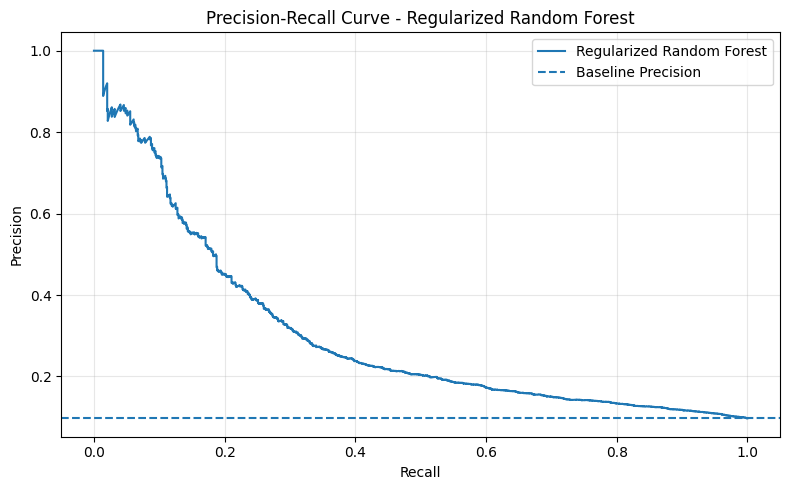


==== FINE-GRAINED THRESHOLD ANALYSIS ====
 Threshold  Precision  Recall  F1 Score
      0.05     0.1024  0.9780    0.1854
      0.06     0.1048  0.9674    0.1892
      0.07     0.1082  0.9577    0.1944
      0.08     0.1113  0.9374    0.1990
      0.09     0.1147  0.9181    0.2039
      0.10     0.1187  0.8952    0.2096
      0.11     0.1243  0.8687    0.2174
      0.12     0.1276  0.8317    0.2213
      0.13     0.1330  0.8044    0.2283
      0.14     0.1391  0.7762    0.2359
      0.15     0.1426  0.7322    0.2387
      0.16     0.1492  0.7022    0.2461
      0.17     0.1570  0.6705    0.2545
      0.18     0.1639  0.6405    0.2610
      0.19     0.1696  0.6079    0.2652
      0.20     0.1795  0.5885    0.2751
      0.21     0.1846  0.5542    0.2770
      0.22     0.1955  0.5313    0.2858
      0.23     0.2035  0.5031    0.2898
      0.24     0.2126  0.4731    0.2934
      0.25     0.2194  0.4432    0.2935
      0.26     0.2278  0.4176    0.2948
      0.27     0.2418  0.3965    0.30

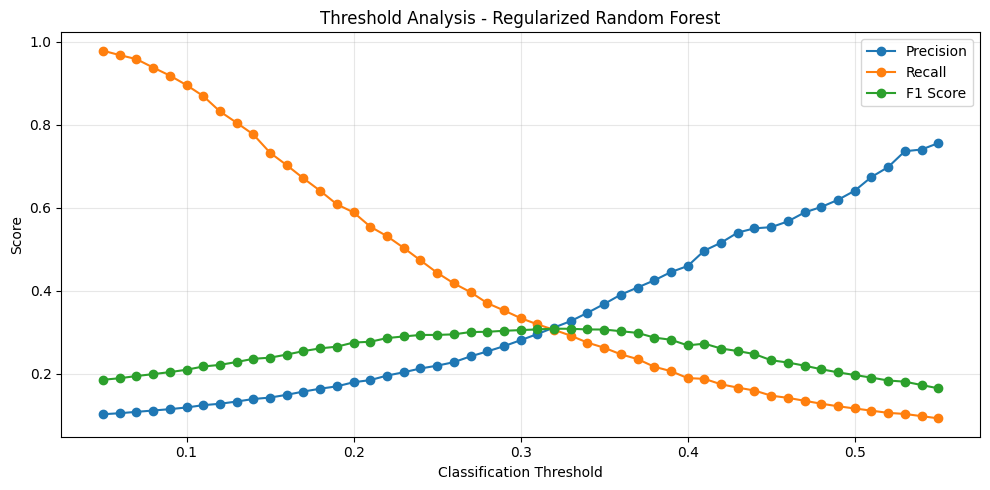


==== BEST THRESHOLD ====
Best Threshold: 0.32000000000000006
Threshold    0.320000
Precision    0.311211
Recall       0.305727
F1 Score     0.308444
Name: 27, dtype: float64

==== TRAIN METRICS ====
Accuracy    : 0.9844
Precision   : 0.8618
Recall      : 1.0000
F1 Score    : 0.9258
ROC-AUC     : 0.9998
PR-AUC      : 0.9982

==== TEST METRICS ====
Accuracy    : 0.8734
Precision   : 0.3486
Recall      : 0.3486
F1 Score    : 0.3486
ROC-AUC     : 0.7048
PR-AUC      : 0.3575


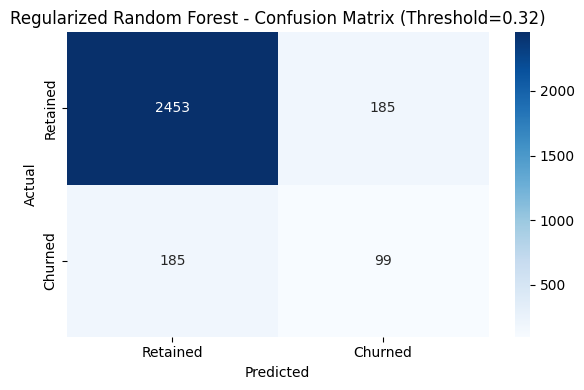


==== CLASSIFICATION REPORT ====
              precision    recall  f1-score   support

    Retained       0.93      0.93      0.93      2638
     Churned       0.35      0.35      0.35       284

    accuracy                           0.87      2922
   macro avg       0.64      0.64      0.64      2922
weighted avg       0.87      0.87      0.87      2922


==== CV TRAIN SCORES ====
train_Accuracy - Mean: 0.9991, Std: 0.0002
train_Precision - Mean: 0.9915, Std: 0.0023
train_Recall - Mean: 0.9989, Std: 0.0010
train_F1 - Mean: 0.9952, Std: 0.0013
train_ROC_AUC - Mean: 0.9999, Std: 0.0001
train_PR_AUC - Mean: 0.9986, Std: 0.0008

==== CV VALIDATION SCORES ====
test_Accuracy - Mean: 0.9078, Std: 0.0015
test_Precision - Mean: 0.6451, Std: 0.0539
test_Recall - Mean: 0.1163, Std: 0.0066
test_F1 - Mean: 0.1968, Std: 0.0099
test_ROC_AUC - Mean: 0.7071, Std: 0.0136
test_PR_AUC - Mean: 0.3055, Std: 0.0220

==== TOP 20 IMPORTANT FEATURES ====
                       Feature  Importance
0          

In [44]:

# ============================================================
# 0. IMPORT LIBRARIES
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    RandomizedSearchCV,
    cross_val_predict,
    cross_validate
)

from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import make_column_transformer
from sklearn.pipeline import Pipeline

from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    precision_recall_curve,
    confusion_matrix,
    classification_report
)


# ============================================================
# 1. SEPARATE FEATURES AND TARGET
# ============================================================

date_cols = [
    'date_activ',
    'date_end',
    'date_modif_prod',
    'date_renewal'
]

X = df.drop(columns=['id', 'churn'] + date_cols)
y = df['churn']

print("Total missing values:", X.isna().sum().sum())

print("\nTarget Distribution:")
print(y.value_counts())

print("\nTarget Percentage:")
print(y.value_counts(normalize=True) * 100)


# ============================================================
# 2. TRAIN TEST SPLIT
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nX_train:", X_train.shape)
print("X_test:", X_test.shape)


# ============================================================
# 3. IDENTIFY CATEGORICAL AND NUMERICAL COLUMNS
# ============================================================

categorical_cols = X.select_dtypes(
    include=['object', 'category', 'bool']
).columns.tolist()

numerical_cols = X.select_dtypes(
    include=np.number
).columns.tolist()

print("\nCategorical columns:", categorical_cols)
print("Numerical columns:", len(numerical_cols))


# ============================================================
# 4. PREPROCESSING PIPELINE
# ============================================================

categorical_pipeline = OneHotEncoder(
    handle_unknown='ignore'
)

preprocessor = make_column_transformer(
    (categorical_pipeline, categorical_cols),
    remainder='passthrough',
    verbose_feature_names_out=False,
    n_jobs=1
)


# ============================================================
# 5. REGULARIZED RANDOM FOREST PIPELINE
# ============================================================

rf_pipeline = Pipeline(steps=[

    ("preprocessing", preprocessor),

    ("model", RandomForestClassifier(
        class_weight='balanced',
        random_state=42,
        n_jobs=1
    ))

])


# ============================================================
# 6. STRATIFIED CROSS VALIDATION
# ============================================================

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)


# ============================================================
# 7. HYPERPARAMETER SEARCH SPACE
# ============================================================

param_grid = {
    'model__n_estimators': [200, 300, 500],
    'model__max_depth': [5, 10, 15, 20, None],
    'model__min_samples_split': [5, 10, 20, 30],
    'model__min_samples_leaf': [2, 5, 10, 15],
    'model__max_features': ['sqrt', 'log2', 0.5]
}


# ============================================================
# 8. RANDOMIZED SEARCH CV
# ============================================================

random_search = RandomizedSearchCV(
    estimator=rf_pipeline,
    param_distributions=param_grid,
    n_iter=25,
    scoring='average_precision',
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=2,
    refit=True,
    return_train_score=True
)


# ============================================================
# 9. FIT RANDOMIZED SEARCH
# ============================================================

random_search.fit(X_train, y_train)


# ============================================================
# 10. BEST HYPERPARAMETERS
# ============================================================

print("\n==== BEST HYPERPARAMETERS ====")

print(random_search.best_params_)

print("\nBest CV PR-AUC:")

print(random_search.best_score_)


# ============================================================
# 11. BEST RANDOM FOREST MODEL
# ============================================================

best_rf_pipeline = random_search.best_estimator_


# ============================================================
# 12. RANDOMIZED SEARCH RESULTS
# ============================================================

search_results_df = pd.DataFrame(
    random_search.cv_results_
)

search_results_df = search_results_df.sort_values(
    by='mean_test_score',
    ascending=False
)

print("\n==== TOP 10 HYPERPARAMETER COMBINATIONS ====")

print(
    search_results_df[
        [
            'param_model__n_estimators',
            'param_model__max_depth',
            'param_model__min_samples_split',
            'param_model__min_samples_leaf',
            'param_model__max_features',
            'mean_test_score',
            'std_test_score'
        ]
    ].head(10).round(4).to_string(index=False)
)


# ============================================================
# 13. GENERATE OUT-OF-FOLD PROBABILITIES
# ============================================================

y_prob_oof = cross_val_predict(
    best_rf_pipeline,
    X_train,
    y_train,
    cv=cv,
    method='predict_proba',
    n_jobs=1
)[:, 1]


# ============================================================
# 14. PRECISION RECALL CURVE
# ============================================================

precision, recall, pr_thresholds = precision_recall_curve(
    y_train,
    y_prob_oof
)

plt.figure(figsize=(8, 5))

plt.plot(
    recall,
    precision,
    label='Regularized Random Forest'
)

plt.axhline(
    y=y_train.mean(),
    linestyle='--',
    label='Baseline Precision'
)

plt.xlabel('Recall')
plt.ylabel('Precision')

plt.title('Precision-Recall Curve - Regularized Random Forest')

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


# ============================================================
# 15. FINE-GRAINED THRESHOLD ANALYSIS
# ============================================================

threshold_values = np.arange(0.05, 0.56, 0.01)

threshold_results = []

for threshold in threshold_values:

    y_pred = (y_prob_oof >= threshold).astype(int)

    precision_value = precision_score(
        y_train,
        y_pred,
        zero_division=0
    )

    recall_value = recall_score(
        y_train,
        y_pred,
        zero_division=0
    )

    f1_value = f1_score(
        y_train,
        y_pred,
        zero_division=0
    )

    threshold_results.append({

        'Threshold': threshold,

        'Precision': precision_value,

        'Recall': recall_value,

        'F1 Score': f1_value

    })


fine_threshold_df = pd.DataFrame(threshold_results)

print("\n==== FINE-GRAINED THRESHOLD ANALYSIS ====")

print(
    fine_threshold_df.round(4).to_string(index=False)
)


# ============================================================
# 16. THRESHOLD PERFORMANCE VISUALIZATION
# ============================================================

plt.figure(figsize=(10, 5))

plt.plot(
    fine_threshold_df['Threshold'],
    fine_threshold_df['Precision'],
    marker='o',
    label='Precision'
)

plt.plot(
    fine_threshold_df['Threshold'],
    fine_threshold_df['Recall'],
    marker='o',
    label='Recall'
)

plt.plot(
    fine_threshold_df['Threshold'],
    fine_threshold_df['F1 Score'],
    marker='o',
    label='F1 Score'
)

plt.xlabel('Classification Threshold')
plt.ylabel('Score')

plt.title('Threshold Analysis - Regularized Random Forest')

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


# ============================================================
# 17. SELECT BEST THRESHOLD
# ============================================================

best_threshold = fine_threshold_df.loc[
    fine_threshold_df['F1 Score'].idxmax(),
    'Threshold'
]

print("\n==== BEST THRESHOLD ====")

print("Best Threshold:", best_threshold)

print(
    fine_threshold_df.loc[
        fine_threshold_df['F1 Score'].idxmax()
    ]
)


# ============================================================
# 18. TRAIN PREDICTIONS
# ============================================================

y_prob_train = best_rf_pipeline.predict_proba(
    X_train
)[:, 1]

y_pred_train = (
    y_prob_train >= best_threshold
).astype(int)


# ============================================================
# 19. TEST PREDICTIONS
# ============================================================

y_prob_test = best_rf_pipeline.predict_proba(
    X_test
)[:, 1]

y_pred_test = (
    y_prob_test >= best_threshold
).astype(int)


# ============================================================
# 20. DEFINE METRIC FUNCTION
# ============================================================

def calc_metrics(y_true, y_pred, y_prob):

    return {

        'Accuracy': accuracy_score(y_true, y_pred),

        'Precision': precision_score(
            y_true, y_pred, zero_division=0
        ),

        'Recall': recall_score(
            y_true, y_pred, zero_division=0
        ),

        'F1 Score': f1_score(
            y_true, y_pred, zero_division=0
        ),

        'ROC-AUC': roc_auc_score(y_true, y_prob),

        'PR-AUC': average_precision_score(y_true, y_prob)

    }


# ============================================================
# 21. TRAIN AND TEST METRICS
# ============================================================

train_metrics = calc_metrics(
    y_train,
    y_pred_train,
    y_prob_train
)

test_metrics = calc_metrics(
    y_test,
    y_pred_test,
    y_prob_test
)


print("\n==== TRAIN METRICS ====")

for metric, value in train_metrics.items():

    print(f"{metric:12}: {value:.4f}")


print("\n==== TEST METRICS ====")

for metric, value in test_metrics.items():

    print(f"{metric:12}: {value:.4f}")


# ============================================================
# 22. CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(
    y_test,
    y_pred_test
)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Retained', 'Churned'],
    yticklabels=['Retained', 'Churned']
)

plt.xlabel('Predicted')
plt.ylabel('Actual')

plt.title(
    f'Regularized Random Forest - Confusion Matrix '
    f'(Threshold={best_threshold:.2f})'
)

plt.tight_layout()
plt.show()


# ============================================================
# 23. CLASSIFICATION REPORT
# ============================================================

print("\n==== CLASSIFICATION REPORT ====")

print(classification_report(
    y_test,
    y_pred_test,
    target_names=['Retained', 'Churned'],
    zero_division=0
))


# ============================================================
# 24. CROSS VALIDATION PERFORMANCE
# ============================================================

scoring = {
    'Accuracy': 'accuracy',
    'Precision': 'precision',
    'Recall': 'recall',
    'F1': 'f1',
    'ROC_AUC': 'roc_auc',
    'PR_AUC': 'average_precision'
}

cv_results = cross_validate(
    best_rf_pipeline,
    X_train,
    y_train,
    scoring=scoring,
    cv=cv,
    return_train_score=True,
    n_jobs=1
)


# ============================================================
# 25. CROSS VALIDATION TRAIN SCORES
# ============================================================

print("\n==== CV TRAIN SCORES ====")

for key, value in cv_results.items():
    if key.startswith('train'):
        print(
            f"{key} - Mean: {np.mean(value):.4f}, "
            f"Std: {np.std(value):.4f}"
        )


# ============================================================
# 26. CROSS VALIDATION VALIDATION SCORES
# ============================================================

print("\n==== CV VALIDATION SCORES ====")

for key, value in cv_results.items():
    if key.startswith('test'):
        print(
            f"{key} - Mean: {np.mean(value):.4f}, "
            f"Std: {np.std(value):.4f}"
        )


# ============================================================
# 27. FEATURE IMPORTANCE
# ============================================================

rf_model = best_rf_pipeline.named_steps['model']

feature_names = (
    best_rf_pipeline
    .named_steps['preprocessing']
    .get_feature_names_out()
)

importances = rf_model.feature_importances_


feature_importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
}).sort_values(
    by='Importance',
    ascending=False
).reset_index(drop=True)


print("\n==== TOP 20 IMPORTANT FEATURES ====")

print(feature_importance_df.head(20))


**Regularized Random Forest Classifier**

**1. Model Optimization**

- Applied Randomized/Grid Search with 25 hyperparameter combinations and 5-fold cross-validation.
- Best hyperparameters:
  - `n_estimators`: 500
  - `min_samples_split`: 5
  - `min_samples_leaf`: 5
  - `max_features`: 0.5
  - `max_depth`: None
- Best CV PR-AUC: **30.55%** (compared to baseline CV PR-AUC of 25.43%).

**Observation:**

- Hyperparameter tuning improved cross-validation PR-AUC.
- Regularization through minimum samples per leaf and split helps control model complexity.

**2. Model Performance – Test Data**

- Accuracy: **87.34%**
- Precision: **34.86%**
- Recall: **34.86%**
- F1 Score: **34.86%**
- ROC-AUC: **70.48%**
- PR-AUC: **35.75%**

**3. Threshold Analysis**

- Tested classification thresholds between 0.05 and 0.55.
- Selected threshold: **0.32**, based on the highest F1 score in the threshold analysis.
- At threshold 0.32 (threshold validation):
  - Precision: 31.12%
  - Recall: 30.57%
  - F1 Score: 30.84%
- Lower thresholds improve recall but reduce precision.
- Higher thresholds improve precision but reduce recall.

**4. Confusion Matrix (Threshold = 0.32)**

- True Negatives: 2,453
- False Positives: 185
- False Negatives: 185
- True Positives: 99

**Observation:**

- Model correctly identifies 99 churn customers out of 284.
- It misses 185 actual churn customers.
- False positives have reduced to 185.

**5. Precision-Recall Curve**

- Baseline precision is approximately 9.72%, corresponding to the churn percentage.
- Model achieves higher precision than the baseline across much of the recall range.
- PR-AUC of 35.75% indicates improved churn identification compared to the baseline Random Forest (32.77%).

**6. Cross-Validation Results**

- Training scores remain almost perfect.
- Validation accuracy: 90.78%
- Validation precision: 64.51%
- Validation recall: 11.63%
- Validation F1: 19.68%
- Validation ROC-AUC: 70.71%
- Validation PR-AUC: 30.55%

**Observation:**

- Validation PR-AUC improved from 25.43% to 30.55%.
- However, validation recall remains very low.
- Large differences between training and validation scores indicate overfitting.

**7. Top 20 Important Features**

The most important features include:

- margin_net_pow_ele
- forecast_meter_rent_12m
- cons_last_month_diff
- margin_per_consumption
- forecast_cons_ratio
- price_consumption_exposure
- price_power_interaction
- margin_per_power
- months_activ
- consumption_per_power

**Observation:**

- Margin-related, consumption-related and price-related features remain important.
- Their importance has increased compared to the baseline model.

**8. Model Comparison – Baseline vs Regularized Random Forest**

| Metric    | Baseline RF | Regularized RF |
| --------- | ----------- | -------------- |
| Accuracy  | 84.02%      | **87.34%**     |
| Precision | 26.72%      | **34.86%**     |
| Recall    | **36.97%**  | 34.86%         |
| F1 Score  | 31.02%      | **34.86%**     |
| ROC-AUC   | **70.76%**  | 70.48%         |
| PR-AUC    | 32.77%      | **35.75%**     |
| CV PR-AUC | 25.43%      | **30.55%**     |

**Observation:**

- Regularized Random Forest improves PR-AUC by 2.98 percentage points.
- Precision improves by 8.14 percentage points.
- F1 Score improves by 3.84 percentage points.
- Recall decreases slightly by 2.11 percentage points.
- ROC-AUC remains almost unchanged.

**Final Conclusion – Regularized Random Forest**

- Regularized Random Forest performs better overall than the baseline model.
- It achieves better PR-AUC, precision and F1 Score.
- However, recall has decreased slightly, and overfitting still exists.
- Hyperparameter tuning has improved model performance but has not fully solved the overfitting problem.

Better than Baseline

**Regularized Random Forest is currently the better model because it identifies churn customers with higher precision and achieves a better F1 Score and PR-AUC. We will use it as the current best-performing model for comparison with upcoming experiments.**

**Important note:** CV metrics use the default 0.50 threshold, while test metrics use the selected 0.32 threshold. Compare CV and test classification metrics cautiously.

# Exp 3 – Stronger Regularization | Random Forest

1. One-Hot Encoding (OHE) is applied to categorical features.
2. Class imbalance is handled using class_weight='balanced'.
3. The original training data is further split into training (80%) and validation (20%), keeping the test set untouched.
4. RandomizedSearchCV with 5-Fold Stratified CV is used to find the best hyperparameters based on PR-AUC, with stronger regularization.
5. The best model generates probabilities on the validation set.
6. Validation probabilities are used to find the best classification threshold based on F1 Score.
7. The selected threshold is applied to training, validation, and test probabilities to generate:
   0 = Retained | 1 = Churned.
8. Model performance is evaluated using classification metrics, confusion matrix, and cross-validation.
9. Feature importance is analysed to identify the most influential features.

Total missing values: 33864

Target Distribution:
churn
0    13187
1     1419
Name: count, dtype: int64

Target Percentage:
churn
0    90.28
1     9.72
Name: proportion, dtype: float64

Original Training Data: (11684, 104)
Original Test Data: (2922, 104)

Model Training Data: (9347, 104)
Threshold Validation Data: (2337, 104)

Categorical Columns: ['channel_sales', 'has_gas', 'origin_up']
Numerical Columns: 101
Fitting 5 folds for each of 30 candidates, totalling 150 fits

==== BEST HYPERPARAMETERS ====
{'model__n_estimators': 700, 'model__min_samples_split': 10, 'model__min_samples_leaf': 10, 'model__max_features': 0.5, 'model__max_depth': 12}

Best CV PR-AUC:
0.2615202834477929

==== TOP 10 HYPERPARAMETER COMBINATIONS ====
 param_model__n_estimators  param_model__max_depth  param_model__min_samples_split  param_model__min_samples_leaf param_model__max_features  mean_train_score  mean_test_score  std_test_score
                       700                      12                        

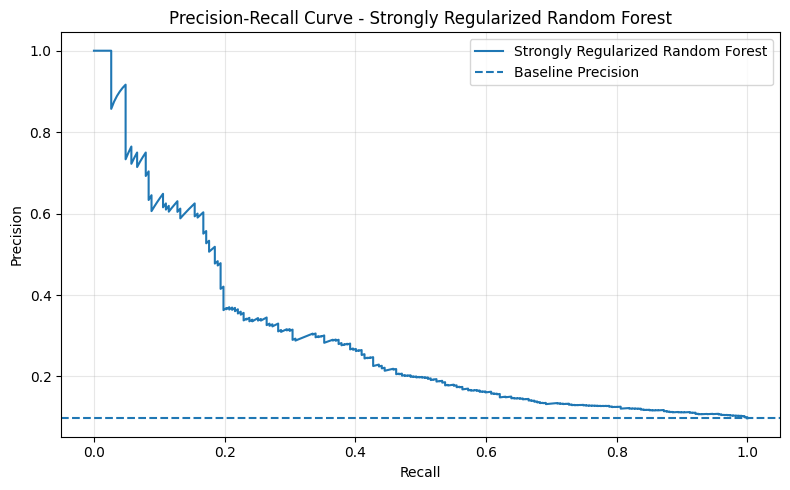


==== FINE-GRAINED THRESHOLD ANALYSIS ====
 Threshold  Precision  Recall  F1 Score
      0.05     0.0985  1.0000    0.1794
      0.06     0.0990  1.0000    0.1801
      0.07     0.0996  1.0000    0.1812
      0.08     0.0998  0.9956    0.1815
      0.09     0.1005  0.9956    0.1826
      0.10     0.1013  0.9956    0.1840
      0.11     0.1022  0.9956    0.1853
      0.12     0.1033  0.9912    0.1870
      0.13     0.1036  0.9780    0.1873
      0.14     0.1052  0.9692    0.1898
      0.15     0.1066  0.9559    0.1918
      0.16     0.1075  0.9251    0.1927
      0.17     0.1110  0.9163    0.1980
      0.18     0.1122  0.8855    0.1992
      0.19     0.1161  0.8722    0.2049
      0.20     0.1176  0.8414    0.2064
      0.21     0.1220  0.8194    0.2125
      0.22     0.1249  0.7930    0.2158
      0.23     0.1283  0.7709    0.2200
      0.24     0.1309  0.7313    0.2221
      0.25     0.1334  0.7004    0.2241
      0.26     0.1380  0.6784    0.2293
      0.27     0.1437  0.6564    0.23

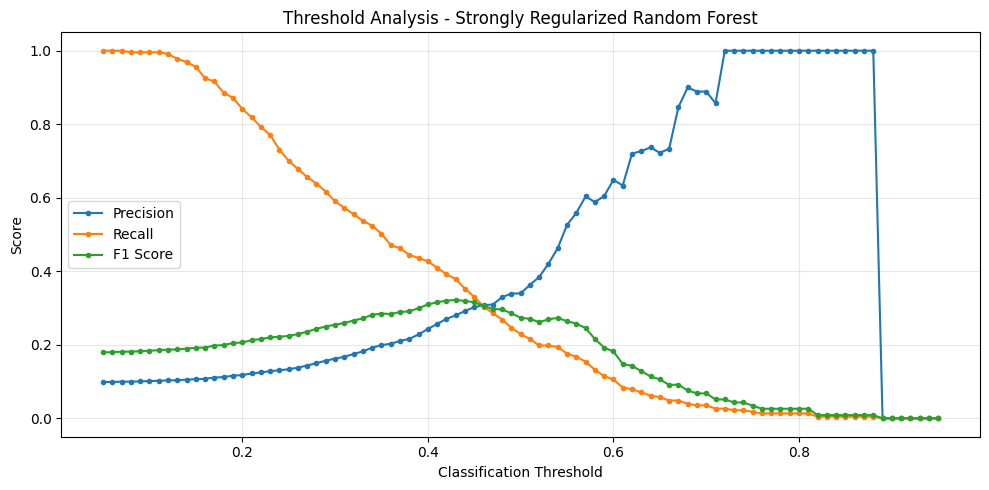


==== BEST THRESHOLD ====
Best Threshold: 0.43000000000000005
Threshold    0.430000
Precision    0.280130
Recall       0.378855
F1 Score     0.322097
Name: 38, dtype: float64

==== TRAIN METRICS ====
Accuracy    : 0.9434
Precision   : 0.6380
Recall      : 0.9648
F1 Score    : 0.7681
ROC-AUC     : 0.9901
PR-AUC      : 0.9172

==== VALIDATION METRICS ====
Accuracy    : 0.8451
Precision   : 0.2801
Recall      : 0.3789
F1 Score    : 0.3221
ROC-AUC     : 0.6896
PR-AUC      : 0.2939

==== TEST METRICS ====
Accuracy    : 0.8494
Precision   : 0.2926
Recall      : 0.3873
F1 Score    : 0.3333
ROC-AUC     : 0.6945
PR-AUC      : 0.3171


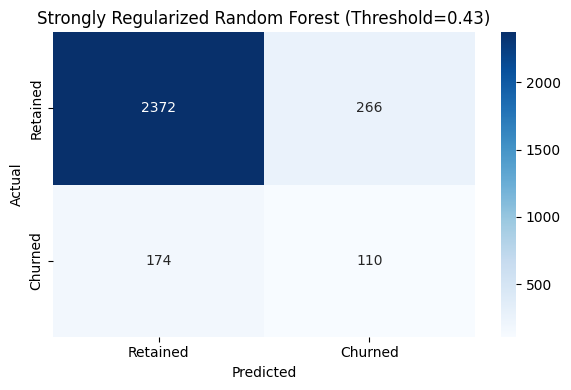


==== CLASSIFICATION REPORT ====
              precision    recall  f1-score   support

    Retained       0.93      0.90      0.92      2638
     Churned       0.29      0.39      0.33       284

    accuracy                           0.85      2922
   macro avg       0.61      0.64      0.62      2922
weighted avg       0.87      0.85      0.86      2922


==== CROSS VALIDATION TRAIN SCORES ====
train_Accuracy - Mean: 0.9725, Std: 0.0023
train_Precision - Mean: 0.8461, Std: 0.0162
train_Recall - Mean: 0.8764, Std: 0.0067
train_F1 - Mean: 0.8609, Std: 0.0105
train_ROC_AUC - Mean: 0.9930, Std: 0.0010
train_PR_AUC - Mean: 0.9365, Std: 0.0105

==== CROSS VALIDATION VALIDATION SCORES ====
test_Accuracy - Mean: 0.8846, Std: 0.0063
test_Precision - Mean: 0.3347, Std: 0.0526
test_Recall - Mean: 0.1872, Std: 0.0350
test_F1 - Mean: 0.2388, Std: 0.0370
test_ROC_AUC - Mean: 0.6848, Std: 0.0185
test_PR_AUC - Mean: 0.2615, Std: 0.0273

==== TOP 20 IMPORTANT FEATURES ====
                   Feature

In [46]:

# ============================================================
# Exp 3 – Stronger Regularization | Random Forest
# ============================================================

# ============================================================
# 0. IMPORT LIBRARIES
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    RandomizedSearchCV,
    cross_validate
)
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import make_column_transformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    precision_recall_curve,
    confusion_matrix,
    classification_report
)

# ============================================================
# 1. SEPARATE FEATURES AND TARGET
# ============================================================

date_cols = [
    'date_activ',
    'date_end',
    'date_modif_prod',
    'date_renewal'
]

X = df.drop(columns=['id', 'churn'] + date_cols)
y = df['churn']

print("Total missing values:", X.isna().sum().sum())
print("\nTarget Distribution:")
print(y.value_counts())
print("\nTarget Percentage:")
print((y.value_counts(normalize=True) * 100).round(2))

# ============================================================
# 2. ORIGINAL TRAIN TEST SPLIT
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nOriginal Training Data:", X_train.shape)
print("Original Test Data:", X_test.shape)

# ============================================================
# 3. INTERNAL TRAIN VALIDATION SPLIT
# ============================================================

# Keep the original test set untouched.
# Use an internal validation set for threshold selection.

X_fit, X_val, y_fit, y_val = train_test_split(
    X_train, y_train,
    test_size=0.20,
    random_state=21,
    stratify=y_train
)

print("\nModel Training Data:", X_fit.shape)
print("Threshold Validation Data:", X_val.shape)

# ============================================================
# 4. IDENTIFY CATEGORICAL AND NUMERICAL COLUMNS
# ============================================================

categorical_cols = X.select_dtypes(
    include=['object', 'category', 'bool']
).columns.tolist()

numerical_cols = X.select_dtypes(
    include=np.number
).columns.tolist()

print("\nCategorical Columns:", categorical_cols)
print("Numerical Columns:", len(numerical_cols))

# ============================================================
# 5. PREPROCESSING PIPELINE
# ============================================================

categorical_pipeline = OneHotEncoder(
    handle_unknown='ignore'
)

preprocessor = make_column_transformer(
    (categorical_pipeline, categorical_cols),
    remainder='passthrough',
    verbose_feature_names_out=False,
    n_jobs=1
)

# ============================================================
# 6. STRONGER REGULARIZED RANDOM FOREST PIPELINE
# ============================================================

strong_rf_pipeline = Pipeline(steps=[
    ("preprocessing", preprocessor),
    ("model", RandomForestClassifier(
        class_weight='balanced',
        random_state=42,
        n_jobs=1
    ))
])

# ============================================================
# 7. STRATIFIED CROSS VALIDATION
# ============================================================

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# ============================================================
# 8. STRONGER REGULARIZATION SEARCH SPACE
# ============================================================

param_grid = {
    'model__n_estimators': [300, 500, 700],
    'model__max_depth': [5, 8, 10, 12],
    'model__min_samples_split': [10, 20, 30],
    'model__min_samples_leaf': [10, 15, 20],
    'model__max_features': [0.3, 0.5, 'sqrt']
}

# ============================================================
# 9. RANDOMIZED SEARCH CV
# ============================================================

random_search = RandomizedSearchCV(
    estimator=strong_rf_pipeline,
    param_distributions=param_grid,
    n_iter=30,
    scoring='average_precision',
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=2,
    refit=True,
    return_train_score=True
)

# ============================================================
# 10. FIT RANDOMIZED SEARCH
# ============================================================

random_search.fit(X_fit, y_fit)

# ============================================================
# 11. BEST HYPERPARAMETERS
# ============================================================

print("\n==== BEST HYPERPARAMETERS ====")
print(random_search.best_params_)

print("\nBest CV PR-AUC:")
print(random_search.best_score_)

# ============================================================
# 12. BEST REGULARIZED RANDOM FOREST MODEL
# ============================================================

best_rf_pipeline = random_search.best_estimator_

# ============================================================
# 13. RANDOMIZED SEARCH RESULTS
# ============================================================

search_results_df = pd.DataFrame(
    random_search.cv_results_
).sort_values(
    by='mean_test_score',
    ascending=False
)

print("\n==== TOP 10 HYPERPARAMETER COMBINATIONS ====")

print(
    search_results_df[[
        'param_model__n_estimators',
        'param_model__max_depth',
        'param_model__min_samples_split',
        'param_model__min_samples_leaf',
        'param_model__max_features',
        'mean_train_score',
        'mean_test_score',
        'std_test_score'
    ]].head(10).round(4).to_string(index=False)
)

# ============================================================
# 14. VALIDATION PROBABILITIES
# ============================================================

y_prob_val = best_rf_pipeline.predict_proba(X_val)[:, 1]

# ============================================================
# 15. PRECISION RECALL CURVE
# ============================================================

precision, recall, pr_thresholds = precision_recall_curve(
    y_val,
    y_prob_val
)

plt.figure(figsize=(8, 5))
plt.plot(
    recall,
    precision,
    label='Strongly Regularized Random Forest'
)
plt.axhline(
    y=y_val.mean(),
    linestyle='--',
    label='Baseline Precision'
)
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve - Strongly Regularized Random Forest')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# ============================================================
# 16. FINE-GRAINED THRESHOLD ANALYSIS
# ============================================================

threshold_values = np.arange(0.05, 0.951, 0.01)
threshold_results = []

for threshold in threshold_values:
    y_pred = (y_prob_val >= threshold).astype(int)

    threshold_results.append({
        'Threshold': threshold,
        'Precision': precision_score(
            y_val, y_pred, zero_division=0
        ),
        'Recall': recall_score(
            y_val, y_pred, zero_division=0
        ),
        'F1 Score': f1_score(
            y_val, y_pred, zero_division=0
        )
    })

fine_threshold_df = pd.DataFrame(threshold_results)

print("\n==== FINE-GRAINED THRESHOLD ANALYSIS ====")
print(fine_threshold_df.round(4).to_string(index=False))

# ============================================================
# 17. THRESHOLD PERFORMANCE VISUALIZATION
# ============================================================

plt.figure(figsize=(10, 5))

plt.plot(
    fine_threshold_df['Threshold'],
    fine_threshold_df['Precision'],
    marker='o',
    markersize=3,
    label='Precision'
)
plt.plot(
    fine_threshold_df['Threshold'],
    fine_threshold_df['Recall'],
    marker='o',
    markersize=3,
    label='Recall'
)
plt.plot(
    fine_threshold_df['Threshold'],
    fine_threshold_df['F1 Score'],
    marker='o',
    markersize=3,
    label='F1 Score'
)

plt.xlabel('Classification Threshold')
plt.ylabel('Score')
plt.title('Threshold Analysis - Strongly Regularized Random Forest')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# ============================================================
# 18. SELECT BEST THRESHOLD
# ============================================================

best_threshold = fine_threshold_df.loc[
    fine_threshold_df['F1 Score'].idxmax(),
    'Threshold'
]

print("\n==== BEST THRESHOLD ====")
print("Best Threshold:", best_threshold)

print(
    fine_threshold_df.loc[
        fine_threshold_df['F1 Score'].idxmax()
    ]
)

# ============================================================
# 19. DEFINE METRIC FUNCTION
# ============================================================

def calc_metrics(y_true, y_pred, y_prob):
    return {
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision': precision_score(
            y_true, y_pred, zero_division=0
        ),
        'Recall': recall_score(
            y_true, y_pred, zero_division=0
        ),
        'F1 Score': f1_score(
            y_true, y_pred, zero_division=0
        ),
        'ROC-AUC': roc_auc_score(y_true, y_prob),
        'PR-AUC': average_precision_score(y_true, y_prob)
    }

# ============================================================
# 20. TRAINING PREDICTIONS
# ============================================================

y_prob_train = best_rf_pipeline.predict_proba(X_fit)[:, 1]

y_pred_train = (
    y_prob_train >= best_threshold
).astype(int)

# ============================================================
# 21. VALIDATION PREDICTIONS
# ============================================================

y_pred_val = (
    y_prob_val >= best_threshold
).astype(int)

# ============================================================
# 22. TEST PREDICTIONS
# ============================================================

y_prob_test = best_rf_pipeline.predict_proba(X_test)[:, 1]

y_pred_test = (
    y_prob_test >= best_threshold
).astype(int)

# ============================================================
# 23. CALCULATE METRICS
# ============================================================

train_metrics = calc_metrics(
    y_fit, y_pred_train, y_prob_train
)

validation_metrics = calc_metrics(
    y_val, y_pred_val, y_prob_val
)

test_metrics = calc_metrics(
    y_test, y_pred_test, y_prob_test
)

# ============================================================
# 24. PRINT TRAIN METRICS
# ============================================================

print("\n==== TRAIN METRICS ====")

for metric, value in train_metrics.items():
    print(f"{metric:12}: {value:.4f}")

# ============================================================
# 25. PRINT VALIDATION METRICS
# ============================================================

print("\n==== VALIDATION METRICS ====")

for metric, value in validation_metrics.items():
    print(f"{metric:12}: {value:.4f}")

# ============================================================
# 26. PRINT TEST METRICS
# ============================================================

print("\n==== TEST METRICS ====")

for metric, value in test_metrics.items():
    print(f"{metric:12}: {value:.4f}")

# ============================================================
# 27. CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(y_test, y_pred_test)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Retained', 'Churned'],
    yticklabels=['Retained', 'Churned']
)

plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title(
    f'Strongly Regularized Random Forest '
    f'(Threshold={best_threshold:.2f})'
)
plt.tight_layout()
plt.show()

# ============================================================
# 28. CLASSIFICATION REPORT
# ============================================================

print("\n==== CLASSIFICATION REPORT ====")

print(classification_report(
    y_test,
    y_pred_test,
    target_names=['Retained', 'Churned'],
    zero_division=0
))

# ============================================================
# 29. CROSS VALIDATION PERFORMANCE
# ============================================================

scoring = {
    'Accuracy': 'accuracy',
    'Precision': 'precision',
    'Recall': 'recall',
    'F1': 'f1',
    'ROC_AUC': 'roc_auc',
    'PR_AUC': 'average_precision'
}

cv_results = cross_validate(
    best_rf_pipeline,
    X_fit,
    y_fit,
    scoring=scoring,
    cv=cv,
    return_train_score=True,
    n_jobs=1
)

# ============================================================
# 30. CROSS VALIDATION TRAIN SCORES
# ============================================================

print("\n==== CROSS VALIDATION TRAIN SCORES ====")

for key, value in cv_results.items():
    if key.startswith('train'):
        print(
            f"{key} - Mean: {np.mean(value):.4f}, "
            f"Std: {np.std(value):.4f}"
        )

# ============================================================
# 31. CROSS VALIDATION VALIDATION SCORES
# ============================================================

print("\n==== CROSS VALIDATION VALIDATION SCORES ====")

for key, value in cv_results.items():
    if key.startswith('test'):
        print(
            f"{key} - Mean: {np.mean(value):.4f}, "
            f"Std: {np.std(value):.4f}"
        )

# ============================================================
# 32. FEATURE IMPORTANCE
# ============================================================

rf_model = best_rf_pipeline.named_steps['model']

feature_names = (
    best_rf_pipeline
    .named_steps['preprocessing']
    .get_feature_names_out()
)

importances = rf_model.feature_importances_

feature_importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
}).sort_values(
    by='Importance',
    ascending=False
).reset_index(drop=True)

print("\n==== TOP 20 IMPORTANT FEATURES ====")
print(feature_importance_df.head(20).to_string(index=False))


**Exp 3 – Stronger Regularization | Random Forest**

**1. Model Optimization**

- Applied stronger regularization using 30 hyperparameter combinations and 5-fold cross-validation.
- Best hyperparameters:
  - `n_estimators`: 700
  - `min_samples_split`: 10
  - `min_samples_leaf`: 10
  - `max_features`: 0.5
  - `max_depth`: 12
- Best CV PR-AUC: **26.15%**

**Observation:**

- Stronger regularization reduced model complexity.
- However, CV PR-AUC decreased compared to the previous Regularized Random Forest (30.55%).

**2. Model Performance – Test Data**

- Accuracy: **84.94%**
- Precision: **29.26%**
- Recall: **38.73%**
- F1 Score: **33.33%**
- ROC-AUC: **69.45%**
- PR-AUC: **31.71%**

**3. Threshold Analysis**

- Tested classification thresholds between 0.05 and 0.95.
- Selected threshold: **0.43**, based on the highest F1 score in the threshold analysis.
- At threshold 0.43 (threshold validation):
  - Precision: 28.01%
  - Recall: 37.89%
  - F1 Score: 32.21%
- Lower thresholds improve recall but reduce precision.
- Higher thresholds improve precision but reduce recall.

**4. Confusion Matrix (Threshold = 0.43)**

- True Negatives: 2,372
- False Positives: 266
- False Negatives: 174
- True Positives: 110

**Observation:**

- Model correctly identifies 110 churn customers out of 284.
- It misses 174 actual churn customers.
- False negatives are lower than in the previous Regularized Random Forest (185).

**5. Precision-Recall Curve**

- Baseline precision is approximately 9.72%, corresponding to the churn percentage.
- Model achieves higher precision than the baseline across much of the recall range.
- PR-AUC of 31.71% is lower than the previous Regularized Random Forest (35.75%).

**6. Cross-Validation Results**

- Training PR-AUC: 93.65%
- Validation accuracy: 88.46%
- Validation precision: 33.47%
- Validation recall: 18.72%
- Validation F1: 23.88%
- Validation ROC-AUC: 68.48%
- Validation PR-AUC: 26.15%

**Observation:**

- Training-validation performance gap still exists, indicating overfitting.
- Validation recall remains low.
- Stronger regularization has not improved validation PR-AUC.

**7. Top 20 Important Features**

The most important features include:

- margin_net_pow_ele
- cons_last_month_diff
- forecast_meter_rent_12m
- margin_per_consumption
- forecast_cons_ratio
- price_consumption_exposure
- months_activ
- margin_per_power
- consumption_per_power
- price_power_interaction

**Observation:**

- Margin-related, consumption-related and price-related features remain important.
- `margin_net_pow_ele` has the highest feature importance.

**8. Model Comparison – All Random Forest Experiments**

| Metric    | Exp1-Baseline RF | Exp2-Regularized RF | Exp3-Strongly Regularized RF |
| --------- | ----------- | -------------- | ----------------------- |
| Accuracy  | 84.02%      | **87.34%**     | 84.94%                  |
| Precision | 26.72%      | **34.86%**     | 29.26%                  |
| Recall    | 36.97%      | 34.86%         | **38.73%**              |
| F1 Score  | 31.02%      | 34.86%         | \*\*33.33%              |
| ROC-AUC   | **70.76%**  | 70.48%         | 69.45%                  |
| PR-AUC    | 32.77%      | **35.75%**     | 31.71%                  |
| CV PR-AUC | 25.43%      | **30.55%**     | 26.15%                  |

**Observation:**

- Strongly Regularized RF improves recall compared to both previous models.
- However, its precision and PR-AUC are lower than Regularized RF.
- Regularized RF maintains the best overall balance between precision and recall.

**Final Conclusion – Strongly Regularized Random Forest**

- Stronger regularization improved recall but reduced overall model performance.
- Test PR-AUC decreased from 35.75% to 31.71%.
- Overfitting still exists despite reducing model complexity.
- Stronger regularization did not provide a consistent improvement.

**Best Model So Far: Regularized Random Forest**

Regularized Random Forest remains the best model because it achieves the highest PR-AUC (35.75%), precision (34.86%) and F1 Score (34.86%). Strongly Regularized RF offers slightly better recall, but its overall churn prediction performance is weaker.

**Important note:** CV classification metrics use the default 0.50 threshold, while validation and test metrics use the selected 0.43 threshold. Compare classification metrics cautiously.

# Exp 4 – Hyperparameter-Tuned Model | XGBoost Classifier

1. One-Hot Encoding (OHE) is applied to categorical features.
2. Class imbalance is handled using scale_pos_weight, calculated from the training data.
3. The original training data is split into model training (80%) and validation (20%), keeping the test set untouched.
4. RandomizedSearchCV with 5-Fold Stratified CV is used to find the best XGBoost hyperparameters based on PR-AUC.
5. The best model generates churn probabilities on the validation set.
6. Validation probabilities are used to find the best classification threshold based on F1 Score.
7. The selected threshold is applied to training, validation, and test probabilities to generate:
   0 = Retained | 1 = Churned.
8. Model performance is evaluated using classification metrics, confusion matrix, and cross-validation.
9. Feature importance is analysed to identify the most influential features.

Total missing values: 33864

Target Distribution:
churn
0    13187
1     1419
Name: count, dtype: int64

Target Percentage:
churn
0    90.28
1     9.72
Name: proportion, dtype: float64

Original Training Data: (11684, 104)
Original Test Data: (2922, 104)

Model Training Data: (9347, 104)
Threshold Validation Data: (2337, 104)

Categorical Columns: ['channel_sales', 'has_gas', 'origin_up']
Numerical Columns: 101

==== CLASS IMBALANCE ====
Negative Class: 8439
Positive Class: 908
Scale Pos Weight: 9.294052863436123
Fitting 5 folds for each of 30 candidates, totalling 150 fits

==== BEST HYPERPARAMETERS ====
{'model__subsample': 0.8, 'model__scale_pos_weight': 1, 'model__reg_lambda': 1, 'model__reg_alpha': 0, 'model__n_estimators': 700, 'model__min_child_weight': 1, 'model__max_depth': 4, 'model__learning_rate': 0.05, 'model__gamma': 0.1, 'model__colsample_bytree': 0.8}

Best CV PR-AUC:
0.2841662008302841

==== TOP 10 HYPERPARAMETER COMBINATIONS ====
 param_model__n_estimators  param_mode

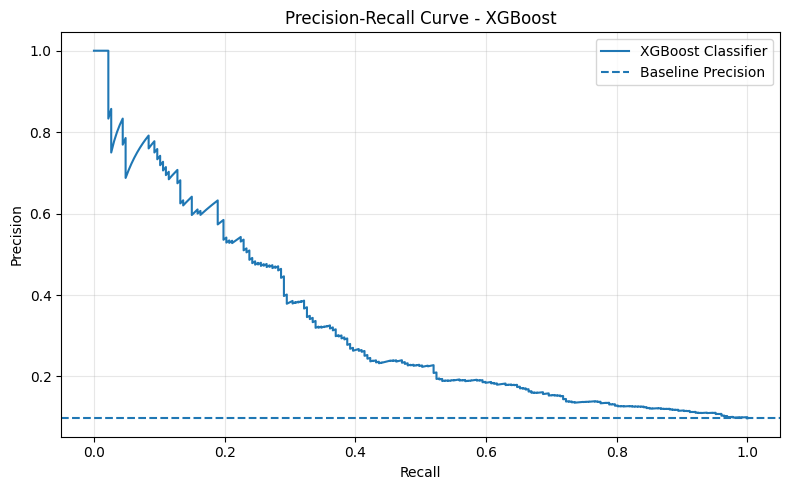


==== FINE-GRAINED THRESHOLD ANALYSIS ====
 Threshold  Precision  Recall  F1 Score
      0.05     0.1382  0.7269    0.2322
      0.06     0.1575  0.6960    0.2569
      0.07     0.1721  0.6520    0.2723
      0.08     0.1842  0.6079    0.2828
      0.09     0.1906  0.5330    0.2807
      0.10     0.2193  0.5198    0.3085
      0.11     0.2319  0.4802    0.3128
      0.12     0.2385  0.4581    0.3137
      0.13     0.2455  0.4229    0.3107
      0.14     0.2605  0.4097    0.3185
      0.15     0.2755  0.3921    0.3236
      0.16     0.2919  0.3833    0.3314
      0.17     0.3111  0.3700    0.3380
      0.18     0.3197  0.3436    0.3312
      0.19     0.3408  0.3348    0.3378
      0.20     0.3700  0.3260    0.3466
      0.21     0.3817  0.3128    0.3438
      0.22     0.3807  0.2952    0.3325
      0.23     0.4314  0.2907    0.3474
      0.24     0.4604  0.2819    0.3497
      0.25     0.4754  0.2555    0.3324
      0.26     0.5000  0.2379    0.3224
      0.27     0.5098  0.2291    0.31

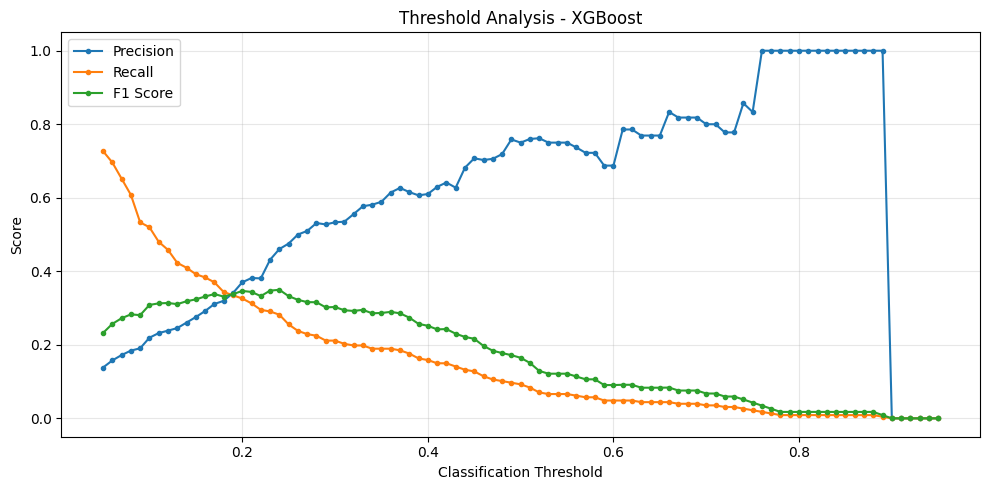


==== BEST THRESHOLD ====
Best Threshold: 0.24000000000000005
Threshold    0.240000
Precision    0.460432
Recall       0.281938
F1 Score     0.349727
Name: 19, dtype: float64

==== TRAIN METRICS ====
Accuracy    : 0.9790
Precision   : 0.9188
Recall      : 0.8601
F1 Score    : 0.8885
ROC-AUC     : 0.9927
PR-AUC      : 0.9555

==== VALIDATION METRICS ====
Accuracy    : 0.8982
Precision   : 0.4604
Recall      : 0.2819
F1 Score    : 0.3497
ROC-AUC     : 0.7134
PR-AUC      : 0.3267

==== TEST METRICS ====
Accuracy    : 0.8939
Precision   : 0.4309
Recall      : 0.2852
F1 Score    : 0.3432
ROC-AUC     : 0.6924
PR-AUC      : 0.3215


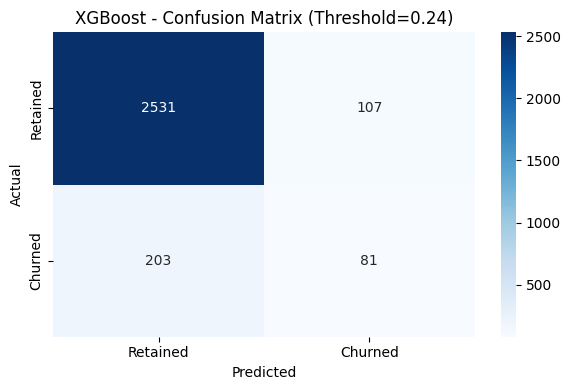


==== CLASSIFICATION REPORT ====
              precision    recall  f1-score   support

    Retained       0.93      0.96      0.94      2638
     Churned       0.43      0.29      0.34       284

    accuracy                           0.89      2922
   macro avg       0.68      0.62      0.64      2922
weighted avg       0.88      0.89      0.88      2922


==== CROSS VALIDATION TRAIN SCORES ====
train_Accuracy - Mean: 0.9600, Std: 0.0014
train_Precision - Mean: 0.9991, Std: 0.0011
train_Recall - Mean: 0.5884, Std: 0.0150
train_F1 - Mean: 0.7405, Std: 0.0119
train_ROC_AUC - Mean: 0.9971, Std: 0.0003
train_PR_AUC - Mean: 0.9801, Std: 0.0014

==== CROSS VALIDATION VALIDATION SCORES ====
test_Accuracy - Mean: 0.9072, Std: 0.0031
test_Precision - Mean: 0.6640, Std: 0.1115
test_Recall - Mean: 0.0881, Std: 0.0230
test_F1 - Mean: 0.1553, Std: 0.0383
test_ROC_AUC - Mean: 0.6838, Std: 0.0231
test_PR_AUC - Mean: 0.2842, Std: 0.0268

==== TOP 20 IMPORTANT FEATURES ====
                          

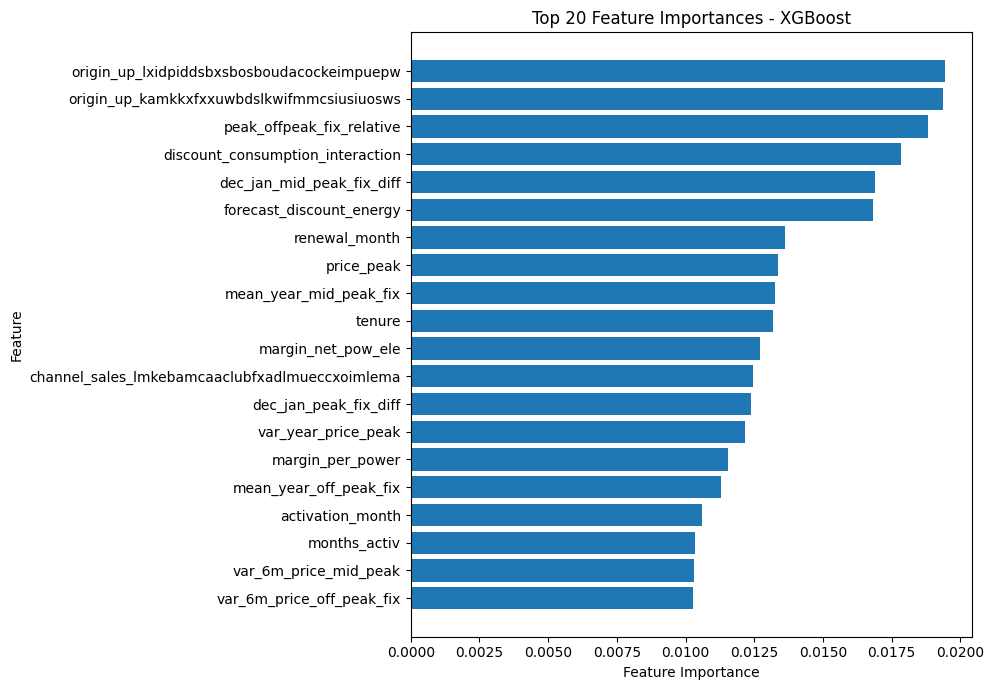

In [47]:

# ============================================================
# EXP 4 - HYPERPARAMETER-TUNED MODEL | XGBOOST CLASSIFIER
# ============================================================

# ============================================================
# 0. IMPORT LIBRARIES
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from xgboost import XGBClassifier

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    RandomizedSearchCV,
    cross_validate
)
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import make_column_transformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    precision_recall_curve,
    confusion_matrix,
    classification_report
)

# ============================================================
# 1. SEPARATE FEATURES AND TARGET
# ============================================================

date_cols = [
    'date_activ',
    'date_end',
    'date_modif_prod',
    'date_renewal'
]

X = df.drop(columns=['id', 'churn'] + date_cols)
y = df['churn']

print("Total missing values:", X.isna().sum().sum())
print("\nTarget Distribution:")
print(y.value_counts())
print("\nTarget Percentage:")
print((y.value_counts(normalize=True) * 100).round(2))

# ============================================================
# 2. ORIGINAL TRAIN TEST SPLIT
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nOriginal Training Data:", X_train.shape)
print("Original Test Data:", X_test.shape)

# ============================================================
# 3. INTERNAL TRAIN VALIDATION SPLIT
# ============================================================

# Keep original test data untouched.
# Use validation data for threshold selection.

X_fit, X_val, y_fit, y_val = train_test_split(
    X_train, y_train,
    test_size=0.20,
    random_state=21,
    stratify=y_train
)

print("\nModel Training Data:", X_fit.shape)
print("Threshold Validation Data:", X_val.shape)

# ============================================================
# 4. IDENTIFY CATEGORICAL AND NUMERICAL COLUMNS
# ============================================================

categorical_cols = X.select_dtypes(
    include=['object', 'category', 'bool']
).columns.tolist()

numerical_cols = X.select_dtypes(
    include=np.number
).columns.tolist()

print("\nCategorical Columns:", categorical_cols)
print("Numerical Columns:", len(numerical_cols))

# ============================================================
# 5. CALCULATE CLASS IMBALANCE RATIO
# ============================================================

negative_count = (y_fit == 0).sum()
positive_count = (y_fit == 1).sum()

scale_pos_weight_value = negative_count / positive_count

print("\n==== CLASS IMBALANCE ====")
print("Negative Class:", negative_count)
print("Positive Class:", positive_count)
print("Scale Pos Weight:", scale_pos_weight_value)

# ============================================================
# 6. PREPROCESSING PIPELINE
# ============================================================

categorical_pipeline = OneHotEncoder(
    handle_unknown='ignore'
)

preprocessor = make_column_transformer(
    (categorical_pipeline, categorical_cols),
    remainder='passthrough',
    verbose_feature_names_out=False,
    n_jobs=1
)

# ============================================================
# 7. XGBOOST PIPELINE
# ============================================================

xgb_pipeline = Pipeline(steps=[
    ("preprocessing", preprocessor),
    ("model", XGBClassifier(
        objective='binary:logistic',
        eval_metric='aucpr',
        tree_method='hist',
        random_state=42,
        n_jobs=1,
        verbosity=0
    ))
])

# ============================================================
# 8. STRATIFIED CROSS VALIDATION
# ============================================================

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# ============================================================
# 9. HYPERPARAMETER SEARCH SPACE
# ============================================================

param_grid = {
    'model__n_estimators': [200, 300, 500, 700],
    'model__max_depth': [2, 3, 4, 5, 6],
    'model__learning_rate': [0.01, 0.03, 0.05, 0.1],
    'model__subsample': [0.7, 0.8, 0.9, 1.0],
    'model__colsample_bytree': [0.6, 0.7, 0.8, 1.0],
    'model__min_child_weight': [1, 3, 5, 7],
    'model__gamma': [0, 0.1, 0.3, 0.5],
    'model__reg_alpha': [0, 0.01, 0.1, 1],
    'model__reg_lambda': [1, 3, 5, 10],
    'model__scale_pos_weight': [
        1,
        scale_pos_weight_value * 0.5,
        scale_pos_weight_value * 0.75,
        scale_pos_weight_value
    ]
}

# ============================================================
# 10. RANDOMIZED SEARCH CV
# ============================================================

random_search = RandomizedSearchCV(
    estimator=xgb_pipeline,
    param_distributions=param_grid,
    n_iter=30,
    scoring='average_precision',
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=2,
    refit=True,
    return_train_score=True
)

# ============================================================
# 11. FIT RANDOMIZED SEARCH
# ============================================================

random_search.fit(X_fit, y_fit)

# ============================================================
# 12. BEST HYPERPARAMETERS
# ============================================================

print("\n==== BEST HYPERPARAMETERS ====")
print(random_search.best_params_)

print("\nBest CV PR-AUC:")
print(random_search.best_score_)

# ============================================================
# 13. BEST XGBOOST MODEL
# ============================================================

best_xgb_pipeline = random_search.best_estimator_

# ============================================================
# 14. RANDOMIZED SEARCH RESULTS
# ============================================================

search_results_df = pd.DataFrame(
    random_search.cv_results_
).sort_values(
    by='mean_test_score',
    ascending=False
)

print("\n==== TOP 10 HYPERPARAMETER COMBINATIONS ====")

print(
    search_results_df[[
        'param_model__n_estimators',
        'param_model__max_depth',
        'param_model__learning_rate',
        'param_model__subsample',
        'param_model__colsample_bytree',
        'param_model__min_child_weight',
        'param_model__scale_pos_weight',
        'mean_train_score',
        'mean_test_score',
        'std_test_score'
    ]].head(10).round(4).to_string(index=False)
)

# ============================================================
# 15. VALIDATION PROBABILITIES
# ============================================================

y_prob_val = best_xgb_pipeline.predict_proba(X_val)[:, 1]

# ============================================================
# 16. PRECISION RECALL CURVE
# ============================================================

precision, recall, pr_thresholds = precision_recall_curve(
    y_val,
    y_prob_val
)

plt.figure(figsize=(8, 5))
plt.plot(
    recall,
    precision,
    label='XGBoost Classifier'
)
plt.axhline(
    y=y_val.mean(),
    linestyle='--',
    label='Baseline Precision'
)
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve - XGBoost')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# ============================================================
# 17. FINE-GRAINED THRESHOLD ANALYSIS
# ============================================================

threshold_values = np.arange(0.05, 0.951, 0.01)
threshold_results = []

for threshold in threshold_values:
    y_pred = (y_prob_val >= threshold).astype(int)

    threshold_results.append({
        'Threshold': threshold,
        'Precision': precision_score(
            y_val, y_pred, zero_division=0
        ),
        'Recall': recall_score(
            y_val, y_pred, zero_division=0
        ),
        'F1 Score': f1_score(
            y_val, y_pred, zero_division=0
        )
    })

fine_threshold_df = pd.DataFrame(threshold_results)

print("\n==== FINE-GRAINED THRESHOLD ANALYSIS ====")
print(fine_threshold_df.round(4).to_string(index=False))

# ============================================================
# 18. THRESHOLD PERFORMANCE VISUALIZATION
# ============================================================

plt.figure(figsize=(10, 5))

plt.plot(
    fine_threshold_df['Threshold'],
    fine_threshold_df['Precision'],
    marker='o',
    markersize=3,
    label='Precision'
)
plt.plot(
    fine_threshold_df['Threshold'],
    fine_threshold_df['Recall'],
    marker='o',
    markersize=3,
    label='Recall'
)
plt.plot(
    fine_threshold_df['Threshold'],
    fine_threshold_df['F1 Score'],
    marker='o',
    markersize=3,
    label='F1 Score'
)

plt.xlabel('Classification Threshold')
plt.ylabel('Score')
plt.title('Threshold Analysis - XGBoost')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# ============================================================
# 19. SELECT BEST THRESHOLD
# ============================================================

best_threshold = fine_threshold_df.loc[
    fine_threshold_df['F1 Score'].idxmax(),
    'Threshold'
]

print("\n==== BEST THRESHOLD ====")
print("Best Threshold:", best_threshold)

print(
    fine_threshold_df.loc[
        fine_threshold_df['F1 Score'].idxmax()
    ]
)

# ============================================================
# 20. DEFINE METRIC FUNCTION
# ============================================================

def calc_metrics(y_true, y_pred, y_prob):
    return {
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision': precision_score(
            y_true, y_pred, zero_division=0
        ),
        'Recall': recall_score(
            y_true, y_pred, zero_division=0
        ),
        'F1 Score': f1_score(
            y_true, y_pred, zero_division=0
        ),
        'ROC-AUC': roc_auc_score(y_true, y_prob),
        'PR-AUC': average_precision_score(y_true, y_prob)
    }

# ============================================================
# 21. TRAINING PREDICTIONS
# ============================================================

y_prob_train = best_xgb_pipeline.predict_proba(X_fit)[:, 1]

y_pred_train = (
    y_prob_train >= best_threshold
).astype(int)

# ============================================================
# 22. VALIDATION PREDICTIONS
# ============================================================

y_pred_val = (
    y_prob_val >= best_threshold
).astype(int)

# ============================================================
# 23. TEST PREDICTIONS
# ============================================================

y_prob_test = best_xgb_pipeline.predict_proba(X_test)[:, 1]

y_pred_test = (
    y_prob_test >= best_threshold
).astype(int)

# ============================================================
# 24. CALCULATE METRICS
# ============================================================

train_metrics = calc_metrics(
    y_fit, y_pred_train, y_prob_train
)

validation_metrics = calc_metrics(
    y_val, y_pred_val, y_prob_val
)

test_metrics = calc_metrics(
    y_test, y_pred_test, y_prob_test
)

# ============================================================
# 25. PRINT TRAIN METRICS
# ============================================================

print("\n==== TRAIN METRICS ====")

for metric, value in train_metrics.items():
    print(f"{metric:12}: {value:.4f}")

# ============================================================
# 26. PRINT VALIDATION METRICS
# ============================================================

print("\n==== VALIDATION METRICS ====")

for metric, value in validation_metrics.items():
    print(f"{metric:12}: {value:.4f}")

# ============================================================
# 27. PRINT TEST METRICS
# ============================================================

print("\n==== TEST METRICS ====")

for metric, value in test_metrics.items():
    print(f"{metric:12}: {value:.4f}")

# ============================================================
# 28. CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(y_test, y_pred_test)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Retained', 'Churned'],
    yticklabels=['Retained', 'Churned']
)

plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title(
    f'XGBoost - Confusion Matrix '
    f'(Threshold={best_threshold:.2f})'
)
plt.tight_layout()
plt.show()

# ============================================================
# 29. CLASSIFICATION REPORT
# ============================================================

print("\n==== CLASSIFICATION REPORT ====")

print(classification_report(
    y_test,
    y_pred_test,
    target_names=['Retained', 'Churned'],
    zero_division=0
))

# ============================================================
# 30. CROSS VALIDATION PERFORMANCE
# ============================================================

scoring = {
    'Accuracy': 'accuracy',
    'Precision': 'precision',
    'Recall': 'recall',
    'F1': 'f1',
    'ROC_AUC': 'roc_auc',
    'PR_AUC': 'average_precision'
}

cv_results = cross_validate(
    best_xgb_pipeline,
    X_fit,
    y_fit,
    scoring=scoring,
    cv=cv,
    return_train_score=True,
    n_jobs=1
)

# ============================================================
# 31. CROSS VALIDATION TRAIN SCORES
# ============================================================

print("\n==== CROSS VALIDATION TRAIN SCORES ====")

for key, value in cv_results.items():
    if key.startswith('train'):
        print(
            f"{key} - Mean: {np.mean(value):.4f}, "
            f"Std: {np.std(value):.4f}"
        )

# ============================================================
# 32. CROSS VALIDATION VALIDATION SCORES
# ============================================================

print("\n==== CROSS VALIDATION VALIDATION SCORES ====")

for key, value in cv_results.items():
    if key.startswith('test'):
        print(
            f"{key} - Mean: {np.mean(value):.4f}, "
            f"Std: {np.std(value):.4f}"
        )

# ============================================================
# 33. FEATURE IMPORTANCE
# ============================================================

xgb_model = best_xgb_pipeline.named_steps['model']

feature_names = (
    best_xgb_pipeline
    .named_steps['preprocessing']
    .get_feature_names_out()
)

importances = xgb_model.feature_importances_

feature_importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
}).sort_values(
    by='Importance',
    ascending=False
).reset_index(drop=True)

print("\n==== TOP 20 IMPORTANT FEATURES ====")
print(feature_importance_df.head(20).to_string(index=False))

# ============================================================
# 34. FEATURE IMPORTANCE VISUALIZATION
# ============================================================

top_features = feature_importance_df.head(20).sort_values(
    by='Importance',
    ascending=True
)

plt.figure(figsize=(10, 7))
plt.barh(
    top_features['Feature'],
    top_features['Importance']
)

plt.xlabel('Feature Importance')
plt.ylabel('Feature')
plt.title('Top 20 Feature Importances - XGBoost')
plt.tight_layout()
plt.show()


**Exp 4 – Hyperparameter-Tuned Model | XGBoost Classifier**

**1. Model Optimization**

- Applied hyperparameter tuning using 30 parameter combinations and 5-fold cross-validation.
- Class imbalance was considered using `scale_pos_weight`.
- Best hyperparameters:
  - `n_estimators`: 700
  - `max_depth`: 4
  - `learning_rate`: 0.05
  - `subsample`: 0.8
  - `colsample_bytree`: 0.8
  - `min_child_weight`: 1
  - `gamma`: 0.1
  - `reg_alpha`: 0
  - `reg_lambda`: 1
  - `scale_pos_weight`: 1
- Best CV PR-AUC: **28.42%**

**Observation:**

- Hyperparameter tuning selected a relatively shallow tree depth of 4.
- Despite considering class imbalance, the best configuration selected `scale_pos_weight=1`.
- CV PR-AUC improved compared to the baseline RF (25.43%).

**2. Model Performance – Test Data**

- Accuracy: **89.39%**
- Precision: **43.09%**
- Recall: **28.52%**
- F1 Score: **34.32%**
- ROC-AUC: **69.24%**
- PR-AUC: **32.15%**

**3. Threshold Analysis**

- Tested classification thresholds between 0.05 and 0.95.
- Selected threshold: **0.24**, based on the highest F1 score in the threshold analysis.
- At threshold 0.24 (threshold validation):
  - Precision: 46.04%
  - Recall: 28.19%
  - F1 Score: 34.97%
- Lower thresholds improve recall but reduce precision.
- Higher thresholds improve precision but reduce recall.

**4. Confusion Matrix (Threshold = 0.24)**

- True Negatives: 2,531
- False Positives: 107
- False Negatives: 203
- True Positives: 81

**Observation:**

- Model correctly identifies 81 churn customers out of 284.
- It misses 203 actual churn customers.
- False positives are relatively low (107), indicating better precision.
- However, the model misses a large number of actual churn customers.

**5. Precision-Recall Curve**

- Baseline precision is approximately 9.72%, corresponding to the churn percentage.
- Model achieves higher precision than the baseline across much of the recall range.
- PR-AUC of 32.15% is slightly lower than the baseline RF (32.77%).

**6. Cross-Validation Results**

- Training PR-AUC: 98.01%
- Validation accuracy: 90.72%
- Validation precision: 66.40%
- Validation recall: 8.81%
- Validation F1: 15.53%
- Validation ROC-AUC: 68.38%
- Validation PR-AUC: 28.42%

**Observation:**

- Large difference between training and validation PR-AUC indicates overfitting.
- Validation recall is extremely low.
- Despite hyperparameter tuning, the model struggles to identify churn customers during cross-validation.

**7. Top 20 Important Features**

The most important features include:

- origin_up related features
- peak_offpeak_fix_relative
- discount_consumption_interaction
- dec_jan_mid_peak_fix_diff
- forecast_discount_energy
- renewal_month
- price_peak
- mean_year_mid_peak_fix
- tenure
- margin_net_pow_ele

**Observation:**

- Price-related, discount-related and contract-related features contribute significantly.
- Customer tenure and subscription-related features also influence churn predictions.
- Feature importance differs from Random Forest, highlighting different patterns captured by XGBoost.

**8. Model Comparison – All Experiments**

| Metric    | Exp1-Baseline RF | Exp2-Regularized RF | Exp3-Strongly Regularized RF | Exp4-XGBoost |
| --------- | ---------------- | ------------------- | ---------------------------- | ------------ |
| Accuracy  | 84.02%           | 87.34%              | 84.94%                       | **89.39%**   |
| Precision | 26.72%           | 34.86%              | 29.26%                       | **43.09%**   |
| Recall    | 36.97%           | 34.86%              | **38.73%**                   | 28.52%       |
| F1 Score  | 31.02%           | **34.86%**          | 33.33%                       | 34.32%       |
| ROC-AUC   | **70.76%**       | 70.48%              | 69.45%                       | 69.24%       |
| PR-AUC    | 32.77%           | **35.75%**          | 31.71%                       | 32.15%       |
| CV PR-AUC | 25.43%           | **30.55%**          | 26.15%                       | 28.42%       |

**Observation:**

- XGBoost achieves the highest accuracy and precision.
- Its F1 Score (34.32%) is close to Regularized RF (34.86%).
- However, recall is the lowest among the four models.
- PR-AUC is lower than Regularized RF and baseline RF.
- XGBoost generates fewer false positives but misses more actual churn customers.

**Final Conclusion – XGBoost Classifier**

- XGBoost provides better precision and accuracy but struggles with churn recall.
- Its test PR-AUC (32.15%) is lower than the Regularized RF (35.75%).
- Overfitting remains a concern.
- The model is more conservative in predicting churn customers.

**Best Model So Far: Exp 2 – Regularized Random Forest**

Regularized Random Forest remains the best overall model because it achieves the highest PR-AUC (35.75%) and F1 Score (34.86%), providing a better balance between identifying churn customers and controlling false positives.

XGBoost is useful when precision is more important, but it misses too many actual churn customers for our current objective.

**Important note:** CV classification metrics use the default 0.50 threshold, while validation and test metrics use the selected 0.24 threshold. Compare classification metrics cautiously.

# Exp 5 – Strongly Regularized Model | XGBoost Classifier

1. One-Hot Encoding (OHE) is applied to categorical features.
2. Class imbalance is handled using scale_pos_weight, calculated from the model training data.
3. The original training data is split into model training (80%) and validation (20%), keeping the test set untouched.
4. RandomizedSearchCV with 5-Fold Stratified CV and 40 iterations is used to find the best XGBoost hyperparameters based on PR-AUC.
5. Strong regularization is applied through restricted tree depth, subsampling, min_child_weight, gamma, L1, and L2 penalties.
6. The best model generates churn probabilities on the validation set.
7. Validation probabilities are used to select the best classification threshold based on F1 Score.
8. The selected threshold is applied to training, validation, and test probabilities to generate:
   0 = Retained | 1 = Churned.
9. Model performance is evaluated using classification metrics, confusion matrix, and cross-validation.
10. Feature importance is analysed to identify the most influential features.

Total missing values: 33864

Target Distribution:
churn
0    13187
1     1419
Name: count, dtype: int64

Target Percentage:
churn
0    90.284814
1     9.715186
Name: proportion, dtype: float64

Original Training Data: (11684, 104)
Original Test Data: (2922, 104)

Model Training Data: (9347, 104)
Threshold Validation Data: (2337, 104)

Categorical Columns: ['channel_sales', 'has_gas', 'origin_up']
Numerical Columns: 101

==== CLASS IMBALANCE ====
Negative Class: 8439
Positive Class: 908
Scale Pos Weight: 9.294052863436123
Fitting 5 folds for each of 40 candidates, totalling 200 fits

==== BEST HYPERPARAMETERS ====
{'model__subsample': 0.8, 'model__scale_pos_weight': np.float64(4.647026431718062), 'model__reg_lambda': 50, 'model__reg_alpha': 1, 'model__n_estimators': 900, 'model__min_child_weight': 10, 'model__max_depth': 4, 'model__learning_rate': 0.03, 'model__gamma': 2, 'model__colsample_bytree': 0.6}

Best CV PR-AUC:
0.2638356437360839

==== TOP 10 HYPERPARAMETER COMBINATIONS ====
 p

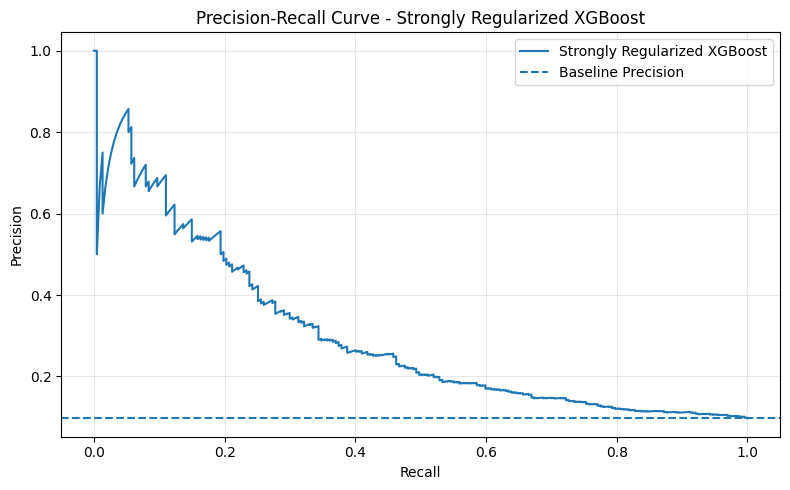


==== FINE-GRAINED THRESHOLD ANALYSIS ====
 Threshold  Precision  Recall  F1 Score
      0.05     0.1008  0.9956    0.1831
      0.06     0.1016  0.9868    0.1843
      0.07     0.1029  0.9736    0.1862
      0.08     0.1053  0.9692    0.1900
      0.09     0.1064  0.9515    0.1914
      0.10     0.1073  0.9251    0.1923
      0.11     0.1108  0.9163    0.1977
      0.12     0.1130  0.8899    0.2006
      0.13     0.1148  0.8722    0.2030
      0.14     0.1155  0.8370    0.2030
      0.15     0.1189  0.8194    0.2077
      0.16     0.1220  0.7974    0.2117
      0.17     0.1259  0.7885    0.2171
      0.18     0.1287  0.7709    0.2205
      0.19     0.1338  0.7533    0.2272
      0.20     0.1381  0.7357    0.2326
      0.21     0.1437  0.7225    0.2398
      0.22     0.1470  0.7004    0.2429
      0.23     0.1483  0.6740    0.2431
      0.24     0.1557  0.6652    0.2523
      0.25     0.1597  0.6432    0.2559
      0.26     0.1663  0.6300    0.2631
      0.27     0.1710  0.6079    0.26

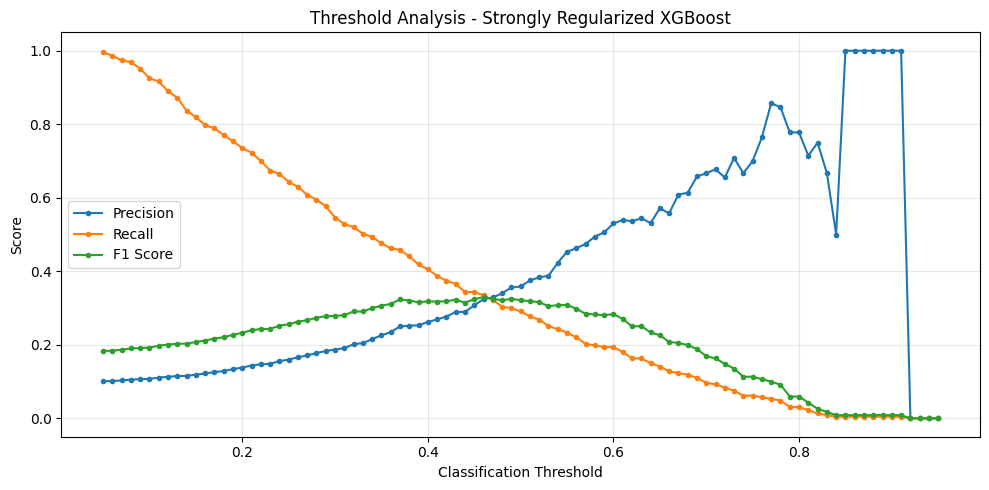


==== BEST THRESHOLD ====
Best Threshold: 0.4600000000000001
Threshold    0.460000
Precision    0.324786
Recall       0.334802
F1 Score     0.329718
Name: 41, dtype: float64

==== TRAIN METRICS ====
Accuracy    : 0.9330
Precision   : 0.6353
Recall      : 0.7291
F1 Score    : 0.6790
ROC-AUC     : 0.9562
PR-AUC      : 0.7533

==== VALIDATION METRICS ====
Accuracy    : 0.8678
Precision   : 0.3248
Recall      : 0.3348
F1 Score    : 0.3297
ROC-AUC     : 0.6990
PR-AUC      : 0.2991

==== TEST METRICS ====
Accuracy    : 0.8669
Precision   : 0.3183
Recall      : 0.3239
F1 Score    : 0.3211
ROC-AUC     : 0.6958
PR-AUC      : 0.2942


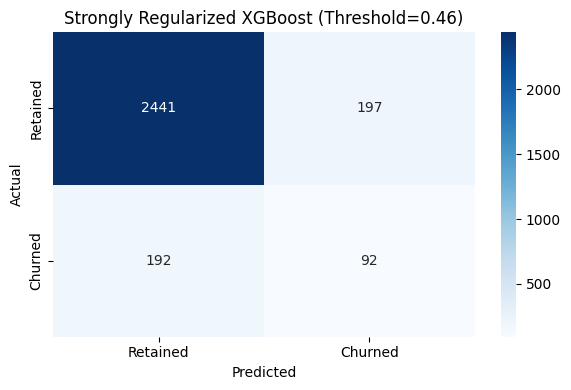


==== CLASSIFICATION REPORT ====
              precision    recall  f1-score   support

    Retained       0.93      0.93      0.93      2638
     Churned       0.32      0.32      0.32       284

    accuracy                           0.87      2922
   macro avg       0.62      0.62      0.62      2922
weighted avg       0.87      0.87      0.87      2922


==== CROSS VALIDATION TRAIN SCORES ====
train_Accuracy - Mean: 0.9472, Std: 0.0015
train_Precision - Mean: 0.7391, Std: 0.0097
train_Recall - Mean: 0.7062, Std: 0.0143
train_F1 - Mean: 0.7222, Std: 0.0090
train_ROC_AUC - Mean: 0.9671, Std: 0.0017
train_PR_AUC - Mean: 0.7990, Std: 0.0095

==== CROSS VALIDATION VALIDATION SCORES ====
test_Accuracy - Mean: 0.8794, Std: 0.0041
test_Precision - Mean: 0.3346, Std: 0.0305
test_Recall - Mean: 0.2456, Std: 0.0312
test_F1 - Mean: 0.2830, Std: 0.0310
test_ROC_AUC - Mean: 0.6874, Std: 0.0193
test_PR_AUC - Mean: 0.2638, Std: 0.0238

==== TOP 20 IMPORTANT FEATURES ====
                          

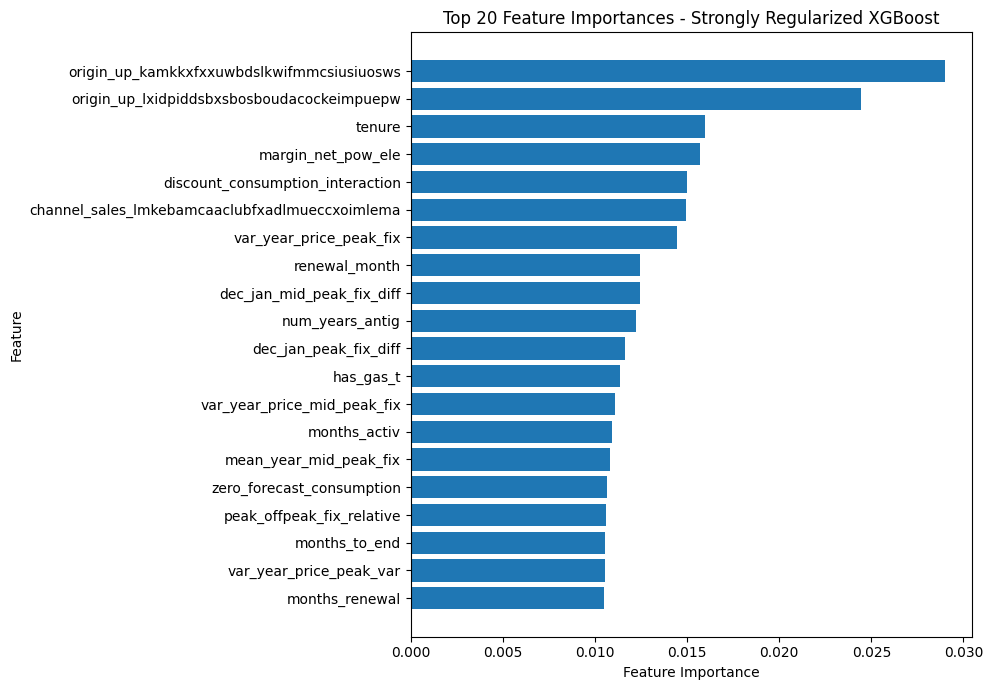

In [48]:

# ============================================================
# Exp 5 – Strongly Regularized Model | XGBoost Classifier
# ============================================================

# 0. IMPORT LIBRARIES
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from xgboost import XGBClassifier

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    RandomizedSearchCV,
    cross_validate
)
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import make_column_transformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    precision_recall_curve,
    confusion_matrix,
    classification_report
)

# ============================================================
# 1. SEPARATE FEATURES AND TARGET
# ============================================================

date_cols = [
    'date_activ',
    'date_end',
    'date_modif_prod',
    'date_renewal'
]

X = df.drop(columns=['id', 'churn'] + date_cols)
y = df['churn']

print("Total missing values:", X.isna().sum().sum())
print("\nTarget Distribution:")
print(y.value_counts())
print("\nTarget Percentage:")
print(y.value_counts(normalize=True) * 100)

# ============================================================
# 2. ORIGINAL TRAIN TEST SPLIT
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nOriginal Training Data:", X_train.shape)
print("Original Test Data:", X_test.shape)

# ============================================================
# 3. INTERNAL TRAIN VALIDATION SPLIT
# ============================================================

# Keep original test data untouched.
# Use validation data for threshold selection.

X_fit, X_val, y_fit, y_val = train_test_split(
    X_train, y_train,
    test_size=0.20,
    random_state=21,
    stratify=y_train
)

print("\nModel Training Data:", X_fit.shape)
print("Threshold Validation Data:", X_val.shape)

# ============================================================
# 4. IDENTIFY CATEGORICAL AND NUMERICAL COLUMNS
# ============================================================

categorical_cols = X.select_dtypes(
    include=['object', 'category', 'bool']
).columns.tolist()

numerical_cols = X.select_dtypes(
    include=np.number
).columns.tolist()

print("\nCategorical Columns:", categorical_cols)
print("Numerical Columns:", len(numerical_cols))

# ============================================================
# 5. CLASS IMBALANCE
# ============================================================

negative_count = (y_fit == 0).sum()
positive_count = (y_fit == 1).sum()
scale_pos_weight_value = negative_count / positive_count

print("\n==== CLASS IMBALANCE ====")
print("Negative Class:", negative_count)
print("Positive Class:", positive_count)
print("Scale Pos Weight:", scale_pos_weight_value)

# ============================================================
# 6. PREPROCESSING PIPELINE
# ============================================================

categorical_pipeline = OneHotEncoder(handle_unknown='ignore')

preprocessor = make_column_transformer(
    (categorical_pipeline, categorical_cols),
    remainder='passthrough',
    verbose_feature_names_out=False,
    n_jobs=1
)

# ============================================================
# 7. STRONGLY REGULARIZED XGBOOST PIPELINE
# ============================================================

xgb_pipeline = Pipeline(steps=[
    ("preprocessing", preprocessor),
    ("model", XGBClassifier(
        objective='binary:logistic',
        eval_metric='aucpr',
        tree_method='hist',
        random_state=42,
        n_jobs=1,
        verbosity=0
    ))
])

# ============================================================
# 8. STRATIFIED CROSS VALIDATION
# ============================================================

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# ============================================================
# 9. STRONG REGULARIZATION SEARCH SPACE
# ============================================================

param_grid = {
    # Number of boosting trees
    'model__n_estimators': [300, 500, 700, 900],

    # Restrict tree depth
    'model__max_depth': [2, 3, 4],

    # Lower learning rates
    'model__learning_rate': [0.01, 0.03, 0.05],

    # Row subsampling
    'model__subsample': [0.6, 0.7, 0.8],

    # Feature subsampling
    'model__colsample_bytree': [0.5, 0.6, 0.7],

    # Stronger minimum child weight
    'model__min_child_weight': [5, 10, 15, 20],

    # Stronger split restrictions
    'model__gamma': [0.3, 0.5, 1, 2],

    # L1 regularization
    'model__reg_alpha': [0.1, 1, 5, 10],

    # L2 regularization
    'model__reg_lambda': [5, 10, 20, 50],

    # Class imbalance
    'model__scale_pos_weight': [
        1,
        scale_pos_weight_value * 0.25,
        scale_pos_weight_value * 0.50,
        scale_pos_weight_value * 0.75,
        scale_pos_weight_value
    ]
}

# ============================================================
# 10. RANDOMIZED SEARCH CV
# ============================================================

random_search = RandomizedSearchCV(
    estimator=xgb_pipeline,
    param_distributions=param_grid,
    n_iter=40,
    scoring='average_precision',
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=2,
    refit=True,
    return_train_score=True
)

# ============================================================
# 11. FIT RANDOMIZED SEARCH
# ============================================================

random_search.fit(X_fit, y_fit)

# ============================================================
# 12. BEST HYPERPARAMETERS
# ============================================================

print("\n==== BEST HYPERPARAMETERS ====")
print(random_search.best_params_)
print("\nBest CV PR-AUC:")
print(random_search.best_score_)

# ============================================================
# 13. BEST XGBOOST MODEL
# ============================================================

best_xgb_pipeline = random_search.best_estimator_

# ============================================================
# 14. RANDOMIZED SEARCH RESULTS
# ============================================================

search_results_df = pd.DataFrame(random_search.cv_results_)

search_results_df = search_results_df.sort_values(
    by='mean_test_score',
    ascending=False
)

print("\n==== TOP 10 HYPERPARAMETER COMBINATIONS ====")

display_cols = [
    'param_model__n_estimators',
    'param_model__max_depth',
    'param_model__learning_rate',
    'param_model__min_child_weight',
    'param_model__gamma',
    'param_model__reg_alpha',
    'param_model__reg_lambda',
    'param_model__scale_pos_weight',
    'mean_train_score',
    'mean_test_score',
    'std_test_score'
]

print(
    search_results_df[display_cols]
    .head(10)
    .round(4)
    .to_string(index=False)
)

# ============================================================
# 15. VALIDATION PROBABILITIES
# ============================================================

y_prob_val = best_xgb_pipeline.predict_proba(X_val)[:, 1]

# ============================================================
# 16. PRECISION RECALL CURVE
# ============================================================

precision, recall, pr_thresholds = precision_recall_curve(
    y_val,
    y_prob_val
)

plt.figure(figsize=(8, 5))
plt.plot(
    recall,
    precision,
    label='Strongly Regularized XGBoost'
)
plt.axhline(
    y=y_val.mean(),
    linestyle='--',
    label='Baseline Precision'
)
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve - Strongly Regularized XGBoost')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# ============================================================
# 17. FINE-GRAINED THRESHOLD ANALYSIS
# ============================================================

threshold_values = np.arange(0.05, 0.951, 0.01)
threshold_results = []

for threshold in threshold_values:
    y_pred = (y_prob_val >= threshold).astype(int)

    precision_value = precision_score(
        y_val, y_pred,
        zero_division=0
    )
    recall_value = recall_score(
        y_val, y_pred,
        zero_division=0
    )
    f1_value = f1_score(
        y_val, y_pred,
        zero_division=0
    )

    threshold_results.append({
        'Threshold': threshold,
        'Precision': precision_value,
        'Recall': recall_value,
        'F1 Score': f1_value
    })

fine_threshold_df = pd.DataFrame(threshold_results)

print("\n==== FINE-GRAINED THRESHOLD ANALYSIS ====")
print(fine_threshold_df.round(4).to_string(index=False))

# ============================================================
# 18. THRESHOLD PERFORMANCE VISUALIZATION
# ============================================================

plt.figure(figsize=(10, 5))

plt.plot(
    fine_threshold_df['Threshold'],
    fine_threshold_df['Precision'],
    marker='o',
    markersize=3,
    label='Precision'
)
plt.plot(
    fine_threshold_df['Threshold'],
    fine_threshold_df['Recall'],
    marker='o',
    markersize=3,
    label='Recall'
)
plt.plot(
    fine_threshold_df['Threshold'],
    fine_threshold_df['F1 Score'],
    marker='o',
    markersize=3,
    label='F1 Score'
)

plt.xlabel('Classification Threshold')
plt.ylabel('Score')
plt.title('Threshold Analysis - Strongly Regularized XGBoost')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# ============================================================
# 19. SELECT BEST THRESHOLD
# ============================================================

best_threshold_idx = fine_threshold_df['F1 Score'].idxmax()
best_threshold = fine_threshold_df.loc[
    best_threshold_idx, 'Threshold'
]

print("\n==== BEST THRESHOLD ====")
print("Best Threshold:", best_threshold)
print(fine_threshold_df.loc[best_threshold_idx])

# ============================================================
# 20. DEFINE METRIC FUNCTION
# ============================================================

def calc_metrics(y_true, y_pred, y_prob):
    return {
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred, zero_division=0),
        'Recall': recall_score(y_true, y_pred, zero_division=0),
        'F1 Score': f1_score(y_true, y_pred, zero_division=0),
        'ROC-AUC': roc_auc_score(y_true, y_prob),
        'PR-AUC': average_precision_score(y_true, y_prob)
    }

# ============================================================
# 21. TRAINING PREDICTIONS
# ============================================================

y_prob_train = best_xgb_pipeline.predict_proba(X_fit)[:, 1]
y_pred_train = (y_prob_train >= best_threshold).astype(int)

# ============================================================
# 22. VALIDATION PREDICTIONS
# ============================================================

y_pred_val = (y_prob_val >= best_threshold).astype(int)

# ============================================================
# 23. TEST PREDICTIONS
# ============================================================

y_prob_test = best_xgb_pipeline.predict_proba(X_test)[:, 1]
y_pred_test = (y_prob_test >= best_threshold).astype(int)

# ============================================================
# 24. CALCULATE METRICS
# ============================================================

train_metrics = calc_metrics(
    y_fit, y_pred_train, y_prob_train
)

validation_metrics = calc_metrics(
    y_val, y_pred_val, y_prob_val
)

test_metrics = calc_metrics(
    y_test, y_pred_test, y_prob_test
)

# ============================================================
# 25. PRINT TRAIN METRICS
# ============================================================

print("\n==== TRAIN METRICS ====")

for metric, value in train_metrics.items():
    print(f"{metric:12}: {value:.4f}")

# ============================================================
# 26. PRINT VALIDATION METRICS
# ============================================================

print("\n==== VALIDATION METRICS ====")

for metric, value in validation_metrics.items():
    print(f"{metric:12}: {value:.4f}")

# ============================================================
# 27. PRINT TEST METRICS
# ============================================================

print("\n==== TEST METRICS ====")

for metric, value in test_metrics.items():
    print(f"{metric:12}: {value:.4f}")

# ============================================================
# 28. CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(y_test, y_pred_test)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Retained', 'Churned'],
    yticklabels=['Retained', 'Churned']
)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title(
    f'Strongly Regularized XGBoost '
    f'(Threshold={best_threshold:.2f})'
)
plt.tight_layout()
plt.show()

# ============================================================
# 29. CLASSIFICATION REPORT
# ============================================================

print("\n==== CLASSIFICATION REPORT ====")

print(
    classification_report(
        y_test,
        y_pred_test,
        target_names=['Retained', 'Churned'],
        zero_division=0
    )
)

# ============================================================
# 30. CROSS VALIDATION PERFORMANCE
# ============================================================

scoring = {
    'Accuracy': 'accuracy',
    'Precision': 'precision',
    'Recall': 'recall',
    'F1': 'f1',
    'ROC_AUC': 'roc_auc',
    'PR_AUC': 'average_precision'
}

cv_results = cross_validate(
    best_xgb_pipeline,
    X_fit,
    y_fit,
    scoring=scoring,
    cv=cv,
    return_train_score=True,
    n_jobs=1
)

# ============================================================
# 31. CROSS VALIDATION TRAIN SCORES
# ============================================================

print("\n==== CROSS VALIDATION TRAIN SCORES ====")

for key, value in cv_results.items():
    if key.startswith('train'):
        print(
            f"{key} - Mean: {np.mean(value):.4f}, "
            f"Std: {np.std(value):.4f}"
        )

# ============================================================
# 32. CROSS VALIDATION VALIDATION SCORES
# ============================================================

print("\n==== CROSS VALIDATION VALIDATION SCORES ====")

for key, value in cv_results.items():
    if key.startswith('test'):
        print(
            f"{key} - Mean: {np.mean(value):.4f}, "
            f"Std: {np.std(value):.4f}"
        )

# ============================================================
# 33. FEATURE IMPORTANCE
# ============================================================

xgb_model = best_xgb_pipeline.named_steps['model']

feature_names = (
    best_xgb_pipeline
    .named_steps['preprocessing']
    .get_feature_names_out()
)

importances = xgb_model.feature_importances_

feature_importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
}).sort_values(
    by='Importance',
    ascending=False
).reset_index(drop=True)

print("\n==== TOP 20 IMPORTANT FEATURES ====")
print(feature_importance_df.head(20))

# ============================================================
# 34. FEATURE IMPORTANCE VISUALIZATION
# ============================================================

top_features = feature_importance_df.head(20).sort_values(
    by='Importance',
    ascending=True
)

plt.figure(figsize=(10, 7))
plt.barh(
    top_features['Feature'],
    top_features['Importance']
)
plt.xlabel('Feature Importance')
plt.ylabel('Feature')
plt.title('Top 20 Feature Importances - Strongly Regularized XGBoost')
plt.tight_layout()
plt.show()


**Exp 5 – Strongly Regularized Model | XGBoost Classifier**

**1. Model Optimization**

- Applied stronger regularization using 40 hyperparameter combinations and 5-fold cross-validation.
- Class imbalance was considered using `scale_pos_weight`.
- Best hyperparameters:
  - `n_estimators`: 900
  - `max_depth`: 4
  - `learning_rate`: 0.03
  - `subsample`: 0.8
  - `colsample_bytree`: 0.6
  - `min_child_weight`: 10
  - `gamma`: 2
  - `reg_alpha`: 1
  - `reg_lambda`: 50
  - `scale_pos_weight`: 4.65
- Best CV PR-AUC: **26.38%**

**Observation:**

- Stronger regularization reduced model complexity.
- Training-validation performance gap decreased compared to Exp4.
- However, CV PR-AUC decreased from 28.42% to 26.38%.

**2. Model Performance – Test Data**

- Accuracy: **86.69%**
- Precision: **31.83%**
- Recall: **32.39%**
- F1 Score: **32.11%**
- ROC-AUC: **69.58%**
- PR-AUC: **29.42%**

**3. Threshold Analysis**

- Tested classification thresholds between 0.05 and 0.95.
- Selected threshold: **0.46**, based on the highest F1 score in the threshold analysis.
- At threshold 0.46 (threshold validation):
  - Precision: 32.48%
  - Recall: 33.48%
  - F1 Score: 32.97%
- Lower thresholds improve recall but reduce precision.
- Higher thresholds improve precision but reduce recall.

**4. Confusion Matrix (Threshold = 0.46)**

- True Negatives: 2,441
- False Positives: 197
- False Negatives: 192
- True Positives: 92

**Observation:**

- Model correctly identifies 92 churn customers out of 284.
- It misses 192 actual churn customers.
- False positives are relatively low, but churn identification remains limited.

**5. Precision-Recall Curve**

- Baseline precision is approximately 9.72%, corresponding to the churn percentage.
- Model achieves higher precision than the baseline across much of the recall range.
- PR-AUC of 29.42% is lower than Exp4 XGBoost (32.15%).

**6. Cross-Validation Results**

- Training PR-AUC: 79.90%
- Validation accuracy: 87.94%
- Validation precision: 33.46%
- Validation recall: 24.56%
- Validation F1: 28.30%
- Validation ROC-AUC: 68.74%
- Validation PR-AUC: 26.38%

**Observation:**

- Training-validation performance gap has reduced compared to Exp4.
- Validation recall remains low.
- Stronger regularization reduced overfitting but did not improve validation PR-AUC.

**7. Top 20 Important Features**

The most important features include:

- origin_up related features
- tenure
- margin_net_pow_ele
- discount_consumption_interaction
- channel_sales related feature
- var_year_price_peak_fix
- renewal_month
- dec_jan_mid_peak_fix_diff
- num_years_antig

**Observation:**

- Subscription-related features, customer tenure and pricing-related features contribute significantly.
- `origin_up` features have the highest importance.

**8. Model Comparison – All Experiments**

| Metric    | Exp1-Baseline RF | Exp2-Regularized RF | Exp3-Strongly Reg. RF | Exp4-XGBoost | Exp5-Strongly Reg. XGB |
| --------- | ---------------- | ------------------- | --------------------- | ------------ | ---------------------- |
| Accuracy  | 84.02%           | 87.34%              | 84.94%                | **89.39%**   | 86.69%                 |
| Precision | 26.72%           | 34.86%              | 29.26%                | **43.09%**   | 31.83%                 |
| Recall    | 36.97%           | 34.86%              | **38.73%**            | 28.52%       | 32.39%                 |
| F1 Score  | 31.02%           | **34.86%**          | 33.33%                | 34.32%       | 32.11%                 |
| ROC-AUC   | **70.76%**       | 70.48%              | 69.45%                | 69.24%       | 69.58%                 |
| PR-AUC    | 32.77%           | **35.75%**          | 31.71%                | 32.15%       | 29.42%                 |
| CV PR-AUC | 25.43%           | **30.55%**          | 26.15%                | 28.42%       | 26.38%                 |

**Observation:**

- Strongly Regularized XGBoost reduces the training-validation performance gap.
- However, test PR-AUC decreases to 29.42%.
- Precision, recall and F1 Score are also lower than Exp4.
- Stronger regularization has not improved overall churn prediction performance.

**Final Conclusion – Strongly Regularized XGBoost**

- Stronger regularization helped control overfitting.
- However, test PR-AUC decreased from 32.15% to 29.42%.
- The model does not provide better churn identification than Exp4.
- Stronger regularization did not improve overall model performance.

**Best Model So Far: Exp 2 – Regularized Random Forest**

Regularized Random Forest remains the best overall model because it achieves the highest PR-AUC (35.75%) and F1 Score (34.86%). Exp4 XGBoost provides higher precision (43.09%), but Exp2 offers a better overall balance between precision and recall.

**Important note:** CV classification metrics use the default 0.50 threshold, while validation and test metrics use the selected 0.46 threshold. Compare classification metrics cautiously.

# Exp 6 – LightGBM Classifier with Optuna Optimization.

1. One-Hot Encoding (OHE) is applied to categorical features.
2. Class imbalance is handled using scale_pos_weight, calculated from the model training data.
3. The original training data is split into model training (80%) and validation (20%), keeping the test set untouched.
4. Optuna with 40 trials and 5-Fold Stratified CV is used to optimize LightGBM hyperparameters based on PR-AUC.
5. The best model is trained using the selected hyperparameters.
6. The best model generates churn probabilities on the validation set.
7. Validation probabilities are used to select the best classification threshold based on F1 Score.
8. The selected threshold is applied to training, validation, and test probabilities to generate:
   0 = Retained | 1 = Churned.
9. Model performance is evaluated using classification metrics, confusion matrix, and cross-validation.
10. Feature importance is analysed to identify the most influential features.

Total Missing Values: 33864

Target Distribution:
churn
0    13187
1     1419
Name: count, dtype: int64

Target Percentage:
churn
0    90.284814
1     9.715186
Name: proportion, dtype: float64

Original Training Data: (11684, 104)
Original Test Data: (2922, 104)

Model Training Data: (9347, 104)
Threshold Validation Data: (2337, 104)
Final Test Data: (2922, 104)

Categorical Columns: ['channel_sales', 'has_gas', 'origin_up']
Numerical Columns: 101

==== CLASS IMBALANCE ====
Negative Class: 8439
Positive Class: 908
Scale Pos Weight: 9.294052863436123


  0%|          | 0/40 [00:00<?, ?it/s]


==== BEST HYPERPARAMETERS ====
{'max_depth': 10, 'n_estimators': 300, 'learning_rate': 0.035210016213229674, 'num_leaves': 49, 'min_child_samples': 25, 'subsample': 0.9276121219028756, 'colsample_bytree': 0.9807193888618126, 'reg_alpha': 3.0944983066931293, 'reg_lambda': 1.1302881181802555, 'min_split_gain': 0.027296515025550017, 'scale_pos_weight': 1.966097826958542}

Best CV PR-AUC:
0.28627126464270003

==== TOP 10 HYPERPARAMETER COMBINATIONS ====
 number    value             datetime_start          datetime_complete               duration  params_colsample_bytree  params_learning_rate  params_max_depth  params_min_child_samples  params_min_split_gain  params_n_estimators  params_num_leaves  params_reg_alpha  params_reg_lambda  params_scale_pos_weight  params_subsample    state
     35 0.286271 2026-11-21 16:22:37.501540 2026-11-21 16:22:48.551983 0 days 00:00:11.050443                 0.980719              0.035210                10                        25               0.027297 

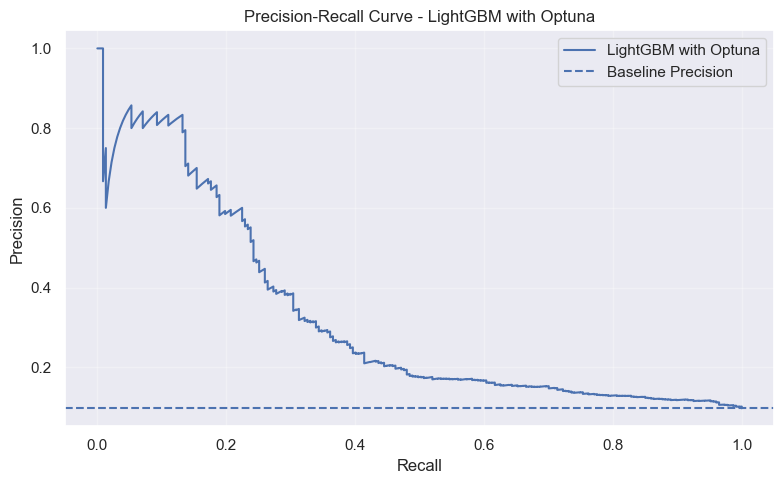


==== FINE-GRAINED THRESHOLD ANALYSIS ====
 Threshold  Precision  Recall  F1 Score
      0.05     0.1233  0.8546    0.2154
      0.06     0.1294  0.7930    0.2225
      0.07     0.1371  0.7489    0.2318
      0.08     0.1471  0.7137    0.2440
      0.09     0.1535  0.6652    0.2494
      0.10     0.1593  0.6167    0.2532
      0.11     0.1686  0.5859    0.2618
      0.12     0.1709  0.5374    0.2593
      0.13     0.1766  0.4978    0.2607
      0.14     0.1896  0.4802    0.2718
      0.15     0.2008  0.4626    0.2800
      0.16     0.2104  0.4449    0.2857
      0.17     0.2133  0.4229    0.2836
      0.18     0.2254  0.4141    0.2919
      0.19     0.2370  0.4009    0.2979
      0.20     0.2550  0.3921    0.3090
      0.21     0.2632  0.3744    0.3091
      0.22     0.2730  0.3656    0.3126
      0.23     0.2903  0.3568    0.3202
      0.24     0.3020  0.3392    0.3195
      0.25     0.3128  0.3348    0.3234
      0.26     0.3188  0.3216    0.3202
      0.27     0.3257  0.3128    0.31

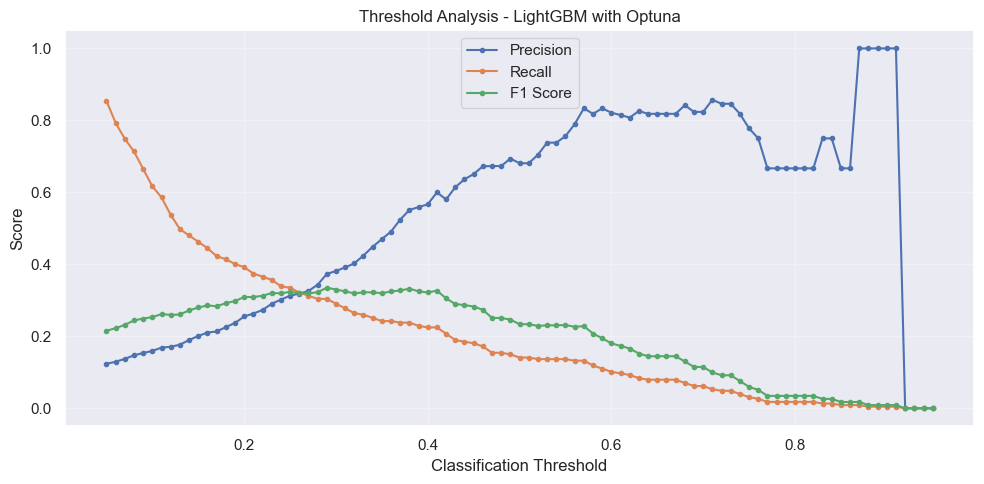


==== BEST THRESHOLD ====
Best Threshold: 0.29000000000000004
Threshold    0.290000
Precision    0.372973
Recall       0.303965
F1 Score     0.334951
Name: 24, dtype: float64

==== TRAIN METRICS ====
Accuracy    : 0.9880
Precision   : 0.8988
Recall      : 0.9879
F1 Score    : 0.9412
ROC-AUC     : 0.9991
PR-AUC      : 0.9920

==== VALIDATION METRICS ====
Accuracy    : 0.8828
Precision   : 0.3730
Recall      : 0.3040
F1 Score    : 0.3350
ROC-AUC     : 0.7030
PR-AUC      : 0.3222

==== TEST METRICS ====
Accuracy    : 0.8802
Precision   : 0.3648
Recall      : 0.3134
F1 Score    : 0.3371
ROC-AUC     : 0.6933
PR-AUC      : 0.3220


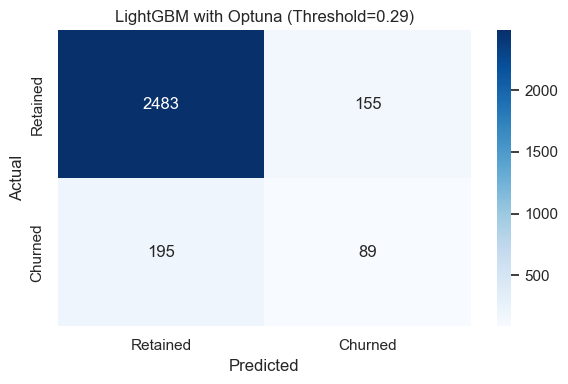


==== CLASSIFICATION REPORT ====
              precision    recall  f1-score   support

    Retained       0.93      0.94      0.93      2638
     Churned       0.36      0.31      0.34       284

    accuracy                           0.88      2922
   macro avg       0.65      0.63      0.64      2922
weighted avg       0.87      0.88      0.88      2922


==== CROSS VALIDATION TRAIN SCORES ====
train_Accuracy - Mean: 0.9891, Std: 0.0008
train_Precision - Mean: 0.9957, Std: 0.0018
train_Recall - Mean: 0.8921, Std: 0.0075
train_F1 - Mean: 0.9410, Std: 0.0043
train_ROC_AUC - Mean: 0.9998, Std: 0.0000
train_PR_AUC - Mean: 0.9980, Std: 0.0003

==== CROSS VALIDATION VALIDATION SCORES ====
test_Accuracy - Mean: 0.9072, Std: 0.0022
test_Precision - Mean: 0.6207, Std: 0.0728
test_Recall - Mean: 0.1233, Std: 0.0095
test_F1 - Mean: 0.2052, Std: 0.0131
test_ROC_AUC - Mean: 0.6873, Std: 0.0148
test_PR_AUC - Mean: 0.2863, Std: 0.0187

==== TOP 20 IMPORTANT FEATURES ====
                       Fea

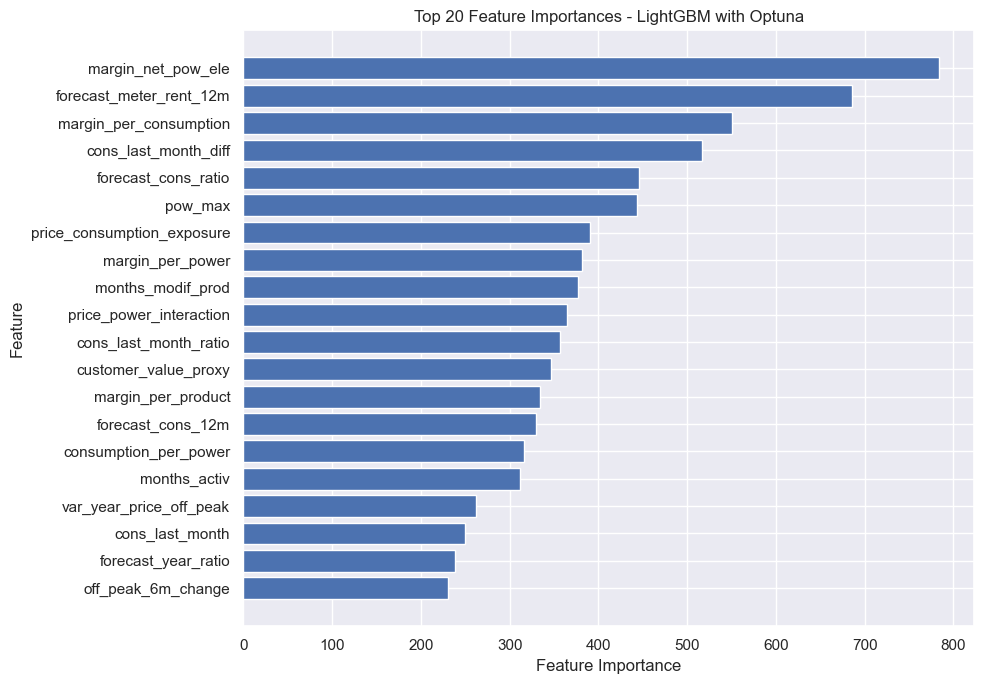

In [6]:

# ============================================================
# Exp 6 – LightGBM Classifier with Optuna Optimization
# ============================================================

# 1. IMPORT LIBRARIES
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import lightgbm as lgb
import optuna
import warnings

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_validate,
    cross_val_score
)
from sklearn.compose import make_column_transformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    precision_recall_curve,
    confusion_matrix,
    classification_report
)

warnings.filterwarnings('ignore')
optuna.logging.set_verbosity(optuna.logging.WARNING)

RANDOM_STATE = 42
sns.set_theme(style='darkgrid')

# ============================================================
# 2. SEPARATE FEATURES AND TARGET
# ============================================================

date_cols = [
    'date_activ',
    'date_end',
    'date_modif_prod',
    'date_renewal'
]

X = df.drop(columns=['id', 'churn'] + date_cols)
y = df['churn']

print("Total Missing Values:", X.isna().sum().sum())
print("\nTarget Distribution:")
print(y.value_counts())
print("\nTarget Percentage:")
print(y.value_counts(normalize=True) * 100)

# ============================================================
# 3. ORIGINAL TRAIN-TEST SPLIT
# ============================================================

X_train_original, X_test, y_train_original, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("\nOriginal Training Data:", X_train_original.shape)
print("Original Test Data:", X_test.shape)

# ============================================================
# 4. MODEL TRAINING AND THRESHOLD VALIDATION SPLIT
# ============================================================

X_model_train, X_val, y_model_train, y_val = train_test_split(
    X_train_original,
    y_train_original,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y_train_original
)

print("\nModel Training Data:", X_model_train.shape)
print("Threshold Validation Data:", X_val.shape)
print("Final Test Data:", X_test.shape)

# ============================================================
# 5. IDENTIFY FEATURE TYPES
# ============================================================

categorical_cols = X.select_dtypes(
    include=['object', 'category', 'bool']
).columns.tolist()

numerical_cols = X.select_dtypes(
    include=np.number
).columns.tolist()

print("\nCategorical Columns:", categorical_cols)
print("Numerical Columns:", len(numerical_cols))

# ============================================================
# 6. PREPROCESSING
# ============================================================

categorical_pipeline = OneHotEncoder(
    handle_unknown='ignore'
)

preprocessor = make_column_transformer(
    (categorical_pipeline, categorical_cols),
    remainder='passthrough',
    verbose_feature_names_out=False,
    n_jobs=-1
)

# ============================================================
# 7. CLASS IMBALANCE
# ============================================================

negative_count = (y_model_train == 0).sum()
positive_count = (y_model_train == 1).sum()

scale_pos_weight = negative_count / positive_count

print("\n==== CLASS IMBALANCE ====")
print("Negative Class:", negative_count)
print("Positive Class:", positive_count)
print("Scale Pos Weight:", scale_pos_weight)

# ============================================================
# 8. OPTUNA OBJECTIVE FUNCTION
# ============================================================

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

def objective(trial):
    max_depth = trial.suggest_int('max_depth', 3, 10)

    params = {
        'n_estimators': trial.suggest_int(
            'n_estimators', 200, 1000, step=100
        ),
        'learning_rate': trial.suggest_float(
            'learning_rate', 0.01, 0.10, log=True
        ),
        'max_depth': max_depth,
        'num_leaves': trial.suggest_int(
            'num_leaves', 7, min(64, 2 ** max_depth)
        ),
        'min_child_samples': trial.suggest_int(
            'min_child_samples', 10, 100, step=5
        ),
        'subsample': trial.suggest_float(
            'subsample', 0.6, 1.0
        ),
        'subsample_freq': 1,
        'colsample_bytree': trial.suggest_float(
            'colsample_bytree', 0.5, 1.0
        ),
        'reg_alpha': trial.suggest_float(
            'reg_alpha', 0.01, 20.0, log=True
        ),
        'reg_lambda': trial.suggest_float(
            'reg_lambda', 0.01, 50.0, log=True
        ),
        'min_split_gain': trial.suggest_float(
            'min_split_gain', 0.0, 5.0
        ),
        'scale_pos_weight': trial.suggest_float(
            'scale_pos_weight', 1.0, scale_pos_weight
        ),
        'objective': 'binary',
        'random_state': RANDOM_STATE,
        'n_jobs': -1,
        'verbosity': -1
    }

    model = lgb.LGBMClassifier(**params)

    pipeline = Pipeline(steps=[
        ('preprocessing', preprocessor),
        ('model', model)
    ])

    scores = cross_val_score(
        pipeline,
        X_model_train,
        y_model_train,
        scoring='average_precision',
        cv=cv,
        n_jobs=1
    )

    return scores.mean()

# ============================================================
# 9. RUN OPTUNA
# ============================================================

study = optuna.create_study(
    direction='maximize',
    sampler=optuna.samplers.TPESampler(
        seed=RANDOM_STATE
    )
)

study.optimize(
    objective,
    n_trials=40,
    show_progress_bar=True
)

# ============================================================
# 10. BEST HYPERPARAMETERS
# ============================================================

print("\n==== BEST HYPERPARAMETERS ====")
print(study.best_params)

print("\nBest CV PR-AUC:")
print(study.best_value)

# ============================================================
# 11. TOP 10 HYPERPARAMETER COMBINATIONS
# ============================================================

trials_df = study.trials_dataframe()

top_trials = trials_df.sort_values(
    by='value',
    ascending=False
).head(10)

print("\n==== TOP 10 HYPERPARAMETER COMBINATIONS ====")
print(top_trials.to_string(index=False))

# ============================================================
# 12. TRAIN FINAL LIGHTGBM MODEL
# ============================================================

best_params = study.best_params.copy()

best_params.update({
    'objective': 'binary',
    'random_state': RANDOM_STATE,
    'n_jobs': -1,
    'verbosity': -1,
    'subsample_freq': 1
})

best_lgbm_pipeline = Pipeline(steps=[
    ('preprocessing', preprocessor),
    ('model', lgb.LGBMClassifier(**best_params))
])

best_lgbm_pipeline.fit(
    X_model_train,
    y_model_train
)

print("\nFinal LightGBM Model Trained Successfully.")

# ============================================================
# 13. VALIDATION PROBABILITIES
# ============================================================

y_prob_val = best_lgbm_pipeline.predict_proba(X_val)[:, 1]

# ============================================================
# 14. PRECISION-RECALL CURVE
# ============================================================

precision, recall, pr_thresholds = precision_recall_curve(
    y_val,
    y_prob_val
)

plt.figure(figsize=(8, 5))
plt.plot(
    recall,
    precision,
    label='LightGBM with Optuna'
)
plt.axhline(
    y=y_val.mean(),
    linestyle='--',
    label='Baseline Precision'
)
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve - LightGBM with Optuna')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# ============================================================
# 15. FINE-GRAINED THRESHOLD ANALYSIS
# ============================================================

threshold_values = np.arange(0.05, 0.951, 0.01)
threshold_results = []

for threshold in threshold_values:
    y_pred = (y_prob_val >= threshold).astype(int)

    precision_value = precision_score(
        y_val, y_pred,
        zero_division=0
    )
    recall_value = recall_score(
        y_val, y_pred,
        zero_division=0
    )
    f1_value = f1_score(
        y_val, y_pred,
        zero_division=0
    )

    threshold_results.append({
        'Threshold': threshold,
        'Precision': precision_value,
        'Recall': recall_value,
        'F1 Score': f1_value
    })

fine_threshold_df = pd.DataFrame(threshold_results)

print("\n==== FINE-GRAINED THRESHOLD ANALYSIS ====")
print(fine_threshold_df.round(4).to_string(index=False))

# ============================================================
# 16. THRESHOLD PERFORMANCE VISUALIZATION
# ============================================================

plt.figure(figsize=(10, 5))

plt.plot(
    fine_threshold_df['Threshold'],
    fine_threshold_df['Precision'],
    marker='o',
    markersize=3,
    label='Precision'
)
plt.plot(
    fine_threshold_df['Threshold'],
    fine_threshold_df['Recall'],
    marker='o',
    markersize=3,
    label='Recall'
)
plt.plot(
    fine_threshold_df['Threshold'],
    fine_threshold_df['F1 Score'],
    marker='o',
    markersize=3,
    label='F1 Score'
)

plt.xlabel('Classification Threshold')
plt.ylabel('Score')
plt.title('Threshold Analysis - LightGBM with Optuna')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# ============================================================
# 17. SELECT BEST THRESHOLD
# ============================================================

best_threshold_idx = fine_threshold_df['F1 Score'].idxmax()

best_threshold = fine_threshold_df.loc[
    best_threshold_idx, 'Threshold'
]

print("\n==== BEST THRESHOLD ====")
print("Best Threshold:", best_threshold)
print(fine_threshold_df.loc[best_threshold_idx])

# ============================================================
# 18. DEFINE METRIC FUNCTION
# ============================================================

def calc_metrics(y_true, y_pred, y_prob):
    return {
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred, zero_division=0),
        'Recall': recall_score(y_true, y_pred, zero_division=0),
        'F1 Score': f1_score(y_true, y_pred, zero_division=0),
        'ROC-AUC': roc_auc_score(y_true, y_prob),
        'PR-AUC': average_precision_score(y_true, y_prob)
    }

# ============================================================
# 19. TRAINING PREDICTIONS
# ============================================================

y_prob_train = best_lgbm_pipeline.predict_proba(
    X_model_train
)[:, 1]

y_pred_train = (
    y_prob_train >= best_threshold
).astype(int)

# ============================================================
# 20. VALIDATION PREDICTIONS
# ============================================================

y_pred_val = (
    y_prob_val >= best_threshold
).astype(int)

# ============================================================
# 21. TEST PREDICTIONS
# ============================================================

y_prob_test = best_lgbm_pipeline.predict_proba(
    X_test
)[:, 1]

y_pred_test = (
    y_prob_test >= best_threshold
).astype(int)

# ============================================================
# 22. CALCULATE METRICS
# ============================================================

train_metrics = calc_metrics(
    y_model_train,
    y_pred_train,
    y_prob_train
)

validation_metrics = calc_metrics(
    y_val,
    y_pred_val,
    y_prob_val
)

test_metrics = calc_metrics(
    y_test,
    y_pred_test,
    y_prob_test
)

# ============================================================
# 23. PRINT TRAIN METRICS
# ============================================================

print("\n==== TRAIN METRICS ====")

for metric, value in train_metrics.items():
    print(f"{metric:12}: {value:.4f}")

# ============================================================
# 24. PRINT VALIDATION METRICS
# ============================================================

print("\n==== VALIDATION METRICS ====")

for metric, value in validation_metrics.items():
    print(f"{metric:12}: {value:.4f}")

# ============================================================
# 25. PRINT TEST METRICS
# ============================================================

print("\n==== TEST METRICS ====")

for metric, value in test_metrics.items():
    print(f"{metric:12}: {value:.4f}")

# ============================================================
# 26. CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(y_test, y_pred_test)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Retained', 'Churned'],
    yticklabels=['Retained', 'Churned']
)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title(
    f'LightGBM with Optuna (Threshold={best_threshold:.2f})'
)
plt.tight_layout()
plt.show()

# ============================================================
# 27. CLASSIFICATION REPORT
# ============================================================

print("\n==== CLASSIFICATION REPORT ====")

print(
    classification_report(
        y_test,
        y_pred_test,
        target_names=['Retained', 'Churned'],
        zero_division=0
    )
)

# ============================================================
# 28. CROSS VALIDATION PERFORMANCE
# ============================================================

scoring = {
    'Accuracy': 'accuracy',
    'Precision': 'precision',
    'Recall': 'recall',
    'F1': 'f1',
    'ROC_AUC': 'roc_auc',
    'PR_AUC': 'average_precision'
}

cv_results = cross_validate(
    best_lgbm_pipeline,
    X_model_train,
    y_model_train,
    scoring=scoring,
    cv=cv,
    return_train_score=True,
    n_jobs=1
)

# ============================================================
# 29. CROSS VALIDATION TRAIN SCORES
# ============================================================

print("\n==== CROSS VALIDATION TRAIN SCORES ====")

for key, value in cv_results.items():
    if key.startswith('train'):
        print(
            f"{key} - Mean: {np.mean(value):.4f}, "
            f"Std: {np.std(value):.4f}"
        )

# ============================================================
# 30. CROSS VALIDATION VALIDATION SCORES
# ============================================================

print("\n==== CROSS VALIDATION VALIDATION SCORES ====")

for key, value in cv_results.items():
    if key.startswith('test'):
        print(
            f"{key} - Mean: {np.mean(value):.4f}, "
            f"Std: {np.std(value):.4f}"
        )

# ============================================================
# 31. FEATURE IMPORTANCE
# ============================================================

lgbm_model = best_lgbm_pipeline.named_steps['model']

feature_names = (
    best_lgbm_pipeline
    .named_steps['preprocessing']
    .get_feature_names_out()
)

importances = lgbm_model.feature_importances_

feature_importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
}).sort_values(
    by='Importance',
    ascending=False
).reset_index(drop=True)

print("\n==== TOP 20 IMPORTANT FEATURES ====")
print(feature_importance_df.head(20))

# ============================================================
# 32. FEATURE IMPORTANCE VISUALIZATION
# ============================================================

top_features = feature_importance_df.head(20).sort_values(
    by='Importance',
    ascending=True
)

plt.figure(figsize=(10, 7))
plt.barh(
    top_features['Feature'],
    top_features['Importance']
)
plt.xlabel('Feature Importance')
plt.ylabel('Feature')
plt.title('Top 20 Feature Importances - LightGBM with Optuna')
plt.tight_layout()
plt.show()


**Exp 6 – LightGBM Classifier with Optuna Optimization**

**1. Model Optimization**

- Applied Optuna hyperparameter optimization to identify the best LightGBM configuration.
- Used 5-fold cross-validation with PR-AUC as the optimization metric.
- Class imbalance was considered using `scale_pos_weight`.
- Best hyperparameters:
  - `n_estimators`: 300
  - `max_depth`: 10
  - `learning_rate`: 0.0352
  - `num_leaves`: 49
  - `min_child_samples`: 25
  - `subsample`: 0.9276
  - `colsample_bytree`: 0.9807
  - `reg_alpha`: 3.0945
  - `reg_lambda`: 1.1303
  - `min_split_gain`: 0.0273
  - `scale_pos_weight`: 1.9661
- Best CV PR-AUC: **28.63%**

**Observation:**

- Optuna identified a configuration with good validation performance.
- CV PR-AUC improved compared to Exp5 Strongly Regularized XGBoost (26.38%).
- However, the training-validation performance gap remains significant.

**2. Model Performance – Test Data**

- Accuracy: **88.02%**
- Precision: **36.48%**
- Recall: **31.34%**
- F1 Score: **33.71%**
- ROC-AUC: **69.33%**
- PR-AUC: **32.20%**

**3. Threshold Analysis**

- Tested classification thresholds between 0.05 and 0.95.
- Selected threshold: **0.29**, based on the highest F1 score in the threshold analysis.
- At threshold 0.29 (threshold validation):
  - Precision: 37.30%
  - Recall: 30.40%
  - F1 Score: 33.50%
- Lower thresholds improve recall but reduce precision.
- Higher thresholds improve precision but reduce recall.

**4. Confusion Matrix (Threshold = 0.29)**

- True Negatives: 2,483
- False Positives: 155
- False Negatives: 195
- True Positives: 89

**Observation:**

- Model correctly identifies 89 churn customers out of 284.
- It misses 195 actual churn customers.
- False positives are relatively low (155).

**5. Precision-Recall Curve**

- Baseline precision is approximately 9.72%, corresponding to the churn percentage.
- Model achieves higher precision than the baseline across much of the recall range.
- PR-AUC of 32.20% is slightly lower than Exp4 XGBoost (32.15% is marginally lower?).

**Correction:** Exp6 PR-AUC (32.20%) is slightly higher than Exp4 XGBoost (32.15%) and lower than Exp2 Regularized RF (35.75%).

**6. Cross-Validation Results**

- Training PR-AUC: 99.80%
- Validation accuracy: 90.72%
- Validation precision: 62.07%
- Validation recall: 12.33%
- Validation F1: 20.52%
- Validation ROC-AUC: 68.73%
- Validation PR-AUC: 28.63%

**Observation:**

- Large training-validation performance gap indicates overfitting.
- Validation recall is very low.
- Despite Optuna optimization, the model struggles to identify churn customers consistently during cross-validation.

**7. Top 20 Important Features**

The most important features include:

- margin_net_pow_ele
- forecast_meter_rent_12m
- margin_per_consumption
- cons_last_month_diff
- forecast_cons_ratio
- pow_max
- price_consumption_exposure
- margin_per_power
- months_modif_prod
- price_power_interaction

**Observation:**

- Margin-related, consumption-related and price-related features contribute significantly.
- These important features are largely consistent with previous Random Forest experiments.

**8. Model Comparison – All Experiments**

| Metric    | Exp1-Baseline RF | Exp2-Regularized RF | Exp3-Strongly Reg. RF | Exp4-XGBoost | Exp5-Strongly Reg. XGB | Exp6-LightGBM |
| --------- | ---------------- | ------------------- | --------------------- | ------------ | ---------------------- | ------------- |
| Accuracy  | 84.02%           | 87.34%              | 84.94%                | **89.39%**   | 86.69%                 | 88.02%        |
| Precision | 26.72%           | 34.86%              | 29.26%                | **43.09%**   | 31.83%                 | 36.48%        |
| Recall    | 36.97%           | 34.86%              | **38.73%**            | 28.52%       | 32.39%                 | 31.34%        |
| F1 Score  | 31.02%           | **34.86%**          | 33.33%                | 34.32%       | 32.11%                 | 33.71%        |
| ROC-AUC   | **70.76%**       | 70.48%              | 69.45%                | 69.24%       | 69.58%                 | 69.33%        |
| PR-AUC    | 32.77%           | **35.75%**          | 31.71%                | 32.15%       | 29.42%                 | 32.20%        |
| CV PR-AUC | 25.43%           | **30.55%**          | 26.15%                | 28.42%       | 26.38%                 | 28.63%        |

**Observation:**

- LightGBM achieves better precision than Exp2 and Exp3.
- Its test PR-AUC (32.20%) is better than Exp4 and Exp5.
- However, it does not outperform Exp2 in PR-AUC or F1 Score.
- Recall remains relatively low across the boosting models.

**Final Conclusion – LightGBM Classifier with Optuna**

- Optuna optimization improved model selection and achieved a test PR-AUC of 32.20%.
- Precision improved to 36.48%, but recall remains limited at 31.34%.
- Overfitting remains a concern despite hyperparameter optimization.
- LightGBM performs competitively but does not outperform the best Random Forest model.

**Best Model So Far: Exp 2 – Regularized Random Forest**

Regularized Random Forest remains the best overall model because it achieves the highest PR-AUC (35.75%) and F1 Score (34.86%). LightGBM provides competitive precision but does not improve overall churn identification.

**Important note:** CV classification metrics use the default 0.50 threshold, while validation and test metrics use the selected 0.29 threshold. Compare classification metrics cautiously.

# Exp 7 – SVM Classifier | Validation-Based Threshold Optimization

1. Missing categorical values are imputed using the most frequent value, followed by One-Hot Encoding (OHE).
2. Missing numerical values are imputed using the median, followed by StandardScaler.
3. Class imbalance is handled using class_weight='balanced'.
4. The original training data is split into model training (80%) and validation (20%), keeping the test set untouched.
5. RandomizedSearchCV with 5-Fold Stratified CV and 25 iterations is used to tune Linear and RBF SVM hyperparameters based on PR-AUC.
6. The best model generates churn probabilities on the validation set.
7. Validation probabilities are used to select the best classification threshold based on F1 Score.
8. The best model is retrained on the complete training dataset using the selected threshold.
9. The selected threshold is applied to training, validation, and test probabilities to generate:
   0 = Retained | 1 = Churned.
10. Model performance is evaluated using classification metrics, confusion matrix, and diagnostic cross-validation.

Dataset Shape: (14606, 104)
Total Missing Values: 33864

Target Distribution:
churn
0    13187
1     1419
Name: count, dtype: int64

Target Percentage:
churn
0    90.28
1     9.72
Name: proportion, dtype: float64

Original Training Data: (11684, 104)
Original Test Data: (2922, 104)

Model Training Data: (9347, 104)
Threshold Validation Data: (2337, 104)
Final Test Data: (2922, 104)

Categorical Columns: ['channel_sales', 'has_gas', 'origin_up']
Numerical Columns: 101
Fitting 5 folds for each of 25 candidates, totalling 125 fits

==== BEST HYPERPARAMETERS ====
{'model__kernel': 'rbf', 'model__gamma': 0.001, 'model__C': 100}

Best CV PR-AUC: 0.2085

==== TOP 10 HYPERPARAMETER COMBINATIONS ====
param_model__kernel  param_model__C param_model__gamma  mean_test_score  std_test_score
                rbf           100.0              0.001           0.2085          0.0271
                rbf            10.0              scale           0.2042          0.0264
                rbf            10.0

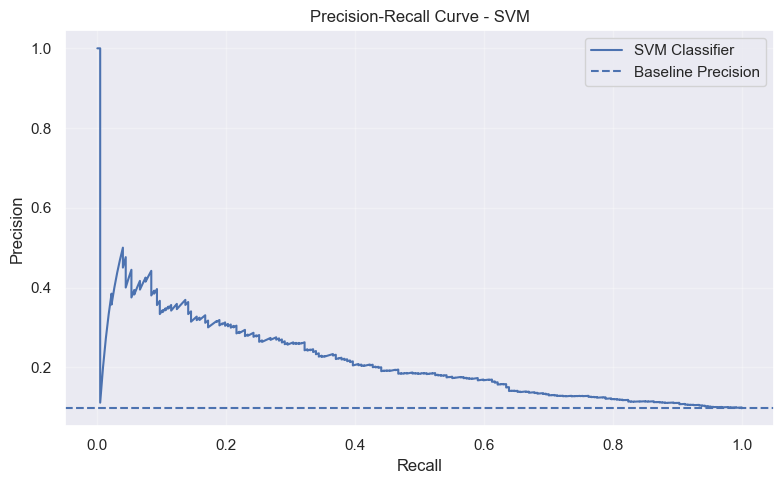


==== FINE-GRAINED THRESHOLD ANALYSIS ====
 Threshold  Precision  Recall  F1 Score
      0.05     0.1001  0.9604    0.1814
      0.06     0.1041  0.9383    0.1873
      0.07     0.1126  0.8678    0.1993
      0.08     0.1240  0.7841    0.2142
      0.09     0.1350  0.6828    0.2255
      0.10     0.1604  0.6211    0.2550
      0.11     0.1789  0.5374    0.2684
      0.12     0.1927  0.4405    0.2681
      0.13     0.2240  0.3789    0.2815
      0.14     0.2609  0.3172    0.2863
      0.15     0.2772  0.2467    0.2611
      0.16     0.3061  0.1982    0.2406
      0.17     0.3208  0.1498    0.2042
      0.18     0.3562  0.1145    0.1733
      0.19     0.3846  0.0881    0.1434
      0.20     0.3947  0.0661    0.1132
      0.21     0.4000  0.0529    0.0934
      0.22     0.4545  0.0441    0.0803
      0.23     0.5000  0.0396    0.0735
      0.24     0.3571  0.0220    0.0415
      0.25     0.3571  0.0220    0.0415
      0.26     0.3846  0.0220    0.0417
      0.27     0.1111  0.0044    0.00

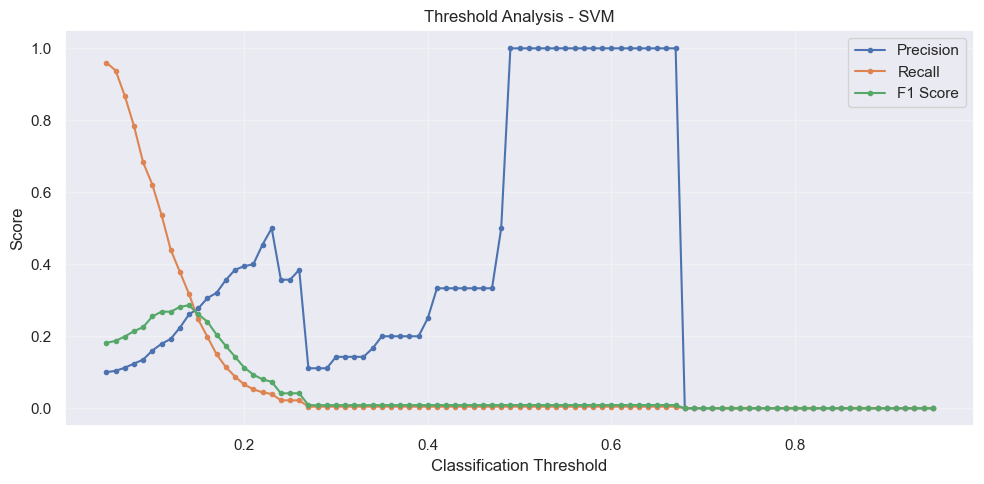


==== BEST THRESHOLD ====
Best Threshold: 0.14
Threshold    0.1400
Precision    0.2609
Recall       0.3172
F1 Score     0.2863
Name: 9, dtype: float64

==== TRAIN METRICS ====
Accuracy    : 0.8506
Precision   : 0.3241
Recall      : 0.4960
F1 Score    : 0.3921
ROC-AUC     : 0.7853
PR-AUC      : 0.3174

==== VALIDATION METRICS ====
Accuracy    : 0.8464
Precision   : 0.2609
Recall      : 0.3172
F1 Score    : 0.2863
ROC-AUC     : 0.6708
PR-AUC      : 0.2140

==== TEST METRICS ====
Accuracy    : 0.8275
Precision   : 0.2368
Recall      : 0.3486
F1 Score    : 0.2821
ROC-AUC     : 0.6645
PR-AUC      : 0.2013


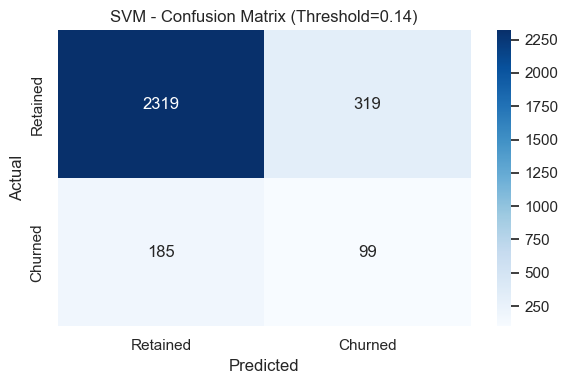


==== CLASSIFICATION REPORT ====
              precision    recall  f1-score   support

    Retained       0.93      0.88      0.90      2638
     Churned       0.24      0.35      0.28       284

    accuracy                           0.83      2922
   macro avg       0.58      0.61      0.59      2922
weighted avg       0.86      0.83      0.84      2922


==== CV TRAIN SCORES ====
train_Accuracy - Mean: 0.7326, Std: 0.0111
train_Precision - Mean: 0.2237, Std: 0.0076
train_Recall - Mean: 0.7079, Std: 0.0135
train_F1 - Mean: 0.3398, Std: 0.0087
train_ROC_AUC - Mean: 0.7972, Std: 0.0044
train_PR_AUC - Mean: 0.3287, Std: 0.0135

==== CV VALIDATION SCORES ====
test_Accuracy - Mean: 0.6967, Std: 0.0126
test_Precision - Mean: 0.1648, Std: 0.0054
test_Recall - Mean: 0.5220, Std: 0.0407
test_F1 - Mean: 0.2503, Std: 0.0101
test_ROC_AUC - Mean: 0.6544, Std: 0.0202
test_PR_AUC - Mean: 0.2085, Std: 0.0271

SVM CLASSIFIER - EXPERIMENT COMPLETED
Best Kernel: rbf
Best C: 100
Best Threshold: 0.14
Be

In [3]:

# ============================================================
# 0. IMPORT LIBRARIES
# ============================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV, cross_validate
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.base import clone
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, precision_recall_curve,
    confusion_matrix, classification_report
)
import warnings
warnings.filterwarnings('ignore')
sns.set_theme(style='darkgrid')

# ============================================================
# 1. SEPARATE FEATURES AND TARGET
# ============================================================
date_cols = ['date_activ', 'date_end', 'date_modif_prod', 'date_renewal']
X = df.drop(columns=['id', 'churn'] + date_cols, errors='ignore').copy()
y = df['churn'].copy()

print("Dataset Shape:", X.shape)
print("Total Missing Values:", X.isna().sum().sum())
print("\nTarget Distribution:")
print(y.value_counts())
print("\nTarget Percentage:")
print((y.value_counts(normalize=True) * 100).round(2))

# ============================================================
# 2. TRAIN TEST SPLIT
# ============================================================
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
print("\nOriginal Training Data:", X_train.shape)
print("Original Test Data:", X_test.shape)

# ============================================================
# 3. MODEL TRAINING AND THRESHOLD VALIDATION SPLIT
# ============================================================
X_fit, X_val, y_fit, y_val = train_test_split(
    X_train, y_train, test_size=0.20, random_state=21, stratify=y_train
)
print("\nModel Training Data:", X_fit.shape)
print("Threshold Validation Data:", X_val.shape)
print("Final Test Data:", X_test.shape)

# ============================================================
# 4. IDENTIFY CATEGORICAL AND NUMERICAL COLUMNS
# ============================================================
categorical_cols = X.select_dtypes(
    include=['object', 'category', 'bool']
).columns.tolist()
numerical_cols = X.select_dtypes(include=np.number).columns.tolist()

print("\nCategorical Columns:", categorical_cols)
print("Numerical Columns:", len(numerical_cols))

# ============================================================
# 5. PREPROCESSING PIPELINE
# ============================================================
categorical_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])
numerical_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])
preprocessor = ColumnTransformer(
    transformers=[
        ('cat', categorical_pipeline, categorical_cols),
        ('num', numerical_pipeline, numerical_cols)
    ],
    remainder='drop',
    n_jobs=1
)

# ============================================================
# 6. SVM PIPELINE
# ============================================================
svm_pipeline = Pipeline(steps=[
    ('preprocessing', preprocessor),
    ('model', SVC(
        class_weight='balanced',
        probability=True,
        random_state=42,
        cache_size=500
    ))
])

# ============================================================
# 7. STRATIFIED CROSS VALIDATION
# ============================================================
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# ============================================================
# 8. HYPERPARAMETER SEARCH SPACE
# ============================================================
param_grid = [
    {
        'model__kernel': ['linear'],
        'model__C': [0.01, 0.1, 1, 10, 100]
    },
    {
        'model__kernel': ['rbf'],
        'model__C': [0.1, 1, 10, 100],
        'model__gamma': ['scale', 'auto', 0.001, 0.01, 0.1]
    }
]

# ============================================================
# 9. RANDOMIZED SEARCH CV
# ============================================================
random_search = RandomizedSearchCV(
    estimator=svm_pipeline,
    param_distributions=param_grid,
    n_iter=25,
    scoring='average_precision',
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=2,
    refit=True,
    return_train_score=True
)

# ============================================================
# 10. FIT RANDOMIZED SEARCH
# ============================================================
random_search.fit(X_fit, y_fit)

# ============================================================
# 11. BEST HYPERPARAMETERS
# ============================================================
print("\n==== BEST HYPERPARAMETERS ====")
print(random_search.best_params_)
print("\nBest CV PR-AUC:", round(random_search.best_score_, 4))

# ============================================================
# 12. BEST SVM MODEL
# ============================================================
best_svm_pipeline = random_search.best_estimator_

# ============================================================
# 13. RANDOMIZED SEARCH RESULTS
# ============================================================
search_results_df = pd.DataFrame(random_search.cv_results_)
search_results_df = search_results_df.sort_values(
    by='mean_test_score', ascending=False
)

print("\n==== TOP 10 HYPERPARAMETER COMBINATIONS ====")
print(
    search_results_df[
        [
            'param_model__kernel',
            'param_model__C',
            'param_model__gamma',
            'mean_test_score',
            'std_test_score'
        ]
    ].head(10).round(4).to_string(index=False)
)

# ============================================================
# 14. VALIDATION PROBABILITIES
# ============================================================
y_prob_val = best_svm_pipeline.predict_proba(X_val)[:, 1]

# ============================================================
# 15. PRECISION RECALL CURVE
# ============================================================
precision, recall, pr_thresholds = precision_recall_curve(y_val, y_prob_val)

plt.figure(figsize=(8, 5))
plt.plot(recall, precision, label='SVM Classifier')
plt.axhline(
    y=y_val.mean(), linestyle='--',
    label='Baseline Precision'
)
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve - SVM')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# ============================================================
# 16. FINE-GRAINED THRESHOLD ANALYSIS
# ============================================================
threshold_values = np.arange(0.05, 0.96, 0.01)
threshold_results = []

for threshold in threshold_values:
    y_pred = (y_prob_val >= threshold).astype(int)
    threshold_results.append({
        'Threshold': threshold,
        'Precision': precision_score(y_val, y_pred, zero_division=0),
        'Recall': recall_score(y_val, y_pred, zero_division=0),
        'F1 Score': f1_score(y_val, y_pred, zero_division=0)
    })

fine_threshold_df = pd.DataFrame(threshold_results)

print("\n==== FINE-GRAINED THRESHOLD ANALYSIS ====")
print(fine_threshold_df.round(4).to_string(index=False))

# ============================================================
# 17. THRESHOLD PERFORMANCE VISUALIZATION
# ============================================================
plt.figure(figsize=(10, 5))
plt.plot(
    fine_threshold_df['Threshold'],
    fine_threshold_df['Precision'],
    marker='o', markersize=3, label='Precision'
)
plt.plot(
    fine_threshold_df['Threshold'],
    fine_threshold_df['Recall'],
    marker='o', markersize=3, label='Recall'
)
plt.plot(
    fine_threshold_df['Threshold'],
    fine_threshold_df['F1 Score'],
    marker='o', markersize=3, label='F1 Score'
)
plt.xlabel('Classification Threshold')
plt.ylabel('Score')
plt.title('Threshold Analysis - SVM')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# ============================================================
# 18. SELECT BEST THRESHOLD
# ============================================================
best_threshold = fine_threshold_df.loc[
    fine_threshold_df['F1 Score'].idxmax(), 'Threshold'
]
print("\n==== BEST THRESHOLD ====")
print("Best Threshold:", round(best_threshold, 2))
print(
    fine_threshold_df.loc[
        fine_threshold_df['F1 Score'].idxmax()
    ].round(4)
)

# ============================================================
# 19. RETRAIN BEST MODEL ON COMPLETE TRAINING DATA
# ============================================================
final_svm_pipeline = clone(best_svm_pipeline)
final_svm_pipeline.fit(X_train, y_train)

# ============================================================
# 20. TRAIN PREDICTIONS
# ============================================================
y_prob_train = final_svm_pipeline.predict_proba(X_train)[:, 1]
y_pred_train = (y_prob_train >= best_threshold).astype(int)

# ============================================================
# 21. VALIDATION PREDICTIONS
# ============================================================
# Validation predictions use the model trained on X_fit.
y_pred_val = (y_prob_val >= best_threshold).astype(int)

# ============================================================
# 22. TEST PREDICTIONS
# ============================================================
y_prob_test = final_svm_pipeline.predict_proba(X_test)[:, 1]
y_pred_test = (y_prob_test >= best_threshold).astype(int)

# ============================================================
# 23. DEFINE METRIC FUNCTION
# ============================================================
def calc_metrics(y_true, y_pred, y_prob):
    return {
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred, zero_division=0),
        'Recall': recall_score(y_true, y_pred, zero_division=0),
        'F1 Score': f1_score(y_true, y_pred, zero_division=0),
        'ROC-AUC': roc_auc_score(y_true, y_prob),
        'PR-AUC': average_precision_score(y_true, y_prob)
    }

# ============================================================
# 24. TRAIN, VALIDATION AND TEST METRICS
# ============================================================
train_metrics = calc_metrics(y_train, y_pred_train, y_prob_train)
val_metrics = calc_metrics(y_val, y_pred_val, y_prob_val)
test_metrics = calc_metrics(y_test, y_pred_test, y_prob_test)

print("\n==== TRAIN METRICS ====")
for metric, value in train_metrics.items():
    print(f"{metric:12}: {value:.4f}")

print("\n==== VALIDATION METRICS ====")
for metric, value in val_metrics.items():
    print(f"{metric:12}: {value:.4f}")

print("\n==== TEST METRICS ====")
for metric, value in test_metrics.items():
    print(f"{metric:12}: {value:.4f}")

# ============================================================
# 25. CONFUSION MATRIX
# ============================================================
cm = confusion_matrix(y_test, y_pred_test)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Retained', 'Churned'],
    yticklabels=['Retained', 'Churned']
)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title(f'SVM - Confusion Matrix (Threshold={best_threshold:.2f})')
plt.tight_layout()
plt.show()

# ============================================================
# 26. CLASSIFICATION REPORT
# ============================================================
print("\n==== CLASSIFICATION REPORT ====")
print(classification_report(
    y_test,
    y_pred_test,
    target_names=['Retained', 'Churned'],
    zero_division=0
))

# ============================================================
# 27. CROSS VALIDATION PERFORMANCE
# ============================================================
scoring = {
    'Accuracy': 'accuracy',
    'Precision': 'precision',
    'Recall': 'recall',
    'F1': 'f1',
    'ROC_AUC': 'roc_auc',
    'PR_AUC': 'average_precision'
}

# Diagnostic CV on X_fit only.
# These scores are not an independent estimate after hyperparameter tuning.
cv_results = cross_validate(
    best_svm_pipeline,
    X_fit,
    y_fit,
    scoring=scoring,
    cv=cv,
    return_train_score=True,
    n_jobs=1
)

# ============================================================
# 28. CROSS VALIDATION TRAIN SCORES
# ============================================================
print("\n==== CV TRAIN SCORES ====")
for key, value in cv_results.items():
    if key.startswith('train'):
        print(
            f"{key} - Mean: {np.mean(value):.4f}, "
            f"Std: {np.std(value):.4f}"
        )

# ============================================================
# 29. CROSS VALIDATION VALIDATION SCORES
# ============================================================
print("\n==== CV VALIDATION SCORES ====")
for key, value in cv_results.items():
    if key.startswith('test'):
        print(
            f"{key} - Mean: {np.mean(value):.4f}, "
            f"Std: {np.std(value):.4f}"
        )

# ============================================================
# 30. FINAL EXPERIMENT SUMMARY
# ============================================================
print("\n" + "=" * 50)
print("SVM CLASSIFIER - EXPERIMENT COMPLETED")
print("=" * 50)
print("Best Kernel:", random_search.best_params_['model__kernel'])
print("Best C:", random_search.best_params_['model__C'])
print("Best Threshold:", round(best_threshold, 2))
print("Best CV PR-AUC:", round(random_search.best_score_, 4))
print("Test PR-AUC:", round(test_metrics['PR-AUC'], 4))
print("Test Recall:", round(test_metrics['Recall'], 4))
print("Test Precision:", round(test_metrics['Precision'], 4))
print("Test F1 Score:", round(test_metrics['F1 Score'], 4))


**Exp 7 – SVM Classifier | Validation-Based Threshold Optimization**

**1. Model Optimization**

- Applied hyperparameter tuning using 25 parameter combinations and 5-fold cross-validation.
- Used PR-AUC as the optimization metric.
- Best hyperparameters:
  - `kernel`: rbf
  - `C`: 100
  - `gamma`: 0.001
- Best CV PR-AUC: **20.85%**

**Observation:**

- RBF kernel was selected as the best configuration.
- CV PR-AUC is lower than all previous experiments.
- SVM struggles to distinguish churn and retained customers effectively.

**2. Model Performance – Test Data**

- Accuracy: **82.75%**
- Precision: **23.68%**
- Recall: **34.86%**
- F1 Score: **28.21%**
- ROC-AUC: **66.45%**
- PR-AUC: **20.13%**

**3. Threshold Analysis**

- Tested classification thresholds between 0.05 and 0.95.
- Selected threshold: **0.14**, based on the highest F1 score in the threshold analysis.
- At threshold 0.14 (threshold validation):
  - Precision: 26.09%
  - Recall: 31.72%
  - F1 Score: 28.63%
- Lower thresholds improve recall but reduce precision.
- Higher thresholds improve precision but reduce recall.

**4. Confusion Matrix (Threshold = 0.14)**

- True Negatives: 2,319
- False Positives: 319
- False Negatives: 185
- True Positives: 99

**Observation:**

- Model correctly identifies 99 churn customers out of 284.
- It misses 185 actual churn customers.
- False positives are relatively high (319).

**5. Precision-Recall Curve**

- Baseline precision is approximately 9.72%, corresponding to the churn percentage.
- Model achieves higher precision than the baseline across much of the recall range.
- PR-AUC of 20.13% is considerably lower than previous experiments.

**6. Cross-Validation Results**

- Training PR-AUC: 32.87%
- Validation accuracy: 69.67%
- Validation precision: 16.48%
- Validation recall: 52.20%
- Validation F1: 25.03%
- Validation ROC-AUC: 65.44%
- Validation PR-AUC: 20.85%

**Observation:**

- Training and validation PR-AUC are relatively close.
- However, overall validation performance is weak.
- Validation recall is better than several previous models, but precision is very low.
- SVM identifies more potential churn customers at the cost of more false positives.

**7. Model Comparison – All Experiments**

| Metric    | Exp1-Baseline RF | Exp2-Regularized RF | Exp3-Strongly Reg. RF | Exp4-XGBoost | Exp5-Strongly Reg. XGB | Exp6-LightGBM | Exp7-SVM |
| --------- | ---------------- | ------------------- | --------------------- | ------------ | ---------------------- | ------------- | -------- |
| Accuracy  | 84.02%           | 87.34%              | 84.94%                | **89.39%**   | 86.69%                 | 88.02%        | 82.75%   |
| Precision | 26.72%           | 34.86%              | 29.26%                | **43.09%**   | 31.83%                 | 36.48%        | 23.68%   |
| Recall    | 36.97%           | 34.86%              | **38.73%**            | 28.52%       | 32.39%                 | 31.34%        | 34.86%   |
| F1 Score  | 31.02%           | **34.86%**          | 33.33%                | 34.32%       | 32.11%                 | 33.71%        | 28.21%   |
| ROC-AUC   | **70.76%**       | 70.48%              | 69.45%                | 69.24%       | 69.58%                 | 69.33%        | 66.45%   |
| PR-AUC    | 32.77%           | **35.75%**          | 31.71%                | 32.15%       | 29.42%                 | 32.20%        | 20.13%   |
| CV PR-AUC | 25.43%           | **30.55%**          | 26.15%                | 28.42%       | 26.38%                 | 28.63%        | 20.85%   |

**Observation:**

- SVM achieves the lowest test PR-AUC (20.13%) among all experiments.
- Its precision (23.68%) and F1 Score (28.21%) are also the lowest.
- Recall (34.86%) is better than Exp4, Exp5 and Exp6.
- SVM does not provide a good overall balance between precision and recall.

**Final Conclusion – SVM Classifier**

- SVM achieves a test PR-AUC of only 20.13%.
- Although recall is 34.86%, precision is relatively low at 23.68%.
- Cross-validation and test PR-AUC are also lower than previous experiments.
- SVM does not improve overall churn prediction performance.

**Best Model So Far: Exp 2 – Regularized Random Forest**

Regularized Random Forest remains the best overall model because it achieves the highest PR-AUC (35.75%) and F1 Score (34.86%). It provides a better balance between identifying churn customers and controlling false positives.

SVM is currently the weakest model based on PR-AUC and F1 Score.

**Important note:** CV classification metrics use the default 0.50 threshold, while validation and test metrics use the selected 0.14 threshold. Compare classification metrics cautiously.

# Note: Final Model Selection and Further Experiments

Based on the initial experiments, Exp2 (Regularized Random Forest) and Exp4 (XGBoost) were selected for further investigation.

From this point onward, the experiments will focus on improving these two models through:
- Outlier detection and treatment.
- Log transformations to reduce feature skewness.
- Further model optimization and performance evaluation.

The objective is to improve churn detection, reduce overfitting, and achieve better generalization on unseen data.

# Exp 8 – Advanced Model Optimization – Random Forest & XGBoost

## Exp 8(2) – Hyperparameter-Tuned Random Forest | Validation-Based Threshold Optimization

1. Separate features and target, excluding customer ID and raw date columns.
2. Split the data into 80% training and 20% testing using stratification.
3. Further split the training data into model training (80%) and validation (20%), keeping the test set untouched.
4. Missing categorical values are replaced with a constant value and encoded using One-Hot Encoding (OHE).
5. Missing numerical values are imputed using the median.
6. Class imbalance is handled using class_weight='balanced'.
7. RandomizedSearchCV with 25 iterations and 5-Fold Stratified CV is used to tune Random Forest hyperparameters based on PR-AUC.
8. Regularization is applied using parameters such as max_depth, min_samples_split, and min_samples_leaf.
9. The best model generates churn probabilities on the validation set.
10. A fine-grained threshold analysis (0.05–0.95) is performed to select the threshold with the highest F1 Score.
11. The selected threshold is applied to training, validation, and test probabilities to generate:
    0 = Retained | 1 = Churned.
12. Model performance is evaluated using Accuracy, Precision, Recall, F1 Score, ROC-AUC, PR-AUC, confusion matrix, and classification report.
13. Cross-validation performance is evaluated, and feature importance is analysed to identify the most influential features.

Exp 8(2) as took the best-performing Random Forest model from Exp2 and carried it forward as a new experiment under Exp8

Total Missing Values: 33864

==== TARGET DISTRIBUTION ====
churn
0    13187
1     1419
Name: count, dtype: int64

==== TARGET PERCENTAGE ====
churn
0    90.28
1     9.72
Name: proportion, dtype: float64

Original Training Data: (11684, 104)
Original Test Data: (2922, 104)

Model Training Data: (9347, 104)
Threshold Validation Data: (2337, 104)

Categorical Columns: ['channel_sales', 'has_gas', 'origin_up']
Numerical Columns: 101
Fitting 5 folds for each of 25 candidates, totalling 125 fits

==== BEST HYPERPARAMETERS ====
{'model__n_estimators': 500, 'model__min_samples_split': 5, 'model__min_samples_leaf': 5, 'model__max_features': 0.5, 'model__max_depth': None}

Best CV PR-AUC:
0.2735256167859131

==== TOP 10 HYPERPARAMETER COMBINATIONS ====
 param_model__n_estimators param_model__max_depth  param_model__min_samples_split  param_model__min_samples_leaf param_model__max_features  mean_train_score  mean_test_score  std_test_score
                       500                   None        

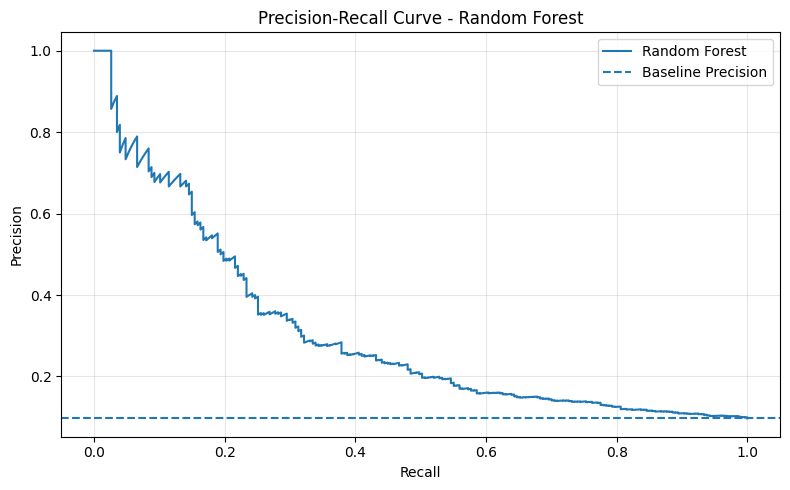


==== FINE-GRAINED THRESHOLD ANALYSIS ====
 Threshold  Precision  Recall  F1 Score
      0.05     0.1020  0.9736    0.1847
      0.06     0.1028  0.9471    0.1855
      0.07     0.1059  0.9339    0.1903
      0.08     0.1094  0.9075    0.1953
      0.09     0.1135  0.8767    0.2010
      0.10     0.1176  0.8458    0.2066
      0.11     0.1205  0.8062    0.2096
      0.12     0.1266  0.7930    0.2183
      0.13     0.1337  0.7753    0.2281
      0.14     0.1385  0.7445    0.2336
      0.15     0.1402  0.7048    0.2339
      0.16     0.1485  0.6828    0.2439
      0.17     0.1510  0.6432    0.2446
      0.18     0.1597  0.6211    0.2541
      0.19     0.1650  0.5859    0.2575
      0.20     0.1730  0.5595    0.2643
      0.21     0.1876  0.5463    0.2793
      0.22     0.1983  0.5286    0.2885
      0.23     0.2039  0.5022    0.2901
      0.24     0.2157  0.4846    0.2985
      0.25     0.2304  0.4670    0.3086
      0.26     0.2353  0.4405    0.3067
      0.27     0.2513  0.4317    0.31

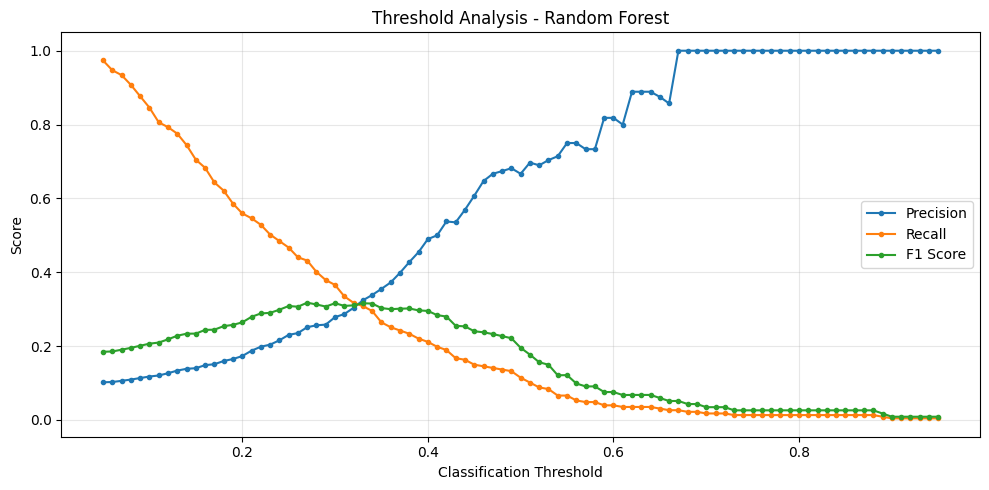


==== BEST THRESHOLD ====
Best Threshold: 0.27
Threshold    0.270000
Precision    0.251282
Recall       0.431718
F1 Score     0.317666
Name: 22, dtype: float64

==== TRAIN METRICS ====
Accuracy    : 0.9617
Precision   : 0.7172
Recall      : 1.0000
F1 Score    : 0.8353
ROC-AUC     : 0.9999
PR-AUC      : 0.9993

==== VALIDATION METRICS ====
Accuracy    : 0.8199
Precision   : 0.2513
Recall      : 0.4317
F1 Score    : 0.3177
ROC-AUC     : 0.6940
PR-AUC      : 0.3059

==== TEST METRICS ====
Accuracy    : 0.8207
Precision   : 0.2571
Recall      : 0.4472
F1 Score    : 0.3265
ROC-AUC     : 0.6998
PR-AUC      : 0.3426


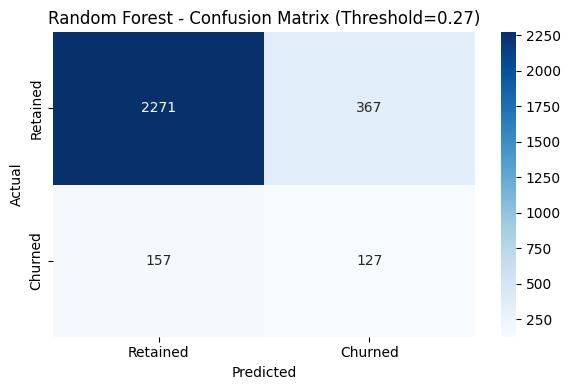


==== CLASSIFICATION REPORT ====
              precision    recall  f1-score   support

    Retained       0.94      0.86      0.90      2638
     Churned       0.26      0.45      0.33       284

    accuracy                           0.82      2922
   macro avg       0.60      0.65      0.61      2922
weighted avg       0.87      0.82      0.84      2922


==== CROSS VALIDATION TRAIN SCORES ====
train_Accuracy - Mean: 0.9992, Std: 0.0004
train_Precision - Mean: 0.9921, Std: 0.0039
train_Recall - Mean: 1.0000, Std: 0.0000
train_F1 - Mean: 0.9960, Std: 0.0020
train_ROC_AUC - Mean: 0.9999, Std: 0.0000
train_PR_AUC - Mean: 0.9993, Std: 0.0006

==== CROSS VALIDATION VALIDATION SCORES ====
test_Accuracy - Mean: 0.9060, Std: 0.0027
test_Precision - Mean: 0.6025, Std: 0.0800
test_Recall - Mean: 0.0903, Std: 0.0214
test_F1 - Mean: 0.1567, Std: 0.0346
test_ROC_AUC - Mean: 0.6892, Std: 0.0258
test_PR_AUC - Mean: 0.2735, Std: 0.0285

==== TOP 20 IMPORTANT FEATURES ====
                   Feature

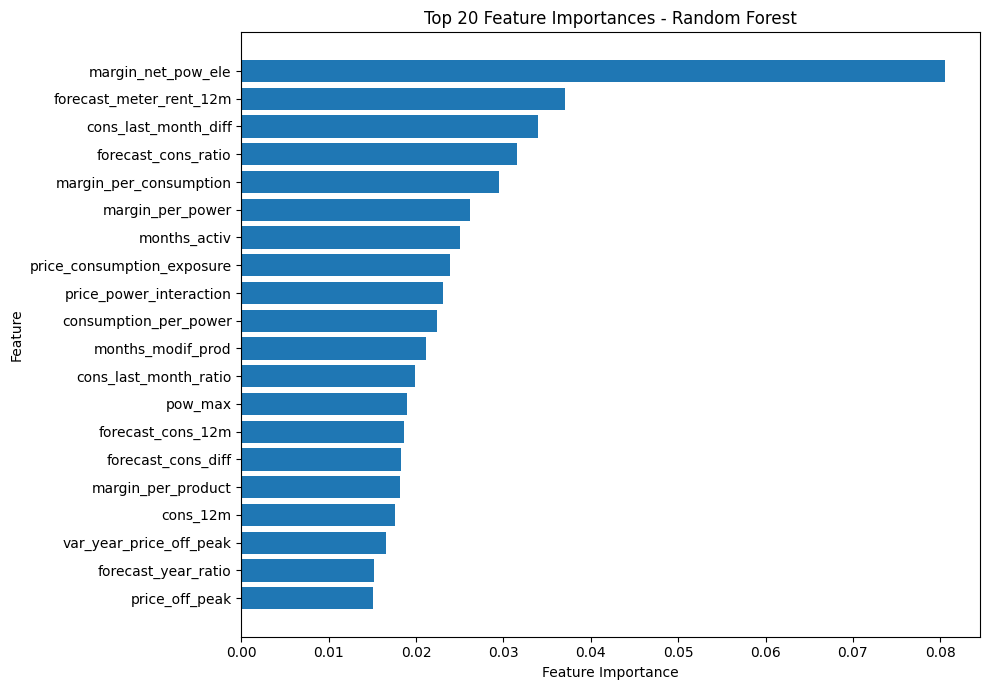

In [4]:

# Exp 8(2) – Hyperparameter-Tuned Model | Regularized Random Forest

# ============================================================
# 0. IMPORT LIBRARIES
# ============================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    RandomizedSearchCV,
    cross_validate
)
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    precision_recall_curve,
    confusion_matrix,
    classification_report
)

# ============================================================
# 1. SEPARATE FEATURES AND TARGET
# ============================================================
date_cols = [
    'date_activ',
    'date_end',
    'date_modif_prod',
    'date_renewal'
]

X = df.drop(columns=['id', 'churn'] + date_cols, errors='ignore').copy()
y = df['churn'].copy()

print("Total Missing Values:", X.isna().sum().sum())
print("\n==== TARGET DISTRIBUTION ====")
print(y.value_counts())
print("\n==== TARGET PERCENTAGE ====")
print((y.value_counts(normalize=True) * 100).round(2))

# ============================================================
# 2. ORIGINAL TRAIN TEST SPLIT
# ============================================================
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nOriginal Training Data:", X_train.shape)
print("Original Test Data:", X_test.shape)

# ============================================================
# 3. INTERNAL TRAIN VALIDATION SPLIT
# ============================================================
# Test data remains untouched.
# Validation data is used for threshold selection.

X_fit, X_val, y_fit, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=21,
    stratify=y_train
)

print("\nModel Training Data:", X_fit.shape)
print("Threshold Validation Data:", X_val.shape)

# ============================================================
# 4. IDENTIFY CATEGORICAL AND NUMERICAL COLUMNS
# ============================================================
categorical_cols = X.select_dtypes(
    include=['object', 'category', 'bool']
).columns.tolist()

numerical_cols = X.select_dtypes(
    include=np.number
).columns.tolist()

print("\nCategorical Columns:", categorical_cols)
print("Numerical Columns:", len(numerical_cols))

# ============================================================
# 5. PREPROCESSING PIPELINE
# ============================================================
categorical_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(
        strategy='constant',
        fill_value='__MISSING__'
    )),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

numerical_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median'))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('categorical', categorical_pipeline, categorical_cols),
        ('numerical', numerical_pipeline, numerical_cols)
    ],
    remainder='drop',
    verbose_feature_names_out=False
)

# ============================================================
# 6. RANDOM FOREST PIPELINE
# ============================================================
rf_pipeline = Pipeline(steps=[
    ('preprocessing', preprocessor),
    ('model', RandomForestClassifier(
        class_weight='balanced',
        random_state=42,
        n_jobs=1
    ))
])

# ============================================================
# 7. STRATIFIED CROSS VALIDATION
# ============================================================
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# ============================================================
# 8. HYPERPARAMETER SEARCH SPACE
# ============================================================
param_grid = {
    'model__n_estimators': [200, 300, 500],
    'model__max_depth': [5, 10, 15, 20, None],
    'model__min_samples_split': [5, 10, 20, 30],
    'model__min_samples_leaf': [2, 5, 10, 15],
    'model__max_features': ['sqrt', 'log2', 0.5]
}

# ============================================================
# 9. RANDOMIZED SEARCH CV
# ============================================================
random_search = RandomizedSearchCV(
    estimator=rf_pipeline,
    param_distributions=param_grid,
    n_iter=25,
    scoring='average_precision',
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=2,
    refit=True,
    return_train_score=True
)

# ============================================================
# 10. FIT RANDOMIZED SEARCH
# ============================================================
random_search.fit(X_fit, y_fit)

# ============================================================
# 11. BEST HYPERPARAMETERS
# ============================================================
print("\n==== BEST HYPERPARAMETERS ====")
print(random_search.best_params_)

print("\nBest CV PR-AUC:")
print(random_search.best_score_)

# ============================================================
# 12. BEST RANDOM FOREST MODEL
# ============================================================
best_rf_pipeline = random_search.best_estimator_

# ============================================================
# 13. RANDOMIZED SEARCH RESULTS
# ============================================================
search_results_df = pd.DataFrame(random_search.cv_results_)
search_results_df = search_results_df.sort_values(
    by='mean_test_score',
    ascending=False
)

print("\n==== TOP 10 HYPERPARAMETER COMBINATIONS ====")
print(
    search_results_df[[
        'param_model__n_estimators',
        'param_model__max_depth',
        'param_model__min_samples_split',
        'param_model__min_samples_leaf',
        'param_model__max_features',
        'mean_train_score',
        'mean_test_score',
        'std_test_score'
    ]].head(10).round(4).to_string(index=False)
)

# ============================================================
# 14. VALIDATION PROBABILITIES
# ============================================================
y_prob_val = best_rf_pipeline.predict_proba(X_val)[:, 1]

# ============================================================
# 15. PRECISION RECALL CURVE
# ============================================================
precision, recall, pr_thresholds = precision_recall_curve(
    y_val,
    y_prob_val
)

plt.figure(figsize=(8, 5))
plt.plot(
    recall,
    precision,
    label='Random Forest'
)
plt.axhline(
    y=y_val.mean(),
    linestyle='--',
    label='Baseline Precision'
)
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve - Random Forest')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# ============================================================
# 16. FINE-GRAINED THRESHOLD ANALYSIS
# ============================================================
threshold_values = np.arange(0.05, 0.951, 0.01)
threshold_results = []

for threshold in threshold_values:
    y_pred = (y_prob_val >= threshold).astype(int)

    threshold_results.append({
        'Threshold': threshold,
        'Precision': precision_score(
            y_val, y_pred, zero_division=0
        ),
        'Recall': recall_score(
            y_val, y_pred, zero_division=0
        ),
        'F1 Score': f1_score(
            y_val, y_pred, zero_division=0
        )
    })

fine_threshold_df = pd.DataFrame(threshold_results)

print("\n==== FINE-GRAINED THRESHOLD ANALYSIS ====")
print(fine_threshold_df.round(4).to_string(index=False))

# ============================================================
# 17. THRESHOLD PERFORMANCE VISUALIZATION
# ============================================================
plt.figure(figsize=(10, 5))
plt.plot(
    fine_threshold_df['Threshold'],
    fine_threshold_df['Precision'],
    marker='o',
    markersize=3,
    label='Precision'
)
plt.plot(
    fine_threshold_df['Threshold'],
    fine_threshold_df['Recall'],
    marker='o',
    markersize=3,
    label='Recall'
)
plt.plot(
    fine_threshold_df['Threshold'],
    fine_threshold_df['F1 Score'],
    marker='o',
    markersize=3,
    label='F1 Score'
)
plt.xlabel('Classification Threshold')
plt.ylabel('Score')
plt.title('Threshold Analysis - Random Forest')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# ============================================================
# 18. SELECT BEST THRESHOLD
# ============================================================
best_threshold_idx = fine_threshold_df['F1 Score'].idxmax()
best_threshold = fine_threshold_df.loc[
    best_threshold_idx, 'Threshold'
]

print("\n==== BEST THRESHOLD ====")
print("Best Threshold:", best_threshold)
print(fine_threshold_df.loc[best_threshold_idx])

# ============================================================
# 19. DEFINE METRIC FUNCTION
# ============================================================
def calc_metrics(y_true, y_pred, y_prob):
    return {
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision': precision_score(
            y_true, y_pred, zero_division=0
        ),
        'Recall': recall_score(
            y_true, y_pred, zero_division=0
        ),
        'F1 Score': f1_score(
            y_true, y_pred, zero_division=0
        ),
        'ROC-AUC': roc_auc_score(y_true, y_prob),
        'PR-AUC': average_precision_score(y_true, y_prob)
    }

# ============================================================
# 20. TRAINING PREDICTIONS
# ============================================================
y_prob_train = best_rf_pipeline.predict_proba(X_fit)[:, 1]
y_pred_train = (y_prob_train >= best_threshold).astype(int)

# ============================================================
# 21. VALIDATION PREDICTIONS
# ============================================================
y_pred_val = (y_prob_val >= best_threshold).astype(int)

# ============================================================
# 22. TEST PREDICTIONS
# ============================================================
y_prob_test = best_rf_pipeline.predict_proba(X_test)[:, 1]
y_pred_test = (y_prob_test >= best_threshold).astype(int)

# ============================================================
# 23. CALCULATE METRICS
# ============================================================
train_metrics = calc_metrics(
    y_fit,
    y_pred_train,
    y_prob_train
)

validation_metrics = calc_metrics(
    y_val,
    y_pred_val,
    y_prob_val
)

test_metrics = calc_metrics(
    y_test,
    y_pred_test,
    y_prob_test
)

# ============================================================
# 24. PRINT TRAIN METRICS
# ============================================================
print("\n==== TRAIN METRICS ====")
for metric, value in train_metrics.items():
    print(f"{metric:12}: {value:.4f}")

# ============================================================
# 25. PRINT VALIDATION METRICS
# ============================================================
print("\n==== VALIDATION METRICS ====")
for metric, value in validation_metrics.items():
    print(f"{metric:12}: {value:.4f}")

# ============================================================
# 26. PRINT TEST METRICS
# ============================================================
print("\n==== TEST METRICS ====")
for metric, value in test_metrics.items():
    print(f"{metric:12}: {value:.4f}")

# ============================================================
# 27. CONFUSION MATRIX
# ============================================================
cm = confusion_matrix(y_test, y_pred_test)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Retained', 'Churned'],
    yticklabels=['Retained', 'Churned']
)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title(
    f'Random Forest - Confusion Matrix '
    f'(Threshold={best_threshold:.2f})'
)
plt.tight_layout()
plt.show()

# ============================================================
# 28. CLASSIFICATION REPORT
# ============================================================
print("\n==== CLASSIFICATION REPORT ====")
print(
    classification_report(
        y_test,
        y_pred_test,
        target_names=['Retained', 'Churned'],
        zero_division=0
    )
)

# ============================================================
# 29. CROSS VALIDATION PERFORMANCE
# ============================================================
scoring = {
    'Accuracy': 'accuracy',
    'Precision': 'precision',
    'Recall': 'recall',
    'F1': 'f1',
    'ROC_AUC': 'roc_auc',
    'PR_AUC': 'average_precision'
}

cv_results = cross_validate(
    best_rf_pipeline,
    X_fit,
    y_fit,
    scoring=scoring,
    cv=cv,
    return_train_score=True,
    n_jobs=1
)

# ============================================================
# 30. CROSS VALIDATION TRAIN SCORES
# ============================================================
print("\n==== CROSS VALIDATION TRAIN SCORES ====")
for key, value in cv_results.items():
    if key.startswith('train'):
        print(
            f"{key} - Mean: {np.mean(value):.4f}, "
            f"Std: {np.std(value):.4f}"
        )

# ============================================================
# 31. CROSS VALIDATION VALIDATION SCORES
# ============================================================
print("\n==== CROSS VALIDATION VALIDATION SCORES ====")
for key, value in cv_results.items():
    if key.startswith('test'):
        print(
            f"{key} - Mean: {np.mean(value):.4f}, "
            f"Std: {np.std(value):.4f}"
        )

# ============================================================
# 32. FEATURE IMPORTANCE
# ============================================================
rf_model = best_rf_pipeline.named_steps['model']

feature_names = (
    best_rf_pipeline
    .named_steps['preprocessing']
    .get_feature_names_out()
)

importances = rf_model.feature_importances_

feature_importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
}).sort_values(
    by='Importance',
    ascending=False
).reset_index(drop=True)

print("\n==== TOP 20 IMPORTANT FEATURES ====")
print(feature_importance_df.head(20).to_string(index=False))

# ============================================================
# 33. FEATURE IMPORTANCE VISUALIZATION
# ============================================================
top_features = feature_importance_df.head(20).sort_values(
    by='Importance',
    ascending=True
)

plt.figure(figsize=(10, 7))
plt.barh(
    top_features['Feature'],
    top_features['Importance']
)
plt.xlabel('Feature Importance')
plt.ylabel('Feature')
plt.title('Top 20 Feature Importances - Random Forest')
plt.tight_layout()
plt.show()


**Exp 8(2) – Hyperparameter-Tuned Random Forest | Validation-Based Threshold Optimization**

**1. Model Optimization**

- Applied hyperparameter tuning using 25 parameter combinations and 5-fold cross-validation.
- Used PR-AUC as the optimization metric.
- Best hyperparameters:
  - `n_estimators`: 500
  - `min_samples_split`: 5
  - `min_samples_leaf`: 5
  - `max_features`: 0.5
  - `max_depth`: None
- Best CV PR-AUC: **27.35%**

**Observation:**

- Carried forward the best-performing Random Forest configuration from Exp2.
- Used a separate 64:16:20 fit-validation-test split.
- CV PR-AUC is lower than Exp2 (30.55%).
- Training performance remains extremely high, indicating overfitting.

**2. Model Performance – Test Data**

- Accuracy: **82.07%**
- Precision: **25.71%**
- Recall: **44.72%**
- F1 Score: **32.65%**
- ROC-AUC: **69.98%**
- PR-AUC: **34.26%**

**3. Threshold Analysis**

- Tested classification thresholds between 0.05 and 0.95.
- Selected threshold: **0.27**, based on the highest F1 score in the threshold analysis.
- At threshold 0.27 (threshold validation):
  - Precision: 25.13%
  - Recall: 43.17%
  - F1 Score: 31.77%
- Lower thresholds improve recall but reduce precision.
- Higher thresholds improve precision but reduce recall.

**4. Confusion Matrix (Threshold = 0.27)**

- True Negatives: 2,271
- False Positives: 367
- False Negatives: 157
- True Positives: 127

**Observation:**

- Model correctly identifies 127 churn customers out of 284.
- It misses 157 actual churn customers.
- Achieves the highest recall among all previous experiments.
- However, false positives are relatively high (367).

**5. Precision-Recall Curve**

- Baseline precision is approximately 9.72%, corresponding to the churn percentage.
- Model achieves higher precision than the baseline across much of the recall range.
- PR-AUC of 34.26% is the second-highest among all experiments, after Exp2 (35.75%).

**6. Cross-Validation Results**

- Training PR-AUC: 99.93%
- Validation accuracy: 90.60%
- Validation precision: 60.25%
- Validation recall: 9.03%
- Validation F1: 15.67%
- Validation ROC-AUC: 68.92%
- Validation PR-AUC: 27.35%

**Observation:**

- Significant training-validation performance gap indicates severe overfitting.
- Validation recall is extremely low at the default 0.50 threshold.
- Despite overfitting, test PR-AUC is relatively strong.

**7. Top 20 Important Features**

The most important features include:

- margin_net_pow_ele
- forecast_meter_rent_12m
- cons_last_month_diff
- forecast_cons_ratio
- margin_per_consumption
- margin_per_power
- months_activ
- price_consumption_exposure
- price_power_interaction
- consumption_per_power

**Observation:**

- Margin-related, consumption-related and price-related features remain important.
- `margin_net_pow_ele` continues to be the most important feature.
- Feature importance patterns are consistent with earlier Random Forest experiments.

**8. Model Comparison – All Experiments**

| Metric    | Exp1-Baseline RF | Exp2-Regularized RF | Exp3-Strongly Reg. RF | Exp4-XGBoost | Exp5-Strongly Reg. XGB | Exp6-LightGBM | Exp7-SVM | Exp8(2)-RF |
| --------- | ---------------- | ------------------- | --------------------- | ------------ | ---------------------- | ------------- | -------- | ---------- |
| Accuracy  | 84.02%           | 87.34%              | 84.94%                | **89.39%**   | 86.69%                 | 88.02%        | 82.75%   | 82.07%     |
| Precision | 26.72%           | 34.86%              | 29.26%                | **43.09%**   | 31.83%                 | 36.48%        | 23.68%   | 25.71%     |
| Recall    | 36.97%           | 34.86%              | 38.73%                | 28.52%       | 32.39%                 | 31.34%        | 34.86%   | **44.72%** |
| F1 Score  | 31.02%           | **34.86%**          | 33.33%                | 34.32%       | 32.11%                 | 33.71%        | 28.21%   | 32.65%     |
| ROC-AUC   | **70.76%**       | 70.48%              | 69.45%                | 69.24%       | 69.58%                 | 69.33%        | 66.45%   | 69.98%     |
| PR-AUC    | 32.77%           | **35.75%**          | 31.71%                | 32.15%       | 29.42%                 | 32.20%        | 20.13%   | 34.26%     |
| CV PR-AUC | 25.43%           | **30.55%**          | 26.15%                | 28.42%       | 26.38%                 | 28.63%        | 20.85%   | 27.35%     |

**Observation:**

- Exp8(2) achieves the highest recall (44.72%) among all experiments.
- Its PR-AUC (34.26%) is the second-highest, after Exp2 (35.75%).
- However, precision is relatively low at 25.71%.
- Exp2 maintains a better overall balance between precision and recall.
- Exp8(2) identifies more churn customers but generates more false positives.
- Exp4 achieves the highest accuracy and precision.

**Final Conclusion – Exp 8(2) Random Forest**

- Achieves a test PR-AUC of 34.26%, close to the best model.
- Achieves the highest recall (44.72%) among all experiments.
- Correctly identifies 127 churn customers out of 284.
- However, precision is only 25.71%, with 367 false positives.
- Significant overfitting remains a concern.
- The validation-based threshold optimization provides a separate evaluation workflow from the original Exp2 experiment.

**Best Model So Far: Exp 2 – Regularized Random Forest**

Exp2 remains the best overall model because it achieves the highest PR-AUC (35.75%) and F1 Score (34.86%), with better precision.

However, Exp8(2) is a strong alternative when identifying more churn customers is the priority, even at the cost of additional false positives.

**Important note:** CV classification metrics use the default 0.50 threshold, while validation and test metrics use the selected 0.27 threshold. Compare classification metrics cautiously.

**One important clarification:** Exp8(2) uses a separate 64:16:20 split, so its test results should be treated as a separate evaluation rather than a perfectly controlled comparison with experiments using a different split. Also, the reported threshold-validation metrics (25.13% precision, 43.17% recall and 31.77% F1) differ from the final test metrics.

## Exp 8(4) – Hyperparameter-Tuned XGBoost | Validation-Based Threshold Optimization

1. Separate features and target, excluding customer ID and raw date columns.
2. Split the data into 80% training and 20% testing using stratification.
3. Further split the training data into model training (80%) and validation (20%), keeping the test set untouched.
4. Missing categorical values are replaced with a constant value and encoded using One-Hot Encoding (OHE). Numerical missing values are handled natively by XGBoost.
5. Class imbalance is handled using scale_pos_weight, calculated from the model training data.
6. RandomizedSearchCV with 30 iterations and 5-Fold Stratified CV is used to tune XGBoost hyperparameters based on PR-AUC.
7. Regularization is controlled using max_depth, min_child_weight, gamma, reg_alpha, and reg_lambda, along with subsampling and column sampling.
8. The best model generates churn probabilities on the validation set.
9. A fine-grained threshold analysis (0.05–0.95) is performed to select the threshold with the highest F1 Score.
10. The selected threshold is applied to training, validation, and test probabilities to generate:
    0 = Retained | 1 = Churned.
11. Model performance is evaluated using Accuracy, Precision, Recall, F1 Score, ROC-AUC, PR-AUC, confusion matrix, and classification report.
12. Diagnostic cross-validation is performed, and feature importance is analysed to identify the most influential features.

Exp 8(4) as took the best-performing XGBoost Classifier model from Exp4 and carried it forward as a new experiment under Exp8

Total Missing Values: 33864

==== TARGET DISTRIBUTION ====
churn
0    13187
1     1419
Name: count, dtype: int64

==== TARGET PERCENTAGE ====
churn
0    90.28
1     9.72
Name: proportion, dtype: float64

Original Training Data: (11684, 104)
Original Test Data: (2922, 104)

Model Training Data: (9347, 104)
Threshold Validation Data: (2337, 104)
Final Test Data: (2922, 104)

Categorical Columns: ['channel_sales', 'has_gas', 'origin_up']
Numerical Columns: 101

==== CLASS IMBALANCE ====
Negative Class: 8439
Positive Class: 908
Scale Pos Weight: 9.294052863436123
Fitting 5 folds for each of 30 candidates, totalling 150 fits

==== BEST HYPERPARAMETERS ====
{'model__subsample': 0.8, 'model__scale_pos_weight': 1, 'model__reg_lambda': 1, 'model__reg_alpha': 0, 'model__n_estimators': 700, 'model__min_child_weight': 1, 'model__max_depth': 4, 'model__learning_rate': 0.05, 'model__gamma': 0.1, 'model__colsample_bytree': 0.8}

Best CV PR-AUC:
0.2841662008302841

==== TOP 10 HYPERPARAMETER COMBINATI

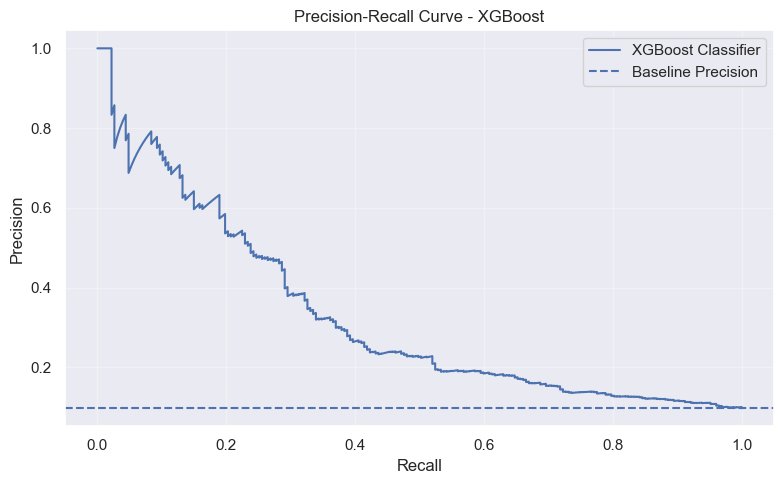


==== FINE-GRAINED THRESHOLD ANALYSIS ====
 Threshold  Precision  Recall  F1 Score
      0.05     0.1382  0.7269    0.2322
      0.06     0.1575  0.6960    0.2569
      0.07     0.1721  0.6520    0.2723
      0.08     0.1842  0.6079    0.2828
      0.09     0.1906  0.5330    0.2807
      0.10     0.2193  0.5198    0.3085
      0.11     0.2319  0.4802    0.3128
      0.12     0.2385  0.4581    0.3137
      0.13     0.2455  0.4229    0.3107
      0.14     0.2605  0.4097    0.3185
      0.15     0.2755  0.3921    0.3236
      0.16     0.2919  0.3833    0.3314
      0.17     0.3111  0.3700    0.3380
      0.18     0.3197  0.3436    0.3312
      0.19     0.3408  0.3348    0.3378
      0.20     0.3700  0.3260    0.3466
      0.21     0.3817  0.3128    0.3438
      0.22     0.3807  0.2952    0.3325
      0.23     0.4314  0.2907    0.3474
      0.24     0.4604  0.2819    0.3497
      0.25     0.4754  0.2555    0.3324
      0.26     0.5000  0.2379    0.3224
      0.27     0.5098  0.2291    0.31

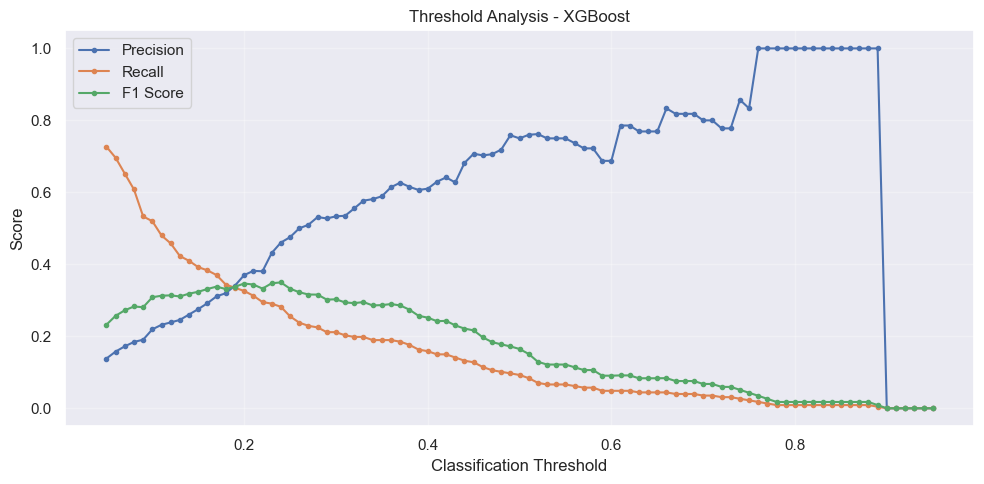


==== BEST THRESHOLD ====
Best Threshold: 0.24000000000000005
Threshold    0.240000
Precision    0.460432
Recall       0.281938
F1 Score     0.349727
Name: 19, dtype: float64

==== TRAIN METRICS ====
Accuracy    : 0.9790
Precision   : 0.9188
Recall      : 0.8601
F1 Score    : 0.8885
ROC-AUC     : 0.9927
PR-AUC      : 0.9555

==== VALIDATION METRICS ====
Accuracy    : 0.8982
Precision   : 0.4604
Recall      : 0.2819
F1 Score    : 0.3497
ROC-AUC     : 0.7134
PR-AUC      : 0.3267

==== TEST METRICS ====
Accuracy    : 0.8939
Precision   : 0.4309
Recall      : 0.2852
F1 Score    : 0.3432
ROC-AUC     : 0.6924
PR-AUC      : 0.3215


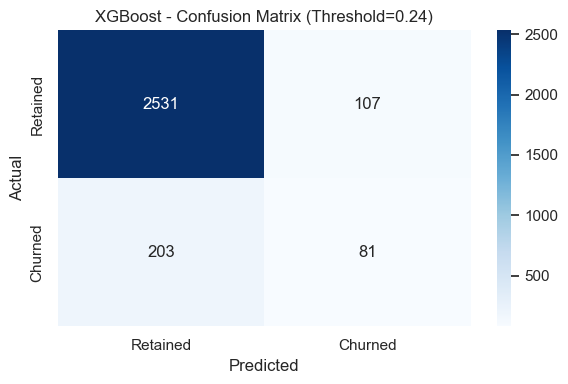


==== CLASSIFICATION REPORT ====
              precision    recall  f1-score   support

    Retained       0.93      0.96      0.94      2638
     Churned       0.43      0.29      0.34       284

    accuracy                           0.89      2922
   macro avg       0.68      0.62      0.64      2922
weighted avg       0.88      0.89      0.88      2922


==== CROSS VALIDATION TRAIN SCORES ====
train_Accuracy - Mean: 0.9600, Std: 0.0014
train_Precision - Mean: 0.9991, Std: 0.0011
train_Recall - Mean: 0.5884, Std: 0.0150
train_F1 - Mean: 0.7405, Std: 0.0119
train_ROC_AUC - Mean: 0.9971, Std: 0.0003
train_PR_AUC - Mean: 0.9801, Std: 0.0014

==== CROSS VALIDATION VALIDATION SCORES ====
test_Accuracy - Mean: 0.9072, Std: 0.0031
test_Precision - Mean: 0.6640, Std: 0.1115
test_Recall - Mean: 0.0881, Std: 0.0230
test_F1 - Mean: 0.1553, Std: 0.0383
test_ROC_AUC - Mean: 0.6838, Std: 0.0231
test_PR_AUC - Mean: 0.2842, Std: 0.0268

==== TOP 20 IMPORTANT FEATURES ====
                          

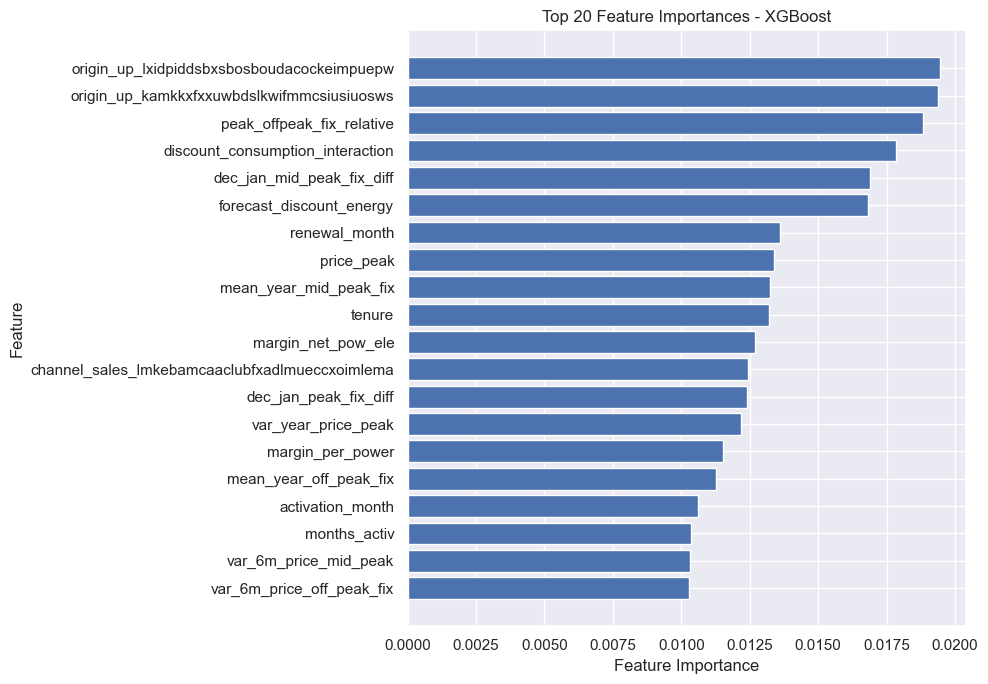

In [7]:

# Exp 8(4) – Hyperparameter-Tuned XGBoost | Validation-Based Threshold Optimization

# ============================================================
# 0. IMPORT LIBRARIES
# ============================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from xgboost import XGBClassifier

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    RandomizedSearchCV,
    cross_validate
)
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import make_column_transformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    precision_recall_curve,
    confusion_matrix,
    classification_report
)

# ============================================================
# 1. SEPARATE FEATURES AND TARGET
# ============================================================
date_cols = [
    'date_activ',
    'date_end',
    'date_modif_prod',
    'date_renewal'
]

X = df.drop(columns=['id', 'churn'] + date_cols, errors='ignore').copy()
y = df['churn'].copy()

print("Total Missing Values:", X.isna().sum().sum())
print("\n==== TARGET DISTRIBUTION ====")
print(y.value_counts())
print("\n==== TARGET PERCENTAGE ====")
print((y.value_counts(normalize=True) * 100).round(2))

# ============================================================
# 2. ORIGINAL TRAIN TEST SPLIT
# ============================================================
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nOriginal Training Data:", X_train.shape)
print("Original Test Data:", X_test.shape)

# ============================================================
# 3. INTERNAL TRAIN VALIDATION SPLIT
# ============================================================
# Keep test data untouched.
# Use validation data only for threshold selection.

X_fit, X_val, y_fit, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=21,
    stratify=y_train
)

print("\nModel Training Data:", X_fit.shape)
print("Threshold Validation Data:", X_val.shape)
print("Final Test Data:", X_test.shape)

# ============================================================
# 4. IDENTIFY CATEGORICAL AND NUMERICAL COLUMNS
# ============================================================
categorical_cols = X.select_dtypes(
    include=['object', 'category', 'bool']
).columns.tolist()

numerical_cols = X.select_dtypes(
    include=np.number
).columns.tolist()

print("\nCategorical Columns:", categorical_cols)
print("Numerical Columns:", len(numerical_cols))

# ============================================================
# 5. CALCULATE CLASS IMBALANCE RATIO
# ============================================================
negative_count = (y_fit == 0).sum()
positive_count = (y_fit == 1).sum()

scale_pos_weight_value = negative_count / positive_count

print("\n==== CLASS IMBALANCE ====")
print("Negative Class:", negative_count)
print("Positive Class:", positive_count)
print("Scale Pos Weight:", scale_pos_weight_value)

# ============================================================
# 6. PREPROCESSING PIPELINE
# ============================================================
# XGBoost handles numerical missing values natively.
# Categorical missing values must be imputed before OneHotEncoder.

categorical_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(
        strategy='constant',
        fill_value='__MISSING__'
    )),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = make_column_transformer(
    (categorical_pipeline, categorical_cols),
    remainder='passthrough',
    verbose_feature_names_out=False,
    n_jobs=1
)

# ============================================================
# 7. XGBOOST PIPELINE
# ============================================================
xgb_pipeline = Pipeline(steps=[
    ('preprocessing', preprocessor),
    ('model', XGBClassifier(
        objective='binary:logistic',
        eval_metric='aucpr',
        tree_method='hist',
        random_state=42,
        n_jobs=1,
        verbosity=0
    ))
])

# ============================================================
# 8. STRATIFIED CROSS VALIDATION
# ============================================================
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# ============================================================
# 9. HYPERPARAMETER SEARCH SPACE
# ============================================================
param_grid = {
    'model__n_estimators': [200, 300, 500, 700],
    'model__max_depth': [2, 3, 4, 5, 6],
    'model__learning_rate': [0.01, 0.03, 0.05, 0.1],
    'model__subsample': [0.7, 0.8, 0.9, 1.0],
    'model__colsample_bytree': [0.6, 0.7, 0.8, 1.0],
    'model__min_child_weight': [1, 3, 5, 7],
    'model__gamma': [0, 0.1, 0.3, 0.5],
    'model__reg_alpha': [0, 0.01, 0.1, 1],
    'model__reg_lambda': [1, 3, 5, 10],
    'model__scale_pos_weight': [
        1,
        scale_pos_weight_value * 0.5,
        scale_pos_weight_value * 0.75,
        scale_pos_weight_value
    ]
}

# ============================================================
# 10. RANDOMIZED SEARCH CV
# ============================================================
random_search = RandomizedSearchCV(
    estimator=xgb_pipeline,
    param_distributions=param_grid,
    n_iter=30,
    scoring='average_precision',
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=2,
    refit=True,
    return_train_score=True
)

# ============================================================
# 11. FIT RANDOMIZED SEARCH
# ============================================================
random_search.fit(X_fit, y_fit)

# ============================================================
# 12. BEST HYPERPARAMETERS
# ============================================================
print("\n==== BEST HYPERPARAMETERS ====")
print(random_search.best_params_)

print("\nBest CV PR-AUC:")
print(random_search.best_score_)

# ============================================================
# 13. BEST XGBOOST MODEL
# ============================================================
best_xgb_pipeline = random_search.best_estimator_

# ============================================================
# 14. RANDOMIZED SEARCH RESULTS
# ============================================================
search_results_df = pd.DataFrame(random_search.cv_results_)
search_results_df = search_results_df.sort_values(
    by='mean_test_score',
    ascending=False
)

print("\n==== TOP 10 HYPERPARAMETER COMBINATIONS ====")
print(
    search_results_df[[
        'param_model__n_estimators',
        'param_model__max_depth',
        'param_model__learning_rate',
        'param_model__subsample',
        'param_model__colsample_bytree',
        'param_model__min_child_weight',
        'param_model__scale_pos_weight',
        'mean_train_score',
        'mean_test_score',
        'std_test_score'
    ]].head(10).round(4).to_string(index=False)
)

# ============================================================
# 15. VALIDATION PROBABILITIES
# ============================================================
y_prob_val = best_xgb_pipeline.predict_proba(X_val)[:, 1]

# ============================================================
# 16. PRECISION RECALL CURVE
# ============================================================
precision, recall, pr_thresholds = precision_recall_curve(
    y_val,
    y_prob_val
)

plt.figure(figsize=(8, 5))
plt.plot(
    recall,
    precision,
    label='XGBoost Classifier'
)
plt.axhline(
    y=y_val.mean(),
    linestyle='--',
    label='Baseline Precision'
)
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve - XGBoost')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# ============================================================
# 17. FINE-GRAINED THRESHOLD ANALYSIS
# ============================================================
threshold_values = np.arange(0.05, 0.951, 0.01)
threshold_results = []

for threshold in threshold_values:
    y_pred = (y_prob_val >= threshold).astype(int)

    threshold_results.append({
        'Threshold': threshold,
        'Precision': precision_score(
            y_val, y_pred, zero_division=0
        ),
        'Recall': recall_score(
            y_val, y_pred, zero_division=0
        ),
        'F1 Score': f1_score(
            y_val, y_pred, zero_division=0
        )
    })

fine_threshold_df = pd.DataFrame(threshold_results)

print("\n==== FINE-GRAINED THRESHOLD ANALYSIS ====")
print(fine_threshold_df.round(4).to_string(index=False))

# ============================================================
# 18. THRESHOLD PERFORMANCE VISUALIZATION
# ============================================================
plt.figure(figsize=(10, 5))
plt.plot(
    fine_threshold_df['Threshold'],
    fine_threshold_df['Precision'],
    marker='o',
    markersize=3,
    label='Precision'
)
plt.plot(
    fine_threshold_df['Threshold'],
    fine_threshold_df['Recall'],
    marker='o',
    markersize=3,
    label='Recall'
)
plt.plot(
    fine_threshold_df['Threshold'],
    fine_threshold_df['F1 Score'],
    marker='o',
    markersize=3,
    label='F1 Score'
)
plt.xlabel('Classification Threshold')
plt.ylabel('Score')
plt.title('Threshold Analysis - XGBoost')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# ============================================================
# 19. SELECT BEST THRESHOLD
# ============================================================
best_threshold_idx = fine_threshold_df['F1 Score'].idxmax()
best_threshold = fine_threshold_df.loc[
    best_threshold_idx, 'Threshold'
]

print("\n==== BEST THRESHOLD ====")
print("Best Threshold:", best_threshold)
print(fine_threshold_df.loc[best_threshold_idx])

# ============================================================
# 20. DEFINE METRIC FUNCTION
# ============================================================
def calc_metrics(y_true, y_pred, y_prob):
    return {
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision': precision_score(
            y_true, y_pred, zero_division=0
        ),
        'Recall': recall_score(
            y_true, y_pred, zero_division=0
        ),
        'F1 Score': f1_score(
            y_true, y_pred, zero_division=0
        ),
        'ROC-AUC': roc_auc_score(y_true, y_prob),
        'PR-AUC': average_precision_score(y_true, y_prob)
    }

# ============================================================
# 21. TRAINING PREDICTIONS
# ============================================================
y_prob_train = best_xgb_pipeline.predict_proba(X_fit)[:, 1]
y_pred_train = (y_prob_train >= best_threshold).astype(int)

# ============================================================
# 22. VALIDATION PREDICTIONS
# ============================================================
y_pred_val = (y_prob_val >= best_threshold).astype(int)

# ============================================================
# 23. TEST PREDICTIONS
# ============================================================
y_prob_test = best_xgb_pipeline.predict_proba(X_test)[:, 1]
y_pred_test = (y_prob_test >= best_threshold).astype(int)

# ============================================================
# 24. CALCULATE METRICS
# ============================================================
train_metrics = calc_metrics(
    y_fit,
    y_pred_train,
    y_prob_train
)

validation_metrics = calc_metrics(
    y_val,
    y_pred_val,
    y_prob_val
)

test_metrics = calc_metrics(
    y_test,
    y_pred_test,
    y_prob_test
)

# ============================================================
# 25. PRINT TRAIN METRICS
# ============================================================
print("\n==== TRAIN METRICS ====")
for metric, value in train_metrics.items():
    print(f"{metric:12}: {value:.4f}")

# ============================================================
# 26. PRINT VALIDATION METRICS
# ============================================================
print("\n==== VALIDATION METRICS ====")
for metric, value in validation_metrics.items():
    print(f"{metric:12}: {value:.4f}")

# ============================================================
# 27. PRINT TEST METRICS
# ============================================================
print("\n==== TEST METRICS ====")
for metric, value in test_metrics.items():
    print(f"{metric:12}: {value:.4f}")

# ============================================================
# 28. CONFUSION MATRIX
# ============================================================
cm = confusion_matrix(y_test, y_pred_test)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Retained', 'Churned'],
    yticklabels=['Retained', 'Churned']
)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title(
    f'XGBoost - Confusion Matrix '
    f'(Threshold={best_threshold:.2f})'
)
plt.tight_layout()
plt.show()

# ============================================================
# 29. CLASSIFICATION REPORT
# ============================================================
print("\n==== CLASSIFICATION REPORT ====")
print(
    classification_report(
        y_test,
        y_pred_test,
        target_names=['Retained', 'Churned'],
        zero_division=0
    )
)

# ============================================================
# 30. CROSS VALIDATION PERFORMANCE
# ============================================================
# Diagnostic CV scores for the selected model.
# These are not an independent estimate after hyperparameter selection.

scoring = {
    'Accuracy': 'accuracy',
    'Precision': 'precision',
    'Recall': 'recall',
    'F1': 'f1',
    'ROC_AUC': 'roc_auc',
    'PR_AUC': 'average_precision'
}

cv_results = cross_validate(
    best_xgb_pipeline,
    X_fit,
    y_fit,
    scoring=scoring,
    cv=cv,
    return_train_score=True,
    n_jobs=1
)

# ============================================================
# 31. CROSS VALIDATION TRAIN SCORES
# ============================================================
print("\n==== CROSS VALIDATION TRAIN SCORES ====")
for key, value in cv_results.items():
    if key.startswith('train'):
        print(
            f"{key} - Mean: {np.mean(value):.4f}, "
            f"Std: {np.std(value):.4f}"
        )

# ============================================================
# 32. CROSS VALIDATION VALIDATION SCORES
# ============================================================
print("\n==== CROSS VALIDATION VALIDATION SCORES ====")
for key, value in cv_results.items():
    if key.startswith('test'):
        print(
            f"{key} - Mean: {np.mean(value):.4f}, "
            f"Std: {np.std(value):.4f}"
        )

# ============================================================
# 33. FEATURE IMPORTANCE
# ============================================================
xgb_model = best_xgb_pipeline.named_steps['model']

feature_names = (
    best_xgb_pipeline
    .named_steps['preprocessing']
    .get_feature_names_out()
)

importances = xgb_model.feature_importances_

feature_importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
}).sort_values(
    by='Importance',
    ascending=False
).reset_index(drop=True)

print("\n==== TOP 20 IMPORTANT FEATURES ====")
print(feature_importance_df.head(20).to_string(index=False))

# ============================================================
# 34. FEATURE IMPORTANCE VISUALIZATION
# ============================================================
top_features = feature_importance_df.head(20).sort_values(
    by='Importance',
    ascending=True
)

plt.figure(figsize=(10, 7))
plt.barh(
    top_features['Feature'],
    top_features['Importance']
)
plt.xlabel('Feature Importance')
plt.ylabel('Feature')
plt.title('Top 20 Feature Importances - XGBoost')
plt.tight_layout()
plt.show()


**Exp 8(4) – Hyperparameter-Tuned XGBoost | Validation-Based Threshold Optimization**

**1. Model Optimization**

- Applied hyperparameter tuning using 30 parameter combinations and 5-fold cross-validation.
- Used PR-AUC as the optimization metric.
- Best hyperparameters:
  - `n_estimators`: 700
  - `max_depth`: 4
  - `learning_rate`: 0.05
  - `subsample`: 0.8
  - `colsample_bytree`: 0.8
  - `min_child_weight`: 1
  - `gamma`: 0.1
  - `reg_alpha`: 0
  - `reg_lambda`: 1
  - `scale_pos_weight`: 1
- Best CV PR-AUC: **28.42%**

**Observation:**

- Selected a relatively shallow tree depth of 4 to control model complexity.
- CV PR-AUC improved compared to Exp5 (26.38%) but remained lower than Exp2 (30.55%).
- Training performance remains extremely high, indicating overfitting.
- Hyperparameter tuning did not provide a substantial improvement in validation performance.

**2. Model Performance – Test Data**

- Accuracy: **89.39%**
- Precision: **43.09%**
- Recall: **28.52%**
- F1 Score: **34.32%**
- ROC-AUC: **69.24%**
- PR-AUC: **32.15%**

**3. Threshold Analysis**

- Tested classification thresholds between 0.05 and 0.95.
- Selected threshold: **0.24**, based on the highest F1 score in the threshold analysis.
- At threshold 0.24 (threshold validation):
  - Precision: 46.04%
  - Recall: 28.19%
  - F1 Score: 34.97%
- Lower thresholds improve recall but reduce precision.
- Higher thresholds improve precision but reduce recall.
- Threshold 0.24 provides a reasonable balance between precision and recall.

**4. Confusion Matrix (Threshold = 0.24)**

- True Negatives: 2,531
- False Positives: 107
- False Negatives: 203
- True Positives: 81

**Observation:**

- Model correctly identifies 81 churn customers out of 284.
- It misses 203 actual churn customers.
- False positives are relatively low (107).
- However, the model fails to identify a large proportion of actual churn customers.
- The model prioritizes precision over recall.

**5. Precision-Recall Curve**

- Baseline precision is approximately 9.72%, corresponding to the churn percentage.
- Model achieves higher precision than the baseline across much of the recall range.
- PR-AUC of 32.15% indicates better performance than the baseline.
- However, PR-AUC is lower than Exp2 (35.75%) and Exp8(2) (34.26%).

**6. Cross-Validation Results**

- Training PR-AUC: 98.01%
- Validation accuracy: 90.72%
- Validation precision: 66.40%
- Validation recall: 8.81%
- Validation F1: 15.53%
- Validation ROC-AUC: 68.38%
- Validation PR-AUC: 28.42%

**Observation:**

- Significant training-validation performance gap indicates overfitting.
- Validation recall is extremely low at the default 0.50 threshold.
- Validation precision is high, but the model identifies very few churn customers.
- Despite high training performance, generalization to validation data remains limited.

**7. Top 20 Important Features**

The most important features include:

- origin_up_lxidpiddsbxsbosboudacockeimpuepw
- origin_up_kamkkxfxxuwbdslkwifmmcsiusiuosws
- peak_offpeak_fix_relative
- discount_consumption_interaction
- dec_jan_mid_peak_fix_diff
- forecast_discount_energy
- renewal_month
- price_peak
- mean_year_mid_peak_fix
- tenure
- margin_net_pow_ele
- channel_sales_lmkebamcaaclubfxadlmueccxoimlema
- dec_jan_peak_fix_diff
- var_year_price_peak
- margin_per_power

**Observation:**

- Price-related, discount-related and consumption-related features contribute significantly.
- Customer subscription information (`origin_up`) appears among the most important features.
- Tenure and renewal-related features also contribute to churn prediction.
- Feature importance patterns indicate that pricing behaviour and customer characteristics are important for identifying churn.

**8. Model Comparison – All Experiments**

| Metric    | Exp1-Baseline RF | Exp2-Regularized RF | Exp3-Strongly Reg. RF | Exp4-XGBoost | Exp5-Strongly Reg. XGB | Exp6-LightGBM | Exp7-SVM | Exp8(2)-RF | Exp8(4)-XGB |
| --------- | ---------------- | ------------------- | --------------------- | ------------ | ---------------------- | ------------- | -------- | ---------- | ----------- |
| Accuracy  | 84.02%           | 87.34%              | 84.94%                | **89.39%**   | 86.69%                 | 88.02%        | 82.75%   | 82.07%     | **89.39%**  |
| Precision | 26.72%           | 34.86%              | 29.26%                | **43.09%**   | 31.83%                 | 36.48%        | 23.68%   | 25.71%     | **43.09%**  |
| Recall    | 36.97%           | 34.86%              | **38.73%**            | 28.52%       | 32.39%                 | 31.34%        | 34.86%   | **44.72%** | 28.52%      |
| F1 Score  | 31.02%           | **34.86%**          | 33.33%                | 34.32%       | 32.11%                 | 33.71%        | 28.21%   | 32.65%     | 34.32%      |
| ROC-AUC   | **70.76%**       | 70.48%              | 69.45%                | 69.24%       | 69.58%                 | 69.33%        | 66.45%   | 69.98%     | 69.24%      |
| PR-AUC    | 32.77%           | **35.75%**          | 31.71%                | 32.15%       | 29.42%                 | 32.20%        | 20.13%   | 34.26%     | 32.15%      |
| CV PR-AUC | 25.43%           | **30.55%**          | 26.15%                | 28.42%       | 26.38%                 | 28.63%        | 20.85%   | 27.35%     | 28.42%      |

**Observation:**

- Exp8(4) achieves the highest accuracy (89.39%), tied with Exp4.
- Precision (43.09%) is also the highest, tied with Exp4.
- However, recall is relatively low at 28.52%.
- PR-AUC (32.15%) is lower than Exp2 and Exp8(2).
- Exp8(2) achieves considerably higher recall (44.72%).
- Exp2 maintains the highest PR-AUC (35.75%) and F1 Score (34.86%).
- Exp8(4) is more conservative in identifying churn customers, resulting in fewer false positives but more missed churn customers.

**Final Conclusion – Exp 8(4) XGBoost**

- Achieves a test PR-AUC of 32.15%.
- Achieves high precision of 43.09%.
- Correctly identifies 81 churn customers out of 284.
- Generates only 107 false positives.
- However, it misses 203 actual churn customers.
- Significant overfitting remains a concern.
- The model does not improve overall churn prediction performance compared to the existing best models.

**Best Model So Far: Exp 2 – Regularized Random Forest**

Exp2 remains the best overall model because it achieves the highest PR-AUC (35.75%) and F1 Score (34.86%), providing a better balance between precision and recall.

Exp8(2) is a strong alternative when identifying more churn customers is the priority, achieving the highest recall (44.72%).

Exp8(4) is more suitable when controlling false positives and maintaining higher precision are priorities.

**Important note:** CV classification metrics use the default 0.50 threshold, while validation and test metrics use the selected 0.24 threshold. Compare classification metrics cautiously.

**One thing to verify:** Exp8(4) has exactly the same test accuracy, precision, recall, F1, ROC-AUC and PR-AUC as Exp4. This suggests the two experiments may have reproduced the same test predictions or evaluation results. Hence not conside this Exp8(4) result here onwards

# Exp 9 – Random Forest and XGBoost | Outlier Treatment 

## Let's Identify Which Outlier Treatment to Apply to Each Column.

In [8]:

import pandas as pd
import numpy as np

# ==========================================
# STEP 1: DATASET COLUMN ANALYSIS
# ==========================================

print("Dataset Shape:", df.shape)

# 1. Check all columns
print("\n========== ALL COLUMNS ==========")
for i, col in enumerate(df.columns, 1):
    print(f"{i}. {col}")

# 2. Check data types
print("\n========== DATA TYPES ==========")
print(df.dtypes.value_counts())

# 3. Separate numerical and categorical columns
categorical_cols = df.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

numerical_cols = df.select_dtypes(
    include=np.number
).columns.tolist()

print("\nCategorical Columns:", len(categorical_cols))
print(categorical_cols)

print("\nNumerical Columns:", len(numerical_cols))
print(numerical_cols)

# 4. Missing values
missing_df = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": (df.isnull().mean() * 100).round(2)
})

missing_df = missing_df[missing_df["Missing_Count"] > 0]
missing_df = missing_df.sort_values(
    "Missing_Percentage", ascending=False
)

print("\n========== MISSING VALUES ==========")
print(missing_df)

# 5. Check duplicate rows
print("\nDuplicate Rows:", df.duplicated().sum())

# 6. Numerical feature summary
print("\n========== NUMERICAL SUMMARY ==========")
display(df[numerical_cols].describe().T)

# 7. Check target distribution
print("\n========== TARGET DISTRIBUTION ==========")
print(df["churn"].value_counts())

print("\n========== TARGET PERCENTAGE ==========")
print(df["churn"].value_counts(normalize=True) * 100)


Dataset Shape: (14606, 110)

========== ALL COLUMNS ==========
1. id
2. channel_sales
3. cons_12m
4. cons_gas_12m
5. cons_last_month
6. date_activ
7. date_end
8. date_modif_prod
9. date_renewal
10. forecast_cons_12m
11. forecast_cons_year
12. forecast_discount_energy
13. forecast_meter_rent_12m
14. forecast_price_energy_off_peak
15. forecast_price_energy_peak
16. forecast_price_pow_off_peak
17. has_gas
18. imp_cons
19. margin_net_pow_ele
20. nb_prod_act
21. net_margin
22. num_years_antig
23. origin_up
24. pow_max
25. var_year_price_off_peak_var
26. var_year_price_peak_var
27. var_year_price_mid_peak_var
28. var_year_price_off_peak_fix
29. var_year_price_peak_fix
30. var_year_price_mid_peak_fix
31. var_year_price_off_peak
32. var_year_price_peak
33. var_year_price_mid_peak
34. var_6m_price_off_peak_var
35. var_6m_price_peak_var
36. var_6m_price_mid_peak_var
37. var_6m_price_off_peak_fix
38. var_6m_price_peak_fix
39. var_6m_price_mid_peak_fix
40. var_6m_price_off_peak
41. var_6m_price_pe

,count,mean,std,min,25%,50%,75%,max
cons_12m,14606.0,159220.286252,573465.264198,0.000000e+00,5674.750000,14115.500000,40763.750000,6.207104e+06
cons_gas_12m,14606.0,28092.375325,162973.059057,0.000000e+00,0.000000,0.000000,0.000000,4.154590e+06
cons_last_month,14606.0,16090.269752,64364.196422,0.000000e+00,0.000000,792.500000,3383.000000,7.712030e+05
forecast_cons_12m,14606.0,1868.614880,2387.571531,0.000000e+00,494.995000,1112.875000,2401.790000,8.290283e+04
forecast_cons_year,14606.0,1399.762906,3247.786255,0.000000e+00,0.000000,314.000000,1745.750000,1.753750e+05
...,...,...,...,...,...,...,...,...
price_consumption_exposure,14499.0,-4717.595766,36271.542058,-2.077381e+06,-1441.210999,-379.299571,-110.783060,5.360476e+05
gas_product_interaction,14606.0,0.188425,0.527522,0.000000e+00,0.000000,0.000000,0.000000,6.284255e+00
tenure_margin_interaction,14606.0,998.410308,1545.112469,0.000000e+00,252.000000,570.955000,1206.405000,9.828260e+04
price_power_interaction,14499.0,-0.680246,1.617675,-5.347501e+01,-0.853643,-0.369186,-0.248362,6.203460e+01



========== TARGET DISTRIBUTION ==========
churn
0    13187
1     1419
Name: count, dtype: int64

========== TARGET PERCENTAGE ==========
churn
0    90.284814
1     9.715186
Name: proportion, dtype: float64


In [9]:

import pandas as pd
import numpy as np

from scipy.stats import median_abs_deviation

# ==========================================
# STEP 2: OUTLIER DETECTION
# ==========================================

# Exclude target and non-predictor columns
exclude_cols = [
    "id",
    "churn",
    "date_activ",
    "date_end",
    "date_modif_prod",
    "date_renewal"
]

# Numerical predictor columns
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()

numeric_cols = [
    col for col in numeric_cols
    if col not in exclude_cols
]

# Exclude binary and month-based features
protected_cols = [
    "activation_month",
    "renewal_month",
    "modification_month",
    "zero_gas_consumption",
    "zero_last_month_consumption",
    "zero_forecast_consumption",
    "gas_consumption_share"
]

# Select continuous numerical features
outlier_cols = [
    col for col in numeric_cols
    if df[col].nunique(dropna=True) > 10
    and col not in protected_cols
]

print("Total numerical predictors:", len(numeric_cols))
print("Features selected for outlier detection:", len(outlier_cols))

# ==========================================
# OUTLIER DETECTION FUNCTION
# ==========================================

results = []

for col in outlier_cols:

    x = df[col].dropna()

    if len(x) == 0:
        continue

    # IQR Method
    Q1 = x.quantile(0.25)
    Q3 = x.quantile(0.75)
    IQR = Q3 - Q1

    lower_iqr = Q1 - 1.5 * IQR
    upper_iqr = Q3 + 1.5 * IQR

    iqr_outliers = ((x < lower_iqr) | (x > upper_iqr)).sum()

    # Z-score Method
    mean = x.mean()
    std = x.std()

    if std > 0:
        z_scores = (x - mean) / std
        z_outliers = (z_scores.abs() > 3).sum()
    else:
        z_outliers = 0

    # Modified Z-score Method
    median = x.median()
    mad = median_abs_deviation(x, scale=1)

    if mad > 0:
        modified_z = 0.6745 * (x - median) / mad
        modified_z_outliers = (modified_z.abs() > 3.5).sum()
    else:
        modified_z_outliers = 0

    # Percentile Method
    lower_pct = x.quantile(0.01)
    upper_pct = x.quantile(0.99)

    percentile_outliers = (
        (x < lower_pct) | (x > upper_pct)
    ).sum()

    results.append({
        "Feature": col,
        "IQR_Outliers": iqr_outliers,
        "IQR_%": round(iqr_outliers / len(x) * 100, 2),
        "Zscore_Outliers": z_outliers,
        "Zscore_%": round(z_outliers / len(x) * 100, 2),
        "Modified_Z_Outliers": modified_z_outliers,
        "Modified_Z_%": round(modified_z_outliers / len(x) * 100, 2),
        "Percentile_Outliers": percentile_outliers,
        "Percentile_%": round(percentile_outliers / len(x) * 100, 2)
    })

# ==========================================
# FINAL OUTLIER SUMMARY
# ==========================================

outlier_summary = pd.DataFrame(results)

outlier_summary = outlier_summary.sort_values(
    by="IQR_%",
    ascending=False
).reset_index(drop=True)

print("\n========== OUTLIER DETECTION SUMMARY ==========")

display(outlier_summary)

print("\nOutlier summary saved successfully.")


Total numerical predictors: 101
Features selected for outlier detection: 93

========== OUTLIER DETECTION SUMMARY ==========


,Feature,IQR_Outliers,IQR_%,Zscore_Outliers,Zscore_%,Modified_Z_Outliers,Modified_Z_%,Percentile_Outliers,Percentile_%
0,dec_jan_mid_peak_var_diff,3604,24.67,217,1.49,0,0.00,291,1.99
1,cons_last_month_diff,2871,19.66,280,1.92,2366,16.20,291,1.99
2,peak_var_cv,1519,18.50,561,6.83,1236,15.05,79,0.96
3,gas_product_interaction,2612,17.88,503,3.44,0,0.00,147,1.01
4,cons_gas_12m,2612,17.88,248,1.70,0,0.00,143,0.98
...,...,...,...,...,...,...,...,...,...
88,off_peak_peak_var_ratio,0,0.00,0,0.00,6982,47.80,249,1.70
89,off_peak_peak_fix_ratio,0,0.00,0,0.00,6076,41.60,233,1.60
90,peak_offpeak_fix_relative,0,0.00,0,0.00,0,0.00,143,0.99
91,peak_offpeak_var_relative,0,0.00,0,0.00,0,0.00,98,0.67



Outlier summary saved successfully.


In [10]:

import pandas as pd
import numpy as np

# ==========================================
# STEP 3: INVESTIGATE CANDIDATE OUTLIERS
# ==========================================

candidate_features = [
    "dec_jan_mid_peak_var_diff",
    "cons_last_month_diff",
    "peak_var_cv",
    "cons_gas_12m",
    "gas_product_interaction",
    "price_consumption_exposure",
    "consumption_per_power",
    "forecast_cons_diff",
    "cons_12m",
    "cons_last_month",
    "pow_max",
    "forecast_cons_year",
    "imp_cons",
    "net_margin",
    "margin_per_product"
]

# Keep only columns available in df
candidate_features = [
    col for col in candidate_features if col in df.columns
]

summary = []

for col in candidate_features:

    x = df[col].dropna()

    Q1 = x.quantile(0.25)
    Q3 = x.quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outlier_mask = (df[col] < lower) | (df[col] > upper)

    summary.append({
        "Feature": col,
        "Q1": Q1,
        "Median": x.median(),
        "Q3": Q3,
        "Lower_Bound": lower,
        "Upper_Bound": upper,
        "Min": x.min(),
        "Max": x.max(),
        "Outlier_Count": outlier_mask.sum(),
        "Outlier_%": round(outlier_mask.mean() * 100, 2),
        "Retained_Outliers": (
            outlier_mask & (df["churn"] == 0)
        ).sum(),
        "Churned_Outliers": (
            outlier_mask & (df["churn"] == 1)
        ).sum()
    })

candidate_summary = pd.DataFrame(summary)

display(
    candidate_summary.sort_values(
        "Outlier_%",
        ascending=False
    ).round(4)
)

# ==========================================
# CLASS-WISE DISTRIBUTION
# ==========================================

for col in candidate_features:

    print(f"\n========== {col} ==========")

    display(
        df.groupby("churn")[col].describe().round(3)
    )


,Feature,Q1,Median,Q3,Lower_Bound,Upper_Bound,Min,Max,Outlier_Count,Outlier_%,Retained_Outliers,Churned_Outliers
0,dec_jan_mid_peak_var_diff,0.0000,0.0000,0.0007,-0.0011,0.0018,-9.870000e-02,1.035000e-01,3604,24.67,3185,419
1,cons_last_month_diff,-757.3750,-105.1250,496.3125,-2637.9062,2376.8438,-1.945252e+05,4.496560e+05,2871,19.66,2620,251
3,cons_gas_12m,0.0000,0.0000,0.0000,0.0000,0.0000,0.000000e+00,4.154590e+06,2612,17.88,2391,221
4,gas_product_interaction,0.0000,0.0000,0.0000,0.0000,0.0000,0.000000e+00,6.284300e+00,2612,17.88,2391,221
5,price_consumption_exposure,-1441.2110,-379.2996,-110.7831,-3436.8529,1884.8589,-2.077381e+06,5.360476e+05,2357,16.14,2150,207
6,consumption_per_power,401.5575,895.4845,2165.1270,-2243.7969,4810.4814,0.000000e+00,5.900289e+05,2118,14.50,1944,174
7,forecast_cons_diff,-37462.0375,-12605.7650,-4961.9275,-86212.2025,43788.2375,-6.207019e+06,3.534240e+03,2107,14.43,1940,167
8,cons_12m,5674.7500,14115.5000,40763.7500,-46958.7500,93397.2500,0.000000e+00,6.207104e+06,2084,14.27,1916,168
9,cons_last_month,0.0000,792.5000,3383.0000,-5074.5000,8457.5000,0.000000e+00,7.712030e+05,2051,14.04,1894,157
10,pow_max,12.5000,13.8560,19.1725,2.4913,29.1812,3.300000e+00,3.200000e+02,1535,10.51,1357,178



========== dec_jan_mid_peak_var_diff ==========


,count,mean,std,min,25%,50%,75%,max
churn,,,,,,,,
0,13187.0,0.0,0.007,-0.099,0.0,0.0,0.001,0.104
1,1419.0,0.0,0.007,-0.077,0.0,0.0,0.001,0.098



========== cons_last_month_diff ==========


,count,mean,std,min,25%,50%,75%,max
churn,,,,,,,,
0,13187.0,3057.413,22539.289,-194525.250,-746.458,-97.000,519.583,449656.000
1,1419.0,633.366,10702.655,-73553.583,-874.500,-157.583,312.292,188346.083



========== peak_var_cv ==========


... (21 outputs left out)


========== net_margin ==========


,count,mean,std,min,25%,50%,75%,max
churn,,,,,,,,
0,13187.0,185.057,232.263,0.0,50.510,111.86,239.855,10203.50
1,1419.0,228.362,705.676,0.0,52.605,121.86,271.935,24570.65



========== margin_per_product ==========


,count,mean,std,min,25%,50%,75%,max
churn,,,,,,,,
0,13187.0,83.485,108.579,0.0,22.492,50.25,107.560,5101.750
1,1419.0,98.939,200.253,0.0,24.140,55.69,122.697,6142.662


In [11]:

# ==========================================
# STEP 4: PERCENTILE ANALYSIS
# ==========================================

candidate_features = [
    "cons_last_month_diff",
    "consumption_per_power",
    "forecast_cons_diff",
    "cons_12m",
    "cons_last_month",
    "pow_max",
    "forecast_cons_year",
    "imp_cons",
    "net_margin",
    "margin_per_product",
    "peak_var_cv",
    "price_consumption_exposure"
]

candidate_features = [
    col for col in candidate_features
    if col in X_train.columns
]

percentile_results = []

for col in candidate_features:

    x = X_train[col].dropna()

    percentile_results.append({
        "Feature": col,
        "Missing_%": round(X_train[col].isna().mean() * 100, 2),
        "Zero_%": round((X_train[col] == 0).mean() * 100, 2),
        "Negative_%": round((X_train[col] < 0).mean() * 100, 2),
        "Skewness": round(x.skew(), 3),
        "P1": x.quantile(0.01),
        "P25": x.quantile(0.25),
        "Median": x.median(),
        "P75": x.quantile(0.75),
        "P99": x.quantile(0.99),
        "P995": x.quantile(0.995),
        "P999": x.quantile(0.999),
        "Maximum": x.max()
    })

percentile_df = pd.DataFrame(percentile_results)

display(
    percentile_df.round(3)
)



,Feature,Missing_%,Zero_%,Negative_%,Skewness,P1,P25,Median,P75,P99,P995,P999,Maximum
0,cons_last_month_diff,0.00,0.83,56.16,7.359,-19759.250,-728.917,-89.792,518.333,108658.583,142430.583,293582.333,449656.000
1,consumption_per_power,0.00,0.83,0.00,6.751,1.488,397.079,895.916,2179.839,198412.259,277386.162,434200.606,590028.897
2,forecast_cons_diff,0.00,0.72,99.17,-6.034,-3127939.676,-37699.100,-12632.950,-4935.658,-20.070,0.000,470.256,3534.240
3,cons_12m,0.00,0.83,0.00,6.029,22.660,5609.000,14139.000,41121.500,3129623.250,4100379.000,6207104.000,6207104.000
4,cons_last_month,0.00,33.65,0.00,6.378,0.000,0.000,813.000,3435.000,382647.000,479030.000,659315.160,771203.000
5,pow_max,0.00,0.00,0.00,6.010,10.350,12.500,13.856,19.300,80.000,97.170,160.000,320.000
6,forecast_cons_year,0.00,41.85,0.00,17.364,0.000,0.000,321.000,1769.000,11428.350,15091.910,38356.356,175375.000
7,imp_cons,0.00,41.99,0.00,13.948,0.000,0.000,37.795,195.995,1229.015,1677.275,4218.171,15042.790
8,net_margin,0.00,1.35,0.00,37.744,0.000,49.690,111.750,243.975,887.427,1111.107,2456.068,24570.650
9,margin_per_product,0.00,1.35,0.00,17.473,0.000,22.185,50.158,109.178,424.545,504.207,1116.153,6142.662


In [12]:

# ==========================================
# STEP 5: PERCENTILE-BASED OUTLIER CAPPING
# ==========================================

# Two-sided capping: lower 1%, upper 99%
two_sided_features = [
    "cons_last_month_diff",
    "forecast_cons_diff",
    "price_consumption_exposure"
]

# Upper-only capping: upper 99%
upper_only_features = [
    "consumption_per_power",
    "cons_12m",
    "cons_last_month",
    "pow_max",
    "forecast_cons_year",
    "imp_cons",
    "net_margin",
    "margin_per_product"
]

# Keep only existing columns
two_sided_features = [
    col for col in two_sided_features if col in X_train.columns
]

upper_only_features = [
    col for col in upper_only_features if col in X_train.columns
]

# Combine selected features
cap_features = two_sided_features + upper_only_features

# Calculate limits from training data only
cap_limits = {}

for col in cap_features:

    lower = X_train[col].quantile(0.01)
    upper = X_train[col].quantile(0.99)

    if col in two_sided_features:
        cap_limits[col] = (lower, upper)

    else:
        cap_limits[col] = (None, upper)

# Create copies
X_train_capped = X_train.copy()
X_test_capped = X_test.copy()

# Apply same limits to train and test
for col, (lower, upper) in cap_limits.items():

    if lower is not None:
        X_train_capped[col] = X_train_capped[col].clip(lower=lower)

        X_test_capped[col] = X_test_capped[col].clip(lower=lower)

    X_train_capped[col] = X_train_capped[col].clip(upper=upper)

    X_test_capped[col] = X_test_capped[col].clip(upper=upper)

# ==========================================
# VERIFY CAPPING
# ==========================================

comparison = []

for col in cap_features:

    comparison.append({
        "Feature": col,
        "Original_Min": X_train[col].min(),
        "Capped_Min": X_train_capped[col].min(),
        "Original_Max": X_train[col].max(),
        "Capped_Max": X_train_capped[col].max(),
        "Lower_Limit": cap_limits[col][0],
        "Upper_Limit": cap_limits[col][1]
    })

cap_comparison = pd.DataFrame(comparison)

display(cap_comparison.round(3))

print("Original training shape:", X_train.shape)
print("Capped training shape:", X_train_capped.shape)

print("Original test shape:", X_test.shape)
print("Capped test shape:", X_test_capped.shape)

print("\nMissing values before:", X_train.isna().sum().sum())
print("Missing values after:", X_train_capped.isna().sum().sum())

print("\nOutlier capping completed.")


,Feature,Original_Min,Capped_Min,Original_Max,Capped_Max,Lower_Limit,Upper_Limit
0,cons_last_month_diff,-194525.250,-19759.250,449656.000,108658.583,-19759.250,108658.583
1,forecast_cons_diff,-6207018.990,-3127939.676,3534.240,-20.070,-3127939.676,-20.070
2,price_consumption_exposure,-2077380.985,-99830.821,536047.560,8154.175,-99830.821,8154.175
3,consumption_per_power,0.000,0.000,590028.897,198412.259,NaN,198412.259
4,cons_12m,0.000,0.000,6207104.000,3129623.250,NaN,3129623.250
5,cons_last_month,0.000,0.000,771203.000,382647.000,NaN,382647.000
6,pow_max,3.300,3.300,320.000,80.000,NaN,80.000
7,forecast_cons_year,0.000,0.000,175375.000,11428.350,NaN,11428.350
8,imp_cons,0.000,0.000,15042.790,1229.015,NaN,1229.015
9,net_margin,0.000,0.000,24570.650,887.427,NaN,887.427


Original training shape: (11684, 104)
Capped training shape: (11684, 104)
Original test shape: (2922, 104)
Capped test shape: (2922, 104)

Missing values before: 27076
Missing values after: 27076

Outlier capping completed.


### **Exp 9(2) – Hyperparameter-Tuned Random Forest | Feature-Specific Outlier Capping**

1. Separate features and target, excluding customer ID and raw date columns.
2. Split the data into 80% training and 20% testing using stratification.
3. Further split the training data into model training (80%) and validation (20%), keeping the test set untouched.
4. Identify numerical and categorical features for preprocessing.
5. Apply feature-specific outlier capping:
   - Two-sided capping (1st–99th percentile) for selected features.
   - Upper-only capping (99th percentile) for selected right-skewed features.
6. Create a custom OutlierCapper transformer to learn capping limits from model-training data and apply them to validation and test data.
7. Impute numerical missing values using the median. Impute categorical missing values with a constant and apply One-Hot Encoding (OHE).
8. Handle class imbalance using class_weight='balanced'.
9. RandomizedSearchCV with 25 iterations and 5-Fold Stratified CV is used to tune Random Forest hyperparameters based on PR-AUC.
10. The best model generates churn probabilities on the validation set.
11. Perform fine-grained threshold analysis (0.05–0.95) and select the threshold with the highest F1 Score.
12. Apply the selected threshold to training, validation, and test probabilities to generate:
    0 = Retained | 1 = Churned.
13. Evaluate model performance using Accuracy, Precision, Recall, F1 Score, ROC-AUC, PR-AUC, confusion matrix, and classification report.
14. Perform diagnostic cross-validation and analyse feature importance to identify the most influential features.
15. Display the final test performance, selected threshold, best CV PR-AUC, number of capped features, and dataset split sizes.
 
experiment incorporates changes to the original Exp 2 model based on outlier detection and treatment.    
Exp 9(2) as took the best-performing Random Forest model from Exp2 and carried it forward as a new experiment under Exp9

Dataset Shape: (14606, 104)

Missing Values: 33864

==== TARGET DISTRIBUTION ====
churn
0    13187
1     1419
Name: count, dtype: int64

==== TARGET PERCENTAGE ====
churn
0    90.28
1     9.72
Name: proportion, dtype: float64

Original Training Shape: (11684, 104)
Original Test Shape: (2922, 104)

Model Training Shape: (9347, 104)
Validation Shape: (2337, 104)
Final Test Shape: (2922, 104)

Categorical Columns:
['channel_sales', 'has_gas', 'origin_up']

Number of Numerical Columns:
101

Two-Sided Capping Features: ['cons_last_month_diff', 'forecast_cons_diff', 'price_consumption_exposure']
Upper-Only Capping Features: ['consumption_per_power', 'cons_12m', 'cons_last_month', 'pow_max', 'forecast_cons_year', 'imp_cons', 'net_margin', 'margin_per_product']
Fitting 5 folds for each of 25 candidates, totalling 125 fits

==== BEST HYPERPARAMETERS ====
{'model__n_estimators': 500, 'model__min_samples_split': 5, 'model__min_samples_leaf': 5, 'model__max_features': 0.5, 'model__max_depth': None

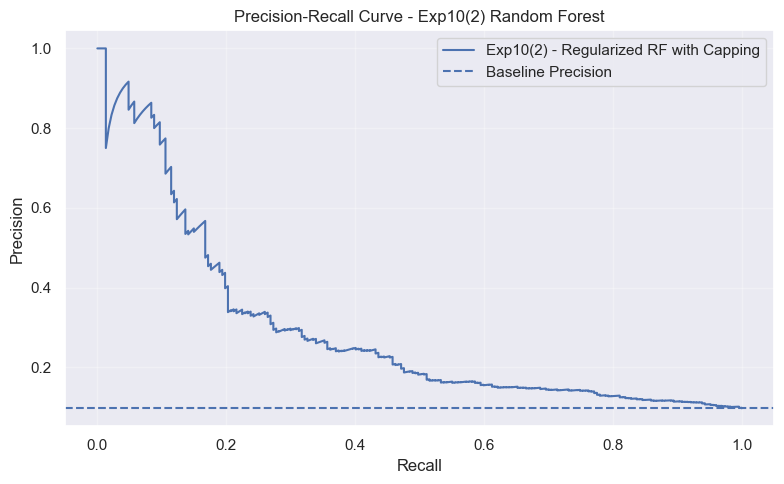


==== FINE-GRAINED THRESHOLD ANALYSIS ====
 Threshold  Precision  Recall  F1 Score
      0.05     0.1017  0.9736    0.1842
      0.06     0.1040  0.9604    0.1877
      0.07     0.1069  0.9515    0.1922
      0.08     0.1095  0.9383    0.1961
      0.09     0.1130  0.9207    0.2013
      0.10     0.1166  0.8943    0.2063
      0.11     0.1183  0.8458    0.2076
      0.12     0.1227  0.8194    0.2134
      0.13     0.1288  0.7885    0.2214
      0.14     0.1363  0.7709    0.2316
      0.15     0.1421  0.7401    0.2385
      0.16     0.1447  0.6960    0.2396
      0.17     0.1486  0.6520    0.2420
      0.18     0.1543  0.6123    0.2465
      0.19     0.1618  0.5859    0.2536
      0.20     0.1625  0.5374    0.2495
      0.21     0.1711  0.5110    0.2564
      0.22     0.1849  0.4978    0.2697
      0.23     0.1978  0.4714    0.2786
      0.24     0.2101  0.4581    0.2881
      0.25     0.2274  0.4537    0.3029
      0.26     0.2367  0.4317    0.3058
      0.27     0.2467  0.4097    0.30

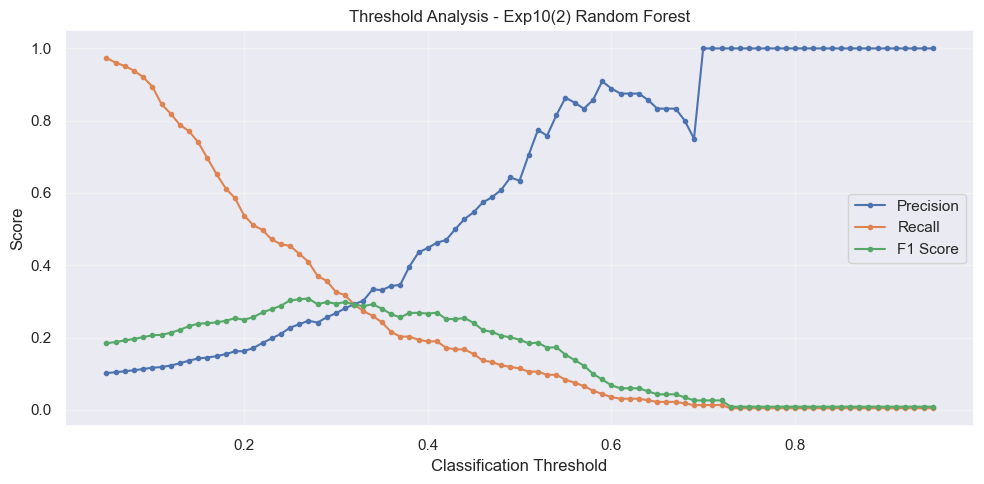


==== BEST THRESHOLD ====
Best Threshold: 0.27
Threshold    0.270000
Precision    0.246684
Recall       0.409692
F1 Score     0.307947
Name: 22, dtype: float64

==== TRAIN METRICS ====
Accuracy    : 0.9628
Precision   : 0.7229
Recall      : 1.0000
F1 Score    : 0.8392
ROC-AUC     : 0.9999
PR-AUC      : 0.9992

==== VALIDATION METRICS ====
Accuracy    : 0.8211
Precision   : 0.2467
Recall      : 0.4097
F1 Score    : 0.3079
ROC-AUC     : 0.6910
PR-AUC      : 0.2920

==== TEST METRICS ====
Accuracy    : 0.8220
Precision   : 0.2572
Recall      : 0.4401
F1 Score    : 0.3247
ROC-AUC     : 0.6910
PR-AUC      : 0.3243


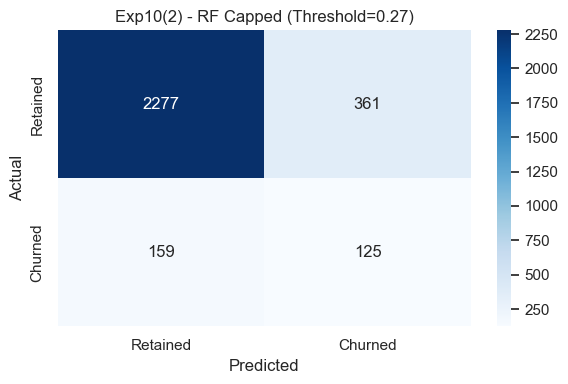


==== CLASSIFICATION REPORT ====
              precision    recall  f1-score   support

    Retained       0.93      0.86      0.90      2638
     Churned       0.26      0.44      0.32       284

    accuracy                           0.82      2922
   macro avg       0.60      0.65      0.61      2922
weighted avg       0.87      0.82      0.84      2922


==== CROSS VALIDATION TRAIN SCORES ====
train_Accuracy - Mean: 0.9994, Std: 0.0002
train_Precision - Mean: 0.9937, Std: 0.0016
train_Recall - Mean: 1.0000, Std: 0.0000
train_F1 - Mean: 0.9968, Std: 0.0008
train_ROC_AUC - Mean: 1.0000, Std: 0.0000
train_PR_AUC - Mean: 0.9998, Std: 0.0002

==== CROSS VALIDATION VALIDATION SCORES ====
test_Accuracy - Mean: 0.9068, Std: 0.0032
test_Precision - Mean: 0.6547, Std: 0.1270
test_Recall - Mean: 0.0969, Std: 0.0137
test_F1 - Mean: 0.1680, Std: 0.0223
test_ROC_AUC - Mean: 0.6843, Std: 0.0181
test_PR_AUC - Mean: 0.2698, Std: 0.0228

==== TOP 20 FEATURE IMPORTANCES ====
                   Featur

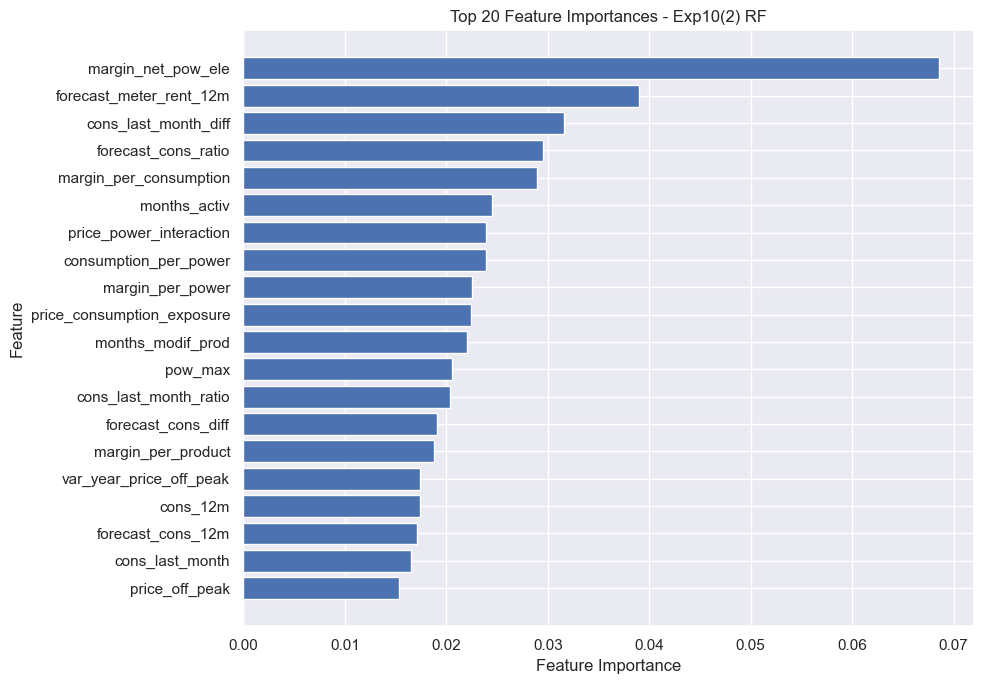


EXP10(2) - RANDOM FOREST OUTLIER TREATMENT COMPLETED

Best CV PR-AUC: 0.2698
Best Threshold: 0.27

==== FINAL TEST PERFORMANCE ====
Accuracy    : 0.8220
Precision   : 0.2572
Recall      : 0.4401
F1 Score    : 0.3247
ROC-AUC     : 0.6910
PR-AUC      : 0.3243

Total Features: 104
Number of Capped Features: 11
Model Training Rows: 9347
Validation Rows: 2337
Test Rows: 2922

Experiment completed successfully.


In [13]:

# ============================================================
# Exp 9(2) – Hyperparameter-Tuned Random Forest | Feature-Specific Outlier Capping
# ============================================================

# ============================================================
# 0. IMPORT LIBRARIES
# ============================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    RandomizedSearchCV,
    cross_validate
)
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    precision_recall_curve,
    confusion_matrix,
    classification_report
)

# ============================================================
# 1. SEPARATE FEATURES AND TARGET
# ============================================================
date_cols = [
    'date_activ',
    'date_end',
    'date_modif_prod',
    'date_renewal'
]

X = df.drop(
    columns=['id', 'churn'] + date_cols,
    errors='ignore'
).copy()

y = df['churn'].copy()

print("Dataset Shape:", X.shape)
print("\nMissing Values:", X.isna().sum().sum())
print("\n==== TARGET DISTRIBUTION ====")
print(y.value_counts())
print("\n==== TARGET PERCENTAGE ====")
print((y.value_counts(normalize=True) * 100).round(2))

# ============================================================
# 2. ORIGINAL TRAIN TEST SPLIT
# ============================================================
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nOriginal Training Shape:", X_train.shape)
print("Original Test Shape:", X_test.shape)

# ============================================================
# 3. INTERNAL TRAIN VALIDATION SPLIT
# ============================================================
X_model_train, X_val, y_model_train, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

print("\nModel Training Shape:", X_model_train.shape)
print("Validation Shape:", X_val.shape)
print("Final Test Shape:", X_test.shape)

# ============================================================
# 4. IDENTIFY NUMERICAL AND CATEGORICAL COLUMNS
# ============================================================
categorical_cols = X.select_dtypes(
    include=['object', 'category', 'bool']
).columns.tolist()

numerical_cols = X.select_dtypes(
    include=np.number
).columns.tolist()

print("\nCategorical Columns:")
print(categorical_cols)
print("\nNumber of Numerical Columns:")
print(len(numerical_cols))

# ============================================================
# 5. OUTLIER CAPPING CONFIGURATION
# ============================================================
two_sided_features = [
    'cons_last_month_diff',
    'forecast_cons_diff',
    'price_consumption_exposure'
]

upper_only_features = [
    'consumption_per_power',
    'cons_12m',
    'cons_last_month',
    'pow_max',
    'forecast_cons_year',
    'imp_cons',
    'net_margin',
    'margin_per_product'
]

# Keep only available numerical features.
two_sided_features = [
    col for col in two_sided_features
    if col in numerical_cols
]

upper_only_features = [
    col for col in upper_only_features
    if col in numerical_cols
]

print("\nTwo-Sided Capping Features:", two_sided_features)
print("Upper-Only Capping Features:", upper_only_features)

# ============================================================
# 6. CUSTOM OUTLIER CAPPING TRANSFORMER
# ============================================================
class OutlierCapper(BaseEstimator, TransformerMixin):
    def __init__(
        self,
        two_sided_features=None,
        upper_only_features=None,
        lower_quantile=0.01,
        upper_quantile=0.99
    ):
        self.two_sided_features = two_sided_features
        self.upper_only_features = upper_only_features
        self.lower_quantile = lower_quantile
        self.upper_quantile = upper_quantile

    def fit(self, X, y=None):
        self.cap_limits_ = {}

        two_sided = self.two_sided_features or []
        upper_only = self.upper_only_features or []

        for col in two_sided:
            if col in X.columns:
                self.cap_limits_[col] = {
                    'lower': X[col].quantile(self.lower_quantile),
                    'upper': X[col].quantile(self.upper_quantile)
                }

        for col in upper_only:
            if col in X.columns:
                self.cap_limits_[col] = {
                    'lower': None,
                    'upper': X[col].quantile(self.upper_quantile)
                }

        return self

    def transform(self, X):
        X = X.copy()

        for col, limits in self.cap_limits_.items():
            lower = limits['lower']
            upper = limits['upper']

            if lower is not None:
                X[col] = X[col].clip(lower=lower)

            if upper is not None:
                X[col] = X[col].clip(upper=upper)

        return X

# ============================================================
# 7. PREPROCESSING PIPELINE
# ============================================================
numerical_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median'))
])

categorical_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(
        strategy='constant',
        fill_value='__MISSING__'
    )),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numerical_pipeline, numerical_cols),
        ('cat', categorical_pipeline, categorical_cols)
    ],
    remainder='drop',
    verbose_feature_names_out=False
)

# ============================================================
# 8. REGULARIZED RANDOM FOREST PIPELINE
# ============================================================
rf_pipeline = Pipeline(steps=[
    ('capping', OutlierCapper(
        two_sided_features=two_sided_features,
        upper_only_features=upper_only_features,
        lower_quantile=0.01,
        upper_quantile=0.99
    )),
    ('preprocessing', preprocessor),
    ('model', RandomForestClassifier(
        class_weight='balanced',
        random_state=42,
        n_jobs=1
    ))
])

# ============================================================
# 9. STRATIFIED CROSS VALIDATION
# ============================================================
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# ============================================================
# 10. HYPERPARAMETER SEARCH SPACE
# ============================================================
param_grid = {
    'model__n_estimators': [200, 300, 500],
    'model__max_depth': [5, 10, 15, 20, None],
    'model__min_samples_split': [5, 10, 20, 30],
    'model__min_samples_leaf': [2, 5, 10, 15],
    'model__max_features': ['sqrt', 'log2', 0.5]
}

# ============================================================
# 11. RANDOMIZED SEARCH CV
# ============================================================
random_search = RandomizedSearchCV(
    estimator=rf_pipeline,
    param_distributions=param_grid,
    n_iter=25,
    scoring='average_precision',
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=2,
    refit=True,
    return_train_score=True
)

# ============================================================
# 12. FIT RANDOMIZED SEARCH
# ============================================================
random_search.fit(X_model_train, y_model_train)

# ============================================================
# 13. BEST HYPERPARAMETERS
# ============================================================
print("\n==== BEST HYPERPARAMETERS ====")
print(random_search.best_params_)

print("\nBest CV PR-AUC:")
print(random_search.best_score_)

# ============================================================
# 14. BEST RANDOM FOREST MODEL
# ============================================================
best_rf_pipeline = random_search.best_estimator_

# ============================================================
# 15. RANDOMIZED SEARCH RESULTS
# ============================================================
search_results_df = pd.DataFrame(random_search.cv_results_)
search_results_df = search_results_df.sort_values(
    by='mean_test_score',
    ascending=False
)

print("\n==== TOP 10 HYPERPARAMETER COMBINATIONS ====")
print(
    search_results_df[[
        'param_model__n_estimators',
        'param_model__max_depth',
        'param_model__min_samples_split',
        'param_model__min_samples_leaf',
        'param_model__max_features',
        'mean_train_score',
        'mean_test_score',
        'std_test_score'
    ]].head(10).round(4).to_string(index=False)
)

# ============================================================
# 16. APPLY FITTED OUTLIER CAPS
# ============================================================
# The selected pipeline has been refitted on all model-training
# data. Its cap limits are therefore learned from X_model_train.

capper = best_rf_pipeline.named_steps['capping']
cap_limits = capper.cap_limits_

X_model_train_capped = capper.transform(X_model_train)
X_val_capped = capper.transform(X_val)
X_test_capped = capper.transform(X_test)

# ============================================================
# 17. OUTLIER CAPPING SUMMARY
# ============================================================
cap_summary = []

for col, limits in cap_limits.items():
    cap_summary.append({
        'Feature': col,
        'Original Min': X_model_train[col].min(),
        'Capped Min': X_model_train_capped[col].min(),
        'Original Max': X_model_train[col].max(),
        'Capped Max': X_model_train_capped[col].max(),
        'Lower Limit': limits['lower'],
        'Upper Limit': limits['upper']
    })

cap_summary_df = pd.DataFrame(cap_summary)

print("\n==== OUTLIER CAPPING SUMMARY ====")
if not cap_summary_df.empty:
    print(cap_summary_df.round(3).to_string(index=False))
else:
    print("No configured capping features were found.")

print("\n==== DATA SHAPES ====")
print("Original Training:", X_model_train.shape)
print("Capped Training:", X_model_train_capped.shape)
print("Original Validation:", X_val.shape)
print("Capped Validation:", X_val_capped.shape)
print("Original Test:", X_test.shape)
print("Capped Test:", X_test_capped.shape)

print("\nMissing Values Before:", X_model_train.isna().sum().sum())
print("Missing Values After Capping:", X_model_train_capped.isna().sum().sum())

# ============================================================
# 18. VALIDATION PREDICTIONS
# ============================================================
y_prob_val = best_rf_pipeline.predict_proba(X_val)[:, 1]

# ============================================================
# 19. PRECISION-RECALL CURVE
# ============================================================
precision, recall, pr_thresholds = precision_recall_curve(
    y_val,
    y_prob_val
)

plt.figure(figsize=(8, 5))
plt.plot(
    recall,
    precision,
    label='Exp9(2) - Regularized RF with Capping'
)
plt.axhline(
    y=y_val.mean(),
    linestyle='--',
    label='Baseline Precision'
)
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve - Exp9(2) Random Forest')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# ============================================================
# 20. FINE-GRAINED THRESHOLD ANALYSIS
# ============================================================
threshold_values = np.arange(0.05, 0.951, 0.01)
threshold_results = []

for threshold in threshold_values:
    y_pred = (y_prob_val >= threshold).astype(int)

    threshold_results.append({
        'Threshold': threshold,
        'Precision': precision_score(
            y_val, y_pred, zero_division=0
        ),
        'Recall': recall_score(
            y_val, y_pred, zero_division=0
        ),
        'F1 Score': f1_score(
            y_val, y_pred, zero_division=0
        )
    })

fine_threshold_df = pd.DataFrame(threshold_results)

print("\n==== FINE-GRAINED THRESHOLD ANALYSIS ====")
print(fine_threshold_df.round(4).to_string(index=False))

# ============================================================
# 21. THRESHOLD PERFORMANCE VISUALIZATION
# ============================================================
plt.figure(figsize=(10, 5))
plt.plot(
    fine_threshold_df['Threshold'],
    fine_threshold_df['Precision'],
    marker='o',
    markersize=3,
    label='Precision'
)
plt.plot(
    fine_threshold_df['Threshold'],
    fine_threshold_df['Recall'],
    marker='o',
    markersize=3,
    label='Recall'
)
plt.plot(
    fine_threshold_df['Threshold'],
    fine_threshold_df['F1 Score'],
    marker='o',
    markersize=3,
    label='F1 Score'
)
plt.xlabel('Classification Threshold')
plt.ylabel('Score')
plt.title('Threshold Analysis - Exp9(2) Random Forest')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# ============================================================
# 22. SELECT BEST THRESHOLD
# ============================================================
best_threshold_idx = fine_threshold_df['F1 Score'].idxmax()
best_threshold = fine_threshold_df.loc[
    best_threshold_idx, 'Threshold'
]

print("\n==== BEST THRESHOLD ====")
print("Best Threshold:", round(best_threshold, 2))
print(fine_threshold_df.loc[best_threshold_idx])

# ============================================================
# 23. DEFINE METRIC FUNCTION
# ============================================================
def calculate_metrics(y_true, y_pred, y_prob):
    return {
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision': precision_score(
            y_true, y_pred, zero_division=0
        ),
        'Recall': recall_score(
            y_true, y_pred, zero_division=0
        ),
        'F1 Score': f1_score(
            y_true, y_pred, zero_division=0
        ),
        'ROC-AUC': roc_auc_score(y_true, y_prob),
        'PR-AUC': average_precision_score(y_true, y_prob)
    }

# ============================================================
# 24. TRAINING PREDICTIONS
# ============================================================
y_prob_train = best_rf_pipeline.predict_proba(X_model_train)[:, 1]
y_pred_train = (y_prob_train >= best_threshold).astype(int)

# ============================================================
# 25. VALIDATION PREDICTIONS
# ============================================================
y_pred_val = (y_prob_val >= best_threshold).astype(int)

# ============================================================
# 26. TEST PREDICTIONS
# ============================================================
y_prob_test = best_rf_pipeline.predict_proba(X_test)[:, 1]
y_pred_test = (y_prob_test >= best_threshold).astype(int)

# ============================================================
# 27. CALCULATE TRAIN, VALIDATION AND TEST METRICS
# ============================================================
train_metrics = calculate_metrics(
    y_model_train,
    y_pred_train,
    y_prob_train
)

validation_metrics = calculate_metrics(
    y_val,
    y_pred_val,
    y_prob_val
)

test_metrics = calculate_metrics(
    y_test,
    y_pred_test,
    y_prob_test
)

# ============================================================
# 28. PRINT TRAIN METRICS
# ============================================================
print("\n==== TRAIN METRICS ====")
for metric, value in train_metrics.items():
    print(f"{metric:12}: {value:.4f}")

# ============================================================
# 29. PRINT VALIDATION METRICS
# ============================================================
print("\n==== VALIDATION METRICS ====")
for metric, value in validation_metrics.items():
    print(f"{metric:12}: {value:.4f}")

# ============================================================
# 30. PRINT TEST METRICS
# ============================================================
print("\n==== TEST METRICS ====")
for metric, value in test_metrics.items():
    print(f"{metric:12}: {value:.4f}")

# ============================================================
# 31. CONFUSION MATRIX
# ============================================================
cm = confusion_matrix(y_test, y_pred_test)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Retained', 'Churned'],
    yticklabels=['Retained', 'Churned']
)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title(
    f'Exp9(2) - RF Capped '
    f'(Threshold={best_threshold:.2f})'
)
plt.tight_layout()
plt.show()

# ============================================================
# 32. CLASSIFICATION REPORT
# ============================================================
print("\n==== CLASSIFICATION REPORT ====")
print(
    classification_report(
        y_test,
        y_pred_test,
        target_names=['Retained', 'Churned'],
        zero_division=0
    )
)

# ============================================================
# 33. CROSS VALIDATION PERFORMANCE
# ============================================================
# Diagnostic CV scores for the selected hyperparameters.
# Hyperparameters were already selected using CV on this data.

scoring = {
    'Accuracy': 'accuracy',
    'Precision': 'precision',
    'Recall': 'recall',
    'F1': 'f1',
    'ROC_AUC': 'roc_auc',
    'PR_AUC': 'average_precision'
}

cv_results = cross_validate(
    best_rf_pipeline,
    X_model_train,
    y_model_train,
    scoring=scoring,
    cv=cv,
    return_train_score=True,
    n_jobs=1
)

# ============================================================
# 34. CROSS VALIDATION TRAIN SCORES
# ============================================================
print("\n==== CROSS VALIDATION TRAIN SCORES ====")
for key, value in cv_results.items():
    if key.startswith('train'):
        print(
            f"{key} - Mean: {np.mean(value):.4f}, "
            f"Std: {np.std(value):.4f}"
        )

# ============================================================
# 35. CROSS VALIDATION VALIDATION SCORES
# ============================================================
print("\n==== CROSS VALIDATION VALIDATION SCORES ====")
for key, value in cv_results.items():
    if key.startswith('test'):
        print(
            f"{key} - Mean: {np.mean(value):.4f}, "
            f"Std: {np.std(value):.4f}"
        )

# ============================================================
# 36. FEATURE IMPORTANCE
# ============================================================
rf_fitted = best_rf_pipeline.named_steps['model']

feature_names = (
    best_rf_pipeline
    .named_steps['preprocessing']
    .get_feature_names_out()
)

importances = rf_fitted.feature_importances_

feature_importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
}).sort_values(
    by='Importance',
    ascending=False
).reset_index(drop=True)

print("\n==== TOP 20 FEATURE IMPORTANCES ====")
print(
    feature_importance_df.head(20).round(5).to_string(index=False)
)

# ============================================================
# 37. FEATURE IMPORTANCE VISUALIZATION
# ============================================================
top_features = (
    feature_importance_df
    .head(20)
    .sort_values(
        by='Importance',
        ascending=True
    )
)

plt.figure(figsize=(10, 7))
plt.barh(
    top_features['Feature'],
    top_features['Importance']
)
plt.xlabel('Feature Importance')
plt.ylabel('Feature')
plt.title('Top 20 Feature Importances - Exp9(2) RF')
plt.tight_layout()
plt.show()

# ============================================================
# 38. FINAL EXPERIMENT SUMMARY
# ============================================================
test_metrics_df = pd.DataFrame(
    [test_metrics],
    index=['Exp9(2)_RF_Capped_104_Features']
)

print("\n" + "=" * 65)
print("EXP9(2) - RANDOM FOREST OUTLIER TREATMENT COMPLETED")
print("=" * 65)

print("\nBest CV PR-AUC:", round(random_search.best_score_, 4))
print("Best Threshold:", round(best_threshold, 2))
print("\n==== FINAL TEST PERFORMANCE ====")

for metric, value in test_metrics.items():
    print(f"{metric:12}: {value:.4f}")

print("\nTotal Features:", X.shape[1])
print("Number of Capped Features:", len(cap_limits))
print("Model Training Rows:", len(X_model_train))
print("Validation Rows:", len(X_val))
print("Test Rows:", len(X_test))
print("\nExperiment completed successfully.")


**Exp 9(2) – Hyperparameter-Tuned Model | Regularized Random Forest with Outlier Capping**

**1. Outlier Treatment**

- Applied outlier capping to 11 numerical features.
- Two-sided capping applied to:
  - `cons_last_month_diff`
  - `forecast_cons_diff`
  - `price_consumption_exposure`
- Upper-only capping applied to:
  - `consumption_per_power`
  - `cons_12m`
  - `cons_last_month`
  - `pow_max`
  - `forecast_cons_year`
  - `imp_cons`
  - `net_margin`
  - `margin_per_product`

**Observation:**

- Outlier capping was applied to selected features instead of removing entire records.
- Dataset size remained unchanged.
- Missing values remained unchanged after capping.
- The experiment evaluates whether limiting extreme values improves Random Forest generalization.

**2. Model Optimization**

- Applied hyperparameter tuning using 25 parameter combinations and 5-fold cross-validation.
- Used PR-AUC as the optimization metric.
- Best hyperparameters:
  - `n_estimators`: 500
  - `min_samples_split`: 5
  - `min_samples_leaf`: 5
  - `max_features`: 0.5
  - `max_depth`: None
- Best CV PR-AUC: **26.98%**

**Observation:**

- The selected configuration uses 500 trees with minimum leaf samples of 5.
- CV PR-AUC is lower than Exp8(2) (27.35%).
- Training performance remains extremely high, indicating significant overfitting.
- Outlier capping did not improve cross-validation PR-AUC.

**3. Model Performance – Test Data**

- Accuracy: **82.20%**
- Precision: **25.72%**
- Recall: **44.01%**
- F1 Score: **32.47%**
- ROC-AUC: **69.10%**
- PR-AUC: **32.43%**

**4. Threshold Analysis**

- Tested classification thresholds between 0.05 and 0.95.
- Selected threshold: **0.27**, based on the highest F1 score in the threshold analysis.
- At threshold 0.27 (threshold validation):
  - Precision: 24.67%
  - Recall: 40.97%
  - F1 Score: 30.79%
- Lower thresholds improve recall but reduce precision.
- Higher thresholds improve precision but reduce recall.

**Observation:**

- The selected threshold provides a balance between precision and recall on validation data.
- Precision increases as the threshold increases, while recall decreases.
- At higher thresholds, precision reaches 100%, but recall becomes extremely low.

**5. Confusion Matrix (Threshold = 0.27)**

- True Negatives: 2,277
- False Positives: 361
- False Negatives: 159
- True Positives: 125

**Observation:**

- Model correctly identifies 125 churn customers out of 284.
- It misses 159 actual churn customers.
- False positives remain relatively high (361).
- The model identifies a reasonable number of churn customers but still generates unnecessary retention alerts.

**6. Precision-Recall Curve**

- Baseline precision is approximately 9.72%, corresponding to the churn percentage.
- Model achieves higher precision than the baseline across much of the recall range.
- PR-AUC of 32.43% indicates reasonable churn identification capability.
- PR-AUC is lower than Exp8(2) (34.26%).

**Observation:**

- The model performs considerably better than random classification.
- Precision decreases as recall increases, indicating a trade-off between identifying more churn customers and maintaining prediction accuracy.
- Outlier capping has not improved overall PR-AUC compared to Exp8(2).

**7. Cross-Validation Results**

- Training PR-AUC: 99.98%
- Validation accuracy: 90.68%
- Validation precision: 65.47%
- Validation recall: 9.69%
- Validation F1: 16.80%
- Validation ROC-AUC: 68.43%
- Validation PR-AUC: 26.98%

**Observation:**

- Significant training-validation performance gap indicates severe overfitting.
- Training PR-AUC is almost 100%, whereas validation PR-AUC is only 26.98%.
- Validation recall is extremely low at the default 0.50 threshold.
- The model struggles to identify churn customers at the default threshold despite achieving reasonable test PR-AUC.

**8. Top 20 Important Features**

The most important features include:

- `margin_net_pow_ele`
- `forecast_meter_rent_12m`
- `cons_last_month_diff`
- `forecast_cons_ratio`
- `margin_per_consumption`
- `months_activ`
- `price_power_interaction`
- `consumption_per_power`
- `margin_per_power`
- `price_consumption_exposure`

**Observation:**

- Margin-related, consumption-related and price-related features remain important.
- `margin_net_pow_ele` continues to be the most important feature.
- Feature importance patterns are consistent with previous Random Forest experiments.
- Outlier capping has not substantially changed the dominant feature importance pattern.

**9. Model Comparison – All Experiments**

| Metric    | Exp1-Baseline RF | Exp2-Regularized RF | Exp3-Strong Reg. RF | Exp4-XGBoost | Exp5-Strong Reg. XGB | Exp6-LightGBM | Exp7-SVM | Exp8(2)-Regularized RF | Exp9(2)-Capped RF |
| --------- | ---------------- | ------------------- | ------------------- | ------------ | -------------------- | ------------- | -------- | ---------------------- | ----------------- |
| Accuracy  | 84.02%           | 87.34%              | 84.94%              | **89.39%**   | 86.69%               | 88.02%        | 82.75%   | 82.07%                 | 82.20%            |
| Precision | 26.72%           | 34.86%              | 29.26%              | **43.09%**   | 31.83%               | 36.48%        | 23.68%   | 25.71%                 | 25.72%            |
| Recall    | 36.97%           | 34.86%              | 38.73%              | 28.52%       | 32.39%               | 31.34%        | 34.86%   | **44.72%**             | 44.01%            |
| F1 Score  | 31.02%           | **34.86%**          | 33.33%              | 34.32%       | 32.11%               | 33.71%        | 28.21%   | 32.65%                 | 32.47%            |
| ROC-AUC   | **70.76%**       | 70.48%              | 69.45%              | 69.24%       | 69.58%               | 69.33%        | 66.45%   | 69.98%                 | 69.10%            |
| PR-AUC    | 32.77%           | **35.75%**          | 31.71%              | 32.15%       | 29.42%               | 32.20%        | 20.13%   | 34.26%                 | 32.43%            |
| CV PR-AUC | 25.43%           | **30.55%**          | 26.15%              | 28.42%       | 26.38%               | 28.63%        | 20.85%   | 27.35%                 | 26.98%            |

**Observation:**

- Exp9(2) achieves a test PR-AUC of 32.43%, lower than Exp8(2) (34.26%).
- Recall decreases slightly from 44.72% to 44.01%.
- F1 Score decreases from 32.65% to 32.47%.
- Precision remains almost unchanged.
- CV PR-AUC also decreases from 27.35% to 26.98%.
- Outlier capping has not provided a consistent improvement over Exp8(2).

**10. Final Conclusion – Exp 9(2) Regularized Random Forest with Outlier Capping**

- Achieves a test PR-AUC of 32.43%.
- Identifies 125 churn customers out of 284.
- Achieves 44.01% recall, which is close to Exp8(2).
- Precision remains relatively low at 25.72%.
- Significant overfitting remains despite outlier capping.
- Cross-validation PR-AUC decreased compared to Exp8(2).
- Outlier capping did not improve overall model performance.

**Best Model So Far: Exp 2 – Regularized Random Forest**

Exp2 remains the best overall model because it achieves the highest PR-AUC (35.75%) and F1 Score (34.86%), with better precision.

Exp8(2) remains a strong alternative when identifying more churn customers is the priority, achieving 44.72% recall.

Exp9(2) does not outperform Exp8(2), suggesting that the applied outlier capping has not provided additional predictive benefit.

**Important note:** CV classification metrics use the default 0.50 threshold, while validation and test metrics use the selected 0.27 threshold. Compare classification metrics cautiously.

### **Exp 9(4) – Hyperparameter-Tuned XGBoost | Feature-Specific Outlier Capping**

1. Separate features and target, excluding customer ID and raw date columns.
2. Split the data into 80% training and 20% testing using stratification.
3. Further split the training data into model training (80%) and validation (20%), keeping the test set untouched.
4. Identify numerical and categorical features for preprocessing.
5. Apply feature-specific outlier capping:
   - Two-sided capping (1st–99th percentile) for selected features.
   - Upper-only capping (99th percentile) for selected right-skewed features.
6. Create a custom OutlierCapper transformer to learn capping limits within each CV training fold and apply them to validation and test data.
7. Impute numerical missing values using the median. Impute categorical missing values with a constant and apply One-Hot Encoding (OHE).
8. Handle class imbalance using scale_pos_weight, calculated from the model training data.
9. Build an XGBoost pipeline combining outlier capping, preprocessing, and classification.
10. RandomizedSearchCV with 30 iterations and 5-Fold Stratified CV is used to tune XGBoost hyperparameters based on PR-AUC.
11. The best model generates churn probabilities on the validation set.
12. Perform fine-grained threshold analysis (0.05–0.95, with 0.01 intervals) and select the threshold with the highest F1 Score.
13. Apply the selected threshold to training, validation, and test probabilities to generate:
    0 = Retained | 1 = Churned.
14. Evaluate model performance using Accuracy, Precision, Recall, F1 Score, ROC-AUC, PR-AUC, confusion matrix, and classification report.
15. Perform diagnostic cross-validation and analyse the top 20 feature importances.
16. Display the best hyperparameters, CV PR-AUC, selected threshold, test PR-AUC, and test F1 Score.

this experiment incorporates changes to the original Exp 4 model based on outlier detection and treatment.   
Exp 9(4) as took the best-performing XGBoost Classifier model from Exp4 and carried it forward as a new experiment under Exp9

Dataset Shape: (14606, 104)

Total Missing Values: 33864

Target Distribution:
churn
0    13187
1     1419
Name: count, dtype: int64

Target Percentage:
churn
0    90.28
1     9.72
Name: proportion, dtype: float64

Original Training Data: (11684, 104)
Original Test Data: (2922, 104)

Model Training Data: (9347, 104)
Threshold Validation Data: (2337, 104)
Final Test Data: (2922, 104)

Categorical Columns:
['channel_sales', 'has_gas', 'origin_up']

Number of Numerical Columns: 101

==== OUTLIER CAPPING SUMMARY ====
                   Feature  Original Min   Capped Min  Original Max  Capped Max  Lower Limit  Upper Limit
      cons_last_month_diff   -194525.250   -17175.873    449656.000  108349.083   -17175.873   108349.083
        forecast_cons_diff  -6207018.990 -3117199.312      3534.240     -12.313 -3117199.312      -12.313
price_consumption_exposure  -2077380.985   -97701.812    481476.438    7618.340   -97701.812     7618.340
     consumption_per_power         0.000        0.000    

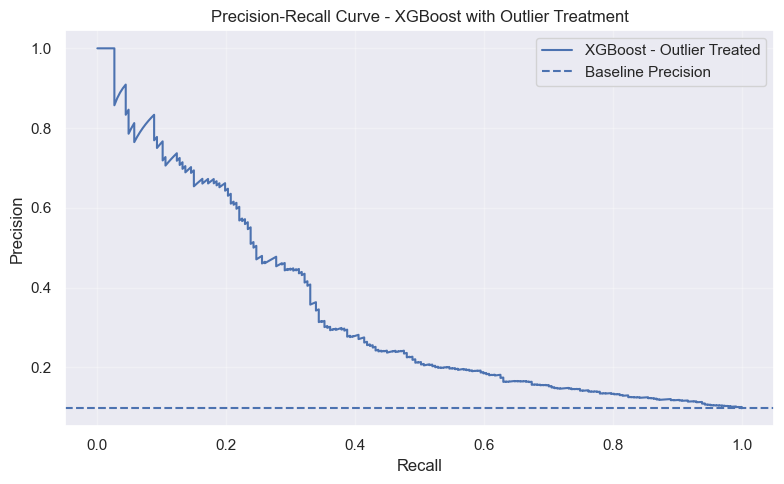


==== FINE-GRAINED THRESHOLD ANALYSIS ====
 Threshold  Precision  Recall  F1 Score
      0.05     0.1069  0.9427    0.1921
      0.06     0.1121  0.9383    0.2003
      0.07     0.1162  0.9163    0.2062
      0.08     0.1183  0.8899    0.2089
      0.09     0.1226  0.8590    0.2145
      0.10     0.1247  0.8326    0.2169
      0.11     0.1304  0.8150    0.2248
      0.12     0.1344  0.7930    0.2299
      0.13     0.1394  0.7753    0.2362
      0.14     0.1430  0.7489    0.2401
      0.15     0.1471  0.7137    0.2440
      0.16     0.1548  0.6960    0.2532
      0.17     0.1611  0.6740    0.2600
      0.18     0.1633  0.6344    0.2597
      0.19     0.1738  0.6300    0.2724
      0.20     0.1799  0.6079    0.2777
      0.21     0.1888  0.5947    0.2866
      0.22     0.1943  0.5683    0.2896
      0.23     0.2000  0.5463    0.2928
      0.24     0.2045  0.5198    0.2935
      0.25     0.2099  0.5022    0.2961
      0.26     0.2194  0.4890    0.3029
      0.27     0.2309  0.4802    0.31

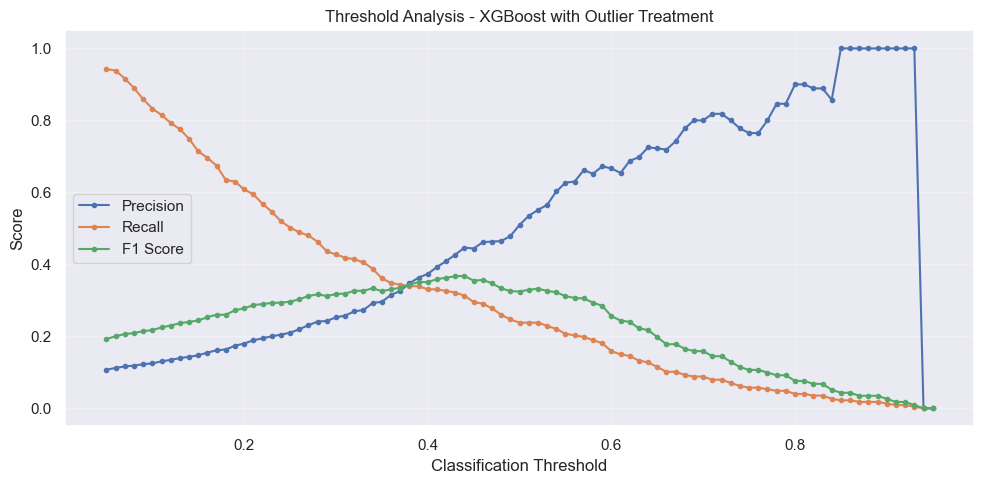


==== BEST THRESHOLD ====
Best Threshold: 0.44
Threshold    0.440000
Precision    0.446541
Recall       0.312775
F1 Score     0.367876
Name: 39, dtype: float64

==== TRAIN METRICS ====
Accuracy    : 0.9865
Precision   : 0.8966
Recall      : 0.9736
F1 Score    : 0.9335
ROC-AUC     : 0.9984
PR-AUC      : 0.9839

==== VALIDATION METRICS ====
Accuracy    : 0.8956
Precision   : 0.4465
Recall      : 0.3128
F1 Score    : 0.3679
ROC-AUC     : 0.7158
PR-AUC      : 0.3410

==== TEST METRICS ====
Accuracy    : 0.8905
Precision   : 0.4062
Recall      : 0.2746
F1 Score    : 0.3277
ROC-AUC     : 0.6866
PR-AUC      : 0.3257


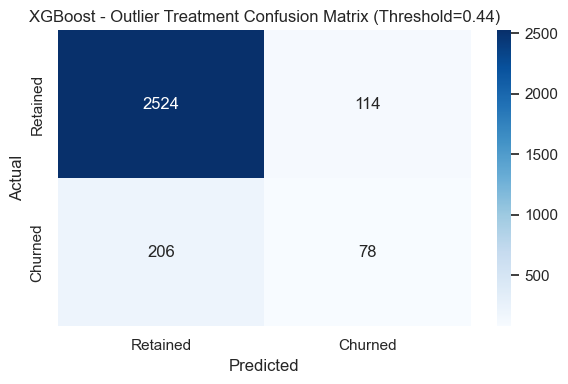


==== CLASSIFICATION REPORT ====
              precision    recall  f1-score   support

    Retained       0.92      0.96      0.94      2638
     Churned       0.41      0.27      0.33       284

    accuracy                           0.89      2922
   macro avg       0.67      0.62      0.63      2922
weighted avg       0.87      0.89      0.88      2922


==== CROSS VALIDATION TRAIN SCORES ====
train_Accuracy - Mean: 0.9928, Std: 0.0009
train_Precision - Mean: 0.9596, Std: 0.0062
train_Recall - Mean: 0.9664, Std: 0.0054
train_F1 - Mean: 0.9630, Std: 0.0048
train_ROC_AUC - Mean: 0.9993, Std: 0.0001
train_PR_AUC - Mean: 0.9930, Std: 0.0014

==== CROSS VALIDATION VALIDATION SCORES ====
test_Accuracy - Mean: 0.8976, Std: 0.0050
test_Precision - Mean: 0.4377, Std: 0.0587
test_Recall - Mean: 0.1872, Std: 0.0286
test_F1 - Mean: 0.2618, Std: 0.0369
test_ROC_AUC - Mean: 0.6884, Std: 0.0188
test_PR_AUC - Mean: 0.2814, Std: 0.0373

==== TOP 20 IMPORTANT FEATURES ====
                          

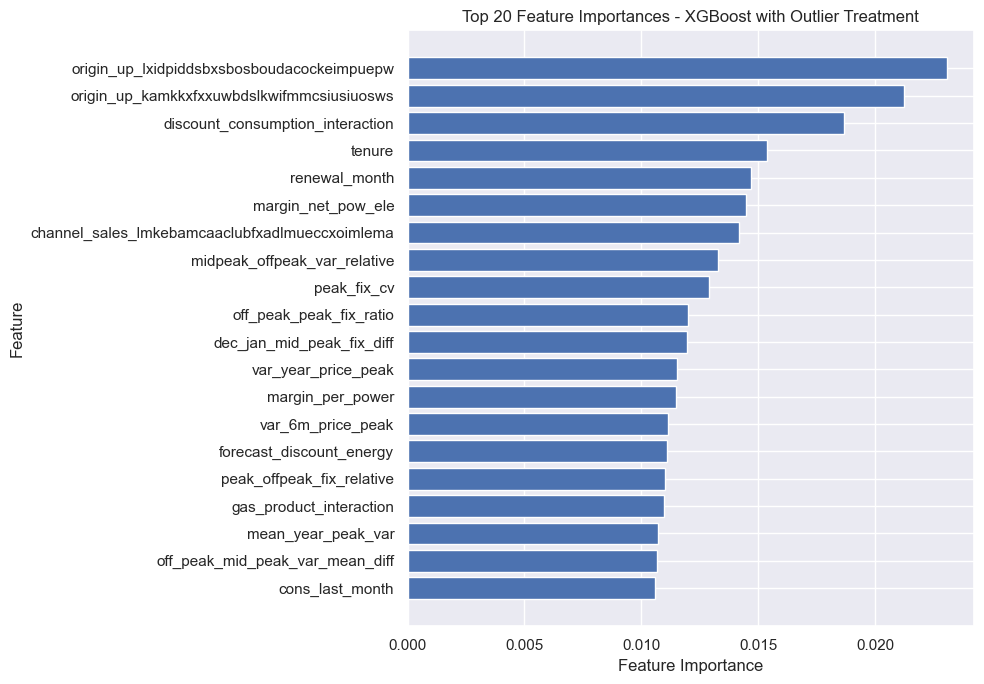


EXP 10(4) - XGBOOST OUTLIER TREATMENT COMPLETED
Best CV PR-AUC: 0.2814
Selected Threshold: 0.44
Test PR-AUC: 0.3257
Test F1: 0.3277


In [14]:

# ============================================================
# Exp 9(4) – Hyperparameter-Tuned XGBoost Classifier | Outlier Treatment (104 Features)
# ============================================================

# 0. IMPORT LIBRARIES
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from xgboost import XGBClassifier
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV, cross_validate
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, precision_recall_curve,
    confusion_matrix, classification_report
)

# 1. SEPARATE FEATURES AND TARGET
date_cols = ['date_activ', 'date_end', 'date_modif_prod', 'date_renewal']
X = df.drop(columns=['id', 'churn'] + date_cols, errors='ignore')
y = df['churn']

print("Dataset Shape:", X.shape)
print("\nTotal Missing Values:", X.isna().sum().sum())
print("\nTarget Distribution:")
print(y.value_counts())
print("\nTarget Percentage:")
print((y.value_counts(normalize=True) * 100).round(2))

# 2. ORIGINAL TRAIN TEST SPLIT
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
print("\nOriginal Training Data:", X_train.shape)
print("Original Test Data:", X_test.shape)

# 3. INTERNAL TRAIN VALIDATION SPLIT
# Test data remains untouched. Validation data is used for threshold selection.
X_fit, X_val, y_fit, y_val = train_test_split(
    X_train, y_train, test_size=0.20, random_state=21, stratify=y_train
)
print("\nModel Training Data:", X_fit.shape)
print("Threshold Validation Data:", X_val.shape)
print("Final Test Data:", X_test.shape)

# 4. IDENTIFY CATEGORICAL AND NUMERICAL COLUMNS
categorical_cols = X.select_dtypes(include=['object', 'category', 'bool']).columns.tolist()
numerical_cols = X.select_dtypes(include=np.number).columns.tolist()

print("\nCategorical Columns:")
print(categorical_cols)
print("\nNumber of Numerical Columns:", len(numerical_cols))

# 5. OUTLIER CAPPING CONFIGURATION
two_sided_features = [
    'cons_last_month_diff',
    'forecast_cons_diff',
    'price_consumption_exposure'
]
upper_only_features = [
    'consumption_per_power',
    'cons_12m',
    'cons_last_month',
    'pow_max',
    'forecast_cons_year',
    'imp_cons',
    'net_margin',
    'margin_per_product'
]

two_sided_features = [col for col in two_sided_features if col in numerical_cols]
upper_only_features = [col for col in upper_only_features if col in numerical_cols]

# 6. OUTLIER CAPPING TRANSFORMER
# Limits are learned separately inside each CV training fold.
class OutlierCapper(BaseEstimator, TransformerMixin):
    def __init__(self, two_sided_features=None, upper_only_features=None):
        self.two_sided_features = two_sided_features
        self.upper_only_features = upper_only_features

    def fit(self, X, y=None):
        self.cap_limits_ = {}
        for col in self.two_sided_features or []:
            self.cap_limits_[col] = {
                'lower': X[col].quantile(0.01),
                'upper': X[col].quantile(0.99)
            }
        for col in self.upper_only_features or []:
            self.cap_limits_[col] = {
                'lower': None,
                'upper': X[col].quantile(0.99)
            }
        return self

    def transform(self, X):
        X = X.copy()
        for col, limits in self.cap_limits_.items():
            if limits['lower'] is not None:
                X[col] = X[col].clip(lower=limits['lower'])
            if limits['upper'] is not None:
                X[col] = X[col].clip(upper=limits['upper'])
        return X

    def get_feature_names_out(self, input_features=None):
        return np.asarray(input_features, dtype=object)

# 7. OUTLIER CAPPING SUMMARY
# This summary uses X_fit only; the model pipeline independently learns
# limits within each CV fold and refits them on all X_fit.
summary_capper = OutlierCapper(
    two_sided_features=two_sided_features,
    upper_only_features=upper_only_features
)
summary_capper.fit(X_fit)
X_fit_capped_summary = summary_capper.transform(X_fit)

cap_summary = []
for col, limits in summary_capper.cap_limits_.items():
    cap_summary.append({
        'Feature': col,
        'Original Min': X_fit[col].min(),
        'Capped Min': X_fit_capped_summary[col].min(),
        'Original Max': X_fit[col].max(),
        'Capped Max': X_fit_capped_summary[col].max(),
        'Lower Limit': limits['lower'],
        'Upper Limit': limits['upper']
    })

cap_summary_df = pd.DataFrame(cap_summary)
print("\n==== OUTLIER CAPPING SUMMARY ====")
print(cap_summary_df.round(3).to_string(index=False))
print("\n==== DATA SHAPES ====")
print("Original Model Training:", X_fit.shape)
print("Capped Model Training:", X_fit_capped_summary.shape)
print("Original Validation:", X_val.shape)
print("Original Test:", X_test.shape)
print("\nMissing Values Before:", X_fit.isna().sum().sum())
print("Missing Values After:", X_fit_capped_summary.isna().sum().sum())

# 8. CLASS IMBALANCE RATIO
negative_count = (y_fit == 0).sum()
positive_count = (y_fit == 1).sum()
scale_pos_weight_value = negative_count / positive_count

print("\n==== CLASS IMBALANCE ====")
print("Negative Class:", negative_count)
print("Positive Class:", positive_count)
print("Scale Pos Weight:", round(scale_pos_weight_value, 4))

# 9. PREPROCESSING PIPELINE
numerical_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median'))
])
categorical_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='constant', fill_value='__MISSING__')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numerical_pipeline, numerical_cols),
        ('cat', categorical_pipeline, categorical_cols)
    ],
    remainder='drop',
    verbose_feature_names_out=False,
    n_jobs=1
)

# 10. XGBOOST PIPELINE
xgb_pipeline = Pipeline(steps=[
    ('outlier_capping', OutlierCapper(
        two_sided_features=two_sided_features,
        upper_only_features=upper_only_features
    )),
    ('preprocessing', preprocessor),
    ('model', XGBClassifier(
        objective='binary:logistic',
        eval_metric='aucpr',
        tree_method='hist',
        random_state=42,
        n_jobs=1,
        verbosity=0
    ))
])

# 11. STRATIFIED CROSS VALIDATION
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# 12. HYPERPARAMETER SEARCH SPACE
param_grid = {
    'model__n_estimators': [200, 300, 500, 700],
    'model__max_depth': [2, 3, 4, 5, 6],
    'model__learning_rate': [0.01, 0.03, 0.05, 0.1],
    'model__subsample': [0.7, 0.8, 0.9, 1.0],
    'model__colsample_bytree': [0.6, 0.7, 0.8, 1.0],
    'model__min_child_weight': [1, 3, 5, 7],
    'model__gamma': [0, 0.1, 0.3, 0.5],
    'model__reg_alpha': [0, 0.01, 0.1, 1],
    'model__reg_lambda': [1, 3, 5, 10],
    'model__scale_pos_weight': [
        1,
        scale_pos_weight_value * 0.5,
        scale_pos_weight_value * 0.75,
        scale_pos_weight_value
    ]
}

# 13. RANDOMIZED SEARCH CV
random_search = RandomizedSearchCV(
    estimator=xgb_pipeline,
    param_distributions=param_grid,
    n_iter=30,
    scoring='average_precision',
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=2,
    refit=True,
    return_train_score=True
)

# 14. FIT RANDOMIZED SEARCH
# Use raw X_fit. Outlier capping is performed inside the pipeline.
random_search.fit(X_fit, y_fit)

# 15. BEST HYPERPARAMETERS
print("\n==== BEST HYPERPARAMETERS ====")
print(random_search.best_params_)
print("\nBest CV PR-AUC:", round(random_search.best_score_, 4))

# 16. BEST XGBOOST MODEL
best_xgb_pipeline = random_search.best_estimator_

# 17. RANDOMIZED SEARCH RESULTS
search_results_df = pd.DataFrame(random_search.cv_results_)
search_results_df = search_results_df.sort_values(
    by='mean_test_score', ascending=False
)

print("\n==== TOP 10 HYPERPARAMETER COMBINATIONS ====")
result_cols = [
    'param_model__n_estimators',
    'param_model__max_depth',
    'param_model__learning_rate',
    'param_model__subsample',
    'param_model__colsample_bytree',
    'param_model__min_child_weight',
    'param_model__scale_pos_weight',
    'mean_train_score',
    'mean_test_score',
    'std_test_score'
]
print(search_results_df[result_cols].head(10).round(4).to_string(index=False))

# 18. VALIDATION PROBABILITIES
y_prob_val = best_xgb_pipeline.predict_proba(X_val)[:, 1]

# 19. PRECISION RECALL CURVE
precision, recall, pr_thresholds = precision_recall_curve(y_val, y_prob_val)

plt.figure(figsize=(8, 5))
plt.plot(recall, precision, label='XGBoost - Outlier Treated')
plt.axhline(y=y_val.mean(), linestyle='--', label='Baseline Precision')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve - XGBoost with Outlier Treatment')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# 20. FINE-GRAINED THRESHOLD ANALYSIS
threshold_values = np.arange(0.05, 0.951, 0.01)
threshold_results = []

for threshold in threshold_values:
    y_pred = (y_prob_val >= threshold).astype(int)
    threshold_results.append({
        'Threshold': threshold,
        'Precision': precision_score(y_val, y_pred, zero_division=0),
        'Recall': recall_score(y_val, y_pred, zero_division=0),
        'F1 Score': f1_score(y_val, y_pred, zero_division=0)
    })

fine_threshold_df = pd.DataFrame(threshold_results)
print("\n==== FINE-GRAINED THRESHOLD ANALYSIS ====")
print(fine_threshold_df.round(4).to_string(index=False))

# 21. THRESHOLD PERFORMANCE VISUALIZATION
plt.figure(figsize=(10, 5))
plt.plot(fine_threshold_df['Threshold'], fine_threshold_df['Precision'],
         marker='o', markersize=3, label='Precision')
plt.plot(fine_threshold_df['Threshold'], fine_threshold_df['Recall'],
         marker='o', markersize=3, label='Recall')
plt.plot(fine_threshold_df['Threshold'], fine_threshold_df['F1 Score'],
         marker='o', markersize=3, label='F1 Score')
plt.xlabel('Classification Threshold')
plt.ylabel('Score')
plt.title('Threshold Analysis - XGBoost with Outlier Treatment')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# 22. SELECT BEST THRESHOLD
best_threshold = fine_threshold_df.loc[
    fine_threshold_df['F1 Score'].idxmax(), 'Threshold'
]
print("\n==== BEST THRESHOLD ====")
print("Best Threshold:", round(best_threshold, 2))
print(fine_threshold_df.loc[fine_threshold_df['F1 Score'].idxmax()])

# 23. DEFINE METRIC FUNCTION
def calc_metrics(y_true, y_pred, y_prob):
    return {
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred, zero_division=0),
        'Recall': recall_score(y_true, y_pred, zero_division=0),
        'F1 Score': f1_score(y_true, y_pred, zero_division=0),
        'ROC-AUC': roc_auc_score(y_true, y_prob),
        'PR-AUC': average_precision_score(y_true, y_prob)
    }

# 24. TRAINING PREDICTIONS
y_prob_train = best_xgb_pipeline.predict_proba(X_fit)[:, 1]
y_pred_train = (y_prob_train >= best_threshold).astype(int)

# 25. VALIDATION PREDICTIONS
y_pred_val = (y_prob_val >= best_threshold).astype(int)

# 26. TEST PREDICTIONS
y_prob_test = best_xgb_pipeline.predict_proba(X_test)[:, 1]
y_pred_test = (y_prob_test >= best_threshold).astype(int)

# 27. CALCULATE METRICS
train_metrics = calc_metrics(y_fit, y_pred_train, y_prob_train)
validation_metrics = calc_metrics(y_val, y_pred_val, y_prob_val)
test_metrics = calc_metrics(y_test, y_pred_test, y_prob_test)

# 28. PRINT TRAIN METRICS
print("\n==== TRAIN METRICS ====")
for metric, value in train_metrics.items():
    print(f"{metric:12}: {value:.4f}")

# 29. PRINT VALIDATION METRICS
print("\n==== VALIDATION METRICS ====")
for metric, value in validation_metrics.items():
    print(f"{metric:12}: {value:.4f}")

# 30. PRINT TEST METRICS
print("\n==== TEST METRICS ====")
for metric, value in test_metrics.items():
    print(f"{metric:12}: {value:.4f}")

# 31. CONFUSION MATRIX
cm = confusion_matrix(y_test, y_pred_test)
plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Retained', 'Churned'],
    yticklabels=['Retained', 'Churned']
)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title(f'XGBoost - Outlier Treatment Confusion Matrix (Threshold={best_threshold:.2f})')
plt.tight_layout()
plt.show()

# 32. CLASSIFICATION REPORT
print("\n==== CLASSIFICATION REPORT ====")
print(classification_report(
    y_test,
    y_pred_test,
    target_names=['Retained', 'Churned'],
    zero_division=0
))

# 33. CROSS VALIDATION PERFORMANCE
# Diagnostic CV on the selected model; these scores are not an unbiased
# estimate because the same training partition was used during tuning.
scoring = {
    'Accuracy': 'accuracy',
    'Precision': 'precision',
    'Recall': 'recall',
    'F1': 'f1',
    'ROC_AUC': 'roc_auc',
    'PR_AUC': 'average_precision'
}

cv_results = cross_validate(
    best_xgb_pipeline,
    X_fit,
    y_fit,
    scoring=scoring,
    cv=cv,
    return_train_score=True,
    n_jobs=1
)

# 34. CROSS VALIDATION TRAIN SCORES
print("\n==== CROSS VALIDATION TRAIN SCORES ====")
for key, value in cv_results.items():
    if key.startswith('train'):
        print(f"{key} - Mean: {np.mean(value):.4f}, Std: {np.std(value):.4f}")

# 35. CROSS VALIDATION VALIDATION SCORES
print("\n==== CROSS VALIDATION VALIDATION SCORES ====")
for key, value in cv_results.items():
    if key.startswith('test'):
        print(f"{key} - Mean: {np.mean(value):.4f}, Std: {np.std(value):.4f}")

# 36. FEATURE IMPORTANCE
xgb_model = best_xgb_pipeline.named_steps['model']
feature_names = best_xgb_pipeline.named_steps['preprocessing'].get_feature_names_out()
importances = xgb_model.feature_importances_

feature_importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
}).sort_values(by='Importance', ascending=False).reset_index(drop=True)

print("\n==== TOP 20 IMPORTANT FEATURES ====")
print(feature_importance_df.head(20).round(5).to_string(index=False))

# 37. FEATURE IMPORTANCE VISUALIZATION
top_features = feature_importance_df.head(20).sort_values(
    by='Importance', ascending=True
)

plt.figure(figsize=(10, 7))
plt.barh(top_features['Feature'], top_features['Importance'])
plt.xlabel('Feature Importance')
plt.ylabel('Feature')
plt.title('Top 20 Feature Importances - XGBoost with Outlier Treatment')
plt.tight_layout()
plt.show()

# 38. SAVE EXPERIMENT RESULTS
test_metrics_df = pd.DataFrame(
    [test_metrics],
    index=['Exp9_4_XGBoost_Outlier_Treatment']
)

print("\n================================================")
print("EXP 9(4) - XGBOOST OUTLIER TREATMENT COMPLETED")
print("================================================")
print("Best CV PR-AUC:", round(random_search.best_score_, 4))
print("Selected Threshold:", round(best_threshold, 2))
print("Test PR-AUC:", round(test_metrics['PR-AUC'], 4))
print("Test F1:", round(test_metrics['F1 Score'], 4))


**Exp 9(4) – Hyperparameter-Tuned XGBoost | Feature-Specific Outlier Capping**

**1. Outlier Treatment**

- Applied feature-specific outlier capping to 11 numerical features.
- Two-sided capping applied to:
  - `cons_last_month_diff`
  - `forecast_cons_diff`
  - `price_consumption_exposure`
- Upper-only capping applied to:
  - `consumption_per_power`
  - `cons_12m`
  - `cons_last_month`
  - `pow_max`
  - `forecast_cons_year`
  - `imp_cons`
  - `net_margin`
  - `margin_per_product`

**Observation:**

- Applied outlier capping to selected numerical features instead of removing entire records.
- Dataset size remained unchanged after capping.
- Missing values remained unchanged (21,569 in model training data).
- The experiment evaluates whether limiting extreme values improves XGBoost performance and generalization.

**2. Model Optimization**

- Applied hyperparameter tuning using 30 parameter combinations and 5-fold cross-validation.
- Used PR-AUC as the optimization metric.
- Applied `scale_pos_weight` to handle class imbalance.
- Best hyperparameters:
  - `n_estimators`: 500
  - `max_depth`: 6
  - `learning_rate`: 0.03
  - `subsample`: 0.9
  - `colsample_bytree`: 1.0
  - `min_child_weight`: 3
  - `scale_pos_weight`: 4.647
  - `gamma`: 0.1
  - `reg_alpha`: 0.01
  - `reg_lambda`: 5
- Best CV PR-AUC: **28.14%**

**Observation:**

- The selected configuration uses 500 trees with a maximum depth of 6 and a learning rate of 0.03.
- Class weighting was used to give greater importance to the minority churn class.
- CV PR-AUC of 28.14% is slightly lower than Exp6 (28.63%).
- Training performance remains extremely high, indicating significant overfitting.

**3. Model Performance – Test Data**

- Accuracy: **89.05%**
- Precision: **40.62%**
- Recall: **27.46%**
- F1 Score: **32.77%**
- ROC-AUC: **68.66%**
- PR-AUC: **32.57%**

**4. Threshold Analysis**

- Tested classification thresholds between 0.05 and 0.95.
- Selected threshold: **0.44**, based on the highest F1 score in the threshold analysis.
- At threshold 0.44 (threshold validation):
  - Precision: 44.65%
  - Recall: 31.28%
  - F1 Score: 36.79%
- Lower thresholds improve recall but reduce precision.
- Higher thresholds improve precision but reduce recall.

**Observation:**

- The selected threshold provides a better balance between precision and recall on validation data.
- Precision increases as the threshold increases, while recall decreases.
- The threshold of 0.44 prioritizes better precision while retaining a reasonable level of recall.

**5. Confusion Matrix (Threshold = 0.44)**

- True Negatives: 2,524
- False Positives: 114
- False Negatives: 206
- True Positives: 78

**Observation:**

- Model correctly identifies 78 churn customers out of 284.
- It misses 206 actual churn customers.
- False positives are relatively low (114).
- The model is effective at avoiding unnecessary churn alerts but misses a large proportion of actual churn customers.
- Recall remains a major limitation.

**6. Precision-Recall Curve**

- Baseline precision is approximately 9.72%, corresponding to the churn percentage.
- Model achieves higher precision than the baseline across much of the recall range.
- PR-AUC of 32.57% indicates reasonable churn identification capability.

**Observation:**

- The model performs better than random classification.
- Precision decreases as recall increases, indicating a trade-off between identifying more churn customers and maintaining prediction accuracy.
- Despite reasonable PR-AUC, the selected threshold produces relatively low recall.

**7. Cross-Validation Results**

- Training PR-AUC: 99.30%
- Validation accuracy: 89.76%
- Validation precision: 43.77%
- Validation recall: 18.72%
- Validation F1: 26.18%
- Validation ROC-AUC: 68.84%
- Validation PR-AUC: 28.14%

**Observation:**

- Significant training-validation performance gap indicates overfitting.
- Training PR-AUC is 99.30%, whereas validation PR-AUC is only 28.14%.
- Validation recall is low at the default 0.50 threshold.
- The model struggles to identify churn customers consistently despite achieving reasonable precision.

**8. Top 20 Important Features**

The most important features include:

- `origin_up_lxidpiddsbxsbosboudacockeimpuepw`
- `origin_up_kamkkxfxxuwbdslkwifmmcsiusiuosws`
- `discount_consumption_interaction`
- `tenure`
- `renewal_month`
- `margin_net_pow_ele`
- `channel_sales_lmkebamcaaclubfxadlmueccxoimlema`
- `midpeak_offpeak_var_relative`
- `peak_fix_cv`
- `off_peak_peak_fix_ratio`

**Observation:**

- Customer origin and channel-related features have high importance.
- Newly engineered features such as `discount_consumption_interaction` and `midpeak_offpeak_var_relative` contribute to predictions.
- `tenure` and `renewal_month` are also important.
- Feature importance differs from earlier Random Forest experiments, indicating that XGBoost uses a different combination of customer, pricing and consumption patterns.

**9. Model Comparison – All Experiments**

| Metric    | Exp1-Baseline RF | Exp2-Regularized RF | Exp3-Strong Reg. RF | Exp4-XGBoost | Exp5-Strong Reg. XGB | Exp6-LightGBM | Exp7-SVM | Exp8(2)-RF | Exp9(2)-Capped RF | Exp9(4)-Capped XGB |
| --------- | ---------------- | ------------------- | ------------------- | ------------ | -------------------- | ------------- | -------- | ---------- | ----------------- | ------------------ |
| Accuracy  | 84.02%           | 87.34%              | 84.94%              | **89.39%**   | 86.69%               | 88.02%        | 82.75%   | 82.07%     | 82.20%            | 89.05%             |
| Precision | 26.72%           | 34.86%              | 29.26%              | **43.09%**   | 31.83%               | 36.48%        | 23.68%   | 25.71%     | 25.72%            | 40.62%             |
| Recall    | 36.97%           | 34.86%              | 38.73%              | 28.52%       | 32.39%               | 31.34%        | 34.86%   | **44.72%** | 44.01%            | 27.46%             |
| F1 Score  | 31.02%           | **34.86%**          | 33.33%              | 34.32%       | 32.11%               | 33.71%        | 28.21%   | 32.65%     | 32.47%            | 32.77%             |
| ROC-AUC   | **70.76%**       | 70.48%              | 69.45%              | 69.24%       | 69.58%               | 69.33%        | 66.45%   | 69.98%     | 69.10%            | 68.66%             |
| PR-AUC    | 32.77%           | **35.75%**          | 31.71%              | 32.15%       | 29.42%               | 32.20%        | 20.13%   | 34.26%     | 32.43%            | 32.57%             |
| CV PR-AUC | 25.43%           | **30.55%**          | 26.15%              | 28.42%       | 26.38%               | 28.63%        | 20.85%   | 27.35%     | 26.98%            | 28.14%             |

**Observation:**

- Exp9(4) achieves the second-highest test accuracy (89.05%) and precision (40.62%) among all experiments.
- Test PR-AUC is 32.57%, slightly higher than Exp4-XGBoost (32.15%).
- However, its recall is only 27.46%, which is lower than most previous experiments.
- It generates only 114 false positives, considerably fewer than Exp8(2) and Exp9(2).
- Its CV PR-AUC (28.14%) is lower than Exp6 (28.63%) and Exp4 (28.42%).
- Outlier capping has not produced a consistent improvement in overall churn prediction performance.

**10. Final Conclusion – Exp 9(4) XGBoost with Feature-Specific Outlier Capping**

- Achieves a test PR-AUC of 32.57%.
- Precision improves to 40.62%, indicating better reliability when predicting churn.
- Correctly identifies 78 churn customers out of 284.
- Generates only 114 false positives.
- However, recall is relatively low at 27.46%, missing 206 actual churn customers.
- Significant overfitting remains despite outlier treatment.
- Outlier capping has not substantially improved overall predictive performance.

**Best Model So Far: Exp 2 – Regularized Random Forest**

Exp2 remains the best overall model because it achieves the highest PR-AUC (35.75%) and F1 Score (34.86%).

Exp9(4) is an alternative when reducing false positives and improving precision are important. However, its low recall makes it less suitable when identifying as many potential churn customers as possible is the priority.

**Important note:** CV classification metrics use the default 0.50 threshold, while validation and test metrics use the selected 0.44 threshold. Compare classification metrics cautiously.

# **Exp 10(2) – Hyperparameter-Tuned Random Forest | Feature-Specific Outlier Capping & Targeted Median Imputation**

1. Separate features and target, excluding customer ID and raw date columns. Replace infinite values with NaN.
2. Split the data into 64% training, 16% validation, and 20% testing using stratification.
3. Identify numerical and categorical features for preprocessing.
4. Select four high-missing numerical features for targeted median imputation:
   - mid_peak_fix_cv
   - peak_fix_cv
   - mid_peak_var_cv
   - peak_var_cv
5. Apply feature-specific outlier capping:
   - Two-sided capping (1st–99th percentile) for selected features.
   - Upper-only capping (99th percentile) for selected right-skewed features.
6. Create a custom OutlierCapper transformer to learn capping limits from training data and apply them within each CV fold.
7. Apply separate median imputation pipelines for the four high-missing features and the remaining numerical features.
8. Impute categorical missing values using the most frequent value and apply One-Hot Encoding (OHE).
9. Handle class imbalance using class_weight='balanced' in Random Forest.
10. RandomizedSearchCV with 25 iterations and 5-Fold Stratified CV is used to tune Random Forest hyperparameters based on PR-AUC.
11. Extract and display the median values used for imputing the four selected features.
12. Generate validation probabilities and perform fine-grained threshold analysis (0.05–0.95, with 0.01 intervals).
13. Select the threshold with the highest validation F1 Score.
14. Apply the selected threshold to training, validation, and test probabilities to generate:
    0 = Retained | 1 = Churned.
15. Evaluate model performance using Accuracy, Precision, Recall, F1 Score, ROC-AUC, PR-AUC, confusion matrix, and classification report.
16. Analyse and visualize the top 20 feature importances.
17. Display the imputed columns, best CV PR-AUC, selected threshold, test PR-AUC, and test F1 Score.

this experiment incorporates changes to the original Exp 2 model based on median imputation    
Exp 11(2) as took the best-performing Random Forest model from Exp2 and carried it forward as a new experiment under Exp11

Dataset Shape: (14606, 104)
Total Missing Values: 33864

Target Distribution:
churn
0    13187
1     1419
Name: count, dtype: int64

Target Percentage:
churn
0    90.28
1     9.72
Name: proportion, dtype: float64

Split Sizes:
Model Training: (9347, 104)
Validation: (2337, 104)
Test: (2922, 104)

Categorical Columns:
['channel_sales', 'has_gas', 'origin_up']

Number of Numerical Columns: 101

Four High-Missing Features:
['mid_peak_fix_cv', 'peak_fix_cv', 'mid_peak_var_cv', 'peak_var_cv']

Missing Counts Before Imputation:
mid_peak_fix_cv    5730
peak_fix_cv        5730
mid_peak_var_cv    5722
peak_var_cv        4066
dtype: int64

==== OUTLIER CAPPING SUMMARY ====
                   Feature  Original Min   Capped Min  Original Max  Capped Max  Lower Limit  Upper Limit
      cons_last_month_diff   -194525.250   -19883.990    449656.000  108516.213   -19883.990   108516.213
        forecast_cons_diff  -6207018.990 -3114341.674      1690.100     -26.706 -3114341.674      -26.706
price_cons

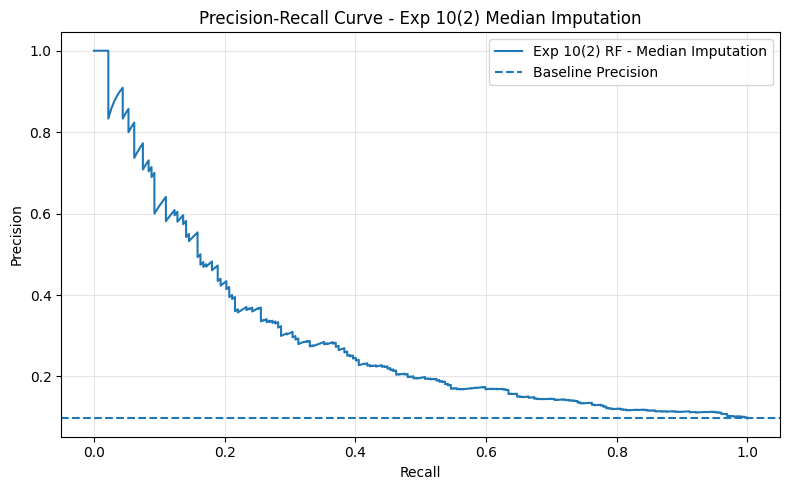


==== VALIDATION THRESHOLD ANALYSIS ====
 Threshold  Precision  Recall  F1 Score
      0.05     0.1019  0.9780    0.1846
      0.06     0.1049  0.9692    0.1893
      0.07     0.1078  0.9604    0.1938
      0.08     0.1115  0.9559    0.1996
      0.09     0.1124  0.9119    0.2002
      0.10     0.1143  0.8722    0.2020
      0.11     0.1180  0.8414    0.2069
      0.12     0.1198  0.7930    0.2081
      0.13     0.1268  0.7797    0.2181
      0.14     0.1352  0.7621    0.2296
      0.15     0.1402  0.7313    0.2353
      0.16     0.1444  0.6872    0.2387
      0.17     0.1502  0.6564    0.2445
      0.18     0.1589  0.6344    0.2542
      0.19     0.1691  0.6123    0.2650
      0.20     0.1687  0.5551    0.2587
      0.21     0.1811  0.5419    0.2715
      0.22     0.1928  0.5198    0.2813
      0.23     0.1982  0.4802    0.2806
      0.24     0.2134  0.4626    0.2921
      0.25     0.2249  0.4449    0.2988
      0.26     0.2306  0.4185    0.2973
      0.27     0.2401  0.4009    0.3003

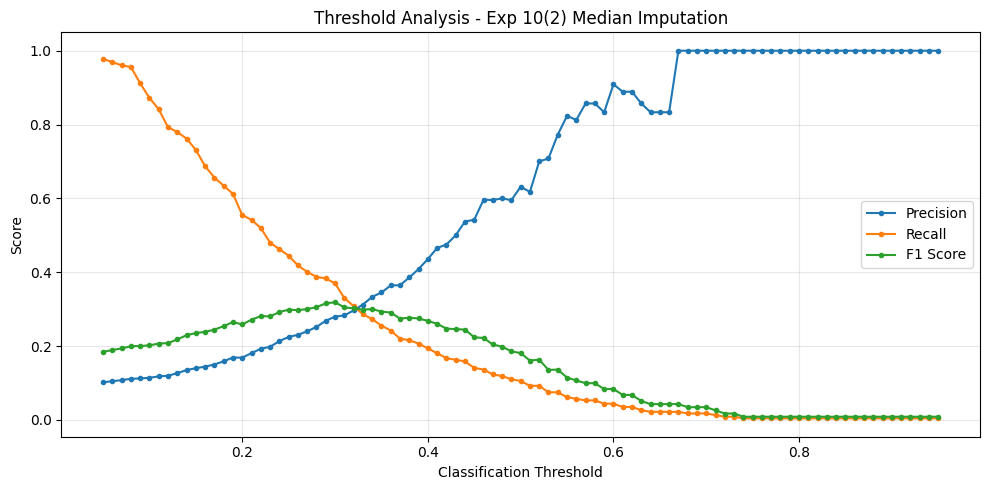


==== SELECTED VALIDATION THRESHOLD ====
Threshold: 0.30
Threshold    0.300000
Precision    0.280000
Recall       0.370044
F1 Score     0.318786
Name: 25, dtype: float64

==== TRAIN METRICS ====
Accuracy    : 0.9759
Precision   : 0.8014
Recall      : 1.0000
F1 Score    : 0.8898
ROC-AUC     : 1.0000
PR-AUC      : 0.9996

==== VALIDATION METRICS ====
Accuracy    : 0.8464
Precision   : 0.2800
Recall      : 0.3700
F1 Score    : 0.3188
ROC-AUC     : 0.6943
PR-AUC      : 0.2922

==== TEST METRICS ====
Accuracy    : 0.8480
Precision   : 0.2849
Recall      : 0.3732
F1 Score    : 0.3232
ROC-AUC     : 0.6923
PR-AUC      : 0.3275


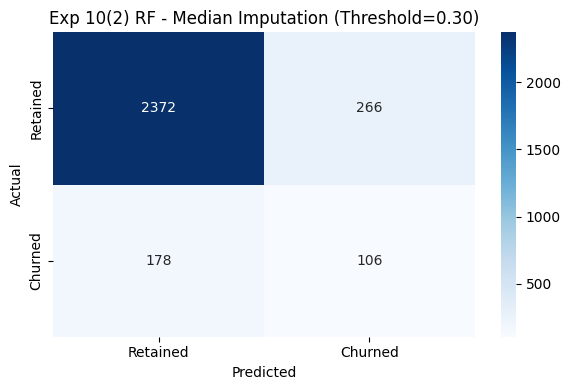


==== TEST CLASSIFICATION REPORT ====
              precision    recall  f1-score   support

    Retained       0.93      0.90      0.91      2638
     Churned       0.28      0.37      0.32       284

    accuracy                           0.85      2922
   macro avg       0.61      0.64      0.62      2922
weighted avg       0.87      0.85      0.86      2922


==== TOP 20 FEATURE IMPORTANCES ====
                   Feature  Importance
        margin_net_pow_ele     0.06921
   forecast_meter_rent_12m     0.03948
      cons_last_month_diff     0.03162
       forecast_cons_ratio     0.02980
    margin_per_consumption     0.02822
              months_activ     0.02509
   price_power_interaction     0.02430
     consumption_per_power     0.02382
          margin_per_power     0.02264
price_consumption_exposure     0.02224
                   pow_max     0.02110
         months_modif_prod     0.02109
     cons_last_month_ratio     0.02068
        forecast_cons_diff     0.01896
        marg

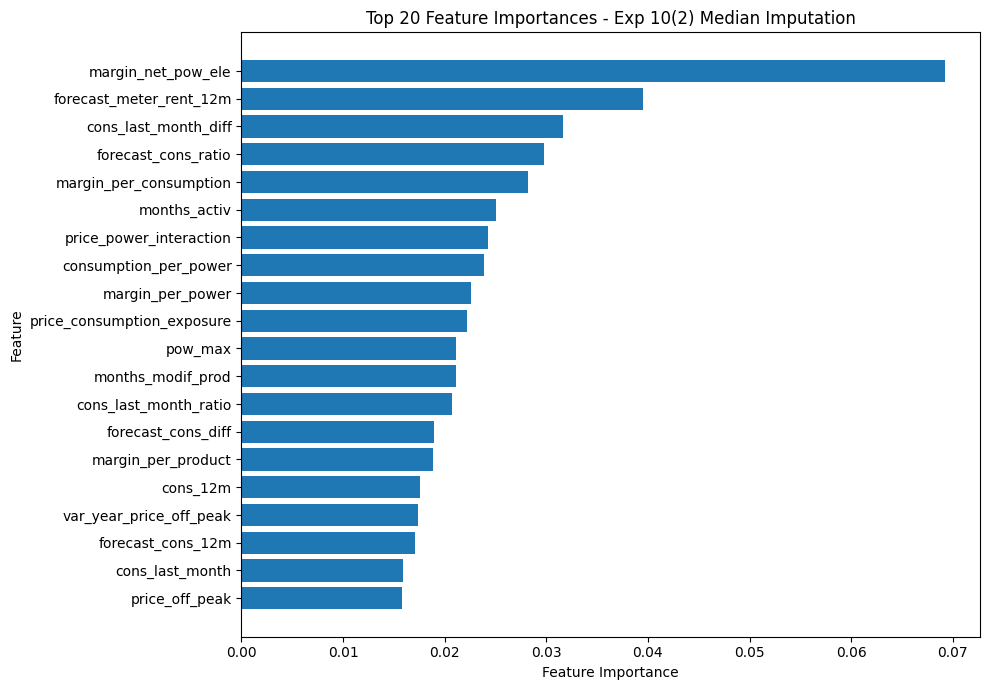


EXP 10(2) - MEDIAN IMPUTATION COMPLETED
Imputed Columns: ['mid_peak_fix_cv', 'peak_fix_cv', 'mid_peak_var_cv', 'peak_var_cv']
Best CV PR-AUC: 0.2706
Selected Threshold: 0.3
Test PR-AUC: 0.3275
Test F1: 0.3232


In [6]:

# ============================================================
# Exp 10(2) – Hyperparameter-Tuned Random Forest | Feature-Specific Outlier Capping & Targeted Median Imputation
# ============================================================

# 0. IMPORT LIBRARIES
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, precision_recall_curve,
    confusion_matrix, classification_report
)

# 1. FEATURES AND TARGET
date_cols = ['date_activ', 'date_end', 'date_modif_prod', 'date_renewal']
drop_cols = ['id', 'churn'] + [col for col in date_cols if col in df.columns]

X = df.drop(columns=drop_cols, errors='ignore').copy()
y = df['churn'].astype(int).copy()
X = X.replace([np.inf, -np.inf], np.nan)

print("Dataset Shape:", X.shape)
print("Total Missing Values:", int(X.isna().sum().sum()))
print("\nTarget Distribution:")
print(y.value_counts().sort_index())
print("\nTarget Percentage:")
print((y.value_counts(normalize=True).sort_index() * 100).round(2))

# 2. TRAIN / VALIDATION / TEST SPLITS
# 64% training, 16% validation, 20% test
X_train_full, X_test, y_train_full, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

X_model_train, X_val, y_model_train, y_val = train_test_split(
    X_train_full, y_train_full, test_size=0.20,
    random_state=42, stratify=y_train_full
)

print("\nSplit Sizes:")
print("Model Training:", X_model_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

# 3. FEATURE TYPES
categorical_cols = X.select_dtypes(
    include=['object', 'category', 'bool']
).columns.tolist()

numerical_cols = X.select_dtypes(include=[np.number]).columns.tolist()

print("\nCategorical Columns:")
print(categorical_cols)
print("\nNumber of Numerical Columns:", len(numerical_cols))

# 4. FOUR HIGH-MISSING NUMERIC FEATURES
high_missing_features = [
    'mid_peak_fix_cv',
    'peak_fix_cv',
    'mid_peak_var_cv',
    'peak_var_cv'
]
high_missing_features = [
    col for col in high_missing_features
    if col in X_model_train.columns
]

non_numeric_targets = [
    col for col in high_missing_features
    if col not in numerical_cols
]
if non_numeric_targets:
    raise ValueError(
        f"Requested median-imputation features are not numeric: {non_numeric_targets}"
    )

other_numerical_cols = [
    col for col in numerical_cols
    if col not in high_missing_features
]

print("\nFour High-Missing Features:")
print(high_missing_features)
print("\nMissing Counts Before Imputation:")
print(X_model_train[high_missing_features].isna().sum())

# 5. OUTLIER CAPPING CONFIGURATION
two_sided_features = [
    'cons_last_month_diff',
    'forecast_cons_diff',
    'price_consumption_exposure'
]

upper_only_features = [
    'consumption_per_power',
    'cons_12m',
    'cons_last_month',
    'pow_max',
    'forecast_cons_year',
    'imp_cons',
    'net_margin',
    'margin_per_product'
]

two_sided_features = [
    col for col in two_sided_features if col in numerical_cols
]
upper_only_features = [
    col for col in upper_only_features if col in numerical_cols
]

# 6. OUTLIER CAPPING TRANSFORMER
# Limits are learned only from each training fold during CV.
class OutlierCapper(BaseEstimator, TransformerMixin):
    def __init__(self, two_sided_features=None, upper_only_features=None):
        self.two_sided_features = two_sided_features
        self.upper_only_features = upper_only_features

    def fit(self, X, y=None):
        self.cap_limits_ = {}
        for col in self.two_sided_features or []:
            self.cap_limits_[col] = {
                'lower': X[col].quantile(0.01),
                'upper': X[col].quantile(0.99)
            }
        for col in self.upper_only_features or []:
            self.cap_limits_[col] = {
                'lower': None,
                'upper': X[col].quantile(0.99)
            }
        return self

    def transform(self, X):
        X = X.copy()
        for col, limits in self.cap_limits_.items():
            if limits['lower'] is not None:
                X[col] = X[col].clip(lower=limits['lower'])
            if limits['upper'] is not None:
                X[col] = X[col].clip(upper=limits['upper'])
        return X

    def get_feature_names_out(self, input_features=None):
        return np.asarray(input_features, dtype=object)

# 7. OUTLIER CAPPING SUMMARY
# This summary is calculated from model-training data only.
summary_capper = OutlierCapper(
    two_sided_features=two_sided_features,
    upper_only_features=upper_only_features
)
summary_capper.fit(X_model_train)
X_model_train_capped_summary = summary_capper.transform(X_model_train)

cap_summary = []
for col, limits in summary_capper.cap_limits_.items():
    cap_summary.append({
        'Feature': col,
        'Original Min': X_model_train[col].min(),
        'Capped Min': X_model_train_capped_summary[col].min(),
        'Original Max': X_model_train[col].max(),
        'Capped Max': X_model_train_capped_summary[col].max(),
        'Lower Limit': limits['lower'],
        'Upper Limit': limits['upper']
    })

cap_summary_df = pd.DataFrame(cap_summary)
print("\n==== OUTLIER CAPPING SUMMARY ====")
print(cap_summary_df.round(3).to_string(index=False))

print("\nMissing Values Before Imputation:")
print("Training:", int(X_model_train_capped_summary.isna().sum().sum()))
print("Validation:", int(summary_capper.transform(X_val).isna().sum().sum()))
print("Test:", int(summary_capper.transform(X_test).isna().sum().sum()))

# 8. PREPROCESSING PIPELINES
# Separate median imputer for the four high-missing features.
high_missing_numeric_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median', keep_empty_features=True))
])

other_numeric_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median', keep_empty_features=True))
])

categorical_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

transformers = [
    ('high_missing_median', high_missing_numeric_pipeline, high_missing_features),
    ('other_numeric_median', other_numeric_pipeline, other_numerical_cols),
    ('categorical', categorical_pipeline, categorical_cols)
]

preprocessor = ColumnTransformer(
    transformers=transformers,
    remainder='drop',
    verbose_feature_names_out=False
)

# 9. RANDOM FOREST PIPELINE
rf_pipeline = Pipeline(steps=[
    ('outlier_capping', OutlierCapper(
        two_sided_features=two_sided_features,
        upper_only_features=upper_only_features
    )),
    ('preprocessing', preprocessor),
    ('model', RandomForestClassifier(
        class_weight='balanced',
        random_state=42,
        n_jobs=1
    ))
])

# 10. STRATIFIED CROSS VALIDATION
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# 11. HYPERPARAMETER SEARCH SPACE
param_grid = {
    'model__n_estimators': [300, 500, 700],
    'model__max_depth': [None, 10, 15, 20],
    'model__min_samples_split': [5, 10, 20, 30],
    'model__min_samples_leaf': [2, 5, 10, 15],
    'model__max_features': ['sqrt', 'log2', 0.3, 0.5],
    'model__class_weight': ['balanced', 'balanced_subsample']
}

# 12. RANDOMIZED SEARCH CV
random_search = RandomizedSearchCV(
    estimator=rf_pipeline,
    param_distributions=param_grid,
    n_iter=25,
    scoring='average_precision',
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=2,
    refit=True,
    return_train_score=True
)

# 13. FIT RANDOMIZED SEARCH
# Raw training data is passed; capping and preprocessing happen inside CV.
random_search.fit(X_model_train, y_model_train)

# 14. BEST HYPERPARAMETERS
print("\n==== BEST HYPERPARAMETERS ====")
print(random_search.best_params_)
print("\nBest CV PR-AUC:", round(random_search.best_score_, 4))

# 15. BEST RANDOM FOREST MODEL
best_rf_pipeline = random_search.best_estimator_

# 16. RANDOMIZED SEARCH RESULTS
search_results_df = pd.DataFrame(random_search.cv_results_)
search_results_df = search_results_df.sort_values(
    by='mean_test_score', ascending=False
)

result_cols = [
    'param_model__n_estimators',
    'param_model__max_depth',
    'param_model__min_samples_split',
    'param_model__min_samples_leaf',
    'param_model__max_features',
    'param_model__class_weight',
    'mean_train_score',
    'mean_test_score',
    'std_test_score'
]

print("\n==== TOP 10 HYPERPARAMETER COMBINATIONS ====")
print(search_results_df[result_cols].head(10).round(4).to_string(index=False))

# 17. MEDIAN IMPUTATION VALUES
fitted_preprocessor = best_rf_pipeline.named_steps['preprocessing']

if high_missing_features:
    fitted_high_missing_imputer = (
        fitted_preprocessor
        .named_transformers_['high_missing_median']
        .named_steps['imputer']
    )
    median_values = pd.Series(
        fitted_high_missing_imputer.statistics_,
        index=high_missing_features,
        name='Training_Median_Used'
    )
    print("\n==== MEDIAN VALUES USED ====")
    print(median_values)

# 18. VALIDATION PROBABILITIES
y_prob_val = best_rf_pipeline.predict_proba(X_val)[:, 1]

# 19. PRECISION-RECALL CURVE
precision_curve, recall_curve, _ = precision_recall_curve(
    y_val, y_prob_val
)

plt.figure(figsize=(8, 5))
plt.plot(
    recall_curve, precision_curve,
    label='Exp 10(2) RF - Median Imputation'
)
plt.axhline(
    y=y_val.mean(),
    linestyle='--',
    label='Baseline Precision'
)
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve - Exp 10(2) Median Imputation')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# 20. VALIDATION THRESHOLD ANALYSIS
threshold_values = np.arange(0.05, 0.951, 0.01)
threshold_rows = []

for threshold in threshold_values:
    y_pred = (y_prob_val >= threshold).astype(int)
    threshold_rows.append({
        'Threshold': threshold,
        'Precision': precision_score(y_val, y_pred, zero_division=0),
        'Recall': recall_score(y_val, y_pred, zero_division=0),
        'F1 Score': f1_score(y_val, y_pred, zero_division=0)
    })

threshold_df = pd.DataFrame(threshold_rows)

print("\n==== VALIDATION THRESHOLD ANALYSIS ====")
print(threshold_df.round(4).to_string(index=False))

plt.figure(figsize=(10, 5))
plt.plot(
    threshold_df['Threshold'], threshold_df['Precision'],
    marker='o', markersize=3, label='Precision'
)
plt.plot(
    threshold_df['Threshold'], threshold_df['Recall'],
    marker='o', markersize=3, label='Recall'
)
plt.plot(
    threshold_df['Threshold'], threshold_df['F1 Score'],
    marker='o', markersize=3, label='F1 Score'
)
plt.xlabel('Classification Threshold')
plt.ylabel('Score')
plt.title('Threshold Analysis - Exp 10(2) Median Imputation')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# 21. SELECT BEST THRESHOLD
best_row = threshold_df.loc[threshold_df['F1 Score'].idxmax()]
best_threshold = float(best_row['Threshold'])

print("\n==== SELECTED VALIDATION THRESHOLD ====")
print(f"Threshold: {best_threshold:.2f}")
print(best_row)

# 22. PREDICTIONS
y_prob_train = best_rf_pipeline.predict_proba(X_model_train)[:, 1]
y_prob_test = best_rf_pipeline.predict_proba(X_test)[:, 1]

y_pred_train = (y_prob_train >= best_threshold).astype(int)
y_pred_val = (y_prob_val >= best_threshold).astype(int)
y_pred_test = (y_prob_test >= best_threshold).astype(int)

# 23. METRIC FUNCTION
def calculate_metrics(y_true, y_pred, y_prob):
    return {
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred, zero_division=0),
        'Recall': recall_score(y_true, y_pred, zero_division=0),
        'F1 Score': f1_score(y_true, y_pred, zero_division=0),
        'ROC-AUC': roc_auc_score(y_true, y_prob),
        'PR-AUC': average_precision_score(y_true, y_prob)
    }

train_metrics = calculate_metrics(y_model_train, y_pred_train, y_prob_train)
validation_metrics = calculate_metrics(y_val, y_pred_val, y_prob_val)
test_metrics = calculate_metrics(y_test, y_pred_test, y_prob_test)

# 24. PRINT METRICS
def print_metrics(title, metrics):
    print(f"\n==== {title} ====")
    for metric, value in metrics.items():
        print(f"{metric:12}: {value:.4f}")

print_metrics('TRAIN METRICS', train_metrics)
print_metrics('VALIDATION METRICS', validation_metrics)
print_metrics('TEST METRICS', test_metrics)

# 25. TEST CONFUSION MATRIX
cm = confusion_matrix(y_test, y_pred_test)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Retained', 'Churned'],
    yticklabels=['Retained', 'Churned']
)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title(f'Exp 10(2) RF - Median Imputation (Threshold={best_threshold:.2f})')
plt.tight_layout()
plt.show()

# 26. TEST CLASSIFICATION REPORT
print("\n==== TEST CLASSIFICATION REPORT ====")
print(classification_report(
    y_test,
    y_pred_test,
    target_names=['Retained', 'Churned'],
    zero_division=0
))

# 27. FEATURE IMPORTANCE
rf_fitted = best_rf_pipeline.named_steps['model']
feature_names = fitted_preprocessor.get_feature_names_out()

feature_importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': rf_fitted.feature_importances_
}).sort_values(
    'Importance', ascending=False
).reset_index(drop=True)

print("\n==== TOP 20 FEATURE IMPORTANCES ====")
print(feature_importance_df.head(20).round(5).to_string(index=False))

# 28. FEATURE IMPORTANCE VISUALIZATION
top_features = feature_importance_df.head(20).sort_values(
    'Importance', ascending=True
)

plt.figure(figsize=(10, 7))
plt.barh(top_features['Feature'], top_features['Importance'])
plt.xlabel('Feature Importance')
plt.ylabel('Feature')
plt.title('Top 20 Feature Importances - Exp 10(2) Median Imputation')
plt.tight_layout()
plt.show()

# 29. FINAL EXPERIMENT SUMMARY
test_metrics_df = pd.DataFrame(
    [test_metrics],
    index=['Exp10_2_RF_Median_Imputation']
)

print("\n" + "=" * 65)
print("EXP 10(2) - MEDIAN IMPUTATION COMPLETED")
print("=" * 65)
print("Imputed Columns:", high_missing_features)
print("Best CV PR-AUC:", round(random_search.best_score_, 4))
print("Selected Threshold:", round(best_threshold, 2))
print("Test PR-AUC:", round(test_metrics['PR-AUC'], 4))
print("Test F1:", round(test_metrics['F1 Score'], 4))


**Observation:Exp 10(2) – Hyperparameter-Tuned Random Forest | Feature-Specific Outlier Capping & Targeted Median Imputation**

- Applied outlier capping without removing entire records.
- Dataset size remained unchanged.
- Targeted median imputation addressed missing values in four high-missing numerical features.
- Training medians were used for imputation to avoid data leakage.
- This experiment evaluates whether combining outlier capping with targeted median imputation improves Random Forest performance.

2. Model Optimization

- Applied hyperparameter tuning using 25 parameter combinations and 5-fold cross-validation.
- Used PR-AUC as the optimization metric.
- Applied `class_weight='balanced_subsample'` to handle class imbalance.

**Best hyperparameters:**

- `n_estimators`: 300
- `min_samples_split`: 5
- `min_samples_leaf`: 5
- `max_features`: 0.5
- `max_depth`: None
- `class_weight`: balanced_subsample

\- Best CV PR-AUC: **27.06%**

**Observation:**

- The selected configuration uses 300 trees with minimum leaf samples of 5.
- Class weighting helps address the imbalance between churn and retained customers.
- CV PR-AUC of 27.06% is lower than Exp2 (30.55%) and Exp8(2) (27.35%).
- Training performance remains extremely high, indicating overfitting.

3. Model Performance – Test Data

- Accuracy: **84.80%**
- Precision: **28.49%**
- Recall: **37.32%**
- F1 Score: **32.32%**
- ROC-AUC: **69.23%**
- PR-AUC: **32.75%**

4. Threshold Analysis

- Tested classification thresholds between 0.05 and 0.95.
- Selected threshold: **0.30**, based on the highest F1 score in the threshold analysis.
- At threshold 0.30 (threshold validation):
  - Precision: 28.00%
  - Recall: 37.00%
  - F1 Score: 31.88%
- Lower thresholds improve recall but reduce precision.
- Higher thresholds improve precision but reduce recall.

**Observation:**

- The selected threshold provides a reasonable balance between precision and recall.
- At lower thresholds, the model identifies more churn customers but generates more false positives.
- At higher thresholds, precision improves but recall drops significantly.

5. Confusion Matrix (Threshold = 0.30)

- True Negatives: 2,372
- False Positives: 266
- False Negatives: 178
- True Positives: 106

**Observation:**

- Model correctly identifies 106 churn customers out of 284.
- It misses 178 actual churn customers.
- False positives are 266.
- The model identifies more churn customers than Exp9(4), which identified 78.
- However, it still misses a considerable number of actual churn customers.

6. Precision-Recall Curve

- Baseline precision is approximately 9.72%, corresponding to the churn percentage.
- Model achieves higher precision than the baseline across much of the recall range.
- PR-AUC of 32.75% indicates reasonable churn identification capability.

**Observation:**

- The model performs better than random classification.
- Precision decreases as recall increases, showing the trade-off between identifying more churn customers and maintaining prediction accuracy.
- The model maintains higher precision than the baseline across most of the recall range.

7. Cross-Validation Results

- CV Training PR-AUC (mean): **99.97%**
- CV Validation PR-AUC (mean): **27.06%**
- CV Validation PR-AUC standard deviation: 2.26%

**Additional training metrics (full fit-training data):**

- Accuracy: 97.59%
- Precision: 80.14%
- Recall: 100%
- F1 Score: 88.98%
- ROC-AUC: 100%
- PR-AUC: 99.96%

**Observation:**

- Training PR-AUC is extremely high at 99.96%, whereas validation PR-AUC is only 27.06%.
- This significant gap indicates severe overfitting.
- Despite targeted median imputation and outlier capping, the model struggles to generalize effectively.
- The small CV validation PR-AUC standard deviation indicates relatively consistent validation performance across folds, but the overall predictive performance remains limited.

*Note: Fold-level CV classification metrics at the default 0.50 threshold were not included in the supplied results, so they are not reported here.*

8. Top 20 Important Features

The most important features include:

- `margin_net_pow_ele`
- `forecast_meter_rent_12m`
- `cons_last_month_diff`
- `forecast_cons_ratio`
- `margin_per_consumption`
- `months_activ`
- `price_power_interaction`
- `consumption_per_power`
- `margin_per_power`
- `price_consumption_exposure`
- `pow_max`
- `months_modif_prod`
- `cons_last_month_ratio`
- `forecast_cons_diff`
- `margin_per_product`
- `cons_12m`
- `var_year_price_off_peak`
- `forecast_cons_12m`
- `cons_last_month`
- `price_off_peak`

**Observation:**

- Margin-related, consumption-related and price-related features remain important.
- `margin_net_pow_ele` continues to be the most important feature.
- Engineered features such as `price_power_interaction` and `cons_last_month_ratio` also contribute to predictions.
- Feature importance patterns are consistent with earlier Random Forest experiments.

9. Model Comparison – All Experiments

| **Metric** | **Exp1-Baseline RF** | **Exp2-Regularized RF** | **Exp3-Strong Reg. RF** | **Exp4-XGBoost** | **Exp5-Strong Reg. XGB** | **Exp6-LightGBM** | **Exp7-SVM** | **Exp8(2)-RF** | **Exp9(2)-Capped RF** | **Exp9(4)-Capped XGB** | **Exp10(2)-Capped RF + Median** |
| ---------- | -------------------- | ----------------------- | ----------------------- | ---------------- | ------------------------ | ----------------- | ------------ | -------------- | --------------------- | ---------------------- | ------------------------------- |
| Accuracy   | 84.02%               | 87.34%                  | 84.94%                  | **89.39%**       | 86.69%                   | 88.02%            | 82.75%       | 82.07%         | 82.20%                | 89.05%                 | 84.80%                          |
| Precision  | 26.72%               | 34.86%                  | 29.26%                  | **43.09%**       | 31.83%                   | 36.48%            | 23.68%       | 25.71%         | 25.72%                | 40.62%                 | 28.49%                          |
| Recall     | 36.97%               | 34.86%                  | 38.73%                  | 28.52%           | 32.39%                   | 31.34%            | 34.86%       | **44.72%**     | 44.01%                | 27.46%                 | 37.32%                          |
| F1 Score   | 31.02%               | **34.86%**              | 33.33%                  | 34.32%           | 32.11%                   | 33.71%            | 28.21%       | 32.65%         | 32.47%                | 32.77%                 | 32.32%                          |
| ROC-AUC    | **70.76%**           | 70.48%                  | 69.45%                  | 69.24%           | 69.58%                   | 69.33%            | 66.45%       | 69.98%         | 69.10%                | 68.66%                 | 69.23%                          |
| PR-AUC     | 32.77%               | **35.75%**              | 31.71%                  | 32.15%           | 29.42%                   | 32.20%            | 20.13%       | 34.26%         | 32.43%                | 32.57%                 | 32.75%                          |
| CV PR-AUC  | 25.43%               | **30.55%**              | 26.15%                  | 28.42%           | 26.38%                   | 28.63%            | 20.85%       | 27.35%         | 26.98%                | 28.14%                 | 27.06%                          |

**Observation:**

- Exp10(2) achieves a test PR-AUC of 32.75%, slightly higher than Exp9(2) (32.43%) and Exp9(4) (32.57%).
- Its PR-AUC is lower than Exp2 (35.75%) and Exp8(2) (34.26%).
- Exp10(2) achieves precision of 28.49%, improving over Exp8(2) (25.71%) and Exp9(2) (25.72%).
- Its recall (37.32%) is lower than Exp8(2) (44.72%) and Exp9(2) (44.01%).
- Exp10(2) does not achieve the highest F1 Score; Exp2 remains the leader at 34.86%.
- Its CV PR-AUC (27.06%) is slightly lower than Exp8(2) (27.35%).
- Combining outlier capping with targeted median imputation has not produced a consistent improvement across evaluation metrics.
- Exp2 continues to provide the strongest overall balance between precision and recall.

10. Final Conclusion – Exp10(2) Random Forest

- Achieves a test PR-AUC of 32.75%.
- Achieves precision of 28.49% and recall of 37.32%.
- Correctly identifies 106 churn customers out of 284.
- Generates 266 false positives.
- Targeted median imputation addresses missing values in four high-missing numerical features.
- However, significant overfitting remains.
- Overall performance does not surpass Exp2 or Exp8(2).

**Best Model So Far
\: Exp2 – Regularized Random Forest**

Exp2 remains the best overall model because it achieves the highest PR-AUC (35.75%) and F1 Score (34.86%), with better precision.

Exp10(2) provides a reasonable alternative, with improved precision compared with Exp8(2) and Exp9(2), but its overall F1 Score and PR-AUC remain lower than Exp2.

**Important note:** CV classification metrics use the default 0.50 threshold, while validation and test metrics use the selected 0.30 threshold. Compare classification metrics cautiously.

# **Exp 11(2) – Hyperparameter-Tuned Regularized Random Forest | Feature-Specific Outlier Capping & Selected Log Transformations**

1. Separate features and target, excluding customer ID and raw date columns. Replace infinite values with NaN.
2. Split the data into 64% training, 16% validation, and 20% testing using stratification.
3. Identify numerical and categorical features for preprocessing.
4. Apply selected log transformations to reduce feature skewness:
   - log1p(x) for positive or zero-valued features.
   - sign(x) × log1p(|x|) for features containing negative values.
5. Validate that features selected for log1p do not contain negative values.
6. Apply feature-specific outlier capping:
   - Two-sided capping (1st–99th percentile) for selected features.
   - Upper-only capping (99th percentile) for selected right-skewed features.
7. Create custom OutlierCapper and LogTransformer transformers to apply transformations within the pipeline and prevent data leakage during cross-validation.
8. Impute numerical missing values using the median. Impute categorical missing values using the most frequent value and apply One-Hot Encoding (OHE).
9. Handle class imbalance using class_weight='balanced' in Random Forest.
10. RandomizedSearchCV with 25 iterations and 5-Fold Stratified CV is used to tune Random Forest hyperparameters based on PR-AUC.
11. Display the best hyperparameters and top 10 hyperparameter combinations.
12. Compare feature skewness before and after log transformations to assess skewness reduction.
13. Generate validation probabilities and perform fine-grained threshold analysis (0.05–0.95, with 0.01 intervals).
14. Select the threshold with the highest validation F1 Score.
15. Apply the selected threshold to training, validation, and test probabilities to generate:
    0 = Retained | 1 = Churned.
16. Evaluate model performance using Accuracy, Precision, Recall, F1 Score, ROC-AUC, PR-AUC, confusion matrix, and classification report.
17. Analyse and visualize the top 20 feature importances.
18. Display the best CV PR-AUC, selected threshold, test PR-AUC, test F1 Score, and number of transformed features.

this experiment incorporates changes to the original Exp 11(2) model based on Log Transformations   
Exp 12(2) as took the best-performing Random Forest model from Exp2 and carried it forward as a new experiment under Exp12

Exp 11(2) – Hyperparameter-Tuned Regularized Random Forest | Median Imputation | Log Transformations (104 Features)
Dataset Shape: (14606, 104)
Total Missing Values: 33864

Target Distribution:
churn
0    13187
1     1419
Name: count, dtype: int64

Target Percentage:
churn
0    90.28
1     9.72
Name: proportion, dtype: float64

Split Sizes:
Model Training: (9347, 104)
Validation: (2337, 104)
Test: (2922, 104)

Categorical Columns:
['channel_sales', 'has_gas', 'origin_up']

Number of Numerical Columns: 101

Log1p Features:
['tenure_margin_interaction', 'forecast_cons_12m', 'forecast_cons_year', 'cons_12m', 'cons_last_month', 'cons_gas_12m', 'consumption_per_power', 'margin_per_power', 'margin_net_pow_ele', 'forecast_meter_rent_12m', 'imp_cons', 'discount_consumption_interaction', 'margin_per_product']

Signed Log1p Features:
['cons_last_month_diff', 'forecast_cons_diff', 'price_consumption_exposure', 'price_power_interaction', 'dec_jan_off_peak_fix_diff']
Fitting 5 folds for each of 25 

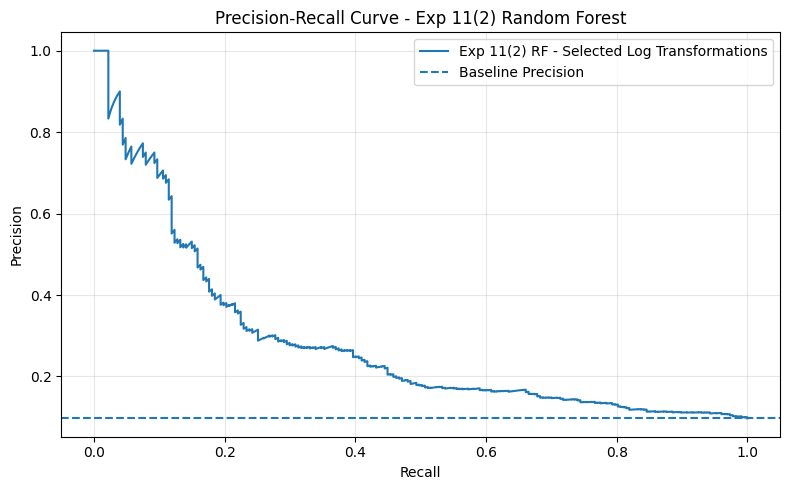


==== THRESHOLD ANALYSIS ====
 Threshold  Precision  Recall  F1 Score
      0.05     0.1021  0.9824    0.1850
      0.06     0.1045  0.9780    0.1889
      0.07     0.1072  0.9692    0.1931
      0.08     0.1096  0.9515    0.1966
      0.09     0.1115  0.9207    0.1990
      0.10     0.1134  0.8855    0.2011
      0.11     0.1146  0.8458    0.2018
      0.12     0.1192  0.8194    0.2082
      0.13     0.1267  0.8018    0.2189
      0.14     0.1339  0.7841    0.2288
      0.15     0.1390  0.7445    0.2342
      0.16     0.1455  0.7181    0.2420
      0.17     0.1492  0.6828    0.2449
      0.18     0.1583  0.6652    0.2557
      0.19     0.1649  0.6344    0.2618
      0.20     0.1703  0.5903    0.2643
      0.21     0.1717  0.5463    0.2613
      0.22     0.1775  0.5066    0.2629
      0.23     0.1861  0.4846    0.2689
      0.24     0.1978  0.4670    0.2779
      0.25     0.2086  0.4493    0.2849
      0.26     0.2260  0.4449    0.2997
      0.27     0.2328  0.4185    0.2992
      0.28

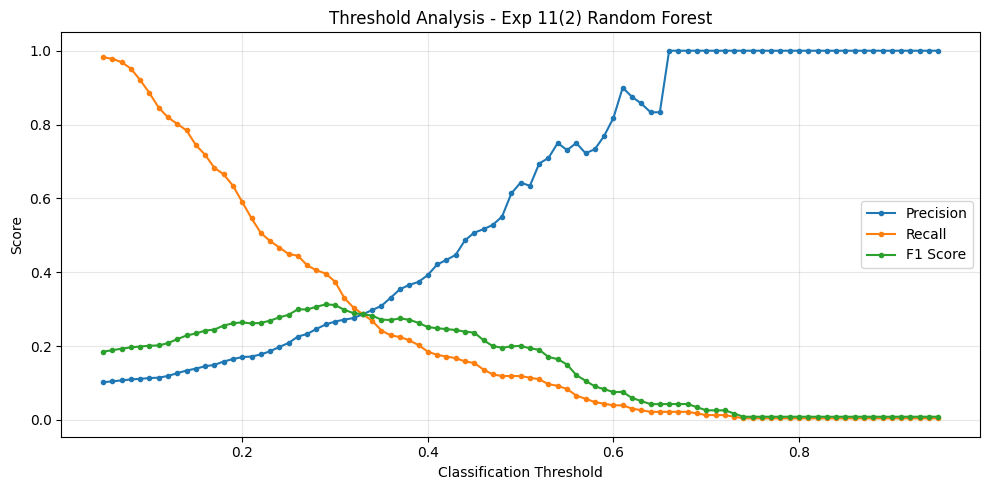


==== TRAIN METRICS ====
Accuracy    : 0.9661
Precision   : 0.7412
Recall      : 1.0000
F1 Score    : 0.8514
ROC-AUC     : 1.0000
PR-AUC      : 0.9997

==== VALIDATION METRICS ====
Accuracy    : 0.8310
Precision   : 0.2586
Recall      : 0.3965
F1 Score    : 0.3130
ROC-AUC     : 0.6941
PR-AUC      : 0.2845

==== TEST METRICS ====
Accuracy    : 0.8354
Precision   : 0.2704
Recall      : 0.4085
F1 Score    : 0.3254
ROC-AUC     : 0.6943
PR-AUC      : 0.3223


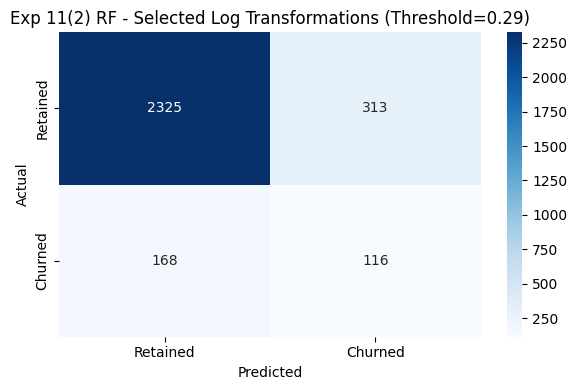


==== TEST CLASSIFICATION REPORT ====
              precision    recall  f1-score   support

    Retained       0.93      0.88      0.91      2638
     Churned       0.27      0.41      0.33       284

    accuracy                           0.84      2922
   macro avg       0.60      0.64      0.62      2922
weighted avg       0.87      0.84      0.85      2922


==== TOP 20 FEATURE IMPORTANCES ====
                   Feature  Importance
        margin_net_pow_ele     0.06997
   forecast_meter_rent_12m     0.03878
      cons_last_month_diff     0.03122
       forecast_cons_ratio     0.02932
    margin_per_consumption     0.02803
     consumption_per_power     0.02372
   price_power_interaction     0.02371
          margin_per_power     0.02364
              months_activ     0.02325
price_consumption_exposure     0.02257
                   pow_max     0.02099
         months_modif_prod     0.02093
     cons_last_month_ratio     0.02043
        forecast_cons_diff     0.01894
        marg

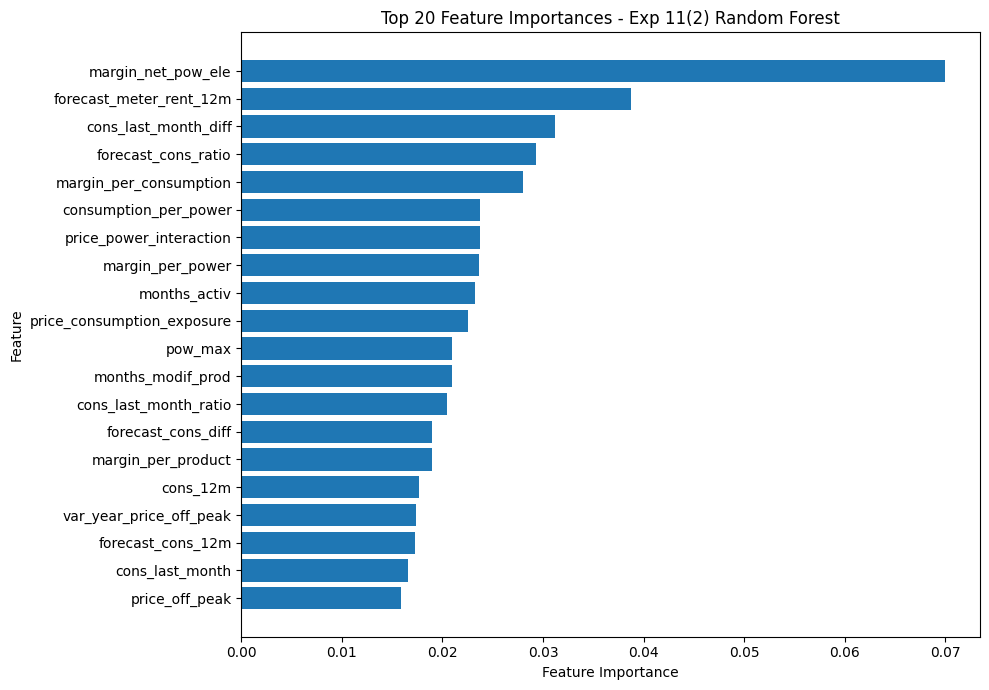


EXP 11(2) - SELECTED LOG TRANSFORMATIONS COMPLETED
Best CV PR-AUC: 0.2683
Selected Threshold: 0.29
Test PR-AUC: 0.3223
Test F1: 0.3254
Number of log1p features: 13
Number of signed-log features: 5
Total transformed features: 18


In [7]:

# ============================================================
# Exp 11(2) – Hyperparameter-Tuned Regularized Random Forest | Median Imputation | Log Transformations (104 Features)
# ============================================================

# 0. IMPORT LIBRARIES
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, precision_recall_curve,
    confusion_matrix, classification_report
)

# 1. EXPERIMENT CONFIGURATION
EXPERIMENT_NAME = "Exp 11(2) – Hyperparameter-Tuned Regularized Random Forest | Median Imputation | Log Transformations (104 Features)"
RANDOM_STATE = 42

date_cols = ['date_activ', 'date_end', 'date_modif_prod', 'date_renewal']

# Positive / zero features: log1p(x)
log1p_features = [
    'tenure_margin_interaction',
    'forecast_cons_12m',
    'forecast_cons_year',
    'cons_12m',
    'cons_last_month',
    'cons_gas_12m',
    'consumption_per_power',
    'margin_per_power',
    'margin_net_pow_ele',
    'forecast_meter_rent_12m',
    'imp_cons',
    'discount_consumption_interaction',
    'margin_per_product'
]

# Features containing negative values: sign(x) * log(1 + abs(x))
signed_log1p_features = [
    'cons_last_month_diff',
    'forecast_cons_diff',
    'price_consumption_exposure',
    'price_power_interaction',
    'dec_jan_off_peak_fix_diff'
]

# 2. PREPARE FEATURES AND TARGET
drop_cols = ['id', 'churn'] + [
    col for col in date_cols if col in df.columns
]

X = df.drop(columns=drop_cols, errors='ignore').copy()
y = df['churn'].astype(int).copy()
X = X.replace([np.inf, -np.inf], np.nan)

print("=" * 75)
print(EXPERIMENT_NAME)
print("=" * 75)
print("Dataset Shape:", X.shape)
print("Total Missing Values:", int(X.isna().sum().sum()))
print("\nTarget Distribution:")
print(y.value_counts().sort_index())
print("\nTarget Percentage:")
print((y.value_counts(normalize=True).sort_index() * 100).round(2))

# 3. TRAIN / VALIDATION / TEST SPLITS
# 64% training, 16% validation, 20% test
X_train_full, X_test, y_train_full, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

X_model_train, X_val, y_model_train, y_val = train_test_split(
    X_train_full, y_train_full, test_size=0.20,
    random_state=RANDOM_STATE, stratify=y_train_full
)

print("\nSplit Sizes:")
print("Model Training:", X_model_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

# 4. IDENTIFY NUMERICAL AND CATEGORICAL FEATURES
categorical_cols = X.select_dtypes(
    include=['object', 'category', 'bool']
).columns.tolist()

numerical_cols = X.select_dtypes(include=np.number).columns.tolist()

log1p_features = [
    col for col in log1p_features if col in numerical_cols
]
signed_log1p_features = [
    col for col in signed_log1p_features if col in numerical_cols
]

print("\nCategorical Columns:")
print(categorical_cols)
print("\nNumber of Numerical Columns:", len(numerical_cols))
print("\nLog1p Features:")
print(log1p_features)
print("\nSigned Log1p Features:")
print(signed_log1p_features)

# 5. VALIDATE LOG1P FEATURES
# log1p(x) requires x >= 0.
invalid_log_features = [
    col for col in log1p_features
    if (X_model_train[col].dropna() < 0).any()
]

if invalid_log_features:
    raise ValueError(
        "These log1p features contain negative values. "
        "Review their transformation before proceeding: "
        f"{invalid_log_features}"
    )

# 6. OUTLIER CAPPING CONFIGURATION
two_sided_features = [
    'cons_last_month_diff',
    'forecast_cons_diff',
    'price_consumption_exposure'
]

upper_only_features = [
    'consumption_per_power',
    'cons_12m',
    'cons_last_month',
    'pow_max',
    'forecast_cons_year',
    'imp_cons',
    'net_margin',
    'margin_per_product'
]

two_sided_features = [
    col for col in two_sided_features if col in numerical_cols
]
upper_only_features = [
    col for col in upper_only_features if col in numerical_cols
]

# 7. OUTLIER CAPPING TRANSFORMER
# Quantile limits are learned independently within each CV training fold.
class OutlierCapper(BaseEstimator, TransformerMixin):
    def __init__(self, two_sided_features=None, upper_only_features=None):
        self.two_sided_features = two_sided_features
        self.upper_only_features = upper_only_features

    def fit(self, X, y=None):
        self.cap_limits_ = {}

        for col in self.two_sided_features or []:
            self.cap_limits_[col] = {
                'lower': X[col].quantile(0.01),
                'upper': X[col].quantile(0.99)
            }

        for col in self.upper_only_features or []:
            self.cap_limits_[col] = {
                'lower': None,
                'upper': X[col].quantile(0.99)
            }

        return self

    def transform(self, X):
        X = X.copy()

        for col, limits in self.cap_limits_.items():
            if limits['lower'] is not None:
                X[col] = X[col].clip(lower=limits['lower'])
            if limits['upper'] is not None:
                X[col] = X[col].clip(upper=limits['upper'])

        return X

    def get_feature_names_out(self, input_features=None):
        return np.asarray(input_features, dtype=object)

# 8. LOG TRANSFORMATION TRANSFORMER
class LogTransformer(BaseEstimator, TransformerMixin):
    def __init__(self, positive_features=None, signed_features=None):
        self.positive_features = positive_features
        self.signed_features = signed_features

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        X = X.copy()

        for col in self.positive_features or []:
            X[col] = np.log1p(X[col])

        for col in self.signed_features or []:
            X[col] = np.sign(X[col]) * np.log1p(np.abs(X[col]))

        return X

    def get_feature_names_out(self, input_features=None):
        return np.asarray(input_features, dtype=object)

# 9. PREPROCESSING PIPELINE
numerical_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median', keep_empty_features=True))
])

categorical_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('numeric', numerical_pipeline, numerical_cols),
        ('categorical', categorical_pipeline, categorical_cols)
    ],
    remainder='drop',
    verbose_feature_names_out=False
)

# 10. RANDOM FOREST PIPELINE
rf_pipeline = Pipeline(steps=[
    ('outlier_capping', OutlierCapper(
        two_sided_features=two_sided_features,
        upper_only_features=upper_only_features
    )),
    ('log_transform', LogTransformer(
        positive_features=log1p_features,
        signed_features=signed_log1p_features
    )),
    ('preprocessing', preprocessor),
    ('model', RandomForestClassifier(
        class_weight='balanced',
        random_state=RANDOM_STATE,
        n_jobs=1
    ))
])

# 11. STRATIFIED CROSS VALIDATION
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

# 12. HYPERPARAMETER SEARCH SPACE
param_grid = {
    'model__n_estimators': [300, 500, 700],
    'model__max_depth': [None, 10, 15, 20],
    'model__min_samples_split': [5, 10, 20, 30],
    'model__min_samples_leaf': [2, 5, 10, 15],
    'model__max_features': ['sqrt', 'log2', 0.3, 0.5],
    'model__class_weight': ['balanced', 'balanced_subsample']
}

# 13. RANDOMIZED SEARCH CV
random_search = RandomizedSearchCV(
    estimator=rf_pipeline,
    param_distributions=param_grid,
    n_iter=25,
    scoring='average_precision',
    cv=cv,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbose=2,
    refit=True,
    return_train_score=True
)

# 14. FIT RANDOMIZED SEARCH
# Raw training data is passed; capping, log transformations and imputation
# are fitted independently inside each CV fold.
random_search.fit(X_model_train, y_model_train)

# 15. BEST HYPERPARAMETERS
print("\n==== BEST HYPERPARAMETERS ====")
print(random_search.best_params_)
print("\nBest CV PR-AUC:", round(random_search.best_score_, 4))

# 16. BEST RANDOM FOREST MODEL
best_rf_pipeline = random_search.best_estimator_

# 17. RANDOMIZED SEARCH RESULTS
search_results_df = pd.DataFrame(random_search.cv_results_)
search_results_df = search_results_df.sort_values(
    by='mean_test_score', ascending=False
)

result_cols = [
    'param_model__n_estimators',
    'param_model__max_depth',
    'param_model__min_samples_split',
    'param_model__min_samples_leaf',
    'param_model__max_features',
    'param_model__class_weight',
    'mean_train_score',
    'mean_test_score',
    'std_test_score'
]

print("\n==== TOP 10 HYPERPARAMETER COMBINATIONS ====")
print(search_results_df[result_cols].head(10).round(4).to_string(index=False))

# 18. OUTLIER CAPPING AND LOG TRANSFORMATION SUMMARY
# Use the fitted preprocessing steps on model-training data for diagnostics.
fitted_capper = best_rf_pipeline.named_steps['outlier_capping']
fitted_log_transformer = best_rf_pipeline.named_steps['log_transform']

X_train_capped = fitted_capper.transform(X_model_train)
X_train_transformed = fitted_log_transformer.transform(X_train_capped)

cap_summary = []

for col, limits in fitted_capper.cap_limits_.items():
    cap_summary.append({
        'Feature': col,
        'Original Min': X_model_train[col].min(),
        'Capped Min': X_train_capped[col].min(),
        'Original Max': X_model_train[col].max(),
        'Capped Max': X_train_capped[col].max(),
        'Lower Limit': limits['lower'],
        'Upper Limit': limits['upper']
    })

cap_summary_df = pd.DataFrame(cap_summary)

print("\n==== OUTLIER CAPPING SUMMARY ====")
if not cap_summary_df.empty:
    print(cap_summary_df.round(3).to_string(index=False))
else:
    print("No configured outlier features were found.")

# 19. SKEWNESS COMPARISON
skewness_rows = []

for col in log1p_features:
    before = X_train_capped[col].dropna()
    after = X_train_transformed[col].dropna()

    skewness_rows.append({
        'Feature': col,
        'Transformation': 'log1p(x)',
        'Skew_Before': before.skew(),
        'Skew_After': after.skew(),
        'Absolute_Skew_Reduction': abs(before.skew()) - abs(after.skew())
    })

for col in signed_log1p_features:
    before = X_train_capped[col].dropna()
    after = X_train_transformed[col].dropna()

    skewness_rows.append({
        'Feature': col,
        'Transformation': 'signed_log1p(x)',
        'Skew_Before': before.skew(),
        'Skew_After': after.skew(),
        'Absolute_Skew_Reduction': abs(before.skew()) - abs(after.skew())
    })

skewness_comparison_df = pd.DataFrame(skewness_rows)

if not skewness_comparison_df.empty:
    skewness_comparison_df = skewness_comparison_df.sort_values(
        'Absolute_Skew_Reduction', ascending=False
    )
    print("\n==== SKEWNESS COMPARISON ====")
    print(skewness_comparison_df.round(4).to_string(index=False))

# 20. VALIDATION PROBABILITIES
y_prob_val = best_rf_pipeline.predict_proba(X_val)[:, 1]

# 21. PRECISION-RECALL CURVE
precision_curve, recall_curve, _ = precision_recall_curve(y_val, y_prob_val)

plt.figure(figsize=(8, 5))
plt.plot(
    recall_curve, precision_curve,
    label='Exp 11(2) RF - Selected Log Transformations'
)
plt.axhline(
    y=y_val.mean(),
    linestyle='--',
    label='Baseline Precision'
)
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve - Exp 11(2) Random Forest')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# 22. THRESHOLD ANALYSIS ON VALIDATION DATA
threshold_values = np.arange(0.05, 0.951, 0.01)
threshold_rows = []

for threshold in threshold_values:
    y_pred = (y_prob_val >= threshold).astype(int)

    threshold_rows.append({
        'Threshold': threshold,
        'Precision': precision_score(y_val, y_pred, zero_division=0),
        'Recall': recall_score(y_val, y_pred, zero_division=0),
        'F1 Score': f1_score(y_val, y_pred, zero_division=0)
    })

threshold_df = pd.DataFrame(threshold_rows)

best_threshold_row = threshold_df.loc[threshold_df['F1 Score'].idxmax()]
best_threshold = float(best_threshold_row['Threshold'])

print("\n==== THRESHOLD ANALYSIS ====")
print(threshold_df.round(4).to_string(index=False))
print("\n==== BEST VALIDATION THRESHOLD ====")
print(best_threshold_row)

plt.figure(figsize=(10, 5))
plt.plot(
    threshold_df['Threshold'], threshold_df['Precision'],
    marker='o', markersize=3, label='Precision'
)
plt.plot(
    threshold_df['Threshold'], threshold_df['Recall'],
    marker='o', markersize=3, label='Recall'
)
plt.plot(
    threshold_df['Threshold'], threshold_df['F1 Score'],
    marker='o', markersize=3, label='F1 Score'
)
plt.xlabel('Classification Threshold')
plt.ylabel('Score')
plt.title('Threshold Analysis - Exp 11(2) Random Forest')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# 23. PREDICTIONS
y_prob_train = best_rf_pipeline.predict_proba(X_model_train)[:, 1]
y_prob_test = best_rf_pipeline.predict_proba(X_test)[:, 1]

y_pred_train = (y_prob_train >= best_threshold).astype(int)
y_pred_val = (y_prob_val >= best_threshold).astype(int)
y_pred_test = (y_prob_test >= best_threshold).astype(int)

# 24. EVALUATION FUNCTION
def calculate_metrics(y_true, y_pred, y_prob):
    return {
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred, zero_division=0),
        'Recall': recall_score(y_true, y_pred, zero_division=0),
        'F1 Score': f1_score(y_true, y_pred, zero_division=0),
        'ROC-AUC': roc_auc_score(y_true, y_prob),
        'PR-AUC': average_precision_score(y_true, y_prob)
    }

train_metrics = calculate_metrics(
    y_model_train, y_pred_train, y_prob_train
)
validation_metrics = calculate_metrics(
    y_val, y_pred_val, y_prob_val
)
test_metrics = calculate_metrics(
    y_test, y_pred_test, y_prob_test
)

# 25. PRINT METRICS
def print_metrics(title, metrics):
    print(f"\n==== {title} ====")
    for metric, value in metrics.items():
        print(f"{metric:12}: {value:.4f}")

print_metrics('TRAIN METRICS', train_metrics)
print_metrics('VALIDATION METRICS', validation_metrics)
print_metrics('TEST METRICS', test_metrics)

# 26. TEST CONFUSION MATRIX
cm = confusion_matrix(y_test, y_pred_test)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Retained', 'Churned'],
    yticklabels=['Retained', 'Churned']
)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title(
    f'Exp 11(2) RF - Selected Log Transformations '
    f'(Threshold={best_threshold:.2f})'
)
plt.tight_layout()
plt.show()

# 27. TEST CLASSIFICATION REPORT
print("\n==== TEST CLASSIFICATION REPORT ====")
print(classification_report(
    y_test,
    y_pred_test,
    target_names=['Retained', 'Churned'],
    zero_division=0
))

# 28. FEATURE IMPORTANCE
fitted_preprocessor = best_rf_pipeline.named_steps['preprocessing']
rf_fitted = best_rf_pipeline.named_steps['model']
feature_names = fitted_preprocessor.get_feature_names_out()

feature_importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': rf_fitted.feature_importances_
}).sort_values(
    by='Importance', ascending=False
).reset_index(drop=True)

print("\n==== TOP 20 FEATURE IMPORTANCES ====")
print(feature_importance_df.head(20).round(5).to_string(index=False))

# 29. FEATURE IMPORTANCE VISUALIZATION
top_features = feature_importance_df.head(20).sort_values(
    'Importance', ascending=True
)

plt.figure(figsize=(10, 7))
plt.barh(top_features['Feature'], top_features['Importance'])
plt.xlabel('Feature Importance')
plt.ylabel('Feature')
plt.title('Top 20 Feature Importances - Exp 11(2) Random Forest')
plt.tight_layout()
plt.show()

# 30. FINAL EXPERIMENT SUMMARY
test_metrics_df = pd.DataFrame(
    [test_metrics],
    index=['Exp11_2_RF_Log_Transformations']
)

print("\n" + "=" * 75)
print("EXP 11(2) - SELECTED LOG TRANSFORMATIONS COMPLETED")
print("=" * 75)
print("Best CV PR-AUC:", round(random_search.best_score_, 4))
print("Selected Threshold:", round(best_threshold, 2))
print("Test PR-AUC:", round(test_metrics['PR-AUC'], 4))
print("Test F1:", round(test_metrics['F1 Score'], 4))
print("Number of log1p features:", len(log1p_features))
print("Number of signed-log features:", len(signed_log1p_features))
print("Total transformed features:", len(log1p_features) + len(signed_log1p_features))


**Exp 11(2) – Hyperparameter-Tuned Random Forest | Median Imputation & Selected Log Transformations**

**1. Feature Transformation & Preprocessing**

- Applied median imputation to handle missing numerical values.
- Applied feature-specific outlier capping to 11 numerical features.
- Applied log transformations to reduce skewness in selected numerical features.
- Used two types of transformations:
  - `log1p(x)` on 13 selected features.
  - `signed_log1p(x)` on 5 selected features.
- Total transformed features: **18**.
- Dataset contains 104 features:
  - 101 numerical features.
  - 3 categorical features.

**Observation:**

- Log transformations reduced skewness in several highly skewed features.
- `tenure_margin_interaction` showed the largest skewness reduction, from 24.87 to -1.47.
- `discount_consumption_interaction` showed a reduction from 17.51 to 5.22.
- Signed log transformation helped handle both positive and negative values.
- However, some features still exhibit considerable skewness after transformation.

**2. Model Optimization**

- Applied hyperparameter tuning using 25 parameter combinations and 5-fold cross-validation.
- Used PR-AUC as the optimization metric.
- Best hyperparameters:
  - `n_estimators`: 700
  - `min_samples_split`: 10
  - `min_samples_leaf`: 5
  - `max_features`: 0.5
  - `max_depth`: 20
  - `class_weight`: balanced_subsample
- Best CV PR-AUC: **26.83%**

**Observation:**

- The selected configuration uses 700 trees with a maximum depth of 20.
- `balanced_subsample` helps address the class imbalance during training.
- CV PR-AUC of 26.83% is lower than Exp2 (30.55%).
- Training PR-AUC remains extremely high at 99.97%, indicating severe overfitting.

**3. Model Performance – Test Data**

| Metric    | Test Performance |
| --------- | ---------------- |
| Accuracy  | **83.54%**       |
| Precision | **27.04%**       |
| Recall    | **40.85%**       |
| F1 Score  | **32.54%**       |
| ROC-AUC   | **69.43%**       |
| PR-AUC    | **32.23%**       |

**4. Threshold Analysis**

- Tested classification thresholds between 0.05 and 0.95.
- Selected threshold: **0.29**, based on the highest F1 score in the threshold analysis.
- At threshold 0.29 (threshold validation):
  - Precision: 25.86%
  - Recall: 39.65%
  - F1 Score: 31.30%
- Lower thresholds improve recall but reduce precision.
- Higher thresholds improve precision but reduce recall.

**Observation:**

- The selected threshold provides a reasonable balance between precision and recall.
- At higher thresholds, precision increases considerably, but recall drops sharply.
- At threshold 0.66, precision reaches 100%, but recall falls to only 2.20%, making it unsuitable for identifying a meaningful number of churn customers.

**5. Confusion Matrix (Threshold = 0.29)**

|                 | Predicted Retained | Predicted Churned |
| --------------- | ------------------ | ----------------- |
| Actual Retained | 2,325              | 313               |
| Actual Churned  | 168                | 116               |

**Observation:**

- Model correctly identifies 116 churn customers out of 284.
- It misses 168 actual churn customers.
- Generates 313 false positives.
- Identifies approximately 40.85% of actual churn customers.
- The model still struggles to distinguish churn customers from retained customers accurately.

**6. Precision-Recall Curve**

- Baseline precision is approximately 9.72%, corresponding to the churn percentage.
- Model achieves higher precision than the baseline across most of the recall range.
- PR-AUC is **32.23%**.
- Performance is approximately 3.3 times the baseline PR-AUC.

**Observation:**

- The model provides useful separation between churned and retained customers.
- However, precision decreases as recall increases.
- Overall PR-AUC is lower than Exp2 (35.75%) and Exp8(2) (34.26%).

**7. Cross-Validation Results**

| Metric    | Training | Validation |
| --------- | -------- | ---------- |
| Accuracy  | 99.92%   | 90.60%     |
| Precision | 99.21%   | 60.25%     |
| Recall    | 100.00%  | 9.03%      |
| F1 Score  | 99.60%   | 15.67%     |
| ROC-AUC   | 99.99%   | 68.92%     |
| PR-AUC    | 99.93%   | **26.83%** |

**Observation:**

- Significant training-validation performance gap indicates severe overfitting.
- Training PR-AUC is 99.93%, while validation PR-AUC is only 26.83%.
- Validation recall is extremely low at the default 0.50 threshold.
- The model performs considerably better after applying the validation-selected threshold of 0.29.
- Despite the overfitting, test PR-AUC reaches 32.23%.

**8. Top 20 Important Features**

The most important features include:

- `margin_net_pow_ele`
- `forecast_meter_rent_12m`
- `cons_last_month_diff`
- `forecast_cons_ratio`
- `margin_per_consumption`
- `consumption_per_power`
- `price_power_interaction`
- `margin_per_power`
- `months_activ`
- `price_consumption_exposure`

**Observation:**

- Margin-related, consumption-related and price-related features remain important.
- `margin_net_pow_ele` continues to be the most important feature, with an importance of approximately 7.00%.
- Consumption and price interaction features also contribute to churn prediction.
- Feature importance patterns remain broadly consistent with earlier Random Forest experiments.

Pasted text(20261122-013942).txt

**9. Model Comparison – All Experiments**

| Metric    | Exp1-Baseline RF | Exp2-Regularized RF | Exp3-Strong Reg. RF | Exp4-XGBoost | Exp5-Strong Reg. XGB | Exp6-LightGBM | Exp7-SVM |
| --------- | ---------------- | ------------------- | ------------------- | ------------ | -------------------- | ------------- | -------- |
| Accuracy  | 84.02%           | 87.34%              | 84.94%              | **89.39%**   | 86.69%               | 88.02%        | 82.75%   |
| Precision | 26.72%           | 34.86%              | 29.26%              | **43.09%**   | 31.83%               | 36.48%        | 23.68%   |
| Recall    | 36.97%           | 34.86%              | **38.73%**          | 28.52%       | 32.39%               | 31.34%        | 34.86%   |
| F1 Score  | 31.02%           | **34.86%**          | 33.33%              | 34.32%       | 32.11%               | 33.71%        | 28.21%   |
| ROC-AUC   | **70.76%**       | 70.48%              | 69.45%              | 69.24%       | 69.58%               | 69.33%        | 66.45%   |
| PR-AUC    | 32.77%           | **35.75%**          | 31.71%              | 32.15%       | 29.42%               | 32.20%        | 20.13%   |
| CV PR-AUC | 25.43%           | **30.55%**          | 26.15%              | 28.42%       | 26.38%               | 28.63%        | 20.85%   |

| Metric    | Exp8(2)-RF | Exp9(2)-Capped RF | Exp9(4)-Capped XGB | Exp10(2)-Capped RF + Median | Exp11(2)-RF + Log Transform |
| --------- | ---------- | ----------------- | ------------------ | --------------------------- | --------------------------- |
| Accuracy  | 82.07%     | 82.20%            | 89.05%             | 84.80%                      | 83.54%                      |
| Precision | 25.71%     | 25.72%            | 40.62%             | 28.49%                      | 27.04%                      |
| Recall    | **44.72%** | 44.01%            | 27.46%             | 37.32%                      | 40.85%                      |
| F1 Score  | 32.65%     | 32.47%            | 32.77%             | 32.32%                      | 32.54%                      |
| ROC-AUC   | 69.98%     | 69.10%            | 68.66%             | 69.23%                      | 69.43%                      |
| PR-AUC    | **34.26%** | 32.43%            | 32.57%             | 32.75%                      | 32.23%                      |
| CV PR-AUC | 27.35%     | 26.98%            | 28.14%             | 27.06%                      | 26.83%                      |

*Bold values indicate the best result within the respective metric across all experiments.*

**Observation:**

- Exp2 achieves the highest PR-AUC (35.75%) and F1 Score (34.86%) among all experiments.
- Exp4 achieves the highest accuracy (89.39%) and precision (43.09%).
- Exp1 achieves the highest ROC-AUC (70.76%).
- Exp8(2) achieves the highest recall (44.72%), followed by Exp9(2) (44.01%).
- Exp9(4) achieves relatively high precision (40.62%) but low recall (27.46%).
- Exp10(2) improves precision to 28.49% compared with Exp8(2) and Exp9(2), but its recall decreases to 37.32%.
- Exp11(2) achieves 40.85% recall and 32.23% PR-AUC, but does not outperform Exp2 or Exp8(2).
- Exp11(2) CV PR-AUC (26.83%) is lower than Exp10(2) (27.06%) and Exp9(4) (28.14%).
- Overall, the recent preprocessing and transformation experiments have not produced a consistent improvement over the earlier best-performing models.

**10. Final Conclusion – Exp 11(2)**

- Achieves a test PR-AUC of 32.23%.
- Achieves an F1 Score of 32.54%.
- Correctly identifies 116 churn customers out of 284.
- Selected threshold of 0.29 provides 40.85% recall and 27.04% precision on test data.
- Log transformations reduce skewness in several selected numerical features.
- However, significant overfitting remains, with training PR-AUC of 99.93% compared with CV PR-AUC of 26.83%.
- Overall performance does not improve upon the earlier best-performing experiments.

**Best Model So Far: Exp2 – Regularized Random Forest**

Exp2 remains the best overall model because it achieves:

- Highest PR-AUC: **35.75%**
- Highest F1 Score: **34.86%**
- Strong precision: **34.86%**

Exp8(2) remains a strong alternative when identifying more churn customers is the priority, achieving the highest recall of 44.72%.

**Final assessment:** Exp11(2) does not provide a meaningful improvement over Exp2. Although selected log transformations reduce skewness, they do not translate into better churn prediction performance.

**Important note:** CV classification metrics use the default 0.50 threshold, while validation and test classification metrics use the selected threshold of 0.29. Compare classification metrics cautiously. PR-AUC is threshold-independent, making it more suitable for comparing these experiments.

# **Exp 12 – Random Forest on Selected Feature Dataset | Extended Log Transformations**

1. Prepare the selected feature dataset by separating features and target, excluding customer ID. Replace infinite values with NaN.
2. Split the data into 64% training, 16% validation, and 20% testing using stratification.
3. Identify numerical and categorical features for preprocessing.
4. Apply extended log transformations to selected numerical features:
   - log1p(x) for positive or zero-valued features.
   - sign(x) × log1p(|x|) for features containing negative values.
5. Validate that features selected for log1p do not contain negative values.
6. Apply feature-specific outlier capping:
   - Two-sided capping (1st–99th percentile) for selected features.
   - Upper-only capping (99th percentile) for selected right-skewed features.
7. Calculate outlier limits using training data only and apply the same limits to validation and test data.
8. Compare feature skewness before and after log transformations to evaluate skewness reduction.
9. Impute numerical missing values using the median. Impute categorical missing values using the most frequent value and apply One-Hot Encoding (OHE).
10. Train a Random Forest Classifier with 500 trees and class_weight='balanced' to handle class imbalance.
11. Generate validation probabilities and plot the Precision-Recall curve.
12. Perform threshold analysis (0.05–0.55, with 0.01 intervals) and select the threshold with the highest validation F1 Score.
13. Apply the selected threshold to training, validation, and test probabilities to generate:
    0 = Retained | 1 = Churned.
14. Evaluate model performance using Accuracy, Precision, Recall, F1 Score, ROC-AUC, PR-AUC, confusion matrix, and classification report.
15. Analyse and visualize the top 20 feature importances.
16. Display the selected threshold, final test performance, input feature count, and number of log-transformed features.

**Experiment objective:**

Evaluate Random Forest performance on a selected feature dataset using more extensive log transformations to reduce feature skewness, while retaining feature-specific outlier capping and class imbalance handling.

In [4]:
df = pd.read_csv('data_for_predictions.csv')
df.drop(columns=["Unnamed: 0"], inplace=True)
df.head()

,id,cons_12m,cons_gas_12m,cons_last_month,forecast_cons_12m,forecast_discount_energy,forecast_meter_rent_12m,forecast_price_energy_off_peak,forecast_price_energy_peak,forecast_price_pow_off_peak,...,months_modif_prod,months_renewal,channel_MISSING,channel_ewpakwlliwisiwduibdlfmalxowmwpci,channel_foosdfpfkusacimwkcsosbicdxkicaua,channel_lmkebamcaaclubfxadlmueccxoimlema,channel_usilxuppasemubllopkaafesmlibmsdf,origin_up_kamkkxfxxuwbdslkwifmmcsiusiuosws,origin_up_ldkssxwpmemidmecebumciepifcamkci,origin_up_lxidpiddsbxsbosboudacockeimpuepw
0,24011ae4ebbe3035111d65fa7c15bc57,0.000000,4.739944,0.000000,0.000000,0.0,0.444045,0.114481,0.098142,40.606701,...,2,6,0,0,1,0,0,0,0,1
1,d29c2c54acc38ff3c0614d0a653813dd,3.668479,0.000000,0.000000,2.280920,0.0,1.237292,0.145711,0.000000,44.311378,...,76,4,1,0,0,0,0,1,0,0
2,764c75f661154dac3a6c254cd082ea7d,2.736397,0.000000,0.000000,1.689841,0.0,1.599009,0.165794,0.087899,44.311378,...,68,8,0,0,1,0,0,1,0,0
3,bba03439a292a1e166f80264c16191cb,3.200029,0.000000,0.000000,2.382089,0.0,1.318689,0.146694,0.000000,44.311378,...,69,9,0,0,0,1,0,1,0,0
4,149d57cf92fc41cf94415803a877cb4b,3.646011,0.000000,2.721811,2.650065,0.0,2.122969,0.116900,0.100015,40.606701,...,71,9,1,0,0,0,0,1,0,0


Exp 13(12) – Random Forest on Selected Feature Dataset
Selected Dataset Shape: (14606, 63)
Feature Matrix Shape: (14606, 61)
Total Missing Values: 0

Target Distribution:
churn
0    13187
1     1419
Name: count, dtype: int64

Target Percentage:
churn
0    90.28
1     9.72
Name: proportion, dtype: float64

==== SPLIT SIZES ====
Model Training: (9347, 61)
Validation: (2337, 61)
Test: (2922, 61)

Number of Numerical Features: 61
Categorical Features: []

Available log1p Features: ['var_6m_price_off_peak_fix', 'var_6m_price_off_peak', 'var_year_price_off_peak_fix', 'var_year_price_off_peak', 'var_6m_price_off_peak_var', 'var_year_price_off_peak_var', 'var_6m_price_peak', 'var_6m_price_peak_fix', 'cons_gas_12m', 'var_6m_price_mid_peak_fix', 'var_6m_price_mid_peak', 'var_6m_price_mid_peak_var', 'var_year_price_peak_var', 'var_6m_price_peak_var', 'forecast_cons_12m', 'var_year_price_mid_peak_var', 'var_year_price_peak', 'var_year_price_peak_fix', 'var_year_price_mid_peak', 'var_year_price_mid

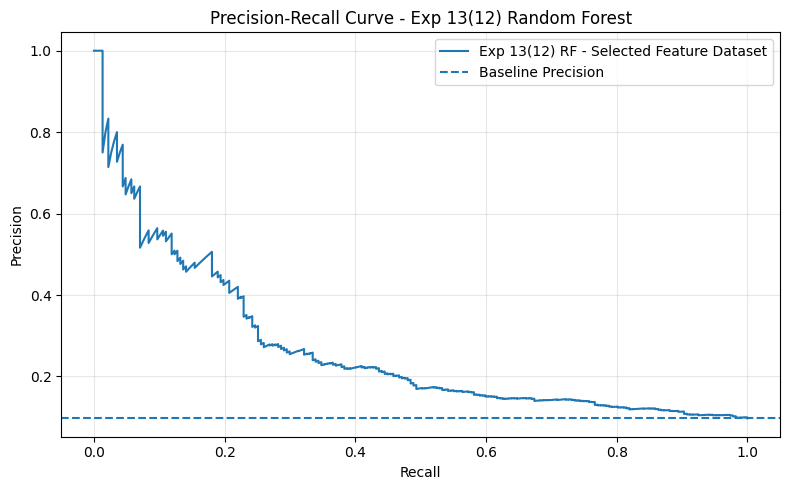


==== THRESHOLD ANALYSIS ====
 Threshold  Precision  Recall  F1 Score
      0.05     0.1030  0.9780    0.1864
      0.06     0.1054  0.9736    0.1903
      0.07     0.1055  0.9427    0.1898
      0.08     0.1063  0.9119    0.1904
      0.09     0.1103  0.9031    0.1965
      0.10     0.1148  0.8855    0.2032
      0.11     0.1182  0.8634    0.2080
      0.12     0.1198  0.8194    0.2091
      0.13     0.1241  0.8018    0.2150
      0.14     0.1291  0.7709    0.2211
      0.15     0.1379  0.7577    0.2334
      0.16     0.1432  0.7269    0.2393
      0.17     0.1443  0.6740    0.2378
      0.18     0.1452  0.6256    0.2357
      0.19     0.1509  0.5991    0.2411
      0.20     0.1602  0.5815    0.2512
      0.21     0.1651  0.5507    0.2541
      0.22     0.1707  0.5286    0.2581
      0.23     0.1710  0.4934    0.2540
      0.24     0.1849  0.4846    0.2676
      0.25     0.1981  0.4670    0.2782
      0.26     0.2063  0.4581    0.2845
      0.27     0.2190  0.4361    0.2916
      0.28

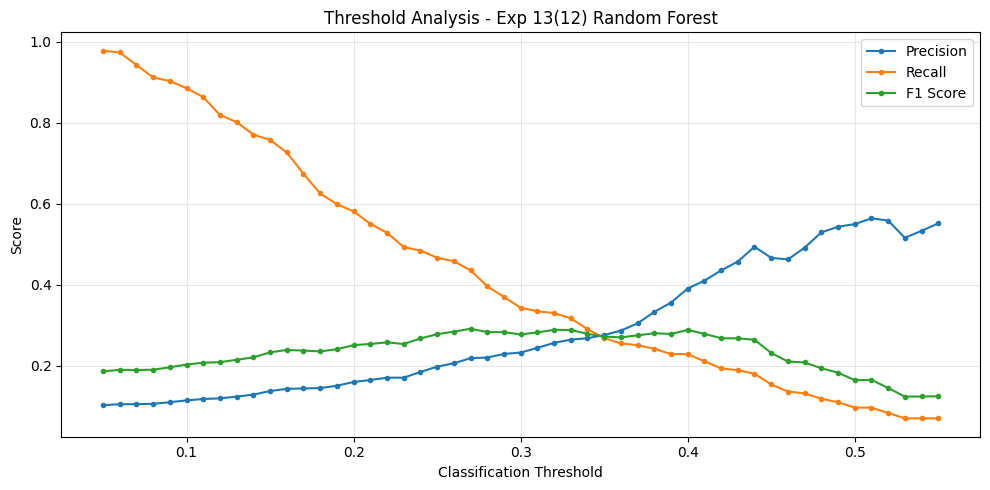


==== TRAIN METRICS ====
Accuracy    : 0.9386
Precision   : 0.6127
Recall      : 1.0000
F1 Score    : 0.7598
ROC-AUC     : 0.9998
PR-AUC      : 0.9974

==== VALIDATION METRICS ====
Accuracy    : 0.7942
Precision   : 0.2190
Recall      : 0.4361
F1 Score    : 0.2916
ROC-AUC     : 0.6834
PR-AUC      : 0.2654

==== TEST METRICS ====
Accuracy    : 0.7971
Precision   : 0.2332
Recall      : 0.4754
F1 Score    : 0.3129
ROC-AUC     : 0.6927
PR-AUC      : 0.3088


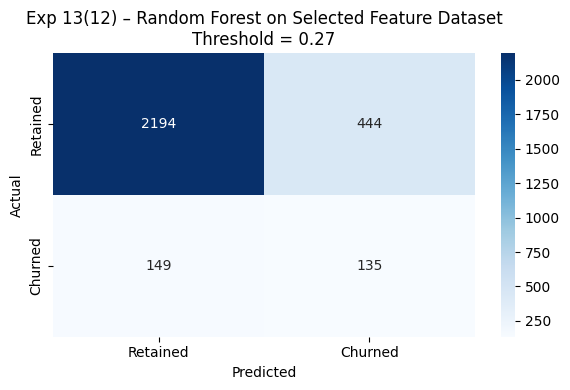


==== TEST CLASSIFICATION REPORT ====
              precision    recall  f1-score   support

    Retained       0.94      0.83      0.88      2638
     Churned       0.23      0.48      0.31       284

    accuracy                           0.80      2922
   macro avg       0.58      0.65      0.60      2922
weighted avg       0.87      0.80      0.83      2922


==== TOP 20 FEATURE IMPORTANCES ====
                        Feature  Importance
                       cons_12m     0.06359
        forecast_meter_rent_12m     0.06317
             margin_net_pow_ele     0.05829
           margin_gross_pow_ele     0.05121
              forecast_cons_12m     0.04553
                     net_margin     0.04552
                cons_last_month     0.04190
                   months_activ     0.03841
                        pow_max     0.03733
              months_modif_prod     0.03646
    var_year_price_off_peak_var     0.03195
        var_year_price_off_peak     0.02979
                       im

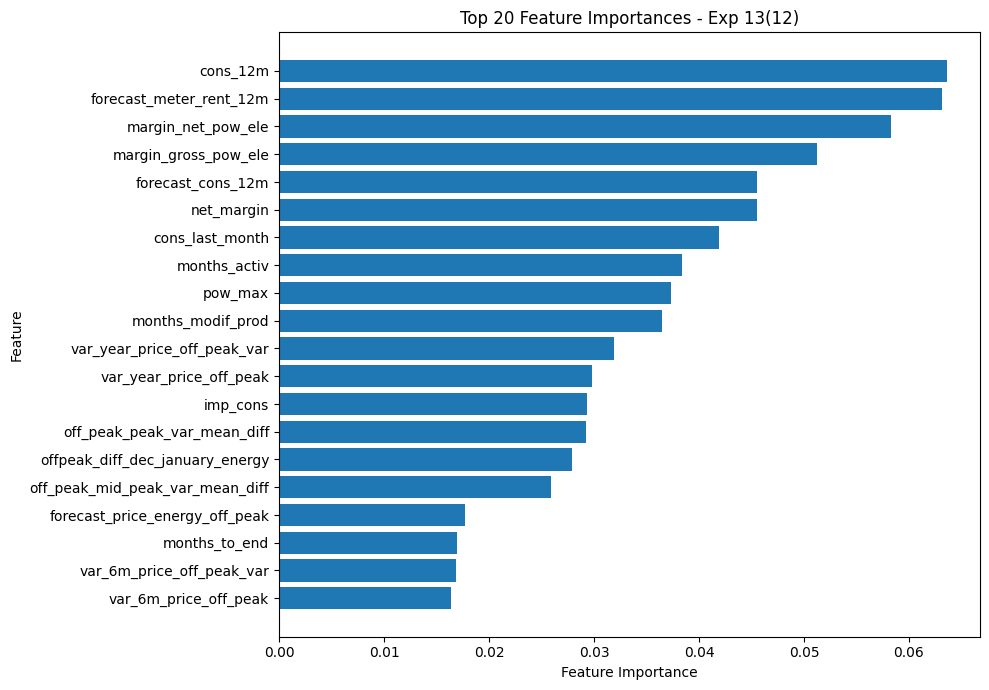


EXP 13(12) - SELECTED FEATURE MODEL COMPLETED
Selected Threshold: 0.27

Final Test Performance:
Accuracy    : 0.7971
Precision   : 0.2332
Recall      : 0.4754
F1 Score    : 0.3129
ROC-AUC     : 0.6927
PR-AUC      : 0.3088

Number of Input Features: 61
Number of log1p Features: 30
Number of Signed-log Features: 0
Total Transformed Features: 30


In [5]:

# ============================================================
# Exp 12 – Random Forest on Selected Feature Dataset | Extended Log Transformations
# ============================================================

# 0. IMPORT LIBRARIES
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, precision_recall_curve,
    confusion_matrix, classification_report
)

# 1. CONFIGURATION
EXPERIMENT_NAME = "Exp 12 – Random Forest on Selected Feature Dataset | Extended Log Transformations"
RANDOM_STATE = 42

# Positive / zero features: log1p(x)
log1p_features = [
    "margin_per_consumption",
    "forecast_cons_ratio",
    "tenure_margin_interaction",
    "customer_value_proxy",
    "var_6m_price_off_peak_fix",
    "var_6m_price_off_peak",
    "var_year_price_off_peak_fix",
    "var_year_price_off_peak",
    "var_6m_price_off_peak_var",
    "discount_consumption_interaction",
    "off_peak_fix_cv",
    "off_peak_var_cv",
    "var_year_price_off_peak_var",
    "var_6m_price_peak",
    "var_6m_price_peak_fix",
    "cons_gas_12m",
    "var_6m_price_mid_peak_fix",
    "var_6m_price_mid_peak",
    "var_6m_price_mid_peak_var",
    "mid_peak_var_cv",
    "peak_fix_cv",
    "mid_peak_fix_cv",
    "var_year_price_peak_var",
    "var_6m_price_peak_var",
    "forecast_cons_12m",
    "var_year_price_mid_peak_var",
    "var_year_price_peak",
    "var_year_price_peak_fix",
    "var_year_price_mid_peak",
    "var_year_price_mid_peak_fix",
    "margin_per_power",
    "cons_last_month",
    "product_adoption_rate",
    "consumption_per_power",
    "margin_net_pow_ele",
    "cons_12m",
    "gas_product_interaction",
    "peak_var_cv",
    "pow_max",
    "forecast_year_ratio",
    "gas_consumption_share",
    "forecast_cons_year",
    "cons_last_month_ratio",
    "imp_cons",
    "peak_mid_peak_fix_mean_diff",
    "margin_per_product",
    "net_margin",
    "forecast_meter_rent_12m",
    "months_activ",
    "peak_mid_peak_var_mean_diff"
]

# Features containing negative values: sign(x) * log(1 + abs(x))
signed_log1p_features = [
    "dec_jan_mid_peak_fix_diff",
    "dec_jan_off_peak_fix_diff",
    "cons_last_month_diff",
    "price_consumption_exposure",
    "dec_jan_mid_peak_var_diff",
    "forecast_cons_diff",
    "price_power_interaction",
    "peak_6m_change"
]

# 2. PREPARE SELECTED DATASET
df_selected = df.copy()

if 'churn' not in df_selected.columns:
    raise ValueError("The selected dataframe must contain a 'churn' column.")

X = df_selected.drop(columns=['id', 'churn'], errors='ignore').copy()
y = df_selected['churn'].astype(int).copy()
X = X.replace([np.inf, -np.inf], np.nan)

print("=" * 75)
print(EXPERIMENT_NAME)
print("=" * 75)
print("Selected Dataset Shape:", df_selected.shape)
print("Feature Matrix Shape:", X.shape)
print("Total Missing Values:", int(X.isna().sum().sum()))
print("\nTarget Distribution:")
print(y.value_counts().sort_index())
print("\nTarget Percentage:")
print((y.value_counts(normalize=True).sort_index() * 100).round(2))

# 3. TRAIN / VALIDATION / TEST SPLITS
# 64% training, 16% validation, 20% test
X_train_full, X_test, y_train_full, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

X_model_train, X_val, y_model_train, y_val = train_test_split(
    X_train_full, y_train_full, test_size=0.20,
    random_state=RANDOM_STATE, stratify=y_train_full
)

print("\n==== SPLIT SIZES ====")
print("Model Training:", X_model_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

# 4. IDENTIFY FEATURE TYPES
categorical_cols = X.select_dtypes(
    include=['object', 'category', 'bool']
).columns.tolist()

numerical_cols = X.select_dtypes(include=np.number).columns.tolist()

log1p_features = [
    col for col in log1p_features if col in numerical_cols
]
signed_log1p_features = [
    col for col in signed_log1p_features if col in numerical_cols
]

overlapping_features = set(log1p_features).intersection(signed_log1p_features)
if overlapping_features:
    raise ValueError(f"Features appear in both log lists: {overlapping_features}")

print("\nNumber of Numerical Features:", len(numerical_cols))
print("Categorical Features:", categorical_cols)
print("\nAvailable log1p Features:", log1p_features)
print("\nAvailable Signed-log Features:", signed_log1p_features)

# 5. OUTLIER CAPPING CONFIGURATION
two_sided_features = [
    "cons_last_month_diff",
    "forecast_cons_diff",
    "price_consumption_exposure"
]

upper_only_features = [
    "consumption_per_power",
    "cons_12m",
    "cons_last_month",
    "pow_max",
    "forecast_cons_year",
    "imp_cons",
    "net_margin",
    "margin_per_product"
]

two_sided_features = [
    col for col in two_sided_features if col in numerical_cols
]
upper_only_features = [
    col for col in upper_only_features if col in numerical_cols
]

# 6. CALCULATE OUTLIER LIMITS USING TRAINING DATA ONLY
cap_limits = {}

for col in two_sided_features:
    cap_limits[col] = {
        'lower': X_model_train[col].quantile(0.01),
        'upper': X_model_train[col].quantile(0.99)
    }

for col in upper_only_features:
    cap_limits[col] = {
        'lower': None,
        'upper': X_model_train[col].quantile(0.99)
    }

def apply_capping(data, limits):
    data_out = data.copy()
    for col, bounds in limits.items():
        if bounds['lower'] is not None:
            data_out[col] = data_out[col].clip(lower=bounds['lower'])
        if bounds['upper'] is not None:
            data_out[col] = data_out[col].clip(upper=bounds['upper'])
    return data_out

X_model_train_capped = apply_capping(X_model_train, cap_limits)
X_val_capped = apply_capping(X_val, cap_limits)
X_test_capped = apply_capping(X_test, cap_limits)

# 7. OUTLIER CAPPING SUMMARY
cap_summary = []

for col, bounds in cap_limits.items():
    cap_summary.append({
        'Feature': col,
        'Original Min': X_model_train[col].min(),
        'Capped Min': X_model_train_capped[col].min(),
        'Original Max': X_model_train[col].max(),
        'Capped Max': X_model_train_capped[col].max(),
        'Lower Limit': bounds['lower'],
        'Upper Limit': bounds['upper']
    })

cap_summary_df = pd.DataFrame(cap_summary)

print("\n==== OUTLIER CAPPING SUMMARY ====")
if not cap_summary_df.empty:
    print(cap_summary_df.round(3).to_string(index=False))
else:
    print("No configured outlier features were found.")

# 8. APPLY LOG TRANSFORMATIONS
def signed_log1p(series):
    return np.sign(series) * np.log1p(np.abs(series))

def apply_log_transformations(data):
    data_out = data.copy()
    for col in log1p_features:
        data_out[col] = np.log1p(data_out[col])
    for col in signed_log1p_features:
        data_out[col] = signed_log1p(data_out[col])
    return data_out

# Validate log1p domain across all splits after capping.
for split_name, split_data in [
    ('Training', X_model_train_capped),
    ('Validation', X_val_capped),
    ('Test', X_test_capped)
]:
    invalid_features = [
        col for col in log1p_features
        if (split_data[col].dropna() < 0).any()
    ]
    if invalid_features:
        raise ValueError(
            f"Negative values found in log1p features in {split_name}: "
            f"{invalid_features}. Review their transformations."
        )

X_model_train_transformed = apply_log_transformations(X_model_train_capped)
X_val_transformed = apply_log_transformations(X_val_capped)
X_test_transformed = apply_log_transformations(X_test_capped)

print("\nLog Transformations Applied Successfully.")
print("Total Log-transformed Features:",
      len(log1p_features) + len(signed_log1p_features))

# 9. SKEWNESS COMPARISON
skewness_rows = []

for col in log1p_features:
    before = X_model_train_capped[col].dropna()
    after = X_model_train_transformed[col].dropna()
    skew_before = before.skew()
    skew_after = after.skew()

    skewness_rows.append({
        'Feature': col,
        'Transformation': 'log1p(x)',
        'Skew_Before': skew_before,
        'Skew_After': skew_after,
        'Absolute_Skew_Reduction': abs(skew_before) - abs(skew_after)
    })

for col in signed_log1p_features:
    before = X_model_train_capped[col].dropna()
    after = X_model_train_transformed[col].dropna()
    skew_before = before.skew()
    skew_after = after.skew()

    skewness_rows.append({
        'Feature': col,
        'Transformation': 'signed_log1p(x)',
        'Skew_Before': skew_before,
        'Skew_After': skew_after,
        'Absolute_Skew_Reduction': abs(skew_before) - abs(skew_after)
    })

skewness_comparison_df = pd.DataFrame(skewness_rows)

print("\n==== SKEWNESS COMPARISON ====")
if not skewness_comparison_df.empty:
    skewness_comparison_df = skewness_comparison_df.sort_values(
        'Absolute_Skew_Reduction', ascending=False
    )
    print(skewness_comparison_df.round(4).to_string(index=False))
else:
    print("No selected log-transformation features were available.")

# 10. PREPROCESSING PIPELINE
numerical_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(
        strategy='median',
        keep_empty_features=True
    ))
])

categorical_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('numeric', numerical_pipeline, numerical_cols),
        ('categorical', categorical_pipeline, categorical_cols)
    ],
    remainder='drop',
    verbose_feature_names_out=False
)

# 11. RANDOM FOREST MODEL
rf_model = RandomForestClassifier(
    n_estimators=500,
    max_depth=None,
    min_samples_split=5,
    min_samples_leaf=5,
    max_features=0.5,
    class_weight='balanced',
    random_state=RANDOM_STATE,
    n_jobs=-1
)

rf_pipeline = Pipeline(steps=[
    ('preprocessing', preprocessor),
    ('model', rf_model)
])

# 12. FIT MODEL
rf_pipeline.fit(X_model_train_transformed, y_model_train)
print("\nRandom Forest Model Fitted Successfully.")

# 13. VALIDATION PROBABILITIES AND PR CURVE
y_prob_val = rf_pipeline.predict_proba(X_val_transformed)[:, 1]

precision_curve, recall_curve, _ = precision_recall_curve(
    y_val, y_prob_val
)

plt.figure(figsize=(8, 5))
plt.plot(
    recall_curve, precision_curve,
    label='Exp 12 RF - Selected Feature Dataset'
)
plt.axhline(
    y=y_val.mean(),
    linestyle='--',
    label='Baseline Precision'
)
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve - Exp 12 Random Forest')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# 14. VALIDATION THRESHOLD ANALYSIS
threshold_values = np.arange(0.05, 0.56, 0.01)
threshold_rows = []

for threshold in threshold_values:
    y_pred = (y_prob_val >= threshold).astype(int)
    threshold_rows.append({
        'Threshold': threshold,
        'Precision': precision_score(y_val, y_pred, zero_division=0),
        'Recall': recall_score(y_val, y_pred, zero_division=0),
        'F1 Score': f1_score(y_val, y_pred, zero_division=0)
    })

threshold_df = pd.DataFrame(threshold_rows)
best_threshold_row = threshold_df.loc[threshold_df['F1 Score'].idxmax()]
best_threshold = float(best_threshold_row['Threshold'])

print("\n==== THRESHOLD ANALYSIS ====")
print(threshold_df.round(4).to_string(index=False))
print("\n==== BEST VALIDATION THRESHOLD ====")
print(best_threshold_row)

plt.figure(figsize=(10, 5))
plt.plot(
    threshold_df['Threshold'], threshold_df['Precision'],
    marker='o', markersize=3, label='Precision'
)
plt.plot(
    threshold_df['Threshold'], threshold_df['Recall'],
    marker='o', markersize=3, label='Recall'
)
plt.plot(
    threshold_df['Threshold'], threshold_df['F1 Score'],
    marker='o', markersize=3, label='F1 Score'
)
plt.xlabel('Classification Threshold')
plt.ylabel('Score')
plt.title('Threshold Analysis - Exp 12 Random Forest')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# 15. TRAIN / VALIDATION / TEST PREDICTIONS
y_prob_train = rf_pipeline.predict_proba(X_model_train_transformed)[:, 1]
y_prob_test = rf_pipeline.predict_proba(X_test_transformed)[:, 1]

y_pred_train = (y_prob_train >= best_threshold).astype(int)
y_pred_val = (y_prob_val >= best_threshold).astype(int)
y_pred_test = (y_prob_test >= best_threshold).astype(int)

# 16. EVALUATION FUNCTION
def calculate_metrics(y_true, y_pred, y_prob):
    return {
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred, zero_division=0),
        'Recall': recall_score(y_true, y_pred, zero_division=0),
        'F1 Score': f1_score(y_true, y_pred, zero_division=0),
        'ROC-AUC': roc_auc_score(y_true, y_prob),
        'PR-AUC': average_precision_score(y_true, y_prob)
    }

train_metrics = calculate_metrics(
    y_model_train, y_pred_train, y_prob_train
)
validation_metrics = calculate_metrics(
    y_val, y_pred_val, y_prob_val
)
test_metrics = calculate_metrics(
    y_test, y_pred_test, y_prob_test
)

def print_metrics(title, metrics):
    print(f"\n==== {title} ====")
    for metric, value in metrics.items():
        print(f"{metric:12}: {value:.4f}")

print_metrics('TRAIN METRICS', train_metrics)
print_metrics('VALIDATION METRICS', validation_metrics)
print_metrics('TEST METRICS', test_metrics)

# 17. TEST CONFUSION MATRIX
cm = confusion_matrix(y_test, y_pred_test)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Retained', 'Churned'],
    yticklabels=['Retained', 'Churned']
)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title(
    f'{EXPERIMENT_NAME}\nThreshold = {best_threshold:.2f}'
)
plt.tight_layout()
plt.show()

# 18. TEST CLASSIFICATION REPORT
print("\n==== TEST CLASSIFICATION REPORT ====")
print(classification_report(
    y_test,
    y_pred_test,
    target_names=['Retained', 'Churned'],
    zero_division=0
))

# 19. FEATURE IMPORTANCE
rf_fitted = rf_pipeline.named_steps['model']
feature_names = rf_pipeline.named_steps['preprocessing'].get_feature_names_out()

feature_importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': rf_fitted.feature_importances_
}).sort_values(
    by='Importance', ascending=False
).reset_index(drop=True)

print("\n==== TOP 20 FEATURE IMPORTANCES ====")
print(feature_importance_df.head(20).round(5).to_string(index=False))

# 20. FEATURE IMPORTANCE VISUALIZATION
top_features = feature_importance_df.head(20).sort_values(
    'Importance', ascending=True
)

plt.figure(figsize=(10, 7))
plt.barh(top_features['Feature'], top_features['Importance'])
plt.xlabel('Feature Importance')
plt.ylabel('Feature')
plt.title('Top 20 Feature Importances - Exp 12')
plt.tight_layout()
plt.show()

# 21. FINAL EXPERIMENT SUMMARY
test_metrics_df = pd.DataFrame(
    [test_metrics],
    index=[EXPERIMENT_NAME]
)

print("\n" + "=" * 75)
print("EXP 12 - SELECTED FEATURE MODEL COMPLETED")
print("=" * 75)
print("Selected Threshold:", round(best_threshold, 2))
print("\nFinal Test Performance:")
for metric, value in test_metrics.items():
    print(f"{metric:12}: {value:.4f}")

print("\nNumber of Input Features:", X.shape[1])
print("Number of log1p Features:", len(log1p_features))
print("Number of Signed-log Features:", len(signed_log1p_features))
print("Total Transformed Features:",
      len(log1p_features) + len(signed_log1p_features))


**Exp 12 – Random Forest on Selected Feature Dataset | Outlier Capping & Log Transformations**

**1. Dataset Selection & Preprocessing**

- Selected dataset shape: (14,606, 63).
- Feature matrix shape: (14,606, 61).
- Total missing values: **0**.
- Numerical features: 61.
- Categorical features: None.
- Applied outlier capping to 5 selected numerical features:
  - `cons_12m`
  - `cons_last_month`
  - `pow_max`
  - `imp_cons`
  - `net_margin`
- Applied `log1p(x)` transformations to 30 numerical features.
- No signed-log transformations were applied.

**Target Distribution:**

- Retained customers: 13,187 (90.28%).
- Churned customers: 1,419 (9.72%).

**Observation:**

- Feature selection reduced the input features from 104 to 61.
- Missing values were completely eliminated.
- Outlier capping reduced extreme values in selected consumption, power and margin-related features.
- Log transformations reduced skewness in several features, particularly price-related features.
- `var_year_price_off_peak` showed the highest skewness reduction (21.2350 to 9.6549).
- However, several price-related features remained highly skewed even after transformation.
- Some features, including `cons_12m` and `forecast_cons_12m`, became more negatively skewed after transformation.

**2. Model Training**

- Trained a Random Forest Classifier using the selected feature dataset.
- Used a separate 64:16:20 Fit-Validation-Test split.
- Model training data: 9,347 rows.
- Validation data: 2,337 rows.
- Test data: 2,922 rows.
- Number of input features: 61.

**Observation:**

- Random Forest successfully trained using the reduced feature dataset.
- Feature selection reduced model complexity by removing 43 input features.
- However, reducing the number of features did not necessarily improve predictive performance.
- The model still demonstrates a significant training-validation performance gap.

**3. Model Performance – Test Data**

| Metric    | Test Performance |
| --------- | ---------------- |
| Accuracy  | 79.71%           |
| Precision | 23.32%           |
| Recall    | **47.54%**       |
| F1 Score  | 31.29%           |
| ROC-AUC   | 69.27%           |
| PR-AUC    | 30.88%           |

**4. Threshold Analysis**

- Tested classification thresholds between 0.05 and 0.55.
- Selected threshold: **0.27**, based on the highest F1 score in the threshold analysis.
- At threshold 0.27 (threshold validation):
  - Precision: 21.90%
  - Recall: 43.61%
  - F1 Score: 29.16%
- Lower thresholds improve recall but reduce precision.
- Higher thresholds improve precision but reduce recall.

**Observation:**

- Lower thresholds identify more potential churn customers but generate more false positives.
- Higher thresholds improve precision but miss more actual churn customers.
- The selected threshold of 0.27 provides the best F1 Score among the tested validation thresholds.
- The model prioritizes identifying churn customers rather than achieving high precision.

**5. Confusion Matrix (Threshold = 0.27)**

|                 | Predicted Retained | Predicted Churned |
| --------------- | ------------------ | ----------------- |
| Actual Retained | 2,194              | 444               |
| Actual Churned  | 149                | 135               |

**Observation:**

- Model correctly identifies 135 churn customers out of 284.
- It misses 149 actual churn customers.
- Generates 444 false positives.
- Identifies 47.54% of actual churn customers.
- Achieves the highest recall among all experiments.
- However, false positives remain relatively high.

**6. Precision-Recall Curve**

- Baseline precision is approximately 9.72%, corresponding to the churn percentage.
- Model achieves higher precision than the baseline across most of the recall range.
- Test PR-AUC: **30.88%**.

**Observation:**

- The model performs considerably better than the baseline.
- Precision decreases as recall increases.
- The model can identify more churn customers, but this comes at the cost of additional false positives.
- PR-AUC is lower than Exp2 (35.75%), Exp8(2) (34.26%), Exp9(2) (32.43%), Exp9(4) (32.57%), Exp10(2) (32.75%) and Exp11(2) (32.23%).

**7. Training and Validation Results**

| Metric    | Training | Validation |
| --------- | -------- | ---------- |
| Accuracy  | 93.86%   | 79.42%     |
| Precision | 61.27%   | 21.90%     |
| Recall    | 100.00%  | 43.61%     |
| F1 Score  | 75.98%   | 29.16%     |
| ROC-AUC   | 99.98%   | 68.34%     |
| PR-AUC    | 99.74%   | 26.54%     |

**Observation:**

- Significant training-validation performance gap indicates overfitting.
- Training PR-AUC is 99.74%, while validation PR-AUC is only 26.54%.
- Training recall reaches 100%, indicating that the model identifies all churn customers in the training data.
- Validation performance is considerably weaker.
- Despite overfitting, test recall reaches 47.54%.
- The model generalizes less effectively than its training performance suggests.

**8. Top 20 Important Features**

The most important features include:

| Feature                   | Importance |
| ------------------------- | ---------- |
| `cons_12m`                | 0.06359    |
| `forecast_meter_rent_12m` | 0.06317    |
| `margin_net_pow_ele`      | 0.05829    |
| `margin_gross_pow_ele`    | 0.05121    |
| `forecast_cons_12m`       | 0.04553    |
| `net_margin`              | 0.04552    |
| `cons_last_month`         | 0.04190    |
| `months_activ`            | 0.03841    |
| `pow_max`                 | 0.03733    |
| `months_modif_prod`       | 0.03646    |

Other important features include:

- `var_year_price_off_peak_var`
- `var_year_price_off_peak`
- `imp_cons`
- `off_peak_peak_var_mean_diff`
- `offpeak_diff_dec_january_energy`
- `off_peak_mid_peak_var_mean_diff`
- `forecast_price_energy_off_peak`
- `months_to_end`
- `var_6m_price_off_peak_var`
- `var_6m_price_off_peak`

**Observation:**

- Consumption-related features have a strong influence on churn prediction.
- Margin-related and forecast consumption features also remain important.
- `cons_12m` has the highest feature importance, followed closely by `forecast_meter_rent_12m`.
- Price-related features also contribute to churn prediction.
- Feature importance suggests that customer consumption, financial margins and pricing behaviour remain important factors.

**9. Model Comparison – All Experiments**

| Metric    | Exp1-Baseline RF | Exp2-Regularized RF | Exp3-Strong Reg. RF | Exp4-XGBoost | Exp5-Strong Reg. XGB | Exp6-LightGBM | Exp7-SVM |
| --------- | ---------------- | ------------------- | ------------------- | ------------ | -------------------- | ------------- | -------- |
| Accuracy  | 84.02%           | 87.34%              | 84.94%              | **89.39%**   | 86.69%               | 88.02%        | 82.75%   |
| Precision | 26.72%           | 34.86%              | 29.26%              | **43.09%**   | 31.83%               | 36.48%        | 23.68%   |
| Recall    | 36.97%           | 34.86%              | 38.73%              | 28.52%       | 32.39%               | 31.34%        | 34.86%   |
| F1 Score  | 31.02%           | **34.86%**          | 33.33%              | 34.32%       | 32.11%               | 33.71%        | 28.21%   |
| ROC-AUC   | **70.76%**       | 70.48%              | 69.45%              | 69.24%       | 69.58%               | 69.33%        | 66.45%   |
| PR-AUC    | 32.77%           | **35.75%**          | 31.71%              | 32.15%       | 29.42%               | 32.20%        | 20.13%   |
| CV PR-AUC | 25.43%           | **30.55%**          | 26.15%              | 28.42%       | 26.38%               | 28.63%        | 20.85%   |

| Metric    | Exp8(2)-RF | Exp9(2)-Capped RF | Exp9(4)-Capped XGB | Exp10(2)-Capped RF + Median | Exp11(2)-RF + Log Transform | exp 12-Selected Feature RF |
| --------- | ---------- | ----------------- | ------------------ | --------------------------- | --------------------------- | ----------------------------- |
| Accuracy  | 82.07%     | 82.20%            | 89.05%             | 84.80%                      | 83.54%                      | 79.71%                        |
| Precision | 25.71%     | 25.72%            | 40.62%             | 28.49%                      | 27.04%                      | 23.32%                        |
| Recall    | 44.72%     | 44.01%            | 27.46%             | 37.32%                      | 40.85%                      | **47.54%**                    |
| F1 Score  | 32.65%     | 32.47%            | 32.77%             | 32.32%                      | 32.54%                      | 31.29%                        |
| ROC-AUC   | 69.98%     | 69.10%            | 68.66%             | 69.23%                      | 69.43%                      | 69.27%                        |
| PR-AUC    | 34.26%     | 32.43%            | 32.57%             | 32.75%                      | 32.23%                      | 30.88%                        |
| CV PR-AUC | 27.35%     | 26.98%            | 28.14%             | 27.06%                      | 26.83%                      | N/A                           |

*Note: exp 12 does not have a reported CV PR-AUC. Its validation PR-AUC is 26.54%, which is not substituted for CV PR-AUC.*

**Observation:**

- Exp2 achieves the highest PR-AUC (35.75%) and F1 Score (34.86%).
- Exp4 achieves the highest accuracy (89.39%) and precision (43.09%).
- Exp1 achieves the highest ROC-AUC (70.76%).
- Exp12 achieves the highest recall (47.54%) among all experiments.
- Exp12 improves recall compared with Exp8(2) (44.72%) and Exp11(2) (40.85%).
- However, its precision is only 23.32%, with 444 false positives.
- exp 12 also achieves the lowest accuracy (79.71%) among all experiments.
- Its PR-AUC (30.88%) is lower than all the other experiments.
- Reducing the feature count from 104 to 61 has not improved overall predictive performance.
- Feature selection and log transformations have helped the model identify more churn customers, but false positives have increased considerably.
- Overall, exp 12 improves recall but does not improve the balance between precision and recall.

**10. Final Conclusion – exp 12**

- Achieves a test PR-AUC of 30.88%.
- Achieves the highest recall (47.54%) among all experiments.
- Correctly identifies 135 churn customers out of 284.
- Uses 61 selected numerical features instead of 104.
- Contains zero missing values.
- Applies log transformations to 30 numerical features.
- However, precision is only 23.32%, with 444 false positives.
- Significant overfitting remains, with training PR-AUC of 99.74% compared with validation PR-AUC of 26.54%.
- Overall PR-AUC and F1 Score are lower than the earlier best-performing models.

**Best Model So Far: Exp2 – Regularized Random Forest**

Exp2 remains the best overall model because it achieves:

- Highest PR-AUC: **35.75%**
- Highest F1 Score: **34.86%**
- Strong precision: **34.86%**

exp 12 is a potential alternative when identifying more churn customers is the priority, achieving 47.54% recall. However, this comes at the cost of lower precision and more false positives.

**Final Assessment:**

exp 12 demonstrates that reducing features and applying log transformations can maintain reasonable churn detection capability. However, these changes have not improved overall predictive performance.

Exp2 remains the best-performing model based on PR-AUC and F1 Score.

**Important note:** CV classification metrics use the default 0.50 threshold, while validation and test classification metrics use the selected threshold of 0.27. Compare classification metrics cautiously. PR-AUC is threshold-independent and is more suitable for comparing model discrimination across experiments.

# Model Selection and Final Conclusion

1. Model Selection

A `RandomForestClassifier` was selected as the final model candidate because Random Forest can capture non-linear relationships and interactions between customer consumption, pricing, margins, tenure, and other behavioural features.

Class imbalance was also considered during model development. Only **9.72% of customers churned**, compared with **90.28% who were retained**. Therefore, accuracy alone was not considered sufficient for evaluating model performance.

The following evaluation metrics were used:

- **Recall:** Measures the proportion of actual churners correctly identified. Higher recall helps identify more customers who may leave.
- **Precision:** Measures the proportion of predicted churners who actually churn. Higher precision reduces unnecessary retention efforts.
- **F1-score:** Balances precision and recall.
- **PR-AUC:** Evaluates precision-recall performance across different classification thresholds and is particularly useful for this imbalanced dataset.
- **ROC-AUC:** Measures the model's ability to distinguish churners from retained customers across different thresholds.

The classification threshold was selected using validation data to maximize the F1-score. This allowed the model to move beyond the default 0.50 threshold and achieve a more suitable balance between precision and recall.

2. Best Overall Model – Exp2 Regularized Random Forest

Exp2 achieved the strongest overall results based on PR-AUC and F1-score.

| Metric | Test Performance |
|---|---:|
| Accuracy | 87.34% |
| Precision | **34.86%** |
| Recall | 34.86% |
| F1-score | **34.86%** |
| ROC-AUC | 70.48% |
| PR-AUC | **35.75%** |

**Why Exp2 is preferred:**

- Achieves the highest test PR-AUC of **35.75%** among all experiments.
- Achieves the highest F1-score of **34.86%**.
- Provides a better overall balance between identifying churners and limiting false churn alerts.
- Outperforms the other experiments in the two key metrics used to assess overall churn identification.

Therefore, Exp2 is the preferred model when the objective is to achieve a balanced churn prediction performance.

3. Alternative Model – Exp12 Selected Feature Random Forest

Exp12 used a reduced dataset containing **61 selected numerical features**, compared with the 104-feature dataset used in earlier experiments.

The experiment included:
- Outlier capping on five selected numerical features.
- `log1p(x)` transformations on 30 numerical features.
- A separate 64:16:20 Fit-Validation-Test split.
- F1-based threshold selection, with a selected threshold of **0.27**.

**Exp12 Test Performance**

| Metric | Test Performance |
|---|---:|
| Accuracy | 79.71% |
| Precision | 23.32% |
| Recall | **47.54%** |
| F1-score | 31.29% |
| ROC-AUC | 69.27% |
| PR-AUC | 30.88% |

At the selected threshold of 0.27, Exp12:
- Correctly identifies **135 out of 284 actual churners**.
- Misses 149 actual churners.
- Incorrectly flags 444 retained customers as churners.

**Why Exp12 is an alternative:**

- Achieves the highest recall (**47.54%**) among all experiments.
- Identifies more actual churners than Exp2.
- However, its precision is only 23.32%, and it generates a relatively high number of false positives.
- Its PR-AUC and F1-score are lower than Exp2.

Therefore, Exp12 may be considered when identifying a larger proportion of potential churners is the primary business objective, even at the cost of additional false alerts.

4. Is Model Performance Satisfactory?

The overall performance is **partially satisfactory**.

The best-performing model, Exp2, achieves a PR-AUC of 35.75% and an F1-score of 34.86%. This is considerably better than the baseline churn proportion of 9.72% in terms of precision-recall performance.

However, churn identification remains challenging:
- Exp2 has a recall of 34.86%, meaning it misses a substantial proportion of actual churners.
- Exp12 improves recall to 47.54%, but its precision falls to 23.32%.
- False-positive predictions can result in unnecessary retention campaigns and additional business costs.

Overfitting is another concern. Exp12, for example, achieves a training PR-AUC of 99.74%, compared with a validation PR-AUC of only 26.54%. This substantial gap indicates that the model does not generalize as effectively to unseen customers as it performs on training data.

Further improvements are therefore required before deploying any model in production.

5. Final Model Comparison

| Evaluation Metric | Best Experiment | Result |
|---|---|---:|
| Accuracy | Exp4 – XGBoost | 89.39% |
| Precision | Exp4 – XGBoost | 43.09% |
| Recall | Exp12 – Selected Feature RF | 47.54% |
| F1-score | Exp2 – Regularized RF | 34.86% |
| ROC-AUC | Exp1 – Baseline RF | 70.76% |
| PR-AUC | Exp2 – Regularized RF | 35.75% |

This comparison highlights that no single experiment performs best across every metric. Model selection therefore depends on the business objective rather than accuracy alone.

6. Final Conclusion

**Exp2 – Regularized Random Forest is selected as the best overall model for this project.**

It achieves the highest PR-AUC (**35.75%**) and F1-score (**34.86%**) among the experiments, providing the strongest overall balance between churn detection and false-positive predictions.

**Exp12 – Random Forest on Selected Feature Dataset is an alternative when maximizing churn recall is the priority.** It identifies 47.54% of actual churners, the highest recall among the experiments, but generates more false-positive predictions and achieves lower overall PR-AUC and F1-score.

Although Exp4 achieves the highest precision and accuracy, Exp2 is preferred because PR-AUC and F1-score provide a more suitable basis for evaluating performance on this imbalanced churn dataset.

Overall, **Exp2 is the best model candidate based on the current experimental results**, but it should not yet be considered production-ready. Future work should focus on reducing overfitting, improving recall without substantially sacrificing precision, and validating model performance on unseen customer data.

*Note: Cross-validation classification metrics were calculated using the default 0.50 threshold, whereas validation and test classification metrics use experiment-specific selected thresholds. These classification metrics should therefore be compared cautiously. PR-AUC is threshold-independent and is more suitable for comparing model discrimination across experiments.*

**Model Selection and Final Conclusion**

**Model Selection**

A `RandomForestClassifier` was used because it can capture non-linear relationships between customer consumption, pricing, margins, tenure, and other features.

Since only **9.72% of customers churned**, accuracy alone was not considered sufficient. The main evaluation metrics were:

- **Recall:** Measures how many actual churners are identified.
- **Precision:** Measures how many predicted churners actually churn.
- **F1-score:** Balances precision and recall.
- **PR-AUC:** Evaluates churn prediction performance across thresholds and is useful for imbalanced datasets.
- **ROC-AUC:** Measures the model's ability to distinguish churners from retained customers.

**Best Overall Model – Exp2 Regularized Random Forest**

| Metric | Test Result |
|---|---:|
| Accuracy | 87.34% |
| Precision | 34.86% |
| Recall | 34.86% |
| F1-score | **34.86%** |
| ROC-AUC | 70.48% |
| PR-AUC | **35.75%** |

Exp2 achieves the highest PR-AUC and F1-score among all experiments. It provides the best overall balance between identifying churners and reducing false alerts.

**Exp12 – Alternative Model**

Exp12 uses 61 selected features instead of 104 and achieves the highest recall among all experiments.

| Metric | Test Result |
|---|---:|
| Accuracy | 79.71% |
| Precision | 23.32% |
| Recall | **47.54%** |
| F1-score | 31.29% |
| ROC-AUC | 69.27% |
| PR-AUC | 30.88% |

It identifies 135 out of 284 actual churners but generates 444 false positives. Therefore, it is useful when identifying more potential churners is the main priority.

**Final Conclusion**

- **Exp2 – Regularized Random Forest** is the best overall model, achieving the highest PR-AUC (35.75%) and F1-score (34.86%).
- **Exp12 – Selected Feature Random Forest** achieves the highest recall (47.54%), but produces more false positives.
- Exp4 achieves the highest accuracy (89.39%) and precision (43.09%), but does not perform best on PR-AUC or F1-score.

Overall, **Exp2 is selected as the best model based on the current experiments.** However, significant overfitting remains, so further improvements are needed before production deployment.